In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
from pathlib import Path
import shutil

SOURCE = Path("/kaggle/input/datasets/jakubgal/generated-invoices")
DEST = Path("/kaggle/working/generated-invoices")

if DEST.exists() and any(DEST.iterdir()):
    print("Dataset already saved! Skipping copy.")
elif SOURCE.exists():
    shutil.copytree(SOURCE, DEST, dirs_exist_ok=True)
    print("Dataset successfully saved!")
else:
    print("Source dataset not found!")

print("Dataset available:", DEST.exists())

Dataset successfully saved!
Dataset available: True


SUCCESS! File preserved!


In [1]:
%pip install -q PyMuPDF

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 74.6 MB/s eta 0:00:00:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
# ==========================================
# 1. Python Standard Libraries
# ==========================================
import os
import json
import re
import random
from pathlib import Path
from collections import Counter, defaultdict

# ==========================================
# 2. Data Processing
# ==========================================
import numpy as np
import pandas as pd

# ==========================================
# 3. PDF Processing
# ==========================================
import pymupdf

# ==========================================
# 4. Image Processing & Visualization
# ==========================================
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt

# ==========================================
# 5. PyTorch
# ==========================================
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

# ==========================================
# 6. LayoutLMv3 & Transformers
# ==========================================
from transformers import (
    AutoProcessor,
    AutoModelForTokenClassification,
    Trainer,
    TrainingArguments
)

# ==========================================
# 7. Evaluation
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ==========================================
# 8. Progress Tracking
# ==========================================
from tqdm.auto import tqdm

# ==========================================
# 9. Device Configuration
# ==========================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("All imports successful!")
print("PyTorch Version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

All imports successful!
PyTorch Version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


Total PDFs found: 746


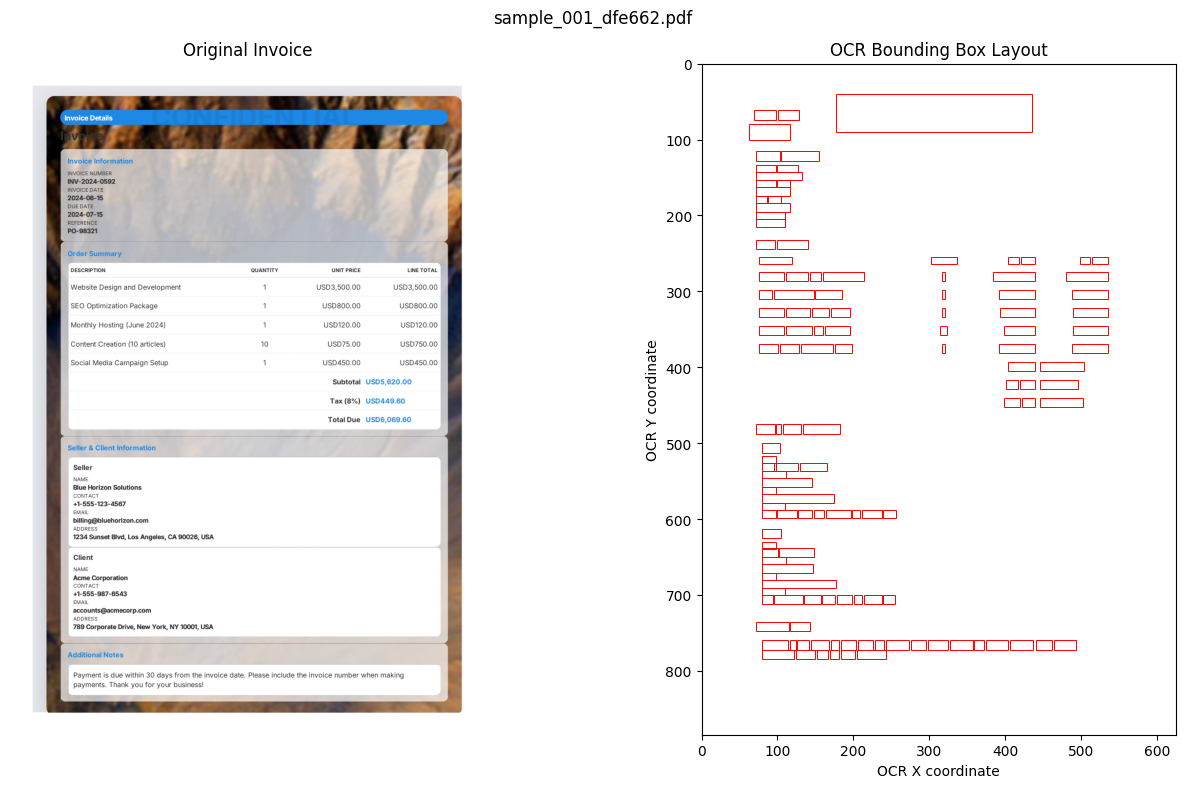

Invoice: sample_001_dfe662.pdf
OCR Words: 131
GROUND TRUTH:
{
  "invoice": {
    "number": "INV-2024-0592",
    "date": "2024-06-15",
    "due_date": "2024-07-15",
    "reference": "PO-98321"
  },
  "seller": {
    "name": "Blue Horizon Solutions",
    "contact": "+1-555-123-4567",
    "email": "billing@bluehorizon.com",
    "address": "1234 Sunset Blvd, Los Angeles, CA 90026, USA"
  },
  "client": {
    "name": "Acme Corporation",
    "contact": "+1-555-987-6543",
    "email": "accounts@acmecorp.com",
    "address": "789 Corporate Drive, New York, NY 10001, USA"
  },
  "totals": {
    "subtotal": 5620,
    "tax": 449.6,
    "due": 6069.6
  }
}



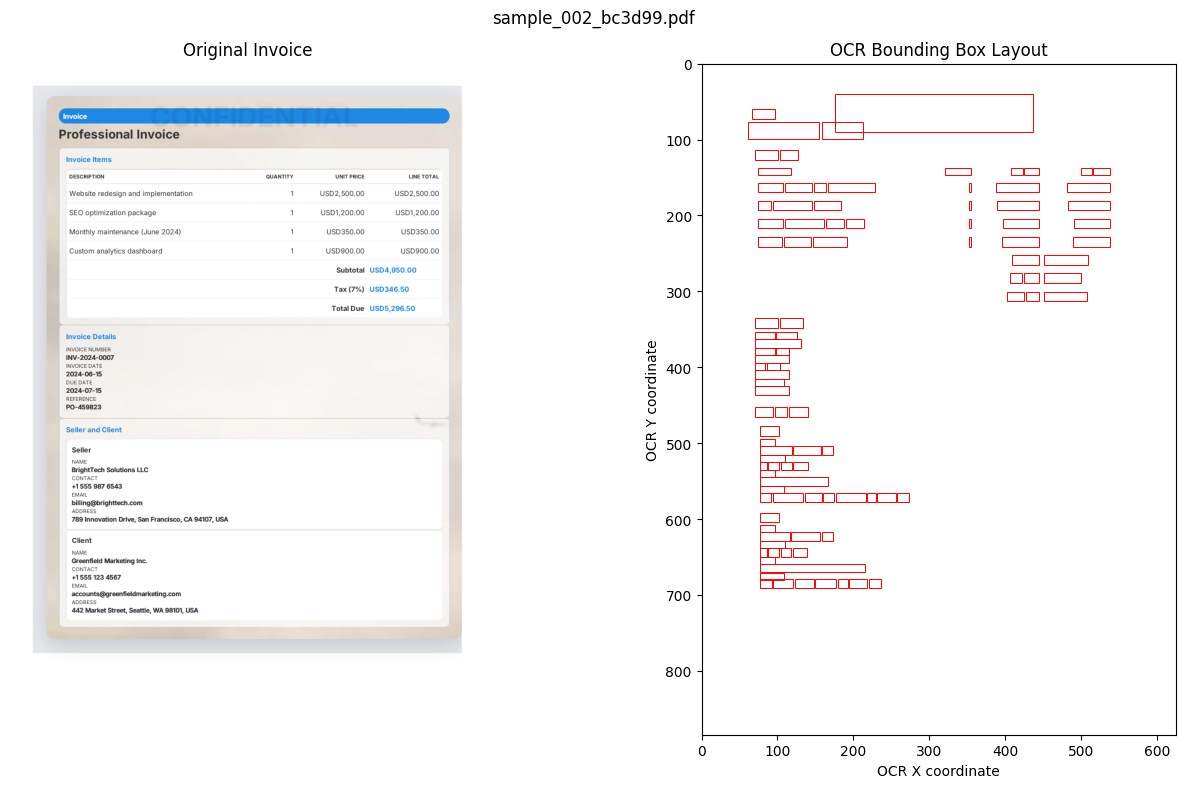

Invoice: sample_002_bc3d99.pdf
OCR Words: 103
GROUND TRUTH:
{
  "invoice": {
    "number": "INV-2024-0007",
    "date": "2024-06-15",
    "due_date": "2024-07-15",
    "reference": "PO-459823"
  },
  "seller": {
    "name": "BrightTech Solutions LLC",
    "contact": "+1 555 987 6543",
    "email": "billing@brighttech.com",
    "address": "789 Innovation Drive, San Francisco, CA 94107, USA"
  },
  "client": {
    "name": "Greenfield Marketing Inc.",
    "contact": "+1 555 123 4567",
    "email": "accounts@greenfieldmarketing.com",
    "address": "442 Market Street, Seattle, WA 98101, USA"
  },
  "totals": {
    "subtotal": 4950,
    "tax": 346.5,
    "due": 5296.5
  }
}



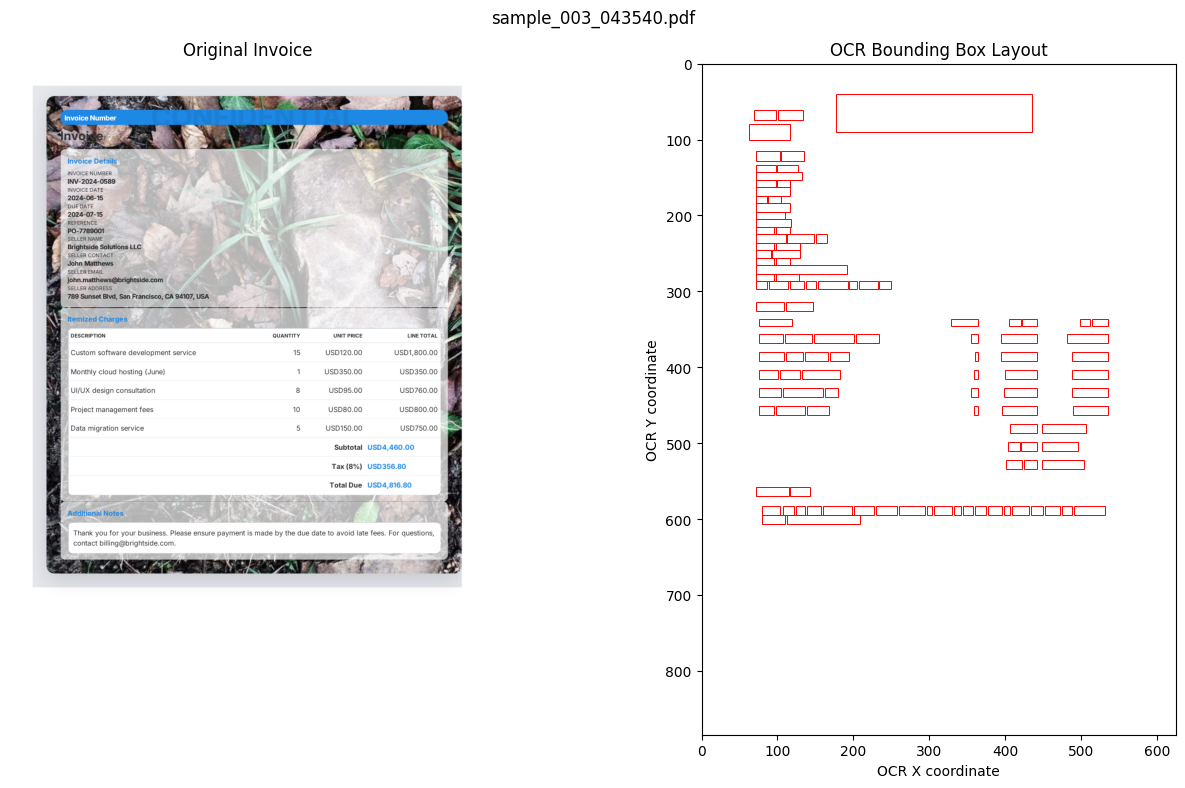

Invoice: sample_003_043540.pdf
OCR Words: 111
GROUND TRUTH:
{
  "invoice": {
    "number": "INV-2024-0589",
    "date": "2024-06-15",
    "due_date": "2024-07-15",
    "reference": "PO-7789001"
  },
  "seller": {
    "name": "Brightside Solutions LLC",
    "contact": "John Matthews",
    "email": "john.matthews@brightside.com",
    "address": "789 Sunset Blvd, San Francisco, CA 94107, USA"
  },
  "client": {
    "name": "Horizon Tech Inc.",
    "contact": "Laura Chen",
    "email": "laura.chen@horizontech.com",
    "address": "456 Innovation Drive, Seattle, WA 98109, USA"
  },
  "totals": {
    "subtotal": 4460.0,
    "tax": 356.8,
    "due": 4816.8
  }
}



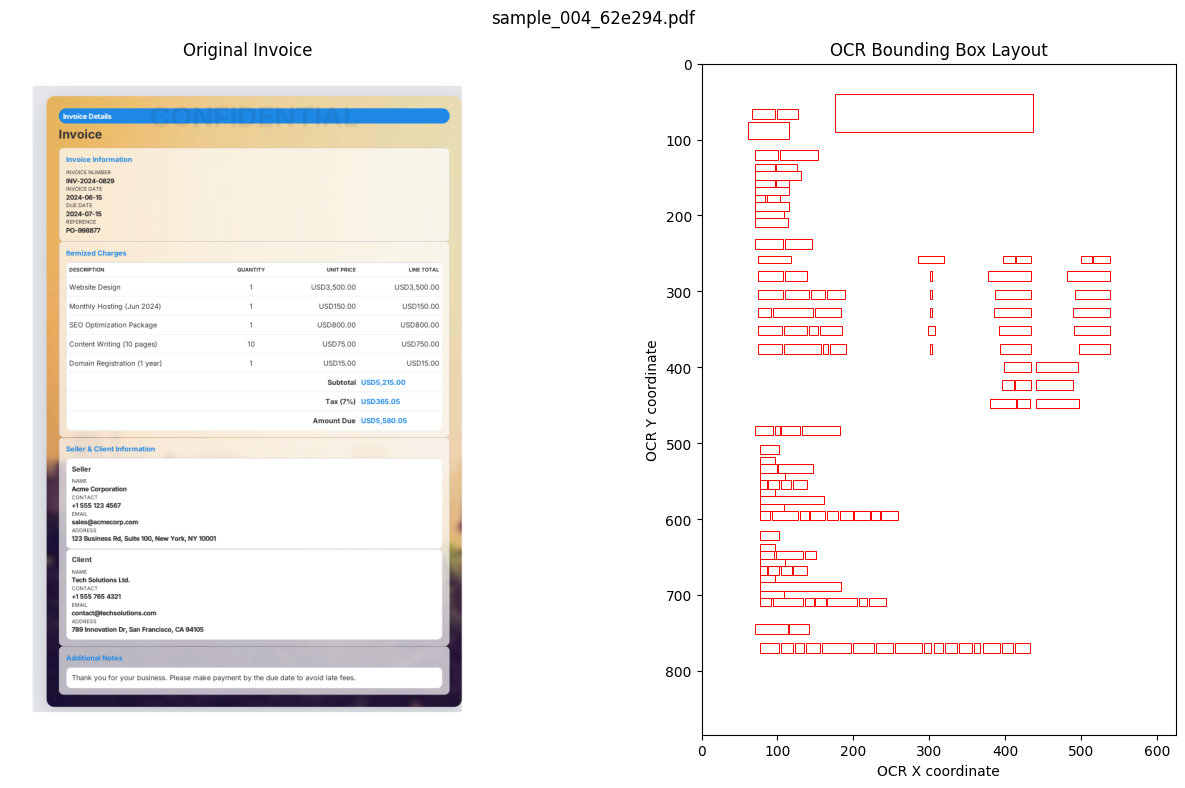

Invoice: sample_004_62e294.pdf
OCR Words: 128
GROUND TRUTH:
{
  "invoice": {
    "number": "INV-2024-0829",
    "date": "2024-06-15",
    "due_date": "2024-07-15",
    "reference": "PO-998877"
  },
  "seller": {
    "name": "Acme Corporation",
    "contact": "+1 555 123 4567",
    "email": "sales@acmecorp.com",
    "address": "123 Business Rd, Suite 100, New York, NY 10001"
  },
  "client": {
    "name": "Tech Solutions Ltd.",
    "contact": "+1 555 765 4321",
    "email": "contact@techsolutions.com",
    "address": "789 Innovation Dr, San Francisco, CA 94105"
  },
  "totals": {
    "subtotal": 5215.0,
    "tax": 365.05,
    "due": 5580.05
  }
}



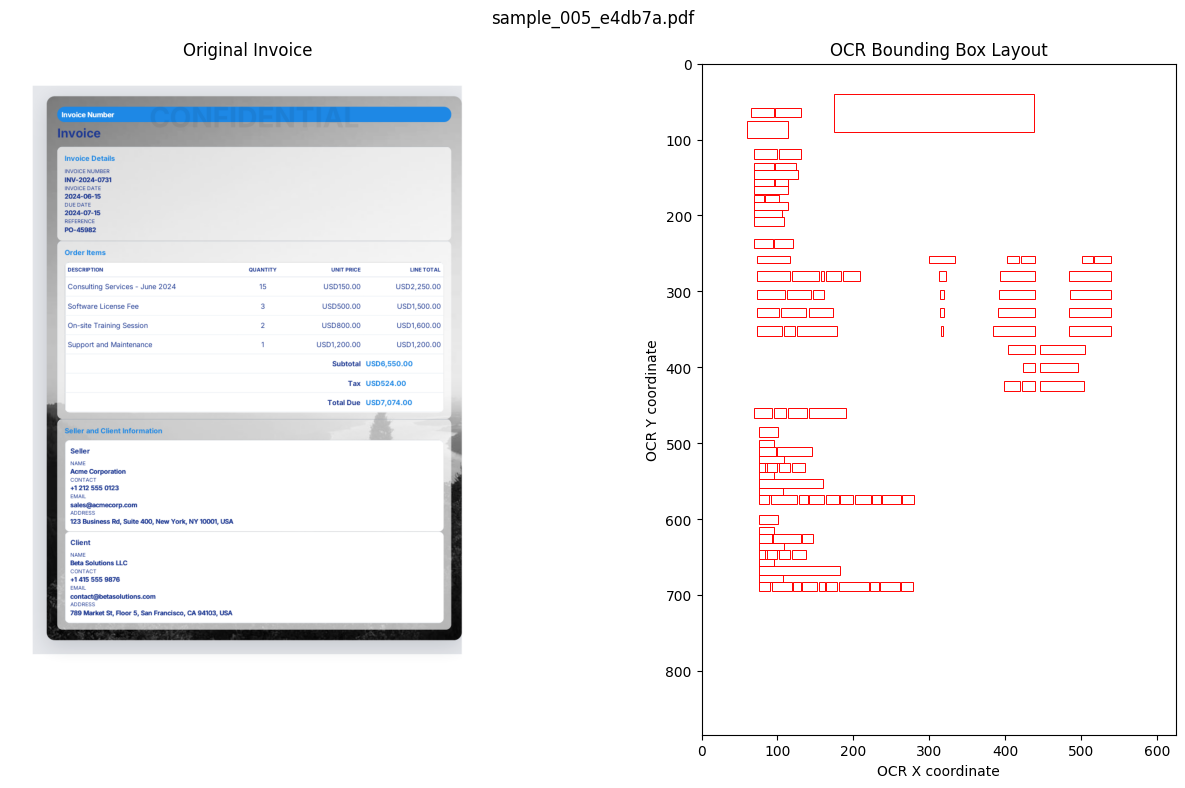

Invoice: sample_005_e4db7a.pdf
OCR Words: 107
GROUND TRUTH:
{
  "invoice": {
    "number": "INV-2024-0731",
    "date": "2024-06-15",
    "due_date": "2024-07-15",
    "reference": "PO-45982"
  },
  "seller": {
    "name": "Acme Corporation",
    "contact": "+1 212 555 0123",
    "email": "sales@acmecorp.com",
    "address": "123 Business Rd, Suite 400, New York, NY 10001, USA"
  },
  "client": {
    "name": "Beta Solutions LLC",
    "contact": "+1 415 555 9876",
    "email": "contact@betasolutions.com",
    "address": "789 Market St, Floor 5, San Francisco, CA 94103, USA"
  },
  "totals": {
    "subtotal": 6550,
    "tax": 524,
    "due": 7074
  }
}



In [3]:
import json
from pathlib import Path

import pymupdf
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# Dataset location
DATASET_DIR = Path("/kaggle/working/generated-invoices")

pdf_files = sorted(DATASET_DIR.rglob("*.pdf"))

print("Total PDFs found:", len(pdf_files))

if not pdf_files:
    raise FileNotFoundError(
        "No PDFs found. Attach the Generated Invoices "
        "dataset and check its folder structure."
    )

NUM_SAMPLES = 5

for pdf_path in pdf_files[:NUM_SAMPLES]:

    # Corresponding annotations
    ocr_path = pdf_path.with_suffix(".ocr.json")
    gt_path = pdf_path.with_suffix(".json")

    # Render first PDF page
    with pymupdf.open(pdf_path) as doc:
        page = doc[0]
        pix = page.get_pixmap(
            matrix=pymupdf.Matrix(1.5, 1.5),
            alpha=False
        )

        image = Image.frombytes(
            "RGB", (pix.width, pix.height), pix.samples
        )
        page_width = page.rect.width
        page_height = page.rect.height

    # Load OCR
    ocr = {}
    if ocr_path.exists():
        with open(ocr_path, encoding="utf-8") as f:
            ocr = json.load(f)

    items = ocr.get("items", [])

    # Load Ground Truth
    ground_truth = {}
    if gt_path.exists():
        with open(gt_path, encoding="utf-8") as f:
            ground_truth = json.load(f)

    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(14, 8))

    axes[0].imshow(image)
    axes[0].set_title("Original Invoice")
    axes[0].axis("off")

    # Visualize boxes in native OCR coordinates
    max_x = max(
        [float(i.get("x1", 0)) for i in items]
        + [page_width]
    )
    max_y = max(
        [float(i.get("y1", 0)) for i in items]
        + [page_height]
    )

    axes[1].set_xlim(0, max_x * 1.05)
    axes[1].set_ylim(max_y * 1.05, 0)
    axes[1].set_aspect("equal")

    for item in items:
        if int(item.get("page", 1)) not in (0, 1):
            continue

        x0 = float(item["x0"])
        y0 = float(item["y0"])
        x1 = float(item["x1"])
        y1 = float(item["y1"])

        box = Rectangle(
            (x0, y0),
            x1 - x0,
            y1 - y0,
            fill=False,
            edgecolor="red",
            linewidth=0.7
        )

        axes[1].add_patch(box)

    axes[1].set_title("OCR Bounding Box Layout")
    axes[1].set_xlabel("OCR X coordinate")
    axes[1].set_ylabel("OCR Y coordinate")

    plt.suptitle(pdf_path.name)
    plt.tight_layout()
    plt.show()

    print("=" * 60)
    print("Invoice:", pdf_path.name)
    print("OCR Words:", len(items))

    data = ground_truth.get("data", {})

    selected_fields = {
        key: data.get(key)
        for key in ["invoice", "seller", "client", "totals"]
        if key in data
    }

    print("GROUND TRUTH:")
    print(json.dumps(
        selected_fields,
        indent=2,
        ensure_ascii=False
    ))
    print()

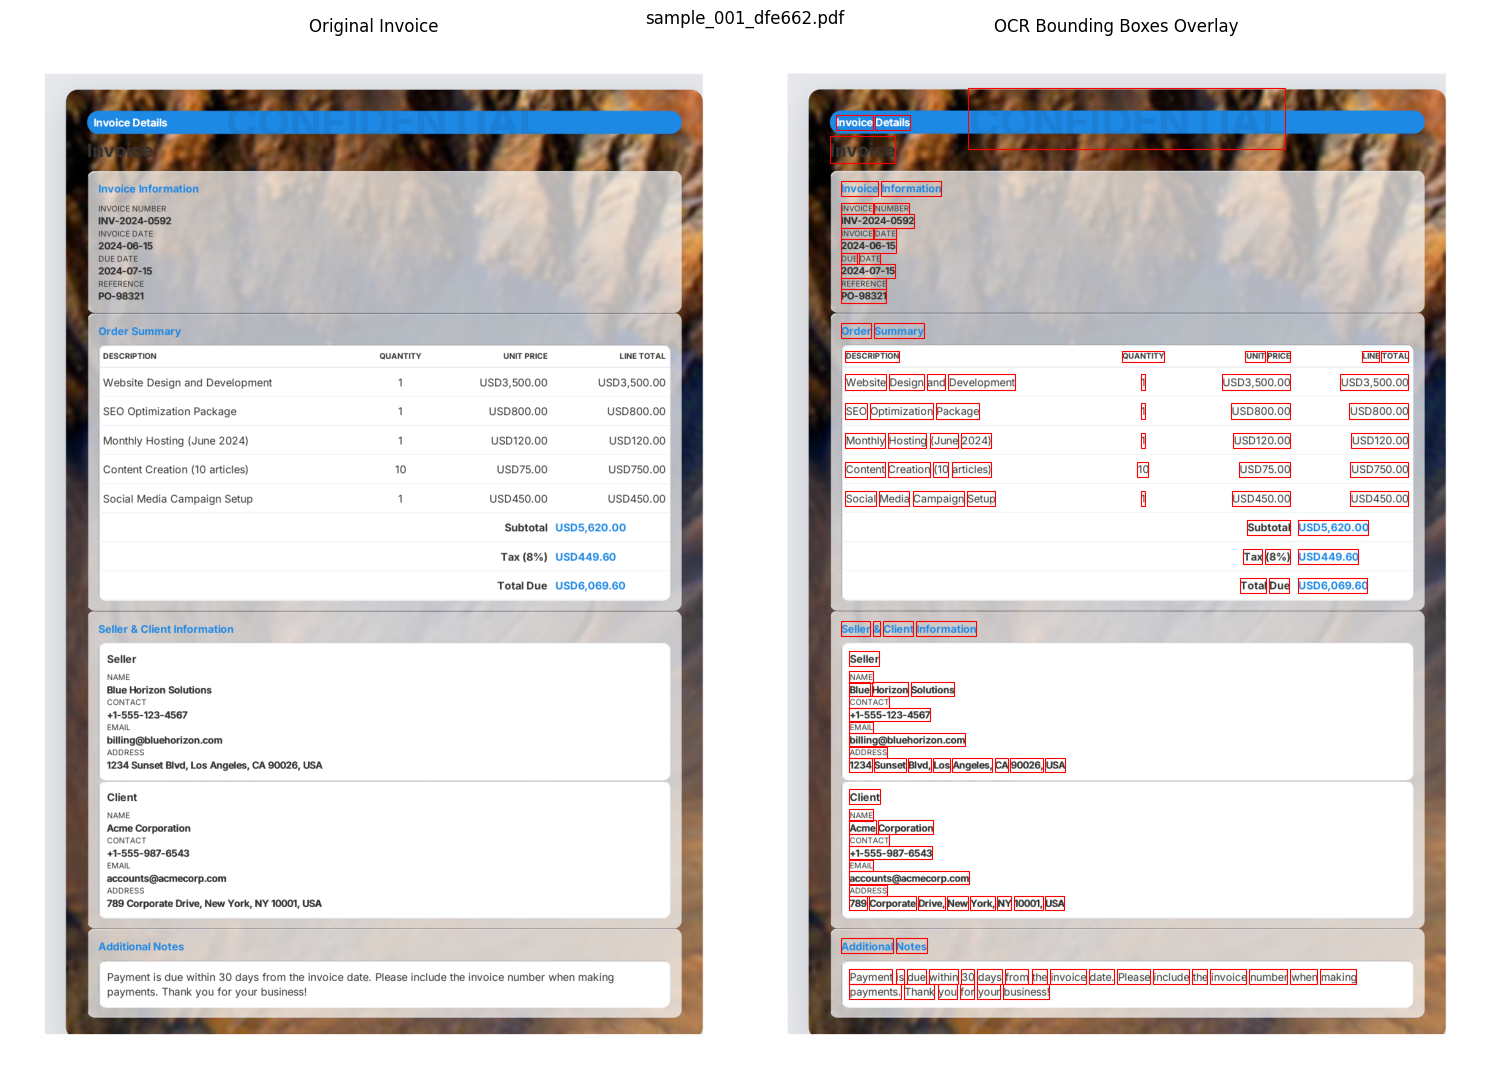

Invoice: sample_001_dfe662.pdf
OCR items: 131
Bounding boxes drawn: 131
PDF dimensions: 595.0 842.0
Image dimensions: (1190, 1684)
First OCR item:
{
  "page": 1,
  "x0": 68.45330810546875,
  "y0": 61.748390197753906,
  "x1": 98.38050079345703,
  "y1": 74.16631317138672,
  "text": "Invoice"
}


In [4]:

import json
from pathlib import Path

import pymupdf
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

DATASET_DIR = Path("/kaggle/working/generated-invoices")

# First invoice
pdf_path = sorted(DATASET_DIR.glob("sample_*.pdf"))[0]
ocr_path = pdf_path.with_suffix(".ocr.json")

with open(ocr_path, encoding="utf-8") as f:
    ocr = json.load(f)

# Render PDF
with pymupdf.open(pdf_path) as doc:
    page = doc[0]

    pdf_width = page.rect.width
    pdf_height = page.rect.height

    pix = page.get_pixmap(
        matrix=pymupdf.Matrix(2, 2),
        alpha=False
    )

    image = Image.frombytes(
        "RGB",
        (pix.width, pix.height),
        pix.samples
    )

# Scale PDF-space coordinates to rendered image pixels
scale_x = image.width / pdf_width
scale_y = image.height / pdf_height

fig, axes = plt.subplots(1, 2, figsize=(15, 11))

axes[0].imshow(image)
axes[0].set_title("Original Invoice")
axes[0].axis("off")

axes[1].imshow(image)

count = 0

for item in ocr.get("items", []):

    if not all(k in item for k in ("x0", "y0", "x1", "y1")):
        continue

    if "page" in item and int(item["page"]) not in (0, 1):
        continue

    x0 = float(item["x0"]) * scale_x
    y0 = float(item["y0"]) * scale_y
    x1 = float(item["x1"]) * scale_x
    y1 = float(item["y1"]) * scale_y

    rect = Rectangle(
        (x0, y0),
        x1 - x0,
        y1 - y0,
        linewidth=0.8,
        edgecolor="red",
        facecolor="none"
    )

    axes[1].add_patch(rect)
    count += 1

axes[1].set_xlim(0, image.width)
axes[1].set_ylim(image.height, 0)
axes[1].set_title("OCR Bounding Boxes Overlay")
axes[1].axis("off")

plt.suptitle(pdf_path.name)
plt.tight_layout()
plt.show()

print("Invoice:", pdf_path.name)
print("OCR items:", len(ocr.get("items", [])))
print("Bounding boxes drawn:", count)
print("PDF dimensions:", pdf_width, pdf_height)
print("Image dimensions:", image.size)
print("First OCR item:")
print(json.dumps(
    ocr.get("items", [{}])[0],
    indent=2,
    ensure_ascii=False
))


In [5]:

import json
import re
import unicodedata
from pathlib import Path
from difflib import SequenceMatcher
import pandas as pd
from IPython.display import display

ROOT = Path("/kaggle/working/generated-invoices")
pdf_path = sorted(ROOT.glob("sample_*.pdf"))[0]

with open(pdf_path.with_suffix(".ocr.json"), encoding="utf-8") as f:
    ocr = json.load(f)

with open(pdf_path.with_suffix(".json"), encoding="utf-8") as f:
    gt = json.load(f)["data"]

items = ocr["items"]
words = [
    str(item.get("text", item.get("word", ""))).strip()
    for item in items
]
words = [word for word in words if word]

print("Invoice:", pdf_path.name)
print("OCR words:", len(words))
print("First 25 OCR words:")
print(words[:25])

def normalize(text):
    text = unicodedata.normalize("NFKC", str(text))
    return re.sub(r"[^a-z0-9]", "", text.lower())

def find_best_match(target, words, max_span=12):
    target_norm = normalize(target)
    best_score = 0
    best_text = ""

    if not target_norm:
        return "", 0.0

    for i in range(len(words)):
        for span in range(1, min(max_span, len(words) - i) + 1):
            candidate = " ".join(words[i:i + span])
            candidate_norm = normalize(candidate)

            score = SequenceMatcher(
                None, target_norm, candidate_norm
            ).ratio()

            if score > best_score:
                best_score = score
                best_text = candidate

    return best_text, best_score

targets = {
    "invoice.number": gt.get("invoice", {}).get("number"),
    "invoice.date": gt.get("invoice", {}).get("date"),
    "seller.name": gt.get("seller", {}).get("name"),
    "seller.email": gt.get("seller", {}).get("email"),
    "client.name": gt.get("client", {}).get("name"),
    "client.email": gt.get("client", {}).get("email"),
}

results = []

for field, value in targets.items():
    if value is None:
        continue

    matched, score = find_best_match(value, words)

    results.append({
        "Field": field,
        "Ground Truth": value,
        "OCR Candidate": matched,
        "Text Similarity": round(score, 3),
        "Exact Normalized Match": (
            normalize(value) == normalize(matched)
        )
    })

display(pd.DataFrame(results))


Invoice: sample_001_dfe662.pdf
OCR words: 131
First 25 OCR words:
['Invoice', 'Details', 'Invoice', 'Invoice', 'Information', 'INVOICE', 'NUMBER', 'INV-2024-0592', 'INVOICE', 'DATE', '2024-06-15', 'DUE', 'DATE', '2024-07-15', 'REFERENCE', 'PO-98321', 'Order', 'Summary', 'DESCRIPTION', 'QUANTITY', 'UNIT', 'PRICE', 'LINE', 'TOTAL', 'Website']


,Field,Ground Truth,OCR Candidate,Text Similarity,Exact Normalized Match
0,invoice.number,INV-2024-0592,INV-2024-0592,1.0,True
1,invoice.date,2024-06-15,2024-06-15,1.0,True
2,seller.name,Blue Horizon Solutions,Blue Horizon Solutions,1.0,True
3,seller.email,billing@bluehorizon.com,billing@bluehorizon.com,1.0,True
4,client.name,Acme Corporation,Acme Corporation,1.0,True
5,client.email,accounts@acmecorp.com,accounts@acmecorp.com,1.0,True


CONFIGURATION
Dataset: /kaggle/working/generated-invoices
Device: cuda
Model: microsoft/layoutlmv3-base
Target fields: 11
BIO labels: 23

DATASET DISCOVERY
PDF files found: 746


Validating invoices:   0%|          | 0/746 [00:00<?, ?it/s]


DATA VALIDATION RESULTS
Total PDFs: 746
Valid samples: 339
Rejected samples: 407

Rejection reasons:


,count
Reason,
Multi-page PDF: 2 pages,391
Multi-page PDF: 3 pages,16


,Invoice,Reason
0,sample_001_dfe662.pdf,Multi-page PDF: 2 pages
1,sample_004_62e294.pdf,Multi-page PDF: 2 pages
2,sample_008_dde5cd.pdf,Multi-page PDF: 2 pages
3,sample_009_2cb7d9.pdf,Multi-page PDF: 2 pages
4,sample_010_bd1091.pdf,Multi-page PDF: 2 pages
5,sample_018_7bdadb.pdf,Multi-page PDF: 2 pages
6,sample_024_b9314a.pdf,Multi-page PDF: 2 pages
7,sample_025_f4c09f.pdf,Multi-page PDF: 2 pages
8,sample_026_5e6fe5.pdf,Multi-page PDF: 2 pages
9,sample_029_bd2179.pdf,Multi-page PDF: 2 pages


...

Tokenization audit:   0%|          | 0/122 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (637 > 512). Running this sequence through the model will result in indexing errors



TOKENIZATION AND TRUNCATION RESULTS


,Samples,Average_Tokens,Maximum_Tokens,Lost_Words
Split,,,,
test,13,387.69,661,3
train,97,611.08,1895,48
val,12,582.75,1480,5


Token-safe samples: 92

FINAL DATASET SPLIT
Train: 72
Validation: 9
Test: 11

FINAL MODEL INPUT SHAPES
input_ids           : (2, 512)
attention_mask      : (2, 512)
bbox                : (2, 512, 4)
labels              : (2, 512)
pixel_values        : (2, 3, 224, 224)

LABEL STATISTICS
Non-ignored token positions: 82
Entity-labeled tokens: 19
Background-labeled tokens: 63


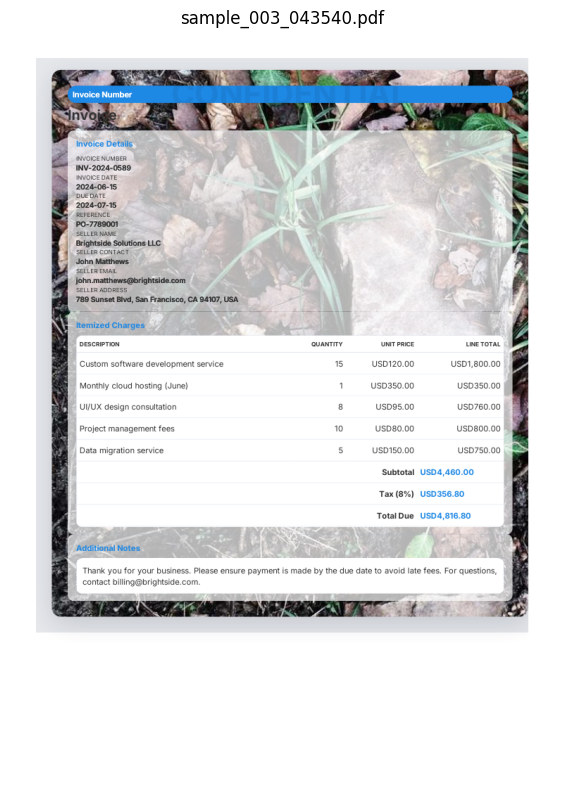


PREPROCESSING PIPELINE COMPLETED
Validated invoices: 339
Usable aligned invoices: 122
Token-safe invoices: 92

Final datasets:
Train: 72
Validation: 9
Test: 11

Number of labels: 23
Batch size: 2
Device: cuda

Dataset and DataLoaders are ready!

NOTE: Partial alignments use ignored labels (-100). They require additional quality checks before training.
NOTE: Exact duplicates are grouped, but unseen-layout generalization is not guaranteed.


In [6]:

# ============================================================
# PROJECT 9: INVOICE INFORMATION EXTRACTION
# COMPLETE STANDALONE PREPROCESSING CELL
# ============================================================

import json
import re
import math
import hashlib
import unicodedata

from pathlib import Path
from collections import Counter
from decimal import Decimal, InvalidOperation

import numpy as np
import pandas as pd
import torch
import pymupdf
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display
from tqdm.auto import tqdm
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import Dataset, DataLoader
from transformers import AutoProcessor


# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT =Path("/kaggle/working/generated-invoices")
MODEL_NAME = "microsoft/layoutlmv3-base"
MAX_LENGTH = 512
BATCH_SIZE = 2
SEED = 42

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

FIELDS = {
    "INVOICE_NUMBER": (("invoice", "number"), "text"),
    "INVOICE_DATE": (("invoice", "date"), "text"),
    "DUE_DATE": (("invoice", "due_date"), "text"),
    "REFERENCE": (("invoice", "reference"), "text"),
    "SELLER_NAME": (("seller", "name"), "text"),
    "SELLER_EMAIL": (("seller", "email"), "text"),
    "CLIENT_NAME": (("client", "name"), "text"),
    "CLIENT_EMAIL": (("client", "email"), "text"),
    "SUBTOTAL": (("totals", "subtotal"), "money"),
    "TAX": (("totals", "tax"), "money"),
    "TOTAL_DUE": (("totals", "due"), "money")
}

LABELS = ["O"]

for entity in FIELDS:
    LABELS += [f"B-{entity}", f"I-{entity}"]

label2id = {v: i for i, v in enumerate(LABELS)}
id2label = {i: v for v, i in label2id.items()}

print("=" * 60)
print("CONFIGURATION")
print("=" * 60)
print("Dataset:", ROOT)
print("Device:", device)
print("Model:", MODEL_NAME)
print("Target fields:", len(FIELDS))
print("BIO labels:", len(LABELS))

if not ROOT.is_dir():
    raise FileNotFoundError(
        f"Dataset not found: {ROOT}"
    )


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def normalize_text(value):
    text = unicodedata.normalize("NFKC", str(value))
    return "".join(
        c for c in text.casefold() if c.isalnum()
    )


def normalize_money(value):
    if isinstance(value, bool):
        return None

    text = str(value).strip()

    text = re.sub(
        r"^(?:(?:USD|EUR|GBP|BDT|US\$|Tk)\s*|"
        r"[\$€£৳]\s*)+",
        "",
        text,
        flags=re.IGNORECASE
    )

    if not re.fullmatch(
        r"[-+]?\d[\d,]*(?:\.\d+)?",
        text
    ):
        return None

    try:
        return Decimal(text.replace(",", ""))
    except InvalidOperation:
        return None


def get_ground_truth(data, path):
    for key in path:
        if not isinstance(data, dict):
            return None
        data = data.get(key)

    if isinstance(data, bool):
        return None

    if isinstance(data, (str, int, float)):
        return data

    return None


def find_exact_spans(words, target, kind):
    matches = []

    if kind == "money":
        target_value = normalize_money(target)

        if target_value is None:
            return []

        for i in range(len(words)):
            for j in range(
                i + 1,
                min(i + 4, len(words) + 1)
            ):
                candidate = " ".join(words[i:j])

                if normalize_money(candidate) == target_value:
                    matches.append((i, j))

    else:
        target_value = normalize_text(target)

        if not target_value:
            return []

        tokens = [normalize_text(w) for w in words]

        for i in range(len(tokens)):
            combined = ""

            for j in range(
                i,
                min(i + 15, len(tokens))
            ):
                combined += tokens[j]

                if combined == target_value:
                    matches.append((i, j + 1))
                    break

                if len(combined) >= len(target_value):
                    break

    # Remove overlapping matches for the same field
    selected = []

    matches = sorted(
        set(matches),
        key=lambda x: (-(x[1] - x[0]), x[0])
    )

    for start, end in matches:
        overlap = any(
            start < e and s < end
            for s, e in selected
        )

        if not overlap:
            selected.append((start, end))

    return sorted(selected)


# ============================================================
# 3. DISCOVER AND VALIDATE DATASET
# ============================================================

pdf_files = sorted(ROOT.rglob("sample_*.pdf"))

print("\n" + "=" * 60)
print("DATASET DISCOVERY")
print("=" * 60)
print("PDF files found:", len(pdf_files))

if not pdf_files:
    print("First directory entries:")
    print([p.name for p in list(ROOT.iterdir())[:15]])
    raise RuntimeError("No invoice PDFs found.")

samples = []
rejected = []

for pdf_path in tqdm(
    pdf_files,
    desc="Validating invoices"
):
    try:
        ocr_path = pdf_path.with_suffix(".ocr.json")
        gt_path = pdf_path.with_suffix(".json")

        if not ocr_path.exists() or not gt_path.exists():
            raise ValueError("Missing OCR or GT JSON")

        with open(ocr_path, encoding="utf-8") as f:
            ocr_obj = json.load(f)

        with open(gt_path, encoding="utf-8") as f:
            gt_obj = json.load(f)

        gt = gt_obj.get("data")
        items = ocr_obj.get("items")

        if not isinstance(gt, dict) or not gt:
            raise ValueError("Missing ground truth data")

        if not isinstance(items, list) or not items:
            raise ValueError("Missing OCR items")

        with pymupdf.open(pdf_path) as doc:
            if len(doc) != 1:
                raise ValueError(
                    f"Multi-page PDF: {len(doc)} pages"
                )

            page = doc[0]
            width = float(page.rect.width)
            height = float(page.rect.height)

        if width <= 0 or height <= 0:
            raise ValueError("Invalid page dimensions")

        words = []
        boxes = []
        invalid_ocr = 0

        for item in items:
            if not isinstance(item, dict):
                invalid_ocr += 1
                continue

            word = str(
                item.get("text")
                or item.get("word")
                or ""
            ).strip()

            if not word:
                invalid_ocr += 1
                continue

            try:
                x0, y0, x1, y1 = [
                    float(item[k])
                    for k in ("x0", "y0", "x1", "y1")
                ]
            except (KeyError, ValueError, TypeError):
                invalid_ocr += 1
                continue

            if not all(
                math.isfinite(v)
                for v in (x0, y0, x1, y1)
            ):
                invalid_ocr += 1
                continue

            if x1 <= x0 or y1 <= y0:
                invalid_ocr += 1
                continue

            # OCR coordinates are assumed to use PDF space.
            # Slight overflow is clipped; completely outside
            # boxes are rejected.

            if (
                x1 < 0 or y1 < 0
                or x0 > width or y0 > height
            ):
                invalid_ocr += 1
                continue

            x0 = max(0, x0)
            y0 = max(0, y0)
            x1 = min(width, x1)
            y1 = min(height, y1)

            if x1 <= x0 or y1 <= y0:
                invalid_ocr += 1
                continue

            normalized_box = [
                round(1000 * x0 / width),
                round(1000 * y0 / height),
                round(1000 * x1 / width),
                round(1000 * y1 / height)
            ]

            normalized_box = [
                int(max(0, min(1000, v)))
                for v in normalized_box
            ]

            words.append(word)
            boxes.append(normalized_box)

        if not words:
            raise ValueError(
                "No valid OCR words and bounding boxes"
            )

        # Hashes for exact duplicate grouping
        with open(pdf_path, "rb") as f:
            pdf_hash = hashlib.sha256(
                f.read()
            ).hexdigest()

        text_string = " ".join(
            normalize_text(w) for w in words
        )

        text_hash = hashlib.sha256(
            text_string.encode("utf-8")
        ).hexdigest()

        samples.append({
            "pdf": pdf_path,
            "gt": gt,
            "words": words,
            "boxes": boxes,
            "invalid_ocr": invalid_ocr,
            "pdf_hash": pdf_hash,
            "text_hash": text_hash
        })

    except Exception as e:
        rejected.append({
            "Invoice": pdf_path.name,
            "Reason": str(e)
        })


print("\n" + "=" * 60)
print("DATA VALIDATION RESULTS")
print("=" * 60)

print("Total PDFs:", len(pdf_files))
print("Valid samples:", len(samples))
print("Rejected samples:", len(rejected))

if rejected:
    rejection_df = pd.DataFrame(rejected)
    print("\nRejection reasons:")
    display(
        rejection_df["Reason"].value_counts().to_frame()
    )
    display(rejection_df.head(10))

if not samples:
    print("\nDIAGNOSTIC INFORMATION")
    first = pdf_files[0]

    try:
        with pymupdf.open(first) as doc:
            print("PDF pages:", len(doc))
            print("PDF page dimensions:", doc[0].rect)

        with open(first.with_suffix(".ocr.json")) as f:
            example_ocr = json.load(f)

        print(
            "First OCR item:",
            example_ocr.get("items", [None])[0]
        )
    except Exception as e:
        print("Diagnostic error:", e)

    raise RuntimeError(
        "No valid samples. Inspect rejection reasons above."
    )

print("\nOCR word statistics:")
display(
    pd.Series(
        [len(s["words"]) for s in samples]
    ).describe().to_frame("OCR Words")
)

print("\nGround Truth structure:")
print({
    k: list(v.keys()) if isinstance(v, dict) else type(v).__name__
    for k, v in samples[0]["gt"].items()
})


# ============================================================
# 4. OCR-GROUND TRUTH ALIGNMENT + BIO LABELS
# ============================================================

audit = []

for sample in tqdm(
    samples,
    desc="Generating BIO labels"
):
    words = sample["words"]
    gt = sample["gt"]

    unique_matches = {}
    status = {}

    for entity, (path, kind) in FIELDS.items():

        target = get_ground_truth(gt, path)

        if target is None or str(target).strip() == "":
            status[entity] = "NO_GT"
            continue

        matches = find_exact_spans(
            words,
            target,
            kind
        )

        if len(matches) == 1:
            status[entity] = "UNIQUE"
            unique_matches[entity] = matches[0]

        elif len(matches) == 0:
            status[entity] = "NOT_FOUND"

        else:
            status[entity] = "AMBIGUOUS"

    # Detect overlaps between different entity classes
    conflicts = set()

    for entity_a, (a0, a1) in unique_matches.items():
        for entity_b, (b0, b1) in unique_matches.items():
            if entity_a == entity_b:
                continue

            if a0 < b1 and b0 < a1:
                conflicts.update((entity_a, entity_b))

    for entity in conflicts:
        unique_matches.pop(entity, None)
        status[entity] = "CONFLICT"

    incomplete = any(
        state in ("NOT_FOUND", "AMBIGUOUS", "CONFLICT")
        for state in status.values()
    )

    # For partially aligned documents, avoid assigning
    # possibly incorrect background labels.
    base_label = -100 if incomplete else label2id["O"]
    labels = [base_label] * len(words)

    for entity, (start, end) in unique_matches.items():

        labels[start] = label2id[f"B-{entity}"]

        for pos in range(start + 1, end):
            labels[pos] = label2id[f"I-{entity}"]

    sample["labels"] = labels
    sample["alignment_status"] = status
    sample["fully_aligned"] = not incomplete
    sample["has_positive_labels"] = any(
        label > 0 for label in labels
    )

    for entity, state in status.items():
        audit.append({
            "Field": entity,
            "Status": state
        })


audit_df = pd.DataFrame(audit)

print("\n" + "=" * 60)
print("ALIGNMENT AUDIT")
print("=" * 60)

display(pd.crosstab(
    audit_df["Field"],
    audit_df["Status"]
))

print(
    "Fully aligned documents:",
    sum(s["fully_aligned"] for s in samples)
)

print(
    "Documents with high-confidence labels:",
    sum(s["has_positive_labels"] for s in samples)
)

usable_samples = [
    s for s in samples
    if s["has_positive_labels"]
]

print("Usable samples:", len(usable_samples))

if len(usable_samples) < 3:
    raise RuntimeError(
        "Too few aligned documents. Review alignment results."
    )


# ============================================================
# 5. DUPLICATE-SAFE TRAIN / VAL / TEST SPLIT
# ============================================================

parent = list(range(len(usable_samples)))


def find_root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


def merge_groups(i, j):
    root_i = find_root(i)
    root_j = find_root(j)

    if root_i != root_j:
        parent[root_j] = root_i


seen = {}

for i, sample in enumerate(usable_samples):

    for key in ("pdf_hash", "text_hash"):
        signature = (key, sample[key])

        if signature in seen:
            merge_groups(i, seen[signature])
        else:
            seen[signature] = i


groups = np.array([
    find_root(i)
    for i in range(len(usable_samples))
])

if len(set(groups)) < 5:
    raise RuntimeError(
        "Not enough independent groups for splitting."
    )

indices = np.arange(len(usable_samples))

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_idx, holdout_idx = next(
    splitter.split(indices, groups=groups)
)

splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED + 1
)

val_pos, test_pos = next(
    splitter2.split(
        holdout_idx,
        groups=groups[holdout_idx]
    )
)

val_idx = holdout_idx[val_pos]
test_idx = holdout_idx[test_pos]

for name, idxs in (
    ("train", train_idx),
    ("val", val_idx),
    ("test", test_idx)
):
    for i in idxs:
        usable_samples[i]["split"] = name


# Verify group isolation
group_sets = {
    name: set(groups[idxs])
    for name, idxs in (
        ("train", train_idx),
        ("val", val_idx),
        ("test", test_idx)
    )
}

assert group_sets["train"].isdisjoint(group_sets["val"])
assert group_sets["train"].isdisjoint(group_sets["test"])
assert group_sets["val"].isdisjoint(group_sets["test"])

print("\n" + "=" * 60)
print("DUPLICATE-SAFE SPLIT COMPLETED")
print("=" * 60)

display(pd.DataFrame([
    {"Split": "Train", "Samples": len(train_idx)},
    {"Split": "Validation", "Samples": len(val_idx)},
    {"Split": "Test", "Samples": len(test_idx)}
]))


# ============================================================
# 6. LOAD PROCESSOR AND CHECK TOKEN TRUNCATION
# ============================================================

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    apply_ocr=False
)

assert processor.tokenizer.is_fast, (
    "Fast tokenizer required for word_ids()."
)

safe_samples = []
truncation_results = []

for sample in tqdm(
    usable_samples,
    desc="Tokenization audit"
):

    words = sample["words"]
    boxes = sample["boxes"]
    labels = sample["labels"]

    full = processor.tokenizer(
        words,
        boxes=boxes,
        word_labels=labels,
        truncation=False,
        padding=False
    )

    clipped = processor.tokenizer(
        words,
        boxes=boxes,
        word_labels=labels,
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )

    full_counts = Counter(
        wid for wid in full.word_ids()
        if wid is not None
    )

    clipped_counts = Counter(
        wid for wid in clipped.word_ids()
        if wid is not None
    )

    lost_entities = []

    for i, label in enumerate(labels):
        if label <= 0:
            continue

        if (
            full_counts[i] == 0
            or clipped_counts[i] < full_counts[i]
        ):
            lost_entities.append(i)

    sample["token_safe"] = len(lost_entities) == 0

    if sample["token_safe"]:
        safe_samples.append(sample)

    truncation_results.append({
        "Split": sample["split"],
        "Tokens": len(full["input_ids"]),
        "Lost Entity Words": len(lost_entities)
    })


truncation_df = pd.DataFrame(truncation_results)

print("\n" + "=" * 60)
print("TOKENIZATION AND TRUNCATION RESULTS")
print("=" * 60)

display(truncation_df.groupby("Split").agg(
    Samples=("Tokens", "size"),
    Average_Tokens=("Tokens", "mean"),
    Maximum_Tokens=("Tokens", "max"),
    Lost_Words=("Lost Entity Words", "sum")
).round(2))

print("Token-safe samples:", len(safe_samples))


# ============================================================
# 7. CREATE FINAL SPLITS
# ============================================================

train_rows = [
    s for s in safe_samples
    if s["split"] == "train"
]

val_rows = [
    s for s in safe_samples
    if s["split"] == "val"
]

test_rows = [
    s for s in safe_samples
    if s["split"] == "test"
]

print("\n" + "=" * 60)
print("FINAL DATASET SPLIT")
print("=" * 60)

print("Train:", len(train_rows))
print("Validation:", len(val_rows))
print("Test:", len(test_rows))

if min(
    len(train_rows),
    len(val_rows),
    len(test_rows)
) == 0:
    raise RuntimeError(
        "One split is empty. Inspect the alignment "
        "and truncation audit."
    )


# ============================================================
# 8. PYTORCH DATASET
# ============================================================

class InvoiceDataset(Dataset):

    def __init__(self, rows, processor):
        self.rows = rows
        self.processor = processor

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):

        sample = self.rows[idx]

        # PDF -> RGB Image
        with pymupdf.open(sample["pdf"]) as doc:

            pix = doc[0].get_pixmap(
                matrix=pymupdf.Matrix(1.5, 1.5),
                alpha=False
            )

            image = Image.frombytes(
                "RGB",
                (pix.width, pix.height),
                pix.samples
            )

        # Image resize, normalization,
        # tokenization, label alignment and padding
        encoding = self.processor(
            image,
            sample["words"],
            boxes=sample["boxes"],
            word_labels=sample["labels"],
            truncation=True,
            max_length=MAX_LENGTH,
            padding="max_length",
            return_tensors="pt"
        )

        return {
            key: value.squeeze(0)
            for key, value in encoding.items()
            if isinstance(value, torch.Tensor)
        }


# ============================================================
# 9. DATASETS AND DATALOADERS
# ============================================================

train_dataset = InvoiceDataset(
    train_rows, processor
)

val_dataset = InvoiceDataset(
    val_rows, processor
)

test_dataset = InvoiceDataset(
    test_rows, processor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


# ============================================================
# 10. VERIFY MODEL INPUT
# ============================================================

batch = next(iter(train_loader))

print("\n" + "=" * 60)
print("FINAL MODEL INPUT SHAPES")
print("=" * 60)

for key, value in batch.items():
    print(f"{key:20s}: {tuple(value.shape)}")

print("\nLABEL STATISTICS")
print("Non-ignored token positions:",
      int((batch["labels"] != -100).sum()))

print("Entity-labeled tokens:",
      int((batch["labels"] > 0).sum()))

print("Background-labeled tokens:",
      int((batch["labels"] == 0).sum()))

if int((batch["labels"] == 0).sum()) == 0:
    print(
        "WARNING: This batch has no background labels. "
        "Review partial-supervision coverage before training."
    )


# ============================================================
# 11. VISUALIZE VALIDATED INVOICE
# ============================================================

example = train_rows[0]

with pymupdf.open(example["pdf"]) as doc:
    pix = doc[0].get_pixmap(
        matrix=pymupdf.Matrix(1.3, 1.3),
        alpha=False
    )

    image = Image.frombytes(
        "RGB",
        (pix.width, pix.height),
        pix.samples
    )

plt.figure(figsize=(8, 10))
plt.imshow(image)
plt.title(example["pdf"].name)
plt.axis("off")
plt.show()


# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("PREPROCESSING PIPELINE COMPLETED")
print("=" * 60)

print("Validated invoices:", len(samples))
print("Usable aligned invoices:", len(usable_samples))
print("Token-safe invoices:", len(safe_samples))

print("\nFinal datasets:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print("\nNumber of labels:", len(LABELS))
print("Batch size:", BATCH_SIZE)
print("Device:", device)

print("\nDataset and DataLoaders are ready!")

print(
    "\nNOTE: Partial alignments use ignored labels (-100). "
    "They require additional quality checks before training."
)

print(
    "NOTE: Exact duplicates are grouped, but unseen-layout "
    "generalization is not guaranteed."
)


In [7]:

import json
import pymupdf
from pathlib import Path
from collections import Counter

ROOT = Path("/kaggle/working/generated-invoices")

pdf_path = ROOT / "sample_001_dfe662.pdf"
ocr_path = pdf_path.with_suffix(".ocr.json")

with pymupdf.open(pdf_path) as doc:
    print("PDF pages:", len(doc))

    for i, page in enumerate(doc):
        print(
            f"Page {i}: "
            f"{page.rect.width:.1f} x {page.rect.height:.1f}"
        )

with open(ocr_path, encoding="utf-8") as f:
    ocr = json.load(f)

print("\nOCR JSON keys:")
print(list(ocr.keys()))

items = ocr.get("items", [])

print("\nTotal OCR items:", len(items))

print("\nOCR page distribution:")
print(Counter(
    str(item.get("page", "NOT_SPECIFIED"))
    for item in items
    if isinstance(item, dict)
))

print("\nFirst 3 OCR items:")

for item in items[:3]:
    print(json.dumps(
        item,
        indent=2,
        ensure_ascii=False
    ))


PDF pages: 2
Page 0: 595.0 x 842.0
Page 1: 595.0 x 842.0

OCR JSON keys:
['items']

Total OCR items: 131

OCR page distribution:
Counter({'1': 131})

First 3 OCR items:
{
  "page": 1,
  "x0": 68.45330810546875,
  "y0": 61.748390197753906,
  "x1": 98.38050079345703,
  "y1": 74.16631317138672,
  "text": "Invoice"
}
{
  "page": 1,
  "x0": 100.30797576904297,
  "y0": 61.748390197753906,
  "x1": 128.79522705078125,
  "y1": 74.16631317138672,
  "text": "Details"
}
{
  "page": 1,
  "x0": 63.05421447753906,
  "y0": 79.23404693603516,
  "x1": 116.78601837158203,
  "y1": 100.83042907714844,
  "text": "Invoice"
}


Auditing PDF pages:   0%|          | 0/746 [00:00<?, ?it/s]


========== PDF PAGE DISTRIBUTION ==========


PDF Pages
1    339
2    391
3     16
Name: count, dtype: int64


========== OCR PAGE COVERAGE ==========


OCR Pages
1    359
2    377
3     10
Name: count, dtype: int64


Pages with PDF text but zero OCR words: 0


""



========== PAGE 1 ==========
PDF Text Words: 131
OCR Words: 131
First 300 characters:
'Invoice Details\nInvoice\nInvoice Information\nINVOICE NUMBER\nINV-2024-0592\nINVOICE DATE\n2024-06-15\nDUE DATE\n2024-07-15\nREFERENCE\nPO-98321\nOrder Summary\nDESCRIPTION\nQUANTITY\nUNIT PRICE\nLINE TOTAL\nWebsite Design and Development\n1\nUSD3,500.00\nUSD3,500.00\nSEO Optimization Package\n1\nUSD800.00\nUSD800.00\nMon'

========== PAGE 2 ==========
PDF Text Words: 0
OCR Words: 0
First 300 characters:
''


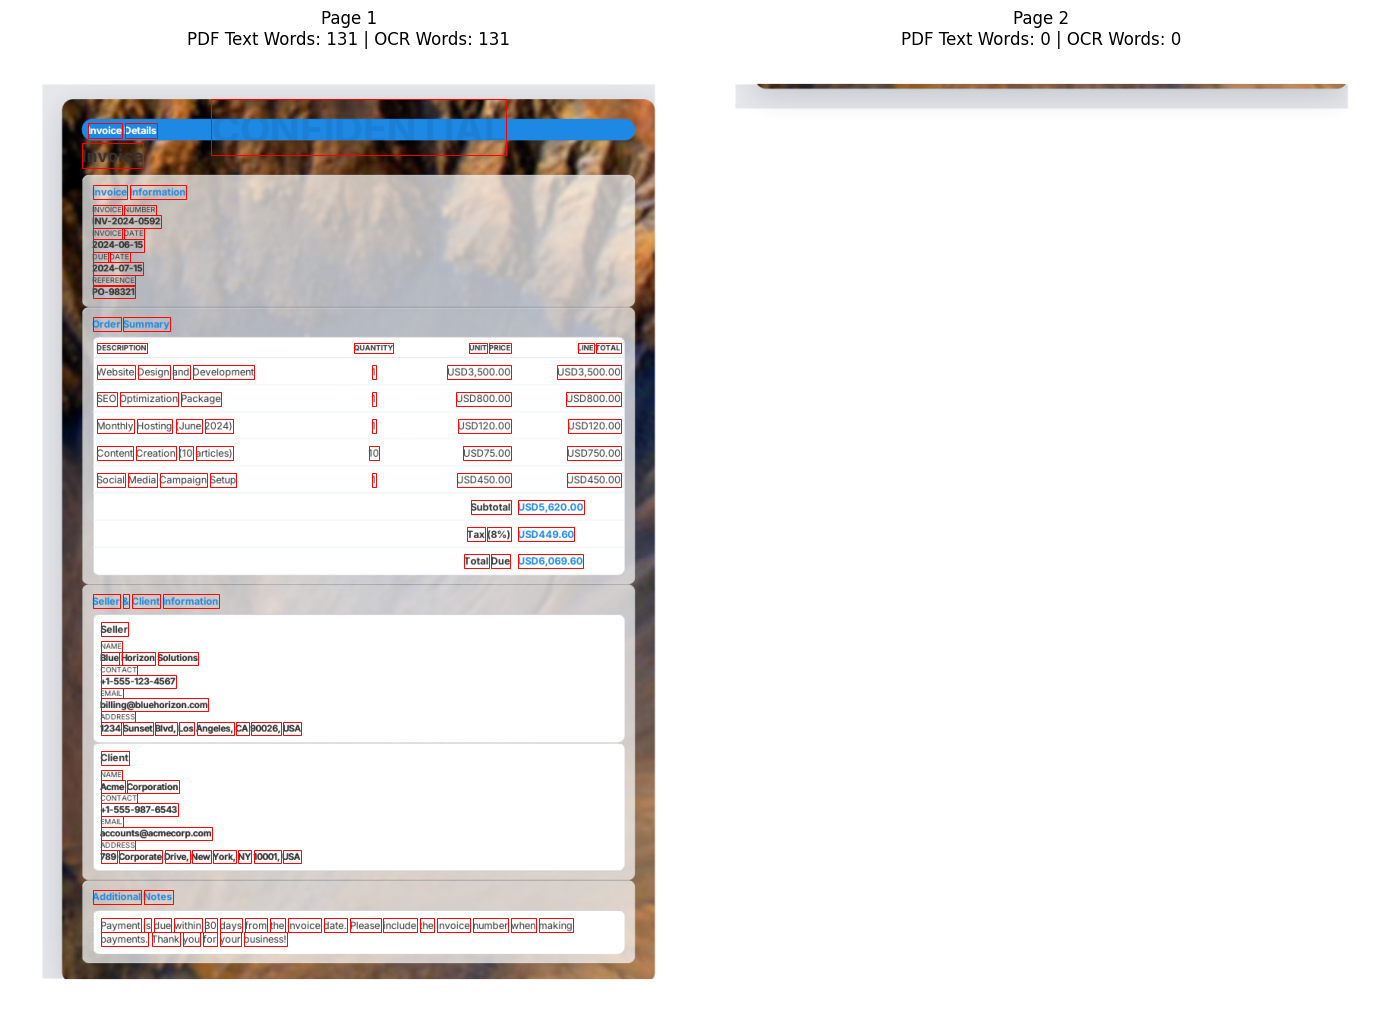

In [8]:

import json
import pymupdf
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from collections import Counter
from PIL import Image
from matplotlib.patches import Rectangle
from IPython.display import display
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/generated-invoices")

# ==========================================
# 1. DATASET-WIDE PAGE AUDIT
# ==========================================

records = []
missing_ocr_pages = []

for pdf_path in tqdm(
    sorted(ROOT.glob("sample_*.pdf")),
    desc="Auditing PDF pages"
):
    ocr_path = pdf_path.with_suffix(".ocr.json")

    if not ocr_path.exists():
        continue

    with open(ocr_path, encoding="utf-8") as f:
        ocr = json.load(f)

    items = ocr.get("items", [])

    page_counts = Counter(
        int(item["page"])
        for item in items
        if isinstance(item, dict)
        and item.get("page") is not None
    )

    with pymupdf.open(pdf_path) as doc:
        records.append({
            "Invoice": pdf_path.name,
            "PDF Pages": len(doc),
            "OCR Pages": len(page_counts),
            "OCR Words": len(items)
        })

        for page_idx, page in enumerate(doc):

            pdf_words = len(page.get_text("words"))
            ocr_words = page_counts.get(page_idx + 1, 0)

            if pdf_words > 10 and ocr_words == 0:
                missing_ocr_pages.append({
                    "Invoice": pdf_path.name,
                    "PDF Page": page_idx + 1,
                    "PDF Text Words": pdf_words,
                    "OCR Words": ocr_words
                })

df = pd.DataFrame(records)

print("\n========== PDF PAGE DISTRIBUTION ==========")
display(df["PDF Pages"].value_counts().sort_index())

print("\n========== OCR PAGE COVERAGE ==========")
display(df["OCR Pages"].value_counts().sort_index())

print("\nPages with PDF text but zero OCR words:",
      len(missing_ocr_pages))

display(pd.DataFrame(missing_ocr_pages).head(15))


# ==========================================
# 2. VISUALIZE BOTH PAGES OF FIRST INVOICE
# ==========================================

pdf_path = ROOT / "sample_001_dfe662.pdf"
ocr_path = pdf_path.with_suffix(".ocr.json")

with open(ocr_path, encoding="utf-8") as f:
    ocr = json.load(f)

items = ocr.get("items", [])

with pymupdf.open(pdf_path) as doc:

    fig, axes = plt.subplots(
        1, len(doc),
        figsize=(7 * len(doc), 10),
        squeeze=False
    )
    axes = axes[0]

    for page_idx, page in enumerate(doc):

        pix = page.get_pixmap(
            matrix=pymupdf.Matrix(1.5, 1.5),
            alpha=False
        )

        image = Image.frombytes(
            "RGB",
            (pix.width, pix.height),
            pix.samples
        )

        ax = axes[page_idx]
        ax.imshow(image)

        scale_x = image.width / page.rect.width
        scale_y = image.height / page.rect.height

        # OCR uses one-based page numbering here
        page_items = [
            item for item in items
            if int(item.get("page", -1)) == page_idx + 1
        ]

        for item in page_items:
            x0 = float(item["x0"]) * scale_x
            y0 = float(item["y0"]) * scale_y
            x1 = float(item["x1"]) * scale_x
            y1 = float(item["y1"]) * scale_y

            ax.add_patch(Rectangle(
                (x0, y0),
                x1 - x0,
                y1 - y0,
                fill=False,
                edgecolor="red",
                linewidth=0.7
            ))

        pdf_word_count = len(page.get_text("words"))

        ax.set_title(
            f"Page {page_idx + 1}\n"
            f"PDF Text Words: {pdf_word_count} | "
            f"OCR Words: {len(page_items)}"
        )

        ax.axis("off")

        print(f"\n========== PAGE {page_idx + 1} ==========")
        print("PDF Text Words:", pdf_word_count)
        print("OCR Words:", len(page_items))
        print("First 300 characters:")
        print(repr(page.get_text()[:300]))

    plt.tight_layout()
    plt.show()


In [9]:

# ============================================================
# PAGE-AWARE INVOICE DATASET PREPARATION
# Fixes rejection of multi-page PDFs
# ============================================================

import json
import math
from pathlib import Path
from collections import Counter

import pandas as pd
import pymupdf

from tqdm.auto import tqdm
from IPython.display import display

ROOT =Path("/kaggle/working/generated-invoices")

page_samples = []
invoice_stats = []
page_stats = []
rejected = []


# ============================================================
# 1. LOAD ALL PDF / OCR / GT TRIPLETS
# ============================================================

pdf_files = sorted(ROOT.glob("sample_*.pdf"))

for pdf_path in tqdm(
    pdf_files,
    desc="Preparing invoice pages"
):
    try:
        ocr_path = pdf_path.with_suffix(".ocr.json")
        gt_path = pdf_path.with_suffix(".json")

        with open(ocr_path, encoding="utf-8") as f:
            ocr = json.load(f)

        with open(gt_path, encoding="utf-8") as f:
            gt = json.load(f)["data"]

        if not isinstance(gt, dict):
            raise ValueError("Invalid ground truth")

        items = ocr.get("items", [])

        if not isinstance(items, list):
            raise ValueError("Invalid OCR items")

        with pymupdf.open(pdf_path) as doc:
            total_pages = len(doc)

            # Each page has its own dimensions and OCR
            page_words = {
                i: [] for i in range(total_pages)
            }
            page_boxes = {
                i: [] for i in range(total_pages)
            }

            invalid_items = 0

            # ==========================================
            # 2. MAP OCR ITEMS TO CORRECT PDF PAGES
            # ==========================================

            for item in items:

                if not isinstance(item, dict):
                    invalid_items += 1
                    continue

                try:
                    # OCR JSON: page 1, 2, 3...
                    # PyMuPDF: doc[0], doc[1], doc[2]...
                    page_index = int(item["page"]) - 1

                    if not (0 <= page_index < total_pages):
                        raise ValueError("Invalid page number")

                    word = str(item["text"]).strip()

                    x0, y0, x1, y1 = [
                        float(item[k])
                        for k in ("x0", "y0", "x1", "y1")
                    ]

                    if not word:
                        raise ValueError("Empty word")

                    if not all(
                        math.isfinite(v)
                        for v in (x0, y0, x1, y1)
                    ):
                        raise ValueError("Non-finite coordinates")

                    page = doc[page_index]

                    width = float(page.rect.width)
                    height = float(page.rect.height)

                    # Clip boxes to page boundaries
                    x0 = max(0, min(width, x0))
                    x1 = max(0, min(width, x1))
                    y0 = max(0, min(height, y0))
                    y1 = max(0, min(height, y1))

                    if x1 <= x0 or y1 <= y0:
                        raise ValueError("Invalid bounding box")

                    # Normalize to LayoutLMv3's 0-1000 scale
                    box = [
                        round(1000 * x0 / width),
                        round(1000 * y0 / height),
                        round(1000 * x1 / width),
                        round(1000 * y1 / height)
                    ]

                    page_words[page_index].append(word)
                    page_boxes[page_index].append(box)

                except (KeyError, TypeError, ValueError):
                    invalid_items += 1
                    continue

            # ==========================================
            # 3. CREATE PAGE-LEVEL SAMPLES
            # ==========================================

            content_page_count = 0

            for page_index in range(total_pages):

                page = doc[page_index]

                words = page_words[page_index]
                boxes = page_boxes[page_index]

                pdf_text_count = len(
                    page.get_text("words")
                )

                page_stats.append({
                    "Invoice": pdf_path.name,
                    "Page": page_index + 1,
                    "PDF Text Words": pdf_text_count,
                    "OCR Words": len(words),
                    "Has OCR": len(words) > 0
                })

                if not words:
                    continue

                content_page_count += 1

                page_samples.append({
                    "invoice_id": pdf_path.stem,
                    "pdf": pdf_path,
                    "page_index": page_index,
                    "page_number": page_index + 1,
                    "total_pages": total_pages,
                    "words": words,
                    "boxes": boxes,
                    "gt": gt
                })

            invoice_stats.append({
                "Invoice": pdf_path.name,
                "PDF Pages": total_pages,
                "OCR Content Pages": content_page_count,
                "Invalid OCR Items": invalid_items
            })

    except Exception as e:
        rejected.append({
            "Invoice": pdf_path.name,
            "Reason": str(e)
        })


# ============================================================
# 4. DATASET SUMMARY
# ============================================================

invoice_df = pd.DataFrame(invoice_stats)
page_df = pd.DataFrame(page_stats)

print("\n" + "=" * 65)
print("PAGE-AWARE DATASET SUMMARY")
print("=" * 65)

print("Original PDF files:", len(pdf_files))
print("Successfully loaded invoices:", len(invoice_df))
print("Rejected invoices:", len(rejected))
print("Total PDF pages:", len(page_df))
print("Pages with OCR:", len(page_samples))
print("Pages without OCR:",
      int((~page_df["Has OCR"]).sum()))

print("\nPDF PAGE DISTRIBUTION:")
display(
    invoice_df["PDF Pages"]
    .value_counts()
    .sort_index()
    .to_frame("Invoice Count")
)

print("\nOCR CONTENT PAGE DISTRIBUTION:")
display(
    invoice_df["OCR Content Pages"]
    .value_counts()
    .sort_index()
    .to_frame("Invoice Count")
)

print("\nOCR WORD STATISTICS:")
display(
    page_df.loc[
        page_df["Has OCR"],
        "OCR Words"
    ].describe().round(2).to_frame()
)

print("\nSHORT OCR PAGES (<= 5 words):")

short_pages = page_df[
    (page_df["OCR Words"] > 0)
    & (page_df["OCR Words"] <= 5)
]

print("Count:", len(short_pages))
display(short_pages.head(10))

print("\nPAGES WITHOUT OCR:")
display(
    page_df[~page_df["Has OCR"]].head(10)
)

if rejected:
    print("\nREJECTED INVOICES:")
    display(pd.DataFrame(rejected).head(15))


# ============================================================
# 5. VERIFY AN EXAMPLE
# ============================================================

example = next(
    (
        s for s in page_samples
        if s["invoice_id"] == "sample_001_dfe662"
    ),
    page_samples[0]
)

print("\n" + "=" * 65)
print("EXAMPLE PAGE")
print("=" * 65)

print("Invoice:", example["invoice_id"])
print("Page:", example["page_number"])
print("OCR Words:", len(example["words"]))
print("Bounding Boxes:", len(example["boxes"]))

assert len(example["words"]) == len(example["boxes"])

print("\nFIRST 20 WORDS:")
print(example["words"][:20])

print("\nFIRST 5 NORMALIZED BOXES:")
display(pd.DataFrame({
    "Word": example["words"][:5],
    "Box": example["boxes"][:5]
}))

print("\nPage-aware dataset loading completed!")


Preparing invoice pages:   0%|          | 0/746 [00:00<?, ?it/s]


PAGE-AWARE DATASET SUMMARY
Original PDF files: 746
Successfully loaded invoices: 746
Rejected invoices: 0
Total PDF pages: 1169
Pages with OCR: 1143
Pages without OCR: 26

PDF PAGE DISTRIBUTION:


,Invoice Count
PDF Pages,
1,339
2,391
3,16



OCR CONTENT PAGE DISTRIBUTION:


,Invoice Count
OCR Content Pages,
1,359
2,377
3,10


...


PAGES WITHOUT OCR:


,Invoice,Page,PDF Text Words,OCR Words,Has OCR
1,sample_001_dfe662.pdf,2,0,0,False
5,sample_004_62e294.pdf,2,0,0,False
12,sample_009_2cb7d9.pdf,2,0,0,False
14,sample_010_bd1091.pdf,2,0,0,False
23,sample_018_7bdadb.pdf,2,0,0,False
164,sample_103_09c466.pdf,3,0,0,False
180,sample_113_736e28.pdf,2,0,0,False
182,sample_114_881672.pdf,2,0,0,False
186,sample_117_7962c1.pdf,2,0,0,False
192,sample_122_7138eb.pdf,2,0,0,False



EXAMPLE PAGE
Invoice: sample_001_dfe662
Page: 1
OCR Words: 131
Bounding Boxes: 131

FIRST 20 WORDS:
['Invoice', 'Details', 'Invoice', 'Invoice', 'Information', 'INVOICE', 'NUMBER', 'INV-2024-0592', 'INVOICE', 'DATE', '2024-06-15', 'DUE', 'DATE', '2024-07-15', 'REFERENCE', 'PO-98321', 'Order', 'Summary', 'DESCRIPTION', 'QUANTITY']

FIRST 5 NORMALIZED BOXES:


,Word,Box
0,Invoice,"[115, 73, 165, 88]"
1,Details,"[169, 73, 216, 88]"
2,Invoice,"[106, 94, 196, 120]"
3,Invoice,"[121, 137, 173, 152]"
4,Information,"[177, 137, 259, 152]"



Page-aware dataset loading completed!


In [10]:

# ============================================================
# INVOICE-LEVEL OCR-GROUND TRUTH ALIGNMENT AUDIT
# Works with the existing page_samples variable
# ============================================================

import re
import unicodedata
from decimal import Decimal, InvalidOperation
from collections import defaultdict

import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

assert "page_samples" in globals() and page_samples, (
    "Run the page-aware data loading cell first."
)

FIELDS = {
    "INVOICE_NUMBER": (("invoice", "number"), "text"),
    "INVOICE_DATE": (("invoice", "date"), "text"),
    "DUE_DATE": (("invoice", "due_date"), "text"),
    "REFERENCE": (("invoice", "reference"), "text"),
    "SELLER_NAME": (("seller", "name"), "text"),
    "SELLER_EMAIL": (("seller", "email"), "text"),
    "CLIENT_NAME": (("client", "name"), "text"),
    "CLIENT_EMAIL": (("client", "email"), "text"),
    "SUBTOTAL": (("totals", "subtotal"), "money"),
    "TAX": (("totals", "tax"), "money"),
    "TOTAL_DUE": (("totals", "due"), "money")
}


# ============================================================
# 1. NORMALIZATION
# ============================================================

def norm_text(value):
    value = unicodedata.normalize("NFKC", str(value))
    return "".join(
        c for c in value.casefold() if c.isalnum()
    )


def norm_money(value):
    if isinstance(value, bool):
        return None

    text = str(value).strip()

    text = re.sub(
        r"^(?:USD|BDT|EUR|GBP|US\$|Tk|"
        r"[$€£৳])\s*",
        "",
        text,
        flags=re.IGNORECASE
    )

    if not re.fullmatch(
        r"[-+]?(?:\d{1,3}(?:,\d{3})+|\d+)"
        r"(?:\.\d+)?",
        text
    ):
        return None

    try:
        return Decimal(text.replace(",", ""))
    except InvalidOperation:
        return None


def get_value(data, path):
    for key in path:
        if not isinstance(data, dict):
            return None
        data = data.get(key)
    return data


# ============================================================
# 2. FIND OCR MATCHES WITHIN ONE PAGE
# ============================================================

def match_page(words, target, kind):
    matches = []

    if kind == "text":
        normalized = [norm_text(w) for w in words]
        target_norm = norm_text(target)

        if not target_norm:
            return []

        for start in range(len(words)):
            combined = ""

            for end in range(
                start + 1,
                min(start + 16, len(words) + 1)
            ):
                combined += normalized[end - 1]

                if combined == target_norm:
                    matches.append((start, end))
                    break

                if len(combined) >= len(target_norm):
                    break

    else:
        target_number = norm_money(target)

        if target_number is None:
            return []

        for start in range(len(words)):
            for end in range(
                start + 1,
                min(start + 4, len(words) + 1)
            ):
                candidate = " ".join(words[start:end])

                if norm_money(candidate) == target_number:
                    matches.append((start, end))

    # Merge overlapping alternatives for same occurrence
    matches = sorted(
        set(matches),
        key=lambda x: (x[0], x[1])
    )

    clusters = []

    for span in matches:
        if clusters and span[0] < max(
            x[1] for x in clusters[-1]
        ):
            clusters[-1].append(span)
        else:
            clusters.append([span])

    return [
        min(cluster, key=lambda x: (x[1] - x[0], x[0]))
        for cluster in clusters
    ]


# ============================================================
# 3. GROUP PAGES BY INVOICE
# ============================================================

invoices = defaultdict(list)

for sample in page_samples:
    invoices[sample["invoice_id"]].append(sample)

print("Invoices:", len(invoices))
print("OCR pages:", len(page_samples))


# ============================================================
# 4. SEARCH GT FIELDS ACROSS ALL PAGES
# ============================================================

audit_records = []
alignment_map = {}

for invoice_id, pages in tqdm(
    invoices.items(),
    desc="Aligning invoice fields"
):
    pages = sorted(
        pages,
        key=lambda p: p["page_index"]
    )

    ground_truth = pages[0]["gt"]
    field_results = {}

    for entity, (path, kind) in FIELDS.items():
        target = get_value(ground_truth, path)

        if target is None or str(target).strip() == "":
            status = "NO_GT"
            candidates = []

        else:
            candidates = []

            for page in pages:
                spans = match_page(
                    page["words"],
                    target,
                    kind
                )

                for start, end in spans:
                    candidates.append({
                        "page": page["page_number"],
                        "start": start,
                        "end": end,
                        "text": " ".join(
                            page["words"][start:end]
                        )
                    })

            if len(candidates) == 0:
                status = "NOT_FOUND"
            elif len(candidates) == 1:
                status = "UNIQUE"
            else:
                status = "AMBIGUOUS"

        field_results[entity] = {
            "status": status,
            "ground_truth": target,
            "candidates": candidates
        }

        audit_records.append({
            "Invoice": invoice_id,
            "Field": entity,
            "Status": status,
            "Candidate Count": len(candidates),
            "Matched Page": (
                candidates[0]["page"]
                if len(candidates) == 1 else None
            )
        })

    alignment_map[invoice_id] = field_results


# ============================================================
# 5. DATASET-WIDE ALIGNMENT REPORT
# ============================================================

alignment_df = pd.DataFrame(audit_records)

print("\n========== FIELD ALIGNMENT STATUS ==========")

summary = pd.crosstab(
    alignment_df["Field"],
    alignment_df["Status"]
)

display(summary)

print("\n========== OVERALL ALIGNMENT ==========")

available = alignment_df[
    alignment_df["Status"] != "NO_GT"
]

print("Fields with ground truth:", len(available))
print("Unique matches:",
      (available["Status"] == "UNIQUE").sum())
print("Ambiguous matches:",
      (available["Status"] == "AMBIGUOUS").sum())
print("Not found:",
      (available["Status"] == "NOT_FOUND").sum())

print(
    "Unique-match percentage:",
    round(
        100 * (available["Status"] == "UNIQUE").mean(),
        2
    ) if len(available) else 0,
    "%"
)


# ============================================================
# 6. INVOICE-LEVEL COVERAGE
# ============================================================

invoice_coverage = []

for invoice_id, results in alignment_map.items():
    present = [
        result for result in results.values()
        if result["status"] != "NO_GT"
    ]

    unique = sum(
        result["status"] == "UNIQUE"
        for result in present
    )

    unresolved = sum(
        result["status"] in ("NOT_FOUND", "AMBIGUOUS")
        for result in present
    )

    invoice_coverage.append({
        "Invoice": invoice_id,
        "GT Fields": len(present),
        "Unique Fields": unique,
        "Unresolved Fields": unresolved,
        "All Fields Unique": (
            bool(present) and unresolved == 0
        )
    })

coverage_df = pd.DataFrame(invoice_coverage)

print("\n========== INVOICE COVERAGE ==========")

print("Invoices with all available fields unique:",
      coverage_df["All Fields Unique"].sum())

display(
    coverage_df[
        ["GT Fields", "Unique Fields", "Unresolved Fields"]
    ].describe().round(2)
)


# ============================================================
# 7. INSPECT FIRST INVOICE
# ============================================================

example_id = "sample_001_dfe662"

print("\n========== EXAMPLE ALIGNMENT ==========")
print("Invoice:", example_id)

example_rows = []

for field, result in alignment_map[example_id].items():
    candidates = result["candidates"]

    example_rows.append({
        "Field": field,
        "Ground Truth": result["ground_truth"],
        "Status": result["status"],
        "Page": (
            candidates[0]["page"]
            if len(candidates) == 1 else None
        ),
        "Matched Text": (
            candidates[0]["text"]
            if len(candidates) == 1 else None
        )
    })

display(pd.DataFrame(example_rows))

print("\n========== PROBLEMATIC MATCHES ==========")

display(
    alignment_df[
        alignment_df["Status"].isin(
            ["AMBIGUOUS", "NOT_FOUND"]
        )
    ].head(20)
)

print("\nInvoice-level alignment audit completed!")


Invoices: 746
OCR pages: 1143


Aligning invoice fields:   0%|          | 0/746 [00:00<?, ?it/s]


========== FIELD ALIGNMENT STATUS ==========


Status,AMBIGUOUS,NOT_FOUND,NO_GT,UNIQUE
Field,,,,
CLIENT_EMAIL,0,64,213,469
CLIENT_NAME,2,142,209,393
DUE_DATE,0,3,216,527
INVOICE_DATE,7,7,212,520
INVOICE_NUMBER,139,10,210,387
REFERENCE,3,83,217,443
SELLER_EMAIL,60,55,203,428
SELLER_NAME,8,166,169,403
SUBTOTAL,0,323,200,223



========== OVERALL ALIGNMENT ==========
Fields with ground truth: 5939
Unique matches: 4238
Ambiguous matches: 219
Not found: 1482
Unique-match percentage: 71.36 %

========== INVOICE COVERAGE ==========
Invoices with all available fields unique: 123


...


========== EXAMPLE ALIGNMENT ==========
Invoice: sample_001_dfe662


,Field,Ground Truth,Status,Page,Matched Text
0,INVOICE_NUMBER,INV-2024-0592,UNIQUE,1,INV-2024-0592
1,INVOICE_DATE,2024-06-15,UNIQUE,1,2024-06-15
2,DUE_DATE,2024-07-15,UNIQUE,1,2024-07-15
3,REFERENCE,PO-98321,UNIQUE,1,PO-98321
4,SELLER_NAME,Blue Horizon Solutions,UNIQUE,1,Blue Horizon Solutions
5,SELLER_EMAIL,billing@bluehorizon.com,UNIQUE,1,billing@bluehorizon.com
6,CLIENT_NAME,Acme Corporation,UNIQUE,1,Acme Corporation
7,CLIENT_EMAIL,accounts@acmecorp.com,UNIQUE,1,accounts@acmecorp.com
8,SUBTOTAL,5620,UNIQUE,1,"USD5,620.00"
9,TAX,449.6,UNIQUE,1,USD449.60



========== PROBLEMATIC MATCHES ==========


,Invoice,Field,Status,Candidate Count,Matched Page
28,sample_003_043540,CLIENT_NAME,NOT_FOUND,0,NaN
29,sample_003_043540,CLIENT_EMAIL,NOT_FOUND,0,NaN
66,sample_007_2fddad,INVOICE_NUMBER,AMBIGUOUS,2,NaN
77,sample_008_dde5cd,INVOICE_NUMBER,AMBIGUOUS,2,NaN
82,sample_008_dde5cd,SELLER_EMAIL,AMBIGUOUS,2,NaN
143,sample_014_e7951f,INVOICE_NUMBER,AMBIGUOUS,2,NaN
147,sample_014_e7951f,SELLER_NAME,NOT_FOUND,0,NaN
148,sample_014_e7951f,SELLER_EMAIL,NOT_FOUND,0,NaN
149,sample_014_e7951f,CLIENT_NAME,NOT_FOUND,0,NaN
150,sample_014_e7951f,CLIENT_EMAIL,NOT_FOUND,0,NaN



Invoice-level alignment audit completed!


In [11]:

# ============================================================
# EXPERIMENT: OCR-GT ALIGNMENT FAILURE DIAGNOSIS
# No files created; all results printed in notebook
# ============================================================

import re
from collections import defaultdict, Counter
import pandas as pd
from IPython.display import display

assert "page_samples" in globals(), "Run page loading first."
assert "alignment_map" in globals(), "Run alignment audit first."

invoice_pages = defaultdict(list)

for page in page_samples:
    invoice_pages[page["invoice_id"]].append(page)

for invoice_id in invoice_pages:
    invoice_pages[invoice_id].sort(
        key=lambda p: p["page_number"]
    )

MONEY_FIELDS = ["SUBTOTAL", "TAX", "TOTAL_DUE"]

# ============================================================
# 1. INVESTIGATE MONEY FIELD FAILURES
# ============================================================

all_money_missing = []

for invoice_id, fields in alignment_map.items():
    if all(
        fields[f]["status"] == "NOT_FOUND"
        for f in MONEY_FIELDS
    ):
        all_money_missing.append(invoice_id)

print("=" * 65)
print("MONEY FIELD FAILURE ANALYSIS")
print("=" * 65)

print(
    "Invoices where all 3 money fields are NOT_FOUND:",
    len(all_money_missing)
)

for invoice_id in all_money_missing[:3]:
    print("\n" + "=" * 65)
    print("INVOICE:", invoice_id)

    fields = alignment_map[invoice_id]

    print("\nGROUND TRUTH:")
    for field in MONEY_FIELDS:
        print(
            field,
            "=", fields[field]["ground_truth"]
        )

    for page in invoice_pages[invoice_id]:
        words = page["words"]

        print(f"\nPAGE {page['page_number']}")
        print("OCR Word Count:", len(words))

        # Show contexts around amount-related words
        keywords = (
            "total", "tax", "due", "subtotal",
            "amount", "vat", "balance"
        )

        contexts = []

        for i, word in enumerate(words):
            normalized = word.lower()

            if any(k in normalized for k in keywords):
                context = " ".join(
                    words[max(0, i - 3):min(len(words), i + 6)]
                )

                contexts.append(context)

        print("\nAMOUNT-RELATED OCR CONTEXTS:")

        if contexts:
            for context in contexts[:15]:
                print(" -", context)
        else:
            print("No amount-related keywords found.")

        print("\nLAST 35 OCR WORDS:")
        print(" | ".join(words[-35:]))


# ============================================================
# 2. INVESTIGATE AMBIGUOUS INVOICE NUMBERS
# ============================================================

ambiguous_invoices = [
    invoice_id
    for invoice_id, fields in alignment_map.items()
    if fields["INVOICE_NUMBER"]["status"] == "AMBIGUOUS"
]

print("\n" + "=" * 65)
print("AMBIGUOUS INVOICE NUMBER ANALYSIS")
print("=" * 65)

print("Invoices affected:", len(ambiguous_invoices))

for invoice_id in ambiguous_invoices[:3]:
    result = alignment_map[invoice_id]["INVOICE_NUMBER"]

    print("\nInvoice:", invoice_id)
    print("Ground Truth:", result["ground_truth"])

    pages = {
        p["page_number"]: p
        for p in invoice_pages[invoice_id]
    }

    for candidate in result["candidates"]:
        page_no = candidate["page"]
        start = candidate["start"]
        end = candidate["end"]

        words = pages[page_no]["words"]

        context = " ".join(
            words[max(0, start - 5):min(len(words), end + 5)]
        )

        print(
            f"Page {page_no} | "
            f"Match: {candidate['text']}"
        )
        print("Context:", context)


# ============================================================
# 3. INVESTIGATE UNMATCHED SELLER NAMES
# ============================================================

seller_missing = [
    invoice_id
    for invoice_id, fields in alignment_map.items()
    if fields["SELLER_NAME"]["status"] == "NOT_FOUND"
]

print("\n" + "=" * 65)
print("SELLER NAME FAILURE ANALYSIS")
print("=" * 65)

print("Invoices affected:", len(seller_missing))

for invoice_id in seller_missing[:3]:
    result = alignment_map[invoice_id]["SELLER_NAME"]

    print("\nInvoice:", invoice_id)
    print("Ground Truth:", result["ground_truth"])

    for page in invoice_pages[invoice_id]:
        words = page["words"]

        print(
            f"\nPage {page['page_number']} "
            f"({len(words)} OCR words)"
        )

        indices = [
            i for i, word in enumerate(words)
            if word.lower() in (
                "seller", "supplier", "vendor", "from"
            )
        ]

        if not indices:
            print("No seller-related anchor found.")
            print("First 40 words:", words[:40])
            continue

        for i in indices[:3]:
            print(
                "Context:",
                " ".join(
                    words[max(0, i - 4):i + 20]
                )
            )


# ============================================================
# 4. FINAL FAILURE SUMMARY
# ============================================================

failure_counts = Counter()

for invoice_id, fields in alignment_map.items():
    for field, result in fields.items():
        if result["status"] in (
            "NOT_FOUND", "AMBIGUOUS"
        ):
            failure_counts[
                (field, result["status"])
            ] += 1

failure_summary = pd.DataFrame([
    {
        "Field": field,
        "Problem": status,
        "Count": count
    }
    for (field, status), count in failure_counts.items()
])

print("\n" + "=" * 65)
print("FINAL FAILURE SUMMARY")
print("=" * 65)

display(
    failure_summary.sort_values(
        "Count", ascending=False
    ).reset_index(drop=True)
)

print("\nFailure diagnosis completed!")


MONEY FIELD FAILURE ANALYSIS
Invoices where all 3 money fields are NOT_FOUND: 306

INVOICE: sample_111_a7a9f8

GROUND TRUTH:
SUBTOTAL = 41000
TAX = 8610
TOTAL_DUE = 49610

PAGE 1
OCR Word Count: 107

AMOUNT-RELATED OCR CONTEXTS:
No amount-related keywords found.

LAST 35 OCR WORDS:
s.r.o. | TELEFON | +420 | 123 | 456 | 789 | E-MAIL | info@softtech.cz | ADRESA | Vinohradská | 1234/56, | 130 | 00 | Praha | 3 | Zákazník | NÁZEV | Kavárna | U | Dobré | kávy | TELEFON | +420 | 987 | 654 | 321 | E-MAIL | kontakt@udobrekavy.cz | ADRESA | Náměstí | Svobody | 12, | 602 | 00 | Brno

INVOICE: sample_112_ad23f0

GROUND TRUTH:
SUBTOTAL = 26000
TAX = 5460
TOTAL_DUE = 31460

PAGE 1
OCR Word Count: 105

AMOUNT-RELATED OCR CONTEXTS:
No amount-related keywords found.

LAST 35 OCR WORDS:
00 | Praha | Odběratel | NÁZEV | Firma | ABC | s.r.o. | TELEFON | +420 | 987 | 654 | 321 | E-MAIL | kontakt@firmaabc.cz | ADRESA | Náměstí | 45, | 602 | 00 | Brno | Poznámky | Děkujeme | za | Vaši | důvěru. | Platbu | pr

,Field,Problem,Count
0,SUBTOTAL,NOT_FOUND,323
1,TAX,NOT_FOUND,323
2,TOTAL_DUE,NOT_FOUND,306
3,SELLER_NAME,NOT_FOUND,166
4,CLIENT_NAME,NOT_FOUND,142
5,INVOICE_NUMBER,AMBIGUOUS,139
6,REFERENCE,NOT_FOUND,83
7,CLIENT_EMAIL,NOT_FOUND,64
8,SELLER_EMAIL,AMBIGUOUS,60
9,SELLER_EMAIL,NOT_FOUND,55



Failure diagnosis completed!


In [12]:

# ============================================================
# EXPERIMENT: IMPROVED MULTILINGUAL ALIGNMENT
# No files created
# Requires: page_samples and alignment_map
# ============================================================

import re
import unicodedata
from decimal import Decimal, InvalidOperation
from collections import defaultdict

import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

assert "page_samples" in globals() and page_samples
assert "alignment_map" in globals() and alignment_map

FIELDS = {
    "INVOICE_NUMBER": (("invoice", "number"), "text"),
    "INVOICE_DATE": (("invoice", "date"), "text"),
    "DUE_DATE": (("invoice", "due_date"), "text"),
    "REFERENCE": (("invoice", "reference"), "text"),
    "SELLER_NAME": (("seller", "name"), "text"),
    "SELLER_EMAIL": (("seller", "email"), "text"),
    "CLIENT_NAME": (("client", "name"), "text"),
    "CLIENT_EMAIL": (("client", "email"), "text"),
    "SUBTOTAL": (("totals", "subtotal"), "money"),
    "TAX": (("totals", "tax"), "money"),
    "TOTAL_DUE": (("totals", "due"), "money"),
}

# ============================================================
# 1. IMPROVED TEXT NORMALIZATION
# ============================================================

def norm_text_v2(value):
    text = unicodedata.normalize("NFKD", str(value))

    text = "".join(
        c for c in text
        if unicodedata.category(c) != "Mn"
    )

    return "".join(
        c for c in text.casefold() if c.isalnum()
    )


# ============================================================
# 2. IMPROVED MONEY NORMALIZATION
# ============================================================

CURRENCY = (
    r"(?:CZK|USD|EUR|GBP|BDT|PLN|CHF|HUF|INR|"
    r"JPY|Kč|Kc|US\$|Tk|[$€£৳])"
)

MONEY_RE = re.compile(
    rf"^\s*(?:{CURRENCY}\s*)?"
    r"([+-]?\d[\d\s.,]*)"
    rf"\s*(?:{CURRENCY})?\s*$",
    re.IGNORECASE
)

def norm_money_v2(value):
    if value is None or isinstance(value, bool):
        return None

    text = unicodedata.normalize(
        "NFKC", str(value)
    )

    text = text.replace("\u00a0", " ")
    text = text.replace("\u202f", " ")

    match = MONEY_RE.fullmatch(text)

    if not match:
        return None

    number = match.group(1).strip()

    # Reject suspicious whitespace-separated numbers
    groups = number.split()

    if len(groups) > 1:
        if not all(
            re.fullmatch(r"\d{3}(?:[.,]\d+)?", g)
            for g in groups[1:]
        ):
            return None

    number = re.sub(r"\s+", "", number)

    # Examples:
    # 41,000.00 -> 41000.00
    # 41.000,00 -> 41000.00
    # 41000,00  -> 41000.00

    if "," in number and "." in number:

        if number.rfind(".") > number.rfind(","):
            number = number.replace(",", "")
        else:
            number = number.replace(".", "")
            number = number.replace(",", ".")

    elif "," in number:

        chunks = number.split(",")

        if len(chunks) > 2:
            if not all(len(c) == 3 for c in chunks[1:]):
                return None
            number = "".join(chunks)

        elif len(chunks) == 2 and len(chunks[1]) == 3:
            number = "".join(chunks)

        else:
            number = number.replace(",", ".")

    elif number.count(".") > 1:

        chunks = number.split(".")

        if not all(len(c) == 3 for c in chunks[1:]):
            return None

        number = "".join(chunks)

    try:
        return Decimal(number)
    except InvalidOperation:
        return None


# ============================================================
# 3. TEST NORMALIZATION
# ============================================================

test_values = [
    ("CZK41,000.00", 41000),
    ("USD6,069.60", 6069.6),
    ("41 000,00 Kč", 41000),
    ("1.234,50 CZK", 1234.5),
    ("CZK1,000.00", 1000),
]

print("========== NORMALIZATION TEST ==========")

for raw, expected in test_values:
    result = norm_money_v2(raw)

    print(
        f"{raw:20s} -> {str(result):12s} "
        f"Correct: {result == Decimal(str(expected))}"
    )


# ============================================================
# 4. FIND MATCHING SPANS
# ============================================================

def find_spans_v2(words, target, kind):
    matches = []

    if kind == "text":
        target_norm = norm_text_v2(target)

        if not target_norm:
            return []

        normalized = [norm_text_v2(w) for w in words]

        for start in range(len(words)):
            combined = ""

            for end in range(
                start + 1,
                min(len(words), start + 15) + 1
            ):
                combined += normalized[end - 1]

                if combined == target_norm:
                    matches.append((start, end))
                    break

                if len(combined) >= len(target_norm):
                    break

    else:
        target_number = norm_money_v2(target)

        if target_number is None:
            return []

        for start in range(len(words)):
            for end in range(
                start + 1,
                min(len(words), start + 3) + 1
            ):
                candidate = " ".join(words[start:end])

                # Avoid joining unrelated plain numbers.
                # Multiword amounts need an explicit currency.
                if end - start > 1:
                    if not re.search(
                        CURRENCY, candidate, re.IGNORECASE
                    ):
                        continue

                if norm_money_v2(candidate) == target_number:
                    matches.append((start, end))

    # Collapse overlapping spans referring to one occurrence
    selected = []

    for start, end in sorted(
        set(matches),
        key=lambda x: (-(x[1] - x[0]), x[0])
    ):
        if not any(
            start < old_end and old_start < end
            for old_start, old_end in selected
        ):
            selected.append((start, end))

    return sorted(selected)


# ============================================================
# 5. GROUP PAGES BY INVOICE
# ============================================================

invoice_pages = defaultdict(list)

for page in page_samples:
    invoice_pages[page["invoice_id"]].append(page)

for invoice_id in invoice_pages:
    invoice_pages[invoice_id].sort(
        key=lambda p: p["page_number"]
    )


# ============================================================
# 6. RE-RUN ALIGNMENT ON ALL INVOICES
# ============================================================

new_alignment_map = {}
comparison_records = []

for invoice_id, pages in tqdm(
    invoice_pages.items(),
    desc="Improved alignment"
):
    gt = pages[0]["gt"]
    results = {}

    for entity, (path, kind) in FIELDS.items():

        target = gt

        for key in path:
            if not isinstance(target, dict):
                target = None
                break
            target = target.get(key)

        candidates = []

        if target is None or str(target).strip() == "":
            new_status = "NO_GT"

        else:
            for page in pages:
                spans = find_spans_v2(
                    page["words"], target, kind
                )

                for start, end in spans:
                    candidates.append({
                        "page": page["page_number"],
                        "start": start,
                        "end": end,
                        "text": " ".join(
                            page["words"][start:end]
                        )
                    })

            if len(candidates) == 0:
                new_status = "NOT_FOUND"
            elif len(candidates) == 1:
                new_status = "UNIQUE"
            else:
                new_status = "AMBIGUOUS"

        old_status = alignment_map[
            invoice_id
        ][entity]["status"]

        results[entity] = {
            "status": new_status,
            "ground_truth": target,
            "candidates": candidates
        }

        comparison_records.append({
            "Invoice": invoice_id,
            "Field": entity,
            "Old Status": old_status,
            "New Status": new_status,
            "Ground Truth": target,
            "Matched Text": (
                candidates[0]["text"]
                if len(candidates) == 1 else None
            )
        })

    new_alignment_map[invoice_id] = results


# ============================================================
# 7. COMPARE BEFORE VS AFTER
# ============================================================

comparison_df = pd.DataFrame(comparison_records)

summary = []

for field in FIELDS:

    sub = comparison_df[
        comparison_df["Field"] == field
    ]

    old_unique = (sub["Old Status"] == "UNIQUE").sum()
    new_unique = (sub["New Status"] == "UNIQUE").sum()

    summary.append({
        "Field": field,
        "Old Unique": old_unique,
        "New Unique": new_unique,
        "Improvement": new_unique - old_unique,
        "New Not Found": (
            sub["New Status"] == "NOT_FOUND"
        ).sum(),
        "New Ambiguous": (
            sub["New Status"] == "AMBIGUOUS"
        ).sum()
    })

summary_df = pd.DataFrame(summary)

print("\n========== FIELD-WISE IMPROVEMENT ==========")
display(summary_df)

print("\n========== OVERALL COMPARISON ==========")

for name, col in (
    ("Before", "Old Status"),
    ("After", "New Status")
):
    present = comparison_df[
        comparison_df[col] != "NO_GT"
    ]

    unique = (present[col] == "UNIQUE").sum()

    print(
        f"{name:8s} | "
        f"Unique: {unique} / {len(present)} | "
        f"Rate: {100 * unique / len(present):.2f}%"
    )


# ============================================================
# 8. EXAMINE RECOVERED MATCHES
# ============================================================

recovered = comparison_df[
    (comparison_df["Old Status"] == "NOT_FOUND")
    & (comparison_df["New Status"] == "UNIQUE")
]

print("\n========== RECOVERED MATCH EXAMPLES ==========")
print("Newly recovered fields:", len(recovered))

display(recovered.head(20))


# ============================================================
# 9. CZECH INVOICE EXAMPLES
# ============================================================

print("\n========== CZECH INVOICE CHECK ==========")

for invoice_id in [
    "sample_111_a7a9f8",
    "sample_112_ad23f0",
    "sample_113_736e28"
]:
    print("\nInvoice:", invoice_id)

    for entity in ("SUBTOTAL", "TAX", "TOTAL_DUE"):
        result = new_alignment_map[invoice_id][entity]

        print(
            entity,
            "| GT:", result["ground_truth"],
            "| Status:", result["status"],
            "| Candidates:",
            [c["text"] for c in result["candidates"][:3]]
        )

print("\nImproved alignment audit completed!")


========== NORMALIZATION TEST ==========
CZK41,000.00         -> 41000.00     Correct: True
USD6,069.60          -> 6069.60      Correct: True
41 000,00 Kč         -> 41000.00     Correct: True
1.234,50 CZK         -> 1234.50      Correct: True
CZK1,000.00          -> 1000.00      Correct: True


Improved alignment:   0%|          | 0/746 [00:00<?, ?it/s]


========== FIELD-WISE IMPROVEMENT ==========


,Field,Old Unique,New Unique,Improvement,New Not Found,New Ambiguous
0,INVOICE_NUMBER,387,387,0,10,139
1,INVOICE_DATE,520,520,0,7,7
2,DUE_DATE,527,527,0,3,0
3,REFERENCE,443,443,0,83,3
4,SELLER_NAME,403,403,0,166,8
5,SELLER_EMAIL,428,428,0,55,60
6,CLIENT_NAME,393,393,0,142,2
7,CLIENT_EMAIL,469,469,0,64,0
8,SUBTOTAL,223,295,72,251,0
9,TAX,222,341,119,204,0



========== OVERALL COMPARISON ==========
Before   | Unique: 4238 / 5939 | Rate: 71.36%
After    | Unique: 4501 / 5939 | Rate: 75.79%

========== RECOVERED MATCH EXAMPLES ==========
Newly recovered fields: 263


,Invoice,Field,Old Status,New Status,Ground Truth,Matched Text
1163,sample_111_a7a9f8,SUBTOTAL,NOT_FOUND,UNIQUE,41000,"CZK41,000.00"
1164,sample_111_a7a9f8,TAX,NOT_FOUND,UNIQUE,8610,"CZK8,610.00"
1165,sample_111_a7a9f8,TOTAL_DUE,NOT_FOUND,UNIQUE,49610,"CZK49,610.00"
1174,sample_112_ad23f0,SUBTOTAL,NOT_FOUND,UNIQUE,26000,"CZK26,000.00"
1175,sample_112_ad23f0,TAX,NOT_FOUND,UNIQUE,5460,"CZK5,460.00"
1176,sample_112_ad23f0,TOTAL_DUE,NOT_FOUND,UNIQUE,31460,"CZK31,460.00"
1185,sample_113_736e28,SUBTOTAL,NOT_FOUND,UNIQUE,36000,"CZK36,000.00"
1186,sample_113_736e28,TAX,NOT_FOUND,UNIQUE,7560,"CZK7,560.00"
1187,sample_113_736e28,TOTAL_DUE,NOT_FOUND,UNIQUE,43560,"CZK43,560.00"
1196,sample_114_881672,SUBTOTAL,NOT_FOUND,UNIQUE,37900,"CZK37,900.00"



========== CZECH INVOICE CHECK ==========

Invoice: sample_111_a7a9f8
SUBTOTAL | GT: 41000 | Status: UNIQUE | Candidates: ['CZK41,000.00']
TAX | GT: 8610 | Status: UNIQUE | Candidates: ['CZK8,610.00']
TOTAL_DUE | GT: 49610 | Status: UNIQUE | Candidates: ['CZK49,610.00']

Invoice: sample_112_ad23f0
SUBTOTAL | GT: 26000 | Status: UNIQUE | Candidates: ['CZK26,000.00']
TAX | GT: 5460 | Status: UNIQUE | Candidates: ['CZK5,460.00']
TOTAL_DUE | GT: 31460 | Status: UNIQUE | Candidates: ['CZK31,460.00']

Invoice: sample_113_736e28
SUBTOTAL | GT: 36000 | Status: UNIQUE | Candidates: ['CZK36,000.00']
TAX | GT: 7560 | Status: UNIQUE | Candidates: ['CZK7,560.00']
TOTAL_DUE | GT: 43560 | Status: UNIQUE | Candidates: ['CZK43,560.00']

Improved alignment audit completed!


In [13]:

# ====================================================
# EXPERIMENT: CONTEXT-AWARE INVOICE NUMBER RESOLUTION
# ====================================================

import unicodedata
import pandas as pd

from collections import defaultdict
from copy import deepcopy
from IPython.display import display

assert "page_samples" in globals()
assert "new_alignment_map" in globals()

# Group OCR pages
pages_lookup = defaultdict(dict)

for page in page_samples:
    pages_lookup[page["invoice_id"]][
        page["page_number"]
    ] = page


# ====================================================
# 1. NORMALIZE CONTEXT WORDS
# ====================================================

def normalize_context(word):
    text = unicodedata.normalize("NFKD", str(word))

    text = "".join(
        c for c in text
        if unicodedata.category(c) != "Mn"
    )

    return "".join(
        c for c in text.lower()
        if c.isalnum()
    )


# Strong anchors immediately preceding invoice numbers
POSITIVE_ANCHORS = [
    ("invoice", "number"),
    ("invoice", "no"),
    ("invoice", "id"),
    ("cislo", "faktury"),
    ("faktury", "cislo"),
    ("faktura", "cislo")
]

NEGATIVE_ANCHORS = [
    ("payment", "reference"),
    ("payment", "ref"),
    ("bank", "reference"),
    ("variabilni", "symbol")
]


def has_anchor(context_tokens, anchors):
    for anchor in anchors:
        anchor = list(anchor)

        if context_tokens[-len(anchor):] == anchor:
            return True

    return False


# ====================================================
# 2. RESOLVE AMBIGUOUS INVOICE NUMBERS
# ====================================================

resolved_alignment_map = deepcopy(new_alignment_map)

records = []
resolved_count = 0
ambiguous_count = 0

for invoice_id, fields in new_alignment_map.items():

    result = fields["INVOICE_NUMBER"]

    if result["status"] != "AMBIGUOUS":
        continue

    ambiguous_count += 1
    candidates = result["candidates"]

    candidate_details = []
    header_matches = []

    for candidate in candidates:

        page = pages_lookup[invoice_id][candidate["page"]]
        words = page["words"]

        start = candidate["start"]
        end = candidate["end"]

        previous_words = words[max(0, start - 6):start]

        context_tokens = [
            normalize_context(w)
            for w in previous_words
        ]

        is_header = has_anchor(
            context_tokens,
            POSITIVE_ANCHORS
        )

        is_payment = has_anchor(
            context_tokens,
            NEGATIVE_ANCHORS
        )

        detail = {
            "candidate": candidate,
            "context": " ".join(previous_words),
            "header_anchor": is_header,
            "payment_anchor": is_payment
        }

        candidate_details.append(detail)

        if is_header and not is_payment:
            header_matches.append(candidate)

    # Resolve only if exactly one strong header anchor
    if len(header_matches) == 1:

        selected = header_matches[0]

        resolved_alignment_map[
            invoice_id
        ]["INVOICE_NUMBER"]["status"] = "CONTEXT_RESOLVED"

        resolved_alignment_map[
            invoice_id
        ]["INVOICE_NUMBER"]["selected_candidate"] = selected

        resolved_count += 1
        decision = "CONTEXT_RESOLVED"

    else:
        selected = None
        decision = "STILL_AMBIGUOUS"

    records.append({
        "Invoice": invoice_id,
        "Ground Truth": result["ground_truth"],
        "Candidates": len(candidates),
        "Header Matches": len(header_matches),
        "Decision": decision,
        "Selected Page": (
            selected["page"] if selected else None
        ),
        "Selected Text": (
            selected["text"] if selected else None
        )
    })


# ====================================================
# 3. SUMMARY
# ====================================================

resolution_df = pd.DataFrame(records)

print("=" * 60)
print("INVOICE NUMBER RESOLUTION RESULTS")
print("=" * 60)

print("Previously ambiguous:", ambiguous_count)
print("Context-resolved:", resolved_count)
print("Still ambiguous:", ambiguous_count - resolved_count)

print(
    "Resolution rate:",
    round(
        100 * resolved_count / ambiguous_count, 2
    ) if ambiguous_count else 0,
    "%"
)

print("\nDECISION DISTRIBUTION:")
display(
    resolution_df["Decision"]
    .value_counts()
    .to_frame("Count")
)

print("\nRESOLVED EXAMPLES:")
display(
    resolution_df[
        resolution_df["Decision"] == "CONTEXT_RESOLVED"
    ].head(15)
)

print("\nUNRESOLVED EXAMPLES:")
display(
    resolution_df[
        resolution_df["Decision"] == "STILL_AMBIGUOUS"
    ].head(10)
)


# ====================================================
# 4. INSPECT KNOWN EXAMPLE
# ====================================================

example_id = "sample_007_2fddad"

print("\n" + "=" * 60)
print("KNOWN EXAMPLE:", example_id)
print("=" * 60)

result = new_alignment_map[
    example_id
]["INVOICE_NUMBER"]

for candidate in result["candidates"]:

    page = pages_lookup[example_id][candidate["page"]]

    words = page["words"]
    start = candidate["start"]
    end = candidate["end"]

    print("\nCandidate:", candidate["text"])
    print("Page:", candidate["page"])
    print(
        "Previous context:",
        " ".join(words[max(0, start - 6):start])
    )

print(
    "\nFinal decision:",
    resolved_alignment_map[
        example_id
    ]["INVOICE_NUMBER"]["status"]
)

print("\nExperiment completed!")


INVOICE NUMBER RESOLUTION RESULTS
Previously ambiguous: 139
Context-resolved: 58
Still ambiguous: 81
Resolution rate: 41.73 %

DECISION DISTRIBUTION:


,Count
Decision,
STILL_AMBIGUOUS,81
CONTEXT_RESOLVED,58



RESOLVED EXAMPLES:


,Invoice,Ground Truth,Candidates,Header Matches,Decision,Selected Page,Selected Text
0,sample_007_2fddad,INV-2024-0953,2,1,CONTEXT_RESOLVED,1.0,INV-2024-0953
1,sample_008_dde5cd,INV-20240615-987,2,1,CONTEXT_RESOLVED,1.0,INV-20240615-987
2,sample_014_e7951f,INV-20240618-0057,2,1,CONTEXT_RESOLVED,1.0,INV-20240618-0057
3,sample_041_0b5afb,INV-20240618-2741,2,1,CONTEXT_RESOLVED,1.0,INV-20240618-2741
4,sample_043_5a5421,INV-20240615-8931,2,1,CONTEXT_RESOLVED,1.0,INV-20240615-8931
5,sample_049_eac111,INV-2024-0342,2,1,CONTEXT_RESOLVED,1.0,INV-2024-0342
6,sample_056_e8a667,INV-2024-0789,2,1,CONTEXT_RESOLVED,1.0,INV-2024-0789
7,sample_057_25602d,INV-20240615-0937,2,1,CONTEXT_RESOLVED,1.0,INV-20240615-0937
8,sample_060_85f98a,INV-2024-0789,2,1,CONTEXT_RESOLVED,1.0,INV-2024-0789
9,sample_063_408db6,INV-2024-0598,2,1,CONTEXT_RESOLVED,1.0,INV-2024-0598



UNRESOLVED EXAMPLES:


,Invoice,Ground Truth,Candidates,Header Matches,Decision,Selected Page,Selected Text
39,sample_221_e666ab,2024-0893,2,0,STILL_AMBIGUOUS,NaN,None
40,sample_229_00b838,DE2024-00123,2,0,STILL_AMBIGUOUS,NaN,None
41,sample_231_c81ac0,DE2024-0897,2,0,STILL_AMBIGUOUS,NaN,None
42,sample_241_3c299f,RE-2024-0879,2,0,STILL_AMBIGUOUS,NaN,None
43,sample_256_bf5c4c,INV-2024-0897,2,0,STILL_AMBIGUOUS,NaN,None
44,sample_259_10649e,DE-2024-1047,2,0,STILL_AMBIGUOUS,NaN,None
45,sample_262_bd4d9f,DE-2024-0427,2,0,STILL_AMBIGUOUS,NaN,None
46,sample_268_47b7d3,INV-2024-0372,2,0,STILL_AMBIGUOUS,NaN,None
47,sample_272_5067b0,INV-2024-0827,2,0,STILL_AMBIGUOUS,NaN,None
48,sample_275_3a7614,2024-0425-789,2,0,STILL_AMBIGUOUS,NaN,None



KNOWN EXAMPLE: sample_007_2fddad

Candidate: INV-2024-0953
Page: 1
Previous context: Summary Invoice Invoice Details INVOICE NUMBER

Candidate: INV-2024-0953
Page: 1
Previous context: National Bank IBAN US64FNBB12345678901234 PAYMENT REFERENCE

Final decision: CONTEXT_RESOLVED

Experiment completed!


STRICT BIO LABEL GENERATION RESULTS
Total invoices: 746
Strictly aligned invoices: 189
Generated labeled pages: 322

SKIPPED INVOICES:
{'Incomplete alignment': 557}

LABEL DISTRIBUTION:


,Label,Count
0,O,33736
1,B-INVOICE_NUMBER,189
2,I-INVOICE_NUMBER,0
3,B-INVOICE_DATE,189
4,I-INVOICE_DATE,0
5,B-DUE_DATE,189
6,I-DUE_DATE,0
7,B-REFERENCE,189
8,I-REFERENCE,112
9,B-SELLER_NAME,189



ENTITY VS BACKGROUND:
Entity-labeled words: 2878
Background words: 33736
Background ratio: 92.14 %


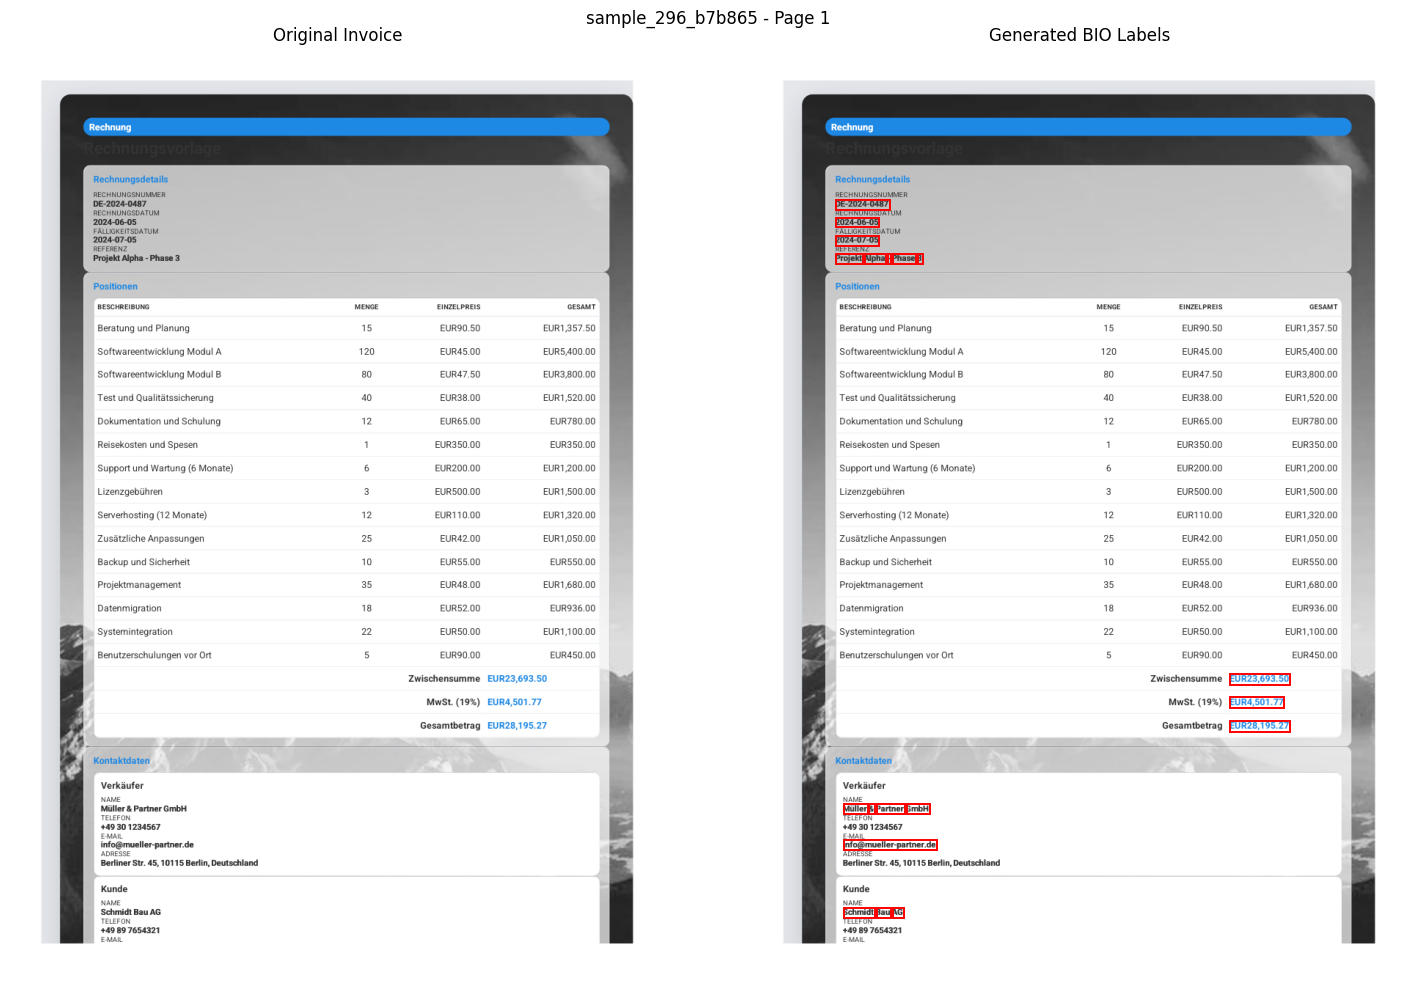


EXAMPLE LABELED WORDS:


,Word,BIO Label
0,DE-2024-0487,B-INVOICE_NUMBER
1,2024-06-05,B-INVOICE_DATE
2,2024-07-05,B-DUE_DATE
3,Projekt,B-REFERENCE
4,Alpha,I-REFERENCE
5,-,I-REFERENCE
6,Phase,I-REFERENCE
7,3,I-REFERENCE
8,"EUR23,693.50",B-SUBTOTAL
9,"EUR4,501.77",B-TAX



BIO label generation completed!


In [14]:

# ============================================================
# STRICT BIO LABEL GENERATION
# Uses page_samples and resolved_alignment_map
# No output files
# ============================================================

from collections import defaultdict, Counter
import pandas as pd
import pymupdf
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Rectangle
from IPython.display import display

assert "page_samples" in globals() and page_samples
assert "resolved_alignment_map" in globals()

ENTITIES = [
    "INVOICE_NUMBER",
    "INVOICE_DATE",
    "DUE_DATE",
    "REFERENCE",
    "SELLER_NAME",
    "SELLER_EMAIL",
    "CLIENT_NAME",
    "CLIENT_EMAIL",
    "SUBTOTAL",
    "TAX",
    "TOTAL_DUE"
]

LABELS = ["O"]

for entity in ENTITIES:
    LABELS.extend([
        f"B-{entity}",
        f"I-{entity}"
    ])

label2id = {v: i for i, v in enumerate(LABELS)}
id2label = {i: v for v, i in label2id.items()}

pages_by_invoice = defaultdict(list)

for page in page_samples:
    pages_by_invoice[page["invoice_id"]].append(page)

strict_pages = []
strict_invoice_ids = []
skipped = Counter()

# ============================================================
# 1. SELECT FULLY ALIGNED INVOICES
# ============================================================

for invoice_id, pages in pages_by_invoice.items():

    results = resolved_alignment_map[invoice_id]

    # Require all 11 fields to be present and resolved
    if not all(
        results[entity]["status"]
        in ("UNIQUE", "CONTEXT_RESOLVED")
        for entity in ENTITIES
    ):
        skipped["Incomplete alignment"] += 1
        continue

    page_map = {
        p["page_number"]: p
        for p in pages
    }

    # Initialize every OCR word as background
    label_map = {
        p["page_number"]: ["O"] * len(p["words"])
        for p in pages
    }

    valid = True

    for entity in ENTITIES:

        result = results[entity]

        if result["status"] == "CONTEXT_RESOLVED":
            candidate = result.get("selected_candidate")
        else:
            candidates = result["candidates"]
            candidate = (
                candidates[0]
                if len(candidates) == 1 else None
            )

        if candidate is None:
            valid = False
            break

        page_no = candidate["page"]
        start = candidate["start"]
        end = candidate["end"]

        if page_no not in page_map:
            valid = False
            break

        word_count = len(page_map[page_no]["words"])

        if not (0 <= start < end <= word_count):
            valid = False
            break

        labels = label_map[page_no]

        # Prevent two entities sharing the same words
        if any(
            labels[i] != "O"
            for i in range(start, end)
        ):
            valid = False
            break

        labels[start] = f"B-{entity}"

        for i in range(start + 1, end):
            labels[i] = f"I-{entity}"

    if not valid:
        skipped["Overlap/invalid span"] += 1
        continue

    strict_invoice_ids.append(invoice_id)

    # ========================================================
    # 2. GENERATE PAGE-WISE TRAINING RECORDS
    # ========================================================

    for page in sorted(
        pages, key=lambda p: p["page_number"]
    ):

        tags = label_map[page["page_number"]]

        positive_count = sum(
            tag != "O" for tag in tags
        )

        # Skip tiny, background-only decorative pages
        if len(tags) < 10 and positive_count == 0:
            continue

        strict_pages.append({
            "invoice_id": invoice_id,
            "pdf": page["pdf"],
            "page_index": page["page_index"],
            "page_number": page["page_number"],
            "words": page["words"],
            "boxes": page["boxes"],
            "bio_labels": tags,
            "label_ids": [
                label2id[tag] for tag in tags
            ]
        })


# ============================================================
# 3. LABEL QUALITY REPORT
# ============================================================

print("=" * 65)
print("STRICT BIO LABEL GENERATION RESULTS")
print("=" * 65)

print("Total invoices:", len(pages_by_invoice))
print("Strictly aligned invoices:", len(strict_invoice_ids))
print("Generated labeled pages:", len(strict_pages))

print("\nSKIPPED INVOICES:")
print(dict(skipped))

if not strict_pages:
    raise RuntimeError(
        "No strictly aligned pages found. "
        "A relaxed, masked-label strategy is needed."
    )

tag_counts = Counter(
    tag
    for page in strict_pages
    for tag in page["bio_labels"]
)

print("\nLABEL DISTRIBUTION:")

tag_df = pd.DataFrame([
    {"Label": tag, "Count": tag_counts[tag]}
    for tag in LABELS
])

display(tag_df)

print("\nENTITY VS BACKGROUND:")

entity_count = sum(
    count for tag, count in tag_counts.items()
    if tag != "O"
)

background_count = tag_counts["O"]

print("Entity-labeled words:", entity_count)
print("Background words:", background_count)
print(
    "Background ratio:",
    round(
        background_count /
        (entity_count + background_count) * 100, 2
    ),
    "%"
)

# ============================================================
# 4. VISUALIZE ONE LABELED PAGE
# ============================================================

example = max(
    strict_pages,
    key=lambda p: sum(
        tag != "O" for tag in p["bio_labels"]
    )
)

with pymupdf.open(example["pdf"]) as doc:
    pix = doc[example["page_index"]].get_pixmap(
        matrix=pymupdf.Matrix(1.5, 1.5),
        alpha=False
    )

    image = Image.frombytes(
        "RGB",
        (pix.width, pix.height),
        pix.samples
    )

fig, axes = plt.subplots(1, 2, figsize=(15, 10))

axes[0].imshow(image)
axes[0].set_title("Original Invoice")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].set_title("Generated BIO Labels")
axes[1].axis("off")

scale_x = image.width / 1000
scale_y = image.height / 1000

rows = []

for word, box, label in zip(
    example["words"],
    example["boxes"],
    example["bio_labels"]
):

    if label == "O":
        continue

    x0, y0, x1, y1 = box

    axes[1].add_patch(Rectangle(
        (x0 * scale_x, y0 * scale_y),
        (x1 - x0) * scale_x,
        (y1 - y0) * scale_y,
        fill=False,
        edgecolor="red",
        linewidth=1.4
    ))

    rows.append({
        "Word": word,
        "BIO Label": label
    })

plt.suptitle(
    f"{example['invoice_id']} - Page "
    f"{example['page_number']}"
)

plt.tight_layout()
plt.show()

print("\nEXAMPLE LABELED WORDS:")
display(pd.DataFrame(rows))

print("\nBIO label generation completed!")


In [15]:

# ============================================================
# PROJECT 9: WINDOWING + INVOICE-LEVEL SPLITTING
# ============================================================

import hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import pymupdf

from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display
from transformers import AutoProcessor
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import Dataset, DataLoader

assert "strict_pages" in globals() and strict_pages, \
    "Run BIO label generation first."

assert "resolved_alignment_map" in globals(), \
    "Run context resolution first."

MODEL_NAME = "microsoft/layoutlmv3-base"
MAX_LENGTH = 512
OVERLAP_WORDS = 20
BATCH_SIZE = 2
SEED = 42

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    apply_ocr=False
)

tokenizer = processor.tokenizer

assert tokenizer.is_fast

TOKEN_BUDGET = (
    MAX_LENGTH -
    tokenizer.num_special_tokens_to_add(pair=False)
)

# ============================================================
# 1. MASK UNCERTAIN DUPLICATE OCCURRENCES
# ============================================================

prepared_pages = []
masked_duplicates = 0

for page in strict_pages:

    record = page.copy()
    labels = list(page["label_ids"])
    results = resolved_alignment_map[page["invoice_id"]]

    for entity, result in results.items():

        if result["status"] != "CONTEXT_RESOLVED":
            continue

        selected = result["selected_candidate"]

        for candidate in result["candidates"]:

            if candidate["page"] != page["page_number"]:
                continue

            same = (
                candidate["page"] == selected["page"]
                and candidate["start"] == selected["start"]
                and candidate["end"] == selected["end"]
            )

            if same:
                continue

            for i in range(
                candidate["start"],
                candidate["end"]
            ):
                if labels[i] == 0:
                    labels[i] = -100
                    masked_duplicates += 1

    record["training_label_ids"] = labels
    prepared_pages.append(record)

print("Uncertain duplicate words masked:",
      masked_duplicates)


# ============================================================
# 2. SPLIT AT INVOICE LEVEL, BEFORE WINDOWING
# ============================================================

invoice_ids = sorted({
    p["invoice_id"] for p in prepared_pages
})

pdf_by_invoice = {
    p["invoice_id"]: p["pdf"]
    for p in prepared_pages
}

# Group byte-identical PDFs together
groups = []

for invoice_id in invoice_ids:
    pdf_bytes = Path(
        pdf_by_invoice[invoice_id]
    ).read_bytes()

    groups.append(
        hashlib.sha256(pdf_bytes).hexdigest()
    )

groups = np.array(groups)
indices = np.arange(len(invoice_ids))

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_idx, temp_idx = next(
    splitter.split(indices, groups=groups)
)

splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED
)

val_pos, test_pos = next(
    splitter2.split(
        temp_idx,
        groups=groups[temp_idx]
    )
)

val_idx = temp_idx[val_pos]
test_idx = temp_idx[test_pos]

split_map = {}

for name, selected in (
    ("train", train_idx),
    ("val", val_idx),
    ("test", test_idx)
):
    for idx in selected:
        split_map[invoice_ids[idx]] = name

# Verify invoice and identical-PDF group isolation
assert len(split_map) == len(invoice_ids)

for a, b in (
    (train_idx, val_idx),
    (train_idx, test_idx),
    (val_idx, test_idx)
):
    assert set(groups[a]).isdisjoint(set(groups[b]))

print("\n========== INVOICE-LEVEL SPLIT ==========")

display(pd.DataFrame([
    {
        "Split": split,
        "Invoices": sum(
            v == split for v in split_map.values()
        )
    }
    for split in ("train", "val", "test")
]))


# ============================================================
# 3. TOKEN COUNTS FOR EACH OCR WORD
# ============================================================

def word_token_counts(words, boxes):

    encoded = tokenizer(
        words,
        boxes=boxes,
        add_special_tokens=False,
        padding=False,
        truncation=False
    )

    counts = Counter(
        wid for wid in encoded.word_ids()
        if wid is not None
    )

    return [counts.get(i, 0) for i in range(len(words))]


# ============================================================
# 4. ENTITY-AWARE SLIDING WINDOWS
# ============================================================

def create_windows(page):

    words = page["words"]
    boxes = page["boxes"]
    bio = page["bio_labels"]
    labels = page["training_label_ids"]

    n = len(words)

    assert n == len(boxes) == len(bio) == len(labels)

    token_counts = word_token_counts(words, boxes)

    if any(
        c == 0 or c > TOKEN_BUDGET
        for c in token_counts
    ):
        raise ValueError(
            "A word has zero or excessive tokens."
        )

    windows = []

    start = 0
    covered_until = 0
    covered_words = set()

    while start < n:

        end = start
        total = 0

        # Fit full OCR words into the token budget
        while (
            end < n
            and total + token_counts[end] <= TOKEN_BUDGET
        ):
            total += token_counts[end]
            end += 1

        if end == start:
            raise ValueError("Cannot fit next word.")

        # Do not cut a BIO entity in the middle
        if end < n and bio[end].startswith("I-"):

            boundary = end

            while (
                boundary > start
                and bio[boundary].startswith("I-")
            ):
                boundary -= 1

            if boundary == start:
                raise ValueError(
                    "Entity too long for one window."
                )

            end = boundary

        # If overlap consumes the whole window,
        # retry without the overlapping context
        if end <= covered_until:
            start = covered_until
            continue

        # Ignore already-supervised overlap words
        window_labels = [
            labels[i] if i >= covered_until else -100
            for i in range(start, end)
        ]

        check = tokenizer(
            words[start:end],
            boxes=boxes[start:end],
            word_labels=window_labels,
            truncation=False,
            padding=False
        )

        if len(check["input_ids"]) > MAX_LENGTH:
            raise ValueError("Window exceeds token limit.")

        windows.append({
            "invoice_id": page["invoice_id"],
            "pdf": page["pdf"],
            "page_index": page["page_index"],
            "page_number": page["page_number"],
            "split": split_map[page["invoice_id"]],
            "words": words[start:end],
            "boxes": boxes[start:end],
            "label_ids": window_labels,
            "word_start": start,
            "word_end": end,
            "token_length": len(check["input_ids"])
        })

        covered_words.update(
            range(max(start, covered_until), end)
        )

        covered_until = end

        if end == n:
            break

        # Add left context to the next window
        next_start = max(
            start + 1,
            end - OVERLAP_WORDS
        )

        # Avoid beginning inside a multiword entity
        while (
            next_start > start
            and bio[next_start].startswith("I-")
        ):
            next_start -= 1

        if next_start <= start:
            next_start = end

        start = next_start

    # No OCR word may be lost
    assert covered_words == set(range(n))

    return windows


# ============================================================
# 5. GENERATE WINDOWS FOR ALL PAGES
# ============================================================

window_samples = []
failed_pages = []

for page in tqdm(
    prepared_pages,
    desc="Creating token windows"
):
    try:
        windows = create_windows(page)
        window_samples.extend(windows)

    except Exception as e:
        failed_pages.append({
            "Invoice": page["invoice_id"],
            "Page": page["page_number"],
            "Error": str(e)
        })

print("\n========== WINDOWING AUDIT ==========")

print("Input pages:", len(prepared_pages))
print("Created windows:", len(window_samples))
print("Failed pages:", len(failed_pages))

if failed_pages:
    display(pd.DataFrame(failed_pages).head(15))
    raise RuntimeError(
        "Some pages failed windowing. Fix before training."
    )

window_df = pd.DataFrame([
    {
        "Invoice": w["invoice_id"],
        "Page": w["page_number"],
        "Split": w["split"],
        "Tokens": w["token_length"],
        "Entity Tokens": sum(
            label > 0 for label in w["label_ids"]
        ),
        "Background Tokens": sum(
            label == 0 for label in w["label_ids"]
        )
    }
    for w in window_samples
])

display(window_df.groupby("Split").agg(
    Windows=("Tokens", "size"),
    Mean_Tokens=("Tokens", "mean"),
    Max_Tokens=("Tokens", "max"),
    Entity_Words=("Entity Tokens", "sum"),
    Background_Words=("Background Tokens", "sum")
).round(2))

print("\nWindows exceeding 512:",
      int((window_df["Tokens"] > 512).sum()))

print("Windows containing entity labels:",
      int((window_df["Entity Tokens"] > 0).sum()))

# ============================================================
# 6. FINAL PYTORCH DATASET
# ============================================================

class InvoiceWindowDataset(Dataset):

    def __init__(self, records, processor):
        self.records = records
        self.processor = processor

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):

        record = self.records[idx]

        with pymupdf.open(record["pdf"]) as doc:
            page = doc[record["page_index"]]

            pix = page.get_pixmap(
                matrix=pymupdf.Matrix(1.5, 1.5),
                alpha=False
            )

            image = Image.frombytes(
                "RGB",
                (pix.width, pix.height),
                pix.samples
            )

        encoding = self.processor(
            image,
            record["words"],
            boxes=record["boxes"],
            word_labels=record["label_ids"],
            truncation=False,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        return {
            k: v.squeeze(0)
            for k, v in encoding.items()
            if isinstance(v, torch.Tensor)
        }


train_windows = [
    w for w in window_samples if w["split"] == "train"
]

val_windows = [
    w for w in window_samples if w["split"] == "val"
]

test_windows = [
    w for w in window_samples if w["split"] == "test"
]

assert all(
    len(rows) > 0
    for rows in (train_windows, val_windows, test_windows)
)

train_dataset = InvoiceWindowDataset(
    train_windows, processor
)

val_dataset = InvoiceWindowDataset(
    val_windows, processor
)

test_dataset = InvoiceWindowDataset(
    test_windows, processor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ============================================================
# 7. VERIFY MODEL-READY BATCH
# ============================================================

batch = next(iter(train_loader))

print("\n========== MODEL INPUT SHAPES ==========")

for key, value in batch.items():
    print(f"{key:20s}: {tuple(value.shape)}")

print("\n========== FINAL SUMMARY ==========")

print("Train windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))
print("Test windows:", len(test_dataset))

print("Supervised entity tokens:",
      int((batch["labels"] > 0).sum()))

print("Supervised background tokens:",
      int((batch["labels"] == 0).sum()))

print("Ignored token positions:",
      int((batch["labels"] == -100).sum()))

print("\nWindowing and DataLoader preparation completed!")


Uncertain duplicate words masked: 23

========== INVOICE-LEVEL SPLIT ==========


,Split,Invoices
0,train,151
1,val,19
2,test,19


Creating token windows:   0%|          | 0/322 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (608 > 512). Running this sequence through the model will result in indexing errors



========== WINDOWING AUDIT ==========
Input pages: 322
Created windows: 398
Failed pages: 0


,Windows,Mean_Tokens,Max_Tokens,Entity_Words,Background_Words
Split,,,,,
test,33,330.79,512,282,2963
train,328,323.29,512,2299,27485
val,37,317.78,509,297,3265



Windows exceeding 512: 0
Windows containing entity labels: 332

========== MODEL INPUT SHAPES ==========
input_ids           : (2, 512)
attention_mask      : (2, 512)
bbox                : (2, 512, 4)
labels              : (2, 512)
pixel_values        : (2, 3, 224, 224)

========== FINAL SUMMARY ==========
Train windows: 328
Validation windows: 37
Test windows: 33
Supervised entity tokens: 6
Supervised background tokens: 256
Ignored token positions: 762

Windowing and DataLoader preparation completed!


In [16]:

# ============================================================
# PROJECT 9: LAYOUTLMv3 DATASET & DATALOADER
# ============================================================

import torch
import pymupdf
import pandas as pd
import numpy as np

from PIL import Image
from pathlib import Path
from functools import lru_cache
from collections import Counter
from IPython.display import display
from torch.utils.data import Dataset, DataLoader
from transformers import AutoProcessor


# ============================================================
# 1. CONFIGURATION
# ============================================================

MODEL_NAME = "microsoft/layoutlmv3-base"

MAX_LENGTH = 512
BATCH_SIZE = 2
NUM_WORKERS = 0
SEED = 42

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(SEED)

print("=" * 60)
print("DATASET CONFIGURATION")
print("=" * 60)

print("Device:", device)
print("Model:", MODEL_NAME)
print("Batch Size:", BATCH_SIZE)
print("Max Sequence Length:", MAX_LENGTH)


# ============================================================
# 2. VERIFY PREPROCESSED WINDOW DATA
# ============================================================

if "window_samples" not in globals():
    raise RuntimeError(
        "window_samples not found. "
        "Run the previous windowing cell first."
    )

if not window_samples:
    raise RuntimeError("window_samples is empty.")

required_keys = {
    "invoice_id",
    "pdf",
    "page_index",
    "split",
    "words",
    "boxes",
    "label_ids"
}

for idx, sample in enumerate(window_samples):

    missing = required_keys - set(sample)

    if missing:
        raise ValueError(
            f"Window {idx} missing keys: {missing}"
        )

    words = sample["words"]
    boxes = sample["boxes"]
    labels = sample["label_ids"]

    if not (
        len(words) == len(boxes) == len(labels)
        and len(words) > 0
    ):
        raise ValueError(
            f"Invalid word/box/label lengths at window {idx}"
        )

    if not Path(sample["pdf"]).is_file():
        raise FileNotFoundError(sample["pdf"])

    for box in boxes:
        if not (
            len(box) == 4
            and all(0 <= int(v) <= 1000 for v in box)
            and box[0] <= box[2]
            and box[1] <= box[3]
        ):
            raise ValueError(
                f"Invalid bounding box at window {idx}"
            )

    if "token_length" in sample:
        if sample["token_length"] > MAX_LENGTH:
            raise ValueError(
                f"Window {idx} exceeds {MAX_LENGTH} tokens"
            )

    if any(label < -100 for label in labels):
        raise ValueError(f"Invalid label at window {idx}")

print("\nTotal verified windows:", len(window_samples))


# ============================================================
# 3. VERIFY INVOICE-LEVEL SPLIT ISOLATION
# ============================================================

invoice_split = {}

for sample in window_samples:

    invoice_id = sample["invoice_id"]
    split = sample["split"]

    if split not in {"train", "val", "test"}:
        raise ValueError(f"Unknown split: {split}")

    if invoice_id in invoice_split:
        assert invoice_split[invoice_id] == split, (
            f"Data leakage detected for {invoice_id}"
        )
    else:
        invoice_split[invoice_id] = split

print("Invoice-level split isolation: PASSED")


# ============================================================
# 4. CREATE TRAIN / VALIDATION / TEST RECORDS
# ============================================================

train_records = [
    s for s in window_samples
    if s["split"] == "train"
]

val_records = [
    s for s in window_samples
    if s["split"] == "val"
]

test_records = [
    s for s in window_samples
    if s["split"] == "test"
]

assert all(
    len(records) > 0
    for records in (
        train_records,
        val_records,
        test_records
    )
), "One or more dataset splits are empty."

split_summary = []

for split_name, records in [
    ("Train", train_records),
    ("Validation", val_records),
    ("Test", test_records)
]:

    split_summary.append({
        "Split": split_name,
        "Invoices": len(set(
            s["invoice_id"] for s in records
        )),
        "Windows": len(records),
        "Entity Words": sum(
            sum(label > 0 for label in s["label_ids"])
            for s in records
        ),
        "Background Words": sum(
            sum(label == 0 for label in s["label_ids"])
            for s in records
        )
    })

print("\n" + "=" * 60)
print("DATASET SPLIT SUMMARY")
print("=" * 60)

display(pd.DataFrame(split_summary))


# ============================================================
# 5. LOAD LAYOUTLMv3 PROCESSOR
# ============================================================

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    apply_ocr=False
)

print("\nProcessor loaded successfully!")
print("Tokenizer:", type(processor.tokenizer).__name__)
print(
    "Image Processor:",
    type(processor.image_processor).__name__
)


# ============================================================
# 6. PDF PAGE TO RGB IMAGE
# ============================================================

# Cache recent pages to avoid repeated PDF rendering.
# Multiple windows from the same page share the same image.

@lru_cache(maxsize=16)
def render_pdf_page(pdf_path, page_index):

    with pymupdf.open(pdf_path) as doc:

        page = doc[page_index]

        pix = page.get_pixmap(
            matrix=pymupdf.Matrix(1.5, 1.5),
            alpha=False
        )

        image = Image.frombytes(
            "RGB",
            (pix.width, pix.height),
            pix.samples
        )

    return image


# ============================================================
# 7. CUSTOM PYTORCH DATASET
# ============================================================

class InvoiceDataset(Dataset):

    def __init__(self, records, processor, max_length=512):

        self.records = records
        self.processor = processor
        self.max_length = max_length

    def __len__(self):

        return len(self.records)

    def __getitem__(self, idx):

        sample = self.records[idx]

        # ------------------------------
        # Step 1: Load PDF page image
        # ------------------------------

        image = render_pdf_page(
            str(sample["pdf"]),
            int(sample["page_index"])
        ).copy()

        # ------------------------------
        # Step 2: Get OCR information
        # ------------------------------

        words = sample["words"]
        boxes = sample["boxes"]
        word_labels = sample["label_ids"]

        # ------------------------------
        # Step 3: LayoutLMv3 processing
        # ------------------------------

        # Processor handles:
        # - Image resizing
        # - Image normalization
        # - Text tokenization
        # - Word-to-subword alignment
        # - Padding
        #
        # Truncation disabled because windows
        # were already verified to fit 512 tokens.

        encoding = self.processor(
            images=image,
            text=words,
            boxes=boxes,
            word_labels=word_labels,
            padding="max_length",
            truncation=False,
            max_length=self.max_length,
            return_tensors="pt"
        )

        # ------------------------------
        # Step 4: Remove batch dimension
        # ------------------------------

        output = {
            key: value.squeeze(0)
            for key, value in encoding.items()
            if isinstance(value, torch.Tensor)
        }

        # Only return inputs used by the model
        expected_keys = (
            "input_ids",
            "attention_mask",
            "bbox",
            "pixel_values",
            "labels"
        )

        output = {
            key: output[key]
            for key in expected_keys
        }

        # ------------------------------
        # Step 5: Validate tensors
        # ------------------------------

        assert output["input_ids"].shape == (
            self.max_length,
        )

        assert output["bbox"].shape == (
            self.max_length, 4
        )

        assert output["labels"].shape == (
            self.max_length,
        )

        assert output["pixel_values"].shape == (
            3, 224, 224
        )

        return output


# ============================================================
# 8. INITIALIZE DATASETS
# ============================================================

train_dataset = InvoiceDataset(
    train_records,
    processor,
    MAX_LENGTH
)

val_dataset = InvoiceDataset(
    val_records,
    processor,
    MAX_LENGTH
)

test_dataset = InvoiceDataset(
    test_records,
    processor,
    MAX_LENGTH
)

print("\n" + "=" * 60)
print("DATASET SIZES")
print("=" * 60)

print("Train Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Test Dataset:", len(test_dataset))


# ============================================================
# 9. INITIALIZE DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

print("\n" + "=" * 60)
print("DATALOADER SIZES")
print("=" * 60)

print("Train Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Test Batches:", len(test_loader))


# ============================================================
# 10. VERIFY ONE TRAINING BATCH
# ============================================================

batch = next(iter(train_loader))

print("\n" + "=" * 60)
print("BATCH TENSOR SHAPES")
print("=" * 60)

for key, tensor in batch.items():
    print(f"{key:20s}: {tuple(tensor.shape)}")

print("\nBATCH DATA TYPES")

for key, tensor in batch.items():
    print(f"{key:20s}: {tensor.dtype}")


# ============================================================
# 11. VERIFY LABELS
# ============================================================

labels = batch["labels"]

entity_tokens = (labels > 0).sum().item()
background_tokens = (labels == 0).sum().item()
ignored_tokens = (labels == -100).sum().item()

print("\n" + "=" * 60)
print("BATCH LABEL STATISTICS")
print("=" * 60)

print("Entity-labeled tokens:", entity_tokens)
print("Background tokens:", background_tokens)
print("Ignored tokens:", ignored_tokens)

assert (
    entity_tokens + background_tokens + ignored_tokens
    == labels.numel()
), "Invalid label IDs detected."

assert torch.isfinite(
    batch["pixel_values"]
).all(), "Invalid pixel values detected."


# ============================================================
# 12. DISPLAY ONE SAMPLE'S SUPERVISED LABELS
# ============================================================

print("\n" + "=" * 60)
print("SAMPLE TOKEN / LABEL PREVIEW")
print("=" * 60)

sample = train_dataset[0]

input_ids = sample["input_ids"]
sample_labels = sample["labels"]

tokens = processor.tokenizer.convert_ids_to_tokens(
    input_ids.tolist()
)

label_names = (
    id2label
    if "id2label" in globals()
    else {}
)

rows = []

for token, label in zip(tokens, sample_labels.tolist()):

    if label == -100:
        continue

    rows.append({
        "Token": token,
        "Label ID": label,
        "Label": label_names.get(label, str(label))
    })

print("Showing first 30 supervised tokens:")
display(pd.DataFrame(rows).head(30))


# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("DATASET & DATALOADER READY")
print("=" * 60)

print("Training Windows:", len(train_dataset))
print("Validation Windows:", len(val_dataset))
print("Test Windows:", len(test_dataset))

print("\nBatch Size:", BATCH_SIZE)
print("Maximum Text Tokens:", MAX_LENGTH)
print("Device:", device)

print("\nAll Dataset/DataLoader checks PASSED!")


DATASET CONFIGURATION
Device: cuda
Model: microsoft/layoutlmv3-base
Batch Size: 2
Max Sequence Length: 512

Total verified windows: 398
Invoice-level split isolation: PASSED

DATASET SPLIT SUMMARY


,Split,Invoices,Windows,Entity Words,Background Words
0,Train,151,328,2299,27485
1,Validation,19,37,297,3265
2,Test,19,33,282,2963



Processor loaded successfully!
Tokenizer: LayoutLMv3Tokenizer
Image Processor: LayoutLMv3ImageProcessor

DATASET SIZES
Train Dataset: 328
Validation Dataset: 37
Test Dataset: 33

DATALOADER SIZES
Train Batches: 164
Validation Batches: 19
Test Batches: 17

BATCH TENSOR SHAPES
input_ids           : (2, 512)
attention_mask      : (2, 512)
bbox                : (2, 512, 4)
pixel_values        : (2, 3, 224, 224)
labels              : (2, 512)

BATCH DATA TYPES
input_ids           : torch.int64
attention_mask      : torch.int64
bbox                : torch.int64
pixel_values        : torch.float32
labels              : torch.int64

BATCH LABEL STATISTICS
Entity-labeled tokens: 6
Background tokens: 127
Ignored tokens: 891

SAMPLE TOKEN / LABEL PREVIEW
Showing first 30 supervised tokens:


,Token,Label ID,Label
0,ĠInv,0,O
1,ĠProfessional,0,O
2,ĠInv,0,O
3,ĠInv,0,O
4,ĠItems,0,O
5,ĠDES,0,O
6,ĠQU,0,O
7,ĠUN,0,O
8,ĠPR,0,O
9,ĠLINE,0,O



DATASET & DATALOADER READY
Training Windows: 328
Validation Windows: 37
Test Windows: 33

Batch Size: 2
Maximum Text Tokens: 512
Device: cuda

All Dataset/DataLoader checks PASSED!


In [17]:

# ============================================================
# PROJECT 9: LAYOUTLMv3 MODEL INITIALIZATION
# Model + Loss + Optimizer + Scheduler + Helpers
#
# Run AFTER Dataset/DataLoader cell.
# Does NOT start training.
# ============================================================

import math
import random
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import SequentialSampler

from transformers import (
    LayoutLMv3ForTokenClassification,
    get_linear_schedule_with_warmup
)

from sklearn.metrics import (
    precision_recall_fscore_support,
    accuracy_score
)

from tqdm.auto import tqdm


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
MODEL_NAME = "microsoft/layoutlmv3-base"

NUM_EPOCHS = 5
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
ADAM_EPS = 1e-8

GRAD_ACCUM_STEPS = 2
MAX_GRAD_NORM = 1.0
WARMUP_RATIO = 0.10

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

assert "train_loader" in globals()
assert "val_loader" in globals()
assert "test_loader" in globals()


# ============================================================
# 2. LABEL CONFIGURATION
# ============================================================

ENTITY_NAMES = [
    "INVOICE_NUMBER",
    "INVOICE_DATE",
    "DUE_DATE",
    "REFERENCE",
    "SELLER_NAME",
    "SELLER_EMAIL",
    "CLIENT_NAME",
    "CLIENT_EMAIL",
    "SUBTOTAL",
    "TAX",
    "TOTAL_DUE"
]

expected_labels = ["O"]

for entity in ENTITY_NAMES:
    expected_labels.extend([
        f"B-{entity}",
        f"I-{entity}"
    ])

# Check consistency with the preprocessing labels
if "LABELS" in globals():
    if list(LABELS) != expected_labels:
        raise ValueError(
            "Label order differs from preprocessing!"
        )

LABELS = expected_labels

label2id = {
    label: idx
    for idx, label in enumerate(LABELS)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

NUM_LABELS = len(LABELS)

assert NUM_LABELS == 23

for split_name, dataset in [
    ("Train", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:
    for record in dataset.records:
        assert all(
            label == -100 or 0 <= label < NUM_LABELS
            for label in record["label_ids"]
        ), f"Invalid label in {split_name}"

print("=" * 65)
print("MODEL CONFIGURATION")
print("=" * 65)
print("Device:", device)
print("Classes:", NUM_LABELS)
print("Epochs:", NUM_EPOCHS)
print("Learning Rate:", LEARNING_RATE)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled.")


# ============================================================
# 3. INITIALIZE PRETRAINED LAYOUTLMv3
# ============================================================

model = LayoutLMv3ForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id
)

model = model.to(device)

# Full fine-tuning: all parameters trainable
for parameter in model.parameters():
    parameter.requires_grad = True

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\n" + "=" * 65)
print("MODEL ARCHITECTURE")
print("=" * 65)

print("Model:", type(model).__name__)
print("Hidden Size:", model.config.hidden_size)
print("Transformer Layers:", model.config.num_hidden_layers)
print("Attention Heads:", model.config.num_attention_heads)
print("Output Classes:", model.config.num_labels)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

print("\nClassification Head:")
print(model.classifier)


# ============================================================
# 4. LOSS FUNCTION
# ============================================================

# Standard multiclass token classification loss.
# -100 labels are ignored.
#
# Start without class weighting.
# We will analyze class imbalance after baseline training.

criterion = nn.CrossEntropyLoss(
    ignore_index=-100
)

print("\n" + "=" * 65)
print("LOSS FUNCTION")
print("=" * 65)

print("Loss:", criterion)
print("Ignore Index:", criterion.ignore_index)


# ============================================================
# 5. OPTIMIZER: ADAMW
# ============================================================

# Standard transformer fine-tuning setup:
# Do not apply weight decay to bias and LayerNorm.

no_decay = (
    "bias",
    "LayerNorm.weight",
    "layer_norm.weight",
    "layernorm.weight"
)

decay_parameters = []
no_decay_parameters = []

for name, parameter in model.named_parameters():

    if not parameter.requires_grad:
        continue

    if any(term in name for term in no_decay):
        no_decay_parameters.append(parameter)
    else:
        decay_parameters.append(parameter)

optimizer = AdamW(
    [
        {
            "params": decay_parameters,
            "weight_decay": WEIGHT_DECAY
        },
        {
            "params": no_decay_parameters,
            "weight_decay": 0.0
        }
    ],
    lr=LEARNING_RATE,
    eps=ADAM_EPS
)

print("\n" + "=" * 65)
print("OPTIMIZER")
print("=" * 65)

print("Optimizer: AdamW")
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)
print("Parameter Groups:", len(optimizer.param_groups))


# ============================================================
# 6. LEARNING RATE SCHEDULER
# ============================================================

updates_per_epoch = math.ceil(
    len(train_loader) / GRAD_ACCUM_STEPS
)

total_training_steps = (
    updates_per_epoch * NUM_EPOCHS
)

warmup_steps = int(
    WARMUP_RATIO * total_training_steps
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("\n" + "=" * 65)
print("LEARNING RATE SCHEDULER")
print("=" * 65)

print("Training Batches:", len(train_loader))
print("Gradient Accumulation:", GRAD_ACCUM_STEPS)
print("Optimizer Steps / Epoch:", updates_per_epoch)
print("Total Optimizer Steps:", total_training_steps)
print("Warmup Steps:", warmup_steps)


# ============================================================
# 7. AUTOMATIC MIXED PRECISION (AMP)
# ============================================================

USE_AMP = device.type == "cuda"

if USE_AMP and torch.cuda.is_bf16_supported():
    AMP_DTYPE = torch.bfloat16
else:
    AMP_DTYPE = torch.float16

USE_FP16_SCALER = (
    USE_AMP and AMP_DTYPE == torch.float16
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_FP16_SCALER
)

print("\n" + "=" * 65)
print("MIXED PRECISION")
print("=" * 65)

print("AMP Enabled:", USE_AMP)
print(
    "Precision:",
    str(AMP_DTYPE) if USE_AMP else "float32"
)
print("Gradient Scaler Enabled:", USE_FP16_SCALER)


# ============================================================
# 8. HELPER: MOVE BATCH TO DEVICE
# ============================================================

def move_batch_to_device(batch):
    return {
        key: value.to(
            device,
            non_blocking=(device.type == "cuda")
        )
        for key, value in batch.items()
    }


# ============================================================
# 9. HELPER: FORWARD PASS + LOSS
# ============================================================

def forward_batch(batch):

    if not torch.any(batch["labels"] != -100):
        raise ValueError(
            "Batch has no supervised tokens."
        )

    with torch.autocast(
        device_type=device.type,
        dtype=AMP_DTYPE,
        enabled=USE_AMP
    ):

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            bbox=batch["bbox"],
            pixel_values=batch["pixel_values"]
        )

        logits = outputs.logits

        # Compute Cross-Entropy in float32
        loss = criterion(
            logits.float().reshape(-1, NUM_LABELS),
            batch["labels"].reshape(-1)
        )

    return loss, logits


# ============================================================
# 10. HELPER: BACKWARD PASS
# ============================================================

def backward_step(loss, accumulation_factor):

    scaled_loss = loss / accumulation_factor

    if USE_FP16_SCALER:
        scaler.scale(scaled_loss).backward()
    else:
        scaled_loss.backward()


# ============================================================
# 11. HELPER: OPTIMIZER UPDATE
# ============================================================

def optimizer_update():

    if USE_FP16_SCALER:
        scaler.unscale_(optimizer)

    grad_norm = clip_grad_norm_(
        model.parameters(),
        max_norm=MAX_GRAD_NORM
    )

    if USE_FP16_SCALER:

        old_scale = scaler.get_scale()

        scaler.step(optimizer)
        scaler.update()

        # If overflow occurred, optimizer.step was skipped.
        step_completed = scaler.get_scale() >= old_scale

    else:
        optimizer.step()
        step_completed = True

    if step_completed:
        scheduler.step()

    optimizer.zero_grad(set_to_none=True)

    return float(grad_norm), step_completed


# ============================================================
# 12. HELPER: TOKEN-LEVEL METRICS
# ============================================================

def compute_token_metrics(logits, labels):

    predictions = logits.argmax(dim=-1)

    mask = labels != -100

    true_ids = labels[mask].detach().cpu().numpy()
    pred_ids = predictions[mask].detach().cpu().numpy()

    if len(true_ids) == 0:
        return {
            "token_accuracy": 0.0,
            "entity_token_precision": 0.0,
            "entity_token_recall": 0.0,
            "entity_token_f1": 0.0
        }

    positive_classes = list(range(1, NUM_LABELS))

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            true_ids,
            pred_ids,
            labels=positive_classes,
            average="micro",
            zero_division=0
        )
    )

    return {
        "token_accuracy": float(
            accuracy_score(true_ids, pred_ids)
        ),
        "entity_token_precision": float(precision),
        "entity_token_recall": float(recall),
        "entity_token_f1": float(f1)
    }


# ============================================================
# 13. HELPER: CONVERT PREDICTIONS TO BIO LABELS
# ============================================================

def decode_predictions(logits, labels):

    pred_ids = logits.argmax(dim=-1)

    pred_ids = pred_ids.detach().cpu().tolist()
    true_ids = labels.detach().cpu().tolist()

    decoded_predictions = []
    decoded_targets = []

    for pred_sequence, true_sequence in zip(
        pred_ids,
        true_ids
    ):

        valid_pred = []
        valid_true = []

        for pred, true in zip(
            pred_sequence,
            true_sequence
        ):

            if true == -100:
                continue

            valid_pred.append(id2label[int(pred)])
            valid_true.append(id2label[int(true)])

        decoded_predictions.append(valid_pred)
        decoded_targets.append(valid_true)

    return decoded_predictions, decoded_targets


# ============================================================
# 14. HELPER: STRICT ENTITY-LEVEL METRICS
# ============================================================

def compute_entity_metrics(
    true_sequences,
    predicted_sequences
):

    try:
        from seqeval.metrics import (
            precision_score as seq_precision,
            recall_score as seq_recall,
            f1_score as seq_f1
        )
        from seqeval.scheme import IOB2

    except ImportError:
        raise ImportError(
            "Install seqeval using: %pip install -q seqeval"
        )

    kwargs = {
        "mode": "strict",
        "scheme": IOB2,
        "zero_division": 0
    }

    return {
        "precision": float(
            seq_precision(
                true_sequences,
                predicted_sequences,
                **kwargs
            )
        ),
        "recall": float(
            seq_recall(
                true_sequences,
                predicted_sequences,
                **kwargs
            )
        ),
        "f1": float(
            seq_f1(
                true_sequences,
                predicted_sequences,
                **kwargs
            )
        )
    }


# ============================================================
# 15. HELPER: RECONSTRUCT PAGE-LEVEL PREDICTIONS
# ============================================================

def reconstruct_page_sequences(page_predictions):

    true_sequences = []
    predicted_sequences = []

    for page_key in sorted(page_predictions):

        positions = sorted(page_predictions[page_key])

        current_true = []
        current_pred = []
        previous_position = None

        for position in positions:

            true_id, pred_id = (
                page_predictions[page_key][position]
            )

            # A gap indicates one or more ignored words.
            if (
                previous_position is not None
                and position != previous_position + 1
            ):
                if current_true:
                    true_sequences.append(current_true)
                    predicted_sequences.append(current_pred)

                current_true = []
                current_pred = []

            current_true.append(id2label[true_id])
            current_pred.append(id2label[pred_id])

            previous_position = position

        if current_true:
            true_sequences.append(current_true)
            predicted_sequences.append(current_pred)

    return true_sequences, predicted_sequences


# ============================================================
# 16. HELPER: VALIDATION / TEST EVALUATION
# ============================================================

@torch.no_grad()
def evaluate_one_epoch(loader):

    # Evaluation requires records in their original order.
    if not isinstance(loader.sampler, SequentialSampler):
        raise ValueError(
            "Evaluation DataLoader must have shuffle=False."
        )

    model.eval()

    total_loss = 0.0
    supervised_tokens = 0

    page_predictions = defaultdict(dict)

    offset = 0

    progress = tqdm(
        loader,
        desc="Evaluating",
        leave=False
    )

    for batch in progress:

        batch = move_batch_to_device(batch)

        loss, logits = forward_batch(batch)

        gold = batch["labels"].cpu()
        pred = logits.argmax(dim=-1).cpu()

        batch_size = gold.shape[0]

        records = loader.dataset.records[
            offset:offset + batch_size
        ]

        offset += batch_size

        count = int((gold != -100).sum())

        total_loss += loss.item() * count
        supervised_tokens += count

        for row, record in enumerate(records):

            token_positions = (
                (gold[row] != -100)
                .nonzero(as_tuple=True)[0]
                .tolist()
            )

            word_positions = [
                i
                for i, label in enumerate(
                    record["label_ids"]
                )
                if label != -100
            ]

            if len(token_positions) != len(word_positions):
                raise RuntimeError(
                    "Token/word label alignment mismatch."
                )

            key = (
                record["invoice_id"],
                record["page_index"]
            )

            for token_pos, word_pos in zip(
                token_positions,
                word_positions
            ):

                global_pos = (
                    record["word_start"] + word_pos
                )

                if global_pos in page_predictions[key]:
                    raise RuntimeError(
                        "Duplicate supervised word detected."
                    )

                page_predictions[key][global_pos] = (
                    int(gold[row, token_pos]),
                    int(pred[row, token_pos])
                )

    assert offset == len(loader.dataset)

    true_sequences, predicted_sequences = (
        reconstruct_page_sequences(page_predictions)
    )

    metrics = compute_entity_metrics(
        true_sequences,
        predicted_sequences
    )

    metrics["loss"] = (
        total_loss / max(1, supervised_tokens)
    )

    metrics["supervised_words"] = supervised_tokens

    return metrics


# ============================================================
# 17. HELPER: CURRENT LEARNING RATE
# ============================================================

def get_current_lr():
    return optimizer.param_groups[0]["lr"]


# ============================================================
# 18. FINAL INITIALIZATION SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("MODEL INITIALIZATION COMPLETED")
print("=" * 65)

print("Model:", MODEL_NAME)
print("Number of Classes:", NUM_LABELS)

print("\nTraining Configuration:")
print("Epochs:", NUM_EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)
print("Gradient Accumulation:", GRAD_ACCUM_STEPS)
print("Max Gradient Norm:", MAX_GRAD_NORM)
print("Warmup Steps:", warmup_steps)

print("\nDatasets:")
print("Train Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Test Batches:", len(test_loader))

print("\nLoss, optimizer, scheduler and helpers ready.")
print("Training has NOT started.")


MODEL CONFIGURATION
Device: cuda
Classes: 23
Epochs: 5
Learning Rate: 2e-05
GPU: Tesla T4


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key                        | Status  | 
---------------------------+---------+-
classifier.out_proj.weight | MISSING | 
classifier.dense.bias      | MISSING | 
classifier.out_proj.bias   | MISSING | 
classifier.dense.weight    | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



MODEL ARCHITECTURE
Model: LayoutLMv3ForTokenClassification
Hidden Size: 768
Transformer Layers: 12
Attention Heads: 12
Output Classes: 23
Total Parameters: 125,935,255
Trainable Parameters: 125,935,255

Classification Head:
LayoutLMv3ClassificationHead(
  (dense): Linear(in_features=768, out_features=768, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (out_proj): Linear(in_features=768, out_features=23, bias=True)
)

LOSS FUNCTION
Loss: CrossEntropyLoss()
Ignore Index: -100

OPTIMIZER
Optimizer: AdamW
Learning Rate: 2e-05
Weight Decay: 0.01
Parameter Groups: 2

LEARNING RATE SCHEDULER
Training Batches: 164
Gradient Accumulation: 2
Optimizer Steps / Epoch: 82
Total Optimizer Steps: 410
Warmup Steps: 41

MIXED PRECISION
AMP Enabled: True
Precision: torch.bfloat16
Gradient Scaler Enabled: False

MODEL INITIALIZATION COMPLETED
Model: microsoft/layoutlmv3-base
Number of Classes: 23

Training Configuration:
Epochs: 5
Learning Rate: 2e-05
Weight Decay: 0.01
Gradient Accumulation: 2


In [18]:
%pip install --use-pep517 --no-cache-dir seqeval==1.2.2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 27.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16251 sha256=aaf68f27533f405617eab7d0a892947c4a7b406cb926f3d027c5b48bc766cb83
  Stored in directory: /tmp/pip-ephem-wheel-cache-tu0a0etk/wheels/14/cf/a7/8f28ef376d707ff10e3922899482a2f23ef3002f8a952f47ac
Successfully built seqeval
Note: you may need to restart the kernel to use updated packages.


TRAINING CONFIGURATION
Configured Device: cuda:0
Actual Model Device: cuda:0
GPU: Tesla T4
AMP Precision: torch.bfloat16
Training Windows: 328
Validation Windows: 37
Epochs: 5
Gradient Accumulation: 2
Number of Classes: 23

STARTING LAYOUTLMv3 TRAINING


Epoch 1/5 - Train:   0%|          | 0/164 [00:00<?, ?it/s]

Validation:   0%|          | 0/19 [00:00<?, ?it/s]


EPOCH 1/5 RESULTS
Training Loss   : 1.06260
Validation Loss : 0.35972
Val Precision   : 0.0000
Val Recall      : 0.0000
Val Entity F1   : 0.0000
Learning Rate   : 0.00001778
Optimizer Steps : 82
Epoch Time      : 122.3s
Status: BEST MODEL UPDATED


Epoch 2/5 - Train:   0%|          | 0/164 [00:00<?, ?it/s]

...


EPOCH 4/5 RESULTS
Training Loss   : 0.07743
Validation Loss : 0.06595
Val Precision   : 0.8238
Val Recall      : 0.8278
Val Entity F1   : 0.8258
Learning Rate   : 0.00000444
Optimizer Steps : 82
Epoch Time      : 126.2s
Status: BEST MODEL UPDATED


Epoch 5/5 - Train:   0%|          | 0/164 [00:00<?, ?it/s]

Validation:   0%|          | 0/19 [00:00<?, ?it/s]


EPOCH 5/5 RESULTS
Training Loss   : 0.06248
Validation Loss : 0.05266
Val Precision   : 0.8947
Val Recall      : 0.8947
Val Entity F1   : 0.8947
Learning Rate   : 0.00000000
Optimizer Steps : 82
Epoch Time      : 125.5s
Status: BEST MODEL UPDATED

BEST MODEL RESTORED
Best Epoch: 5
Best Validation F1: 0.8947
Best Validation Loss: 0.05266

========== TRAINING HISTORY ==========


,Epoch,Train Loss,Val Loss,Val Precision,Val Recall,Val F1,Optimizer Updates,Time (s)
0,1,1.0626,0.3597,0.0000,0.0000,0.0000,82,122.3
1,2,0.2425,0.1574,0.4530,0.3923,0.4205,82,125.8
2,3,0.1186,0.0815,0.7452,0.7416,0.7434,82,125.7
3,4,0.0774,0.0659,0.8238,0.8278,0.8258,82,126.2
4,5,0.0625,0.0527,0.8947,0.8947,0.8947,82,125.5


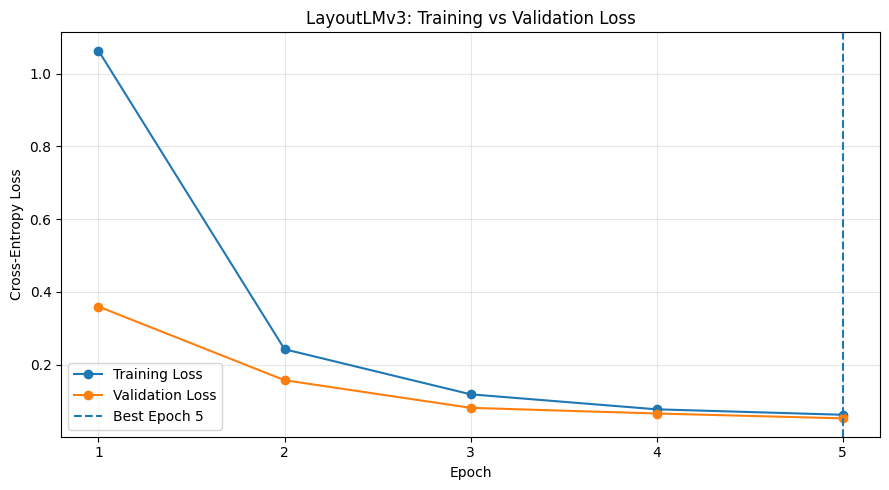

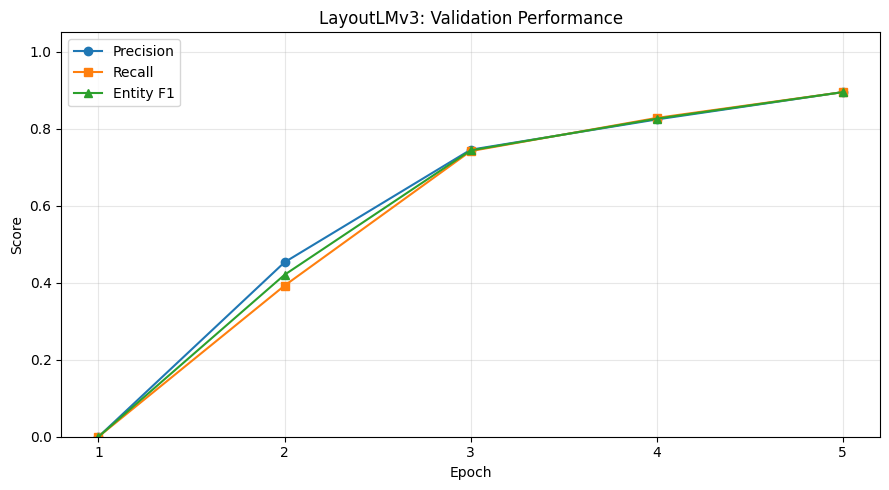


FINAL TRAINING SUMMARY
Model: microsoft/layoutlmv3-base
Epochs Completed: 5
Best Epoch: 5
Best Validation F1: 0.8947
Best Validation Loss: 0.05266
Total Training Time: 10.43 minutes
Total Optimizer Updates: 410

Best model restored in memory.
Held-out test dataset has NOT been evaluated.

Training completed successfully!


In [19]:

# ============================================================
# PROJECT 9: LAYOUTLMv3 FULL FIXED TRAINING CELL
#
# - Fixes CUDA / CUDA:0 device mismatch
# - No seqeval dependency
# - Mixed precision (FP16/BF16)
# - Token-weighted gradient accumulation
# - Gradient clipping and LR scheduler
# - Page-aware validation
# - Strict BIO entity-level F1
# - Early stopping and best model restoration
# - Training curves
#
# Requires existing Dataset/DataLoader and Model setup.
# Does not create output files.
# ============================================================

import math
import time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from tqdm.auto import tqdm
from IPython.display import display
from torch.utils.data import SequentialSampler


# ============================================================
# 1. PREREQUISITES & DEVICE FIX
# ============================================================

required = [
    "model",
    "optimizer",
    "scheduler",
    "train_loader",
    "val_loader",
    "processor"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Dataset and Model Initialization cells first. "
        f"Missing: {missing}"
    )

# FIX: Use the actual device occupied by model parameters.
model_device = next(model.parameters()).device

if model_device.type == "cuda":
    device = torch.device(
        f"cuda:{model_device.index}"
    )

elif model_device.type == "cpu":
    device = torch.device("cpu")

else:
    raise RuntimeError(
        f"Unsupported model device: {model_device}"
    )

if torch.cuda.is_available() and device.type != "cuda":
    raise RuntimeError(
        "GPU is available but model is on CPU. "
        "Rerun Model Initialization on GPU."
    )

if device.type != "cuda":
    raise RuntimeError(
        "Enable GPU in Kaggle Settings, then rerun "
        "Model Initialization and this cell."
    )

# Verify optimizer references the current model parameters.
model_param_ids = {
    id(p) for p in model.parameters()
    if p.requires_grad
}

optimizer_param_ids = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

if model_param_ids != optimizer_param_ids:
    raise RuntimeError(
        "Optimizer parameters do not match the model. "
        "Rerun Model Initialization."
    )

if not isinstance(val_loader.sampler, SequentialSampler):
    raise RuntimeError(
        "Validation DataLoader must have shuffle=False."
    )

if not processor.tokenizer.is_fast:
    raise RuntimeError(
        "A fast tokenizer is required for word_ids() "
        "during page-level evaluation."
    )


# ============================================================
# 2. TRAINING CONFIGURATION
# ============================================================

NUM_EPOCHS = 5
GRAD_ACCUM_STEPS = 2

PATIENCE = 3
MIN_DELTA = 1e-4
MAX_GRAD_NORM = 1.0

NUM_LABELS = model.config.num_labels

id2label = {
    int(k): v
    for k, v in model.config.id2label.items()
}

assert NUM_LABELS == 23
assert id2label[0] == "O"

AMP_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

USE_SCALER = AMP_DTYPE == torch.float16

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_SCALER
)

# Sum loss first; divide gradients by supervised token
# count at the optimizer update.
criterion = torch.nn.CrossEntropyLoss(
    ignore_index=-100,
    reduction="sum"
)

print("=" * 65)
print("TRAINING CONFIGURATION")
print("=" * 65)

print("Configured Device:", device)
print("Actual Model Device:", model_device)
print("GPU:", torch.cuda.get_device_name(device))
print("AMP Precision:", AMP_DTYPE)
print("Training Windows:", len(train_loader.dataset))
print("Validation Windows:", len(val_loader.dataset))
print("Epochs:", NUM_EPOCHS)
print("Gradient Accumulation:", GRAD_ACCUM_STEPS)
print("Number of Classes:", NUM_LABELS)


# ============================================================
# 3. HELPER: MOVE BATCH TO DEVICE
# ============================================================

def move_batch(batch):

    return {
        key: value.to(
            device,
            non_blocking=True
        )
        for key, value in batch.items()
    }


# ============================================================
# 4. HELPER: FORWARD PASS & LOSS
# ============================================================

def loss_and_logits(batch):

    with torch.autocast(
        device_type="cuda",
        dtype=AMP_DTYPE
    ):

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            bbox=batch["bbox"],
            pixel_values=batch["pixel_values"]
        )

        logits = outputs.logits

        loss_sum = criterion(
            logits.float().reshape(-1, NUM_LABELS),
            batch["labels"].reshape(-1)
        )

    return loss_sum, logits


# ============================================================
# 5. HELPER: OPTIMIZER UPDATE
# ============================================================

def update_optimizer(supervised_count):

    if supervised_count == 0:
        optimizer.zero_grad(set_to_none=True)
        return False

    # Unscale AMP gradients before modifying/clipping them.
    if USE_SCALER:
        scaler.unscale_(optimizer)

    # Convert accumulated sum-loss gradients into the
    # mean gradient over all supervised tokens.
    for parameter in model.parameters():

        if parameter.grad is not None:
            parameter.grad.div_(supervised_count)

    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        MAX_GRAD_NORM
    )

    if (
        not torch.isfinite(grad_norm).item()
        and not USE_SCALER
    ):
        raise RuntimeError(
            "Non-finite gradients detected."
        )

    if USE_SCALER:

        previous_scale = scaler.get_scale()

        scaler.step(optimizer)
        scaler.update()

        updated = (
            scaler.get_scale() >= previous_scale
        )

    else:

        optimizer.step()
        updated = True

    # Only advance scheduler after an actual optimizer step.
    if updated:
        scheduler.step()

    optimizer.zero_grad(set_to_none=True)

    return updated


# ============================================================
# 6. TRAIN ONE EPOCH
# ============================================================

def train_epoch(epoch):

    model.train()
    optimizer.zero_grad(set_to_none=True)

    total_loss = 0.0
    total_tokens = 0

    accumulation_tokens = 0
    update_count = 0

    num_batches = len(train_loader)

    progress = tqdm(
        enumerate(train_loader, start=1),
        total=num_batches,
        desc=f"Epoch {epoch}/{NUM_EPOCHS} - Train"
    )

    for step, cpu_batch in progress:

        batch = move_batch(cpu_batch)

        supervised_count = int(
            (batch["labels"] != -100).sum().item()
        )

        loss_sum, logits = loss_and_logits(batch)

        if not torch.isfinite(loss_sum).item():
            raise RuntimeError(
                f"Non-finite training loss at batch {step}"
            )

        # Backpropagation
        if USE_SCALER:
            scaler.scale(loss_sum).backward()
        else:
            loss_sum.backward()

        total_loss += float(
            loss_sum.detach().item()
        )

        total_tokens += supervised_count
        accumulation_tokens += supervised_count

        # Gradient accumulation boundary
        should_update = (
            step % GRAD_ACCUM_STEPS == 0
            or step == num_batches
        )

        if should_update:

            updated = update_optimizer(
                accumulation_tokens
            )

            update_count += int(updated)
            accumulation_tokens = 0

        running_loss = (
            total_loss / max(1, total_tokens)
        )

        progress.set_postfix({
            "loss": f"{running_loss:.4f}",
            "lr": (
                f"{optimizer.param_groups[0]['lr']:.2e}"
            )
        })

        del batch, loss_sum, logits

    return {
        "loss": total_loss / max(1, total_tokens),
        "updates": update_count,
        "tokens": total_tokens
    }


# ============================================================
# 7. HELPER: STRICT BIO ENTITY EXTRACTION
# ============================================================

def strict_spans(tags):

    entities = set()

    active_type = None
    start = None

    # Append O to close any final entity.
    for index, tag in enumerate(list(tags) + ["O"]):

        if tag.startswith("B-"):

            if active_type is not None:
                entities.add(
                    (start, index, active_type)
                )

            active_type = tag[2:]
            start = index

        elif (
            tag.startswith("I-")
            and active_type == tag[2:]
        ):
            continue

        else:

            if active_type is not None:
                entities.add(
                    (start, index, active_type)
                )

            active_type = None
            start = None

    return entities


# ============================================================
# 8. HELPER: PAGE-LEVEL ENTITY METRICS
# ============================================================

def score_pages(page_predictions):

    true_positive = 0
    total_true = 0
    total_predicted = 0

    for page_key, position_map in page_predictions.items():

        positions = sorted(position_map)

        if not positions:
            continue

        segments = []

        true_tags = []
        predicted_tags = []

        previous_position = None

        for position in positions:

            # Split sequences at ignored word gaps.
            if (
                previous_position is not None
                and position != previous_position + 1
            ):
                segments.append(
                    (true_tags, predicted_tags)
                )

                true_tags = []
                predicted_tags = []

            true_id, predicted_id = (
                position_map[position]
            )

            true_tags.append(id2label[true_id])

            predicted_tags.append(
                id2label[predicted_id]
            )

            previous_position = position

        segments.append(
            (true_tags, predicted_tags)
        )

        for gold_sequence, pred_sequence in segments:

            gold_entities = strict_spans(
                gold_sequence
            )

            pred_entities = strict_spans(
                pred_sequence
            )

            true_positive += len(
                gold_entities & pred_entities
            )

            total_true += len(gold_entities)
            total_predicted += len(pred_entities)

    precision = (
        true_positive / total_predicted
        if total_predicted else 0.0
    )

    recall = (
        true_positive / total_true
        if total_true else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "true_entities": total_true,
        "predicted_entities": total_predicted
    }


# ============================================================
# 9. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def validate():

    model.eval()

    total_loss = 0.0
    supervised_tokens = 0

    page_predictions = defaultdict(dict)

    offset = 0

    progress = tqdm(
        val_loader,
        desc="Validation",
        leave=False
    )

    for cpu_batch in progress:

        batch = move_batch(cpu_batch)

        loss_sum, logits = loss_and_logits(batch)

        total_loss += float(loss_sum.item())

        gold_labels = batch["labels"].cpu()

        predictions = (
            logits.argmax(dim=-1).cpu()
        )

        supervised_tokens += int(
            (gold_labels != -100).sum()
        )

        batch_size = gold_labels.size(0)

        records = val_loader.dataset.records[
            offset:offset + batch_size
        ]

        offset += batch_size

        for row, record in enumerate(records):

            # Recreate token-to-OCR-word alignment.
            tokenized = processor.tokenizer(
                record["words"],
                boxes=record["boxes"],
                word_labels=record["label_ids"],
                padding="max_length",
                truncation=False,
                max_length=gold_labels.size(1)
            )

            if tokenized["input_ids"] != (
                batch["input_ids"][row].cpu().tolist()
            ):
                raise RuntimeError(
                    "Tokenizer encoding differs from "
                    "DataLoader encoding."
                )

            word_ids = tokenized.word_ids()

            page_key = (
                record["invoice_id"],
                int(record["page_index"])
            )

            supervised_positions = (
                (gold_labels[row] != -100)
                .nonzero(as_tuple=True)[0]
                .tolist()
            )

            for token_position in supervised_positions:

                local_word_idx = word_ids[
                    token_position
                ]

                if local_word_idx is None:
                    raise RuntimeError(
                        "Supervised token has no OCR word."
                    )

                expected_label = record[
                    "label_ids"
                ][local_word_idx]

                true_label = int(
                    gold_labels[row, token_position]
                )

                if expected_label != true_label:
                    raise RuntimeError(
                        "Label alignment mismatch."
                    )

                # Reconstruct original page word index
                global_word_idx = (
                    record["word_start"]
                    + local_word_idx
                )

                if global_word_idx in page_predictions[
                    page_key
                ]:
                    raise RuntimeError(
                        "Duplicate supervised OCR word "
                        "during validation."
                    )

                predicted_label = int(
                    predictions[row, token_position]
                )

                page_predictions[page_key][
                    global_word_idx
                ] = (
                    true_label,
                    predicted_label
                )

        del batch, loss_sum, logits

    assert offset == len(val_loader.dataset)

    metrics = score_pages(
        page_predictions
    )

    metrics["loss"] = (
        total_loss / max(1, supervised_tokens)
    )

    metrics["supervised_tokens"] = (
        supervised_tokens
    )

    return metrics


# ============================================================
# 10. TRAINING STATE
# ============================================================

training_history = []

best_f1 = -1.0
best_loss = float("inf")
best_epoch = 0

best_state = None
epochs_without_improvement = 0

training_start = time.perf_counter()


# ============================================================
# 11. COMPLETE TRAINING LOOP
# ============================================================

print("\n" + "=" * 65)
print("STARTING LAYOUTLMv3 TRAINING")
print("=" * 65)

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.perf_counter()

    # A. Training
    train_stats = train_epoch(epoch)

    # B. Validation
    val_stats = validate()

    current_f1 = val_stats["f1"]
    current_loss = val_stats["loss"]

    if not (
        math.isfinite(current_f1)
        and math.isfinite(current_loss)
    ):
        raise RuntimeError(
            "Non-finite validation metrics."
        )

    # C. Best-model selection
    improved = (
        current_f1 > best_f1 + MIN_DELTA
        or (
            abs(current_f1 - best_f1) <= MIN_DELTA
            and current_loss < best_loss - MIN_DELTA
        )
    )

    if improved:

        best_f1 = current_f1
        best_loss = current_loss
        best_epoch = epoch

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        epochs_without_improvement = 0

        status = "BEST MODEL UPDATED"

    else:

        epochs_without_improvement += 1

        status = (
            f"No improvement "
            f"({epochs_without_improvement}/{PATIENCE})"
        )

    epoch_time = (
        time.perf_counter() - epoch_start
    )

    # D. Save epoch statistics in memory
    training_history.append({
        "Epoch": epoch,
        "Train Loss": train_stats["loss"],
        "Val Loss": current_loss,
        "Val Precision": val_stats["precision"],
        "Val Recall": val_stats["recall"],
        "Val F1": current_f1,
        "Optimizer Updates": train_stats["updates"],
        "Time (s)": round(epoch_time, 1)
    })

    # E. Print results
    print("\n" + "=" * 65)
    print(f"EPOCH {epoch}/{NUM_EPOCHS} RESULTS")
    print("=" * 65)

    print(
        f"Training Loss   : {train_stats['loss']:.5f}"
    )

    print(
        f"Validation Loss : {current_loss:.5f}"
    )

    print(
        f"Val Precision   : {val_stats['precision']:.4f}"
    )

    print(
        f"Val Recall      : {val_stats['recall']:.4f}"
    )

    print(
        f"Val Entity F1   : {current_f1:.4f}"
    )

    print(
        f"Learning Rate   : "
        f"{optimizer.param_groups[0]['lr']:.8f}"
    )

    print(
        f"Optimizer Steps : {train_stats['updates']}"
    )

    print(
        f"Epoch Time      : {epoch_time:.1f}s"
    )

    print("Status:", status)

    # F. Early stopping
    if epochs_without_improvement >= PATIENCE:

        print("\nEARLY STOPPING TRIGGERED")
        break


# ============================================================
# 12. RESTORE BEST MODEL
# ============================================================

if best_state is None:
    raise RuntimeError(
        "Training finished without a valid best model."
    )

model.load_state_dict(best_state)
model.eval()

del best_state

print("\n" + "=" * 65)
print("BEST MODEL RESTORED")
print("=" * 65)

print("Best Epoch:", best_epoch)
print(f"Best Validation F1: {best_f1:.4f}")
print(f"Best Validation Loss: {best_loss:.5f}")


# ============================================================
# 13. DISPLAY TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    training_history
)

print("\n========== TRAINING HISTORY ==========")

display(
    history_df.round(4)
)


# ============================================================
# 14. TRAINING LOSS VISUALIZATION
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train Loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["Epoch"],
    history_df["Val Loss"],
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")

plt.title(
    "LayoutLMv3: Training vs Validation Loss"
)

plt.xticks(history_df["Epoch"])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 15. VALIDATION F1 VISUALIZATION
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Val Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    history_df["Epoch"],
    history_df["Val Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    history_df["Epoch"],
    history_df["Val F1"],
    marker="^",
    label="Entity F1"
)

plt.xlabel("Epoch")
plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.title(
    "LayoutLMv3: Validation Performance"
)

plt.xticks(history_df["Epoch"])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

total_time = (
    time.perf_counter() - training_start
)

print("\n" + "=" * 65)
print("FINAL TRAINING SUMMARY")
print("=" * 65)

print("Model:", MODEL_NAME)
print("Epochs Completed:", len(training_history))

print("Best Epoch:", best_epoch)
print(f"Best Validation F1: {best_f1:.4f}")
print(f"Best Validation Loss: {best_loss:.5f}")

print(
    f"Total Training Time: "
    f"{total_time / 60:.2f} minutes"
)

print(
    "Total Optimizer Updates:",
    sum(
        row["Optimizer Updates"]
        for row in training_history
    )
)

print(
    "\nBest model restored in memory."
)

print(
    "Held-out test dataset has NOT been evaluated."
)

print("\nTraining completed successfully!")


In [20]:

# ============================================================
# HELD-OUT TEST EVALUATION
# Uses trained LayoutLMv3 and existing test_loader
# No seqeval required
# ============================================================

import torch
import pandas as pd

from collections import defaultdict
from tqdm.auto import tqdm
from IPython.display import display
from torch.utils.data import SequentialSampler

required = [
    "model", "test_loader", "processor", "score_pages"
]

for name in required:
    if name not in globals():
        raise RuntimeError(f"Missing: {name}")

assert isinstance(
    test_loader.sampler, SequentialSampler
), "Test loader must use shuffle=False."

model.eval()
eval_device = next(model.parameters()).device

loss_fn = torch.nn.CrossEntropyLoss(
    ignore_index=-100,
    reduction="sum"
)

page_predictions = defaultdict(dict)

total_loss = 0.0
total_tokens = 0
offset = 0

print("=" * 60)
print("HELD-OUT TEST CONFIGURATION")
print("=" * 60)

print("Device:", eval_device)
print("Test invoices:", len(set(
    r["invoice_id"]
    for r in test_loader.dataset.records
)))
print("Test windows:", len(test_loader.dataset))
print("Test batches:", len(test_loader))


# ============================================================
# RUN TEST INFERENCE
# ============================================================

with torch.inference_mode():

    for batch in tqdm(
        test_loader,
        desc="Evaluating Test Set"
    ):

        batch_size = batch["input_ids"].size(0)

        records = test_loader.dataset.records[
            offset:offset + batch_size
        ]

        offset += batch_size

        inputs = {
            key: batch[key].to(eval_device)
            for key in (
                "input_ids",
                "attention_mask",
                "bbox",
                "pixel_values"
            )
        }

        outputs = model(**inputs)
        logits = outputs.logits.float()

        labels = batch["labels"]
        predictions = logits.argmax(dim=-1).cpu()

        count = int((labels != -100).sum())

        loss = loss_fn(
            logits.reshape(-1, model.config.num_labels),
            labels.to(eval_device).reshape(-1)
        )

        total_loss += loss.item()
        total_tokens += count

        # Reconstruct original OCR word positions
        for row, record in enumerate(records):

            encoding = processor.tokenizer(
                record["words"],
                boxes=record["boxes"],
                word_labels=record["label_ids"],
                truncation=False,
                padding="max_length",
                max_length=labels.size(1)
            )

            if encoding["input_ids"] != (
                batch["input_ids"][row].tolist()
            ):
                raise RuntimeError(
                    "Tokenizer/DataLoader mismatch"
                )

            word_ids = encoding.word_ids()

            page_key = (
                record["invoice_id"],
                record["page_index"]
            )

            for token_idx, true_id in enumerate(
                labels[row].tolist()
            ):

                if true_id == -100:
                    continue

                local_word = word_ids[token_idx]

                if local_word is None:
                    raise RuntimeError(
                        "Missing word alignment"
                    )

                if (
                    record["label_ids"][local_word]
                    != true_id
                ):
                    raise RuntimeError(
                        "Label alignment mismatch"
                    )

                global_word = (
                    record["word_start"]
                    + local_word
                )

                if global_word in page_predictions[page_key]:
                    raise RuntimeError(
                        "Duplicate supervised word"
                    )

                page_predictions[page_key][global_word] = (
                    int(true_id),
                    int(predictions[row, token_idx])
                )

assert offset == len(test_loader.dataset)


# ============================================================
# COMPUTE TEST METRICS
# ============================================================

test_metrics = score_pages(page_predictions)

test_metrics["loss"] = (
    total_loss / max(1, total_tokens)
)

print("\n" + "=" * 60)
print("FINAL HELD-OUT TEST RESULTS")
print("=" * 60)

print(f"Test Loss      : {test_metrics['loss']:.5f}")
print(f"Test Precision : {test_metrics['precision']:.4f}")
print(f"Test Recall    : {test_metrics['recall']:.4f}")
print(f"Test Entity F1 : {test_metrics['f1']:.4f}")

print("\nGround Truth Entities:",
      test_metrics["true_entities"])

print("Predicted Entities:",
      test_metrics["predicted_entities"])

print("\nValidation vs Test Comparison:")

display(pd.DataFrame([
    {
        "Dataset": "Validation",
        "Entity F1": best_f1
    },
    {
        "Dataset": "Test",
        "Entity F1": test_metrics["f1"]
    }
]))

print("\nHeld-out test evaluation completed!")


HELD-OUT TEST CONFIGURATION
Device: cuda:0
Test invoices: 19
Test windows: 33
Test batches: 17


Evaluating Test Set:   0%|          | 0/17 [00:00<?, ?it/s]


FINAL HELD-OUT TEST RESULTS
Test Loss      : 0.05500
Test Precision : 0.9426
Test Recall    : 0.9426
Test Entity F1 : 0.9426

Ground Truth Entities: 209
Predicted Entities: 209

Validation vs Test Comparison:


,Dataset,Entity F1
0,Validation,0.894737
1,Test,0.942584



Held-out test evaluation completed!


# architectural change

ERROR ANALYSIS CONFIGURATION
Entity Classes: 11
Evaluated Pages: 29
Evaluated Invoices: 19

PER-FIELD TEST PERFORMANCE


,Field,GT Count,TP,FP,FN,Precision,Recall,F1
0,CLIENT_NAME,19,14,2,5,0.8750,0.7368,0.8000
1,CLIENT_EMAIL,19,15,3,4,0.8333,0.7895,0.8108
2,SELLER_EMAIL,19,16,4,3,0.8000,0.8421,0.8205
3,SELLER_NAME,19,19,3,0,0.8636,1.0000,0.9268
4,DUE_DATE,19,19,0,0,1.0000,1.0000,1.0000
5,INVOICE_DATE,19,19,0,0,1.0000,1.0000,1.0000
6,INVOICE_NUMBER,19,19,0,0,1.0000,1.0000,1.0000
7,REFERENCE,19,19,0,0,1.0000,1.0000,1.0000
8,SUBTOTAL,19,19,0,0,1.0000,1.0000,1.0000
9,TAX,19,19,0,0,1.0000,1.0000,1.0000



OVERALL TEST METRICS
True Positives : 197
False Positives: 12
False Negatives: 12
Precision: 0.9426
Recall   : 0.9426
F1 Score : 0.9426
Previous Test F1: 0.9426

FALSE NEGATIVE ANALYSIS
Total unmatched GT entities: 12

Error type distribution:


,Count
Error Type,
WRONG_CLASS,10
MISSED_ENTITY,1
BOUNDARY_ERROR,1



Examples:


...

,Count
Error Type,
WRONG_CLASS,10
BOUNDARY_ERROR,1
EXTRA_PREDICTION,1



Examples:


,Invoice,Page,Predicted Field,Predicted Text,GT Field,GT Text,Error Type,OCR Context
6,sample_247_bedb57,1,CLIENT_EMAIL,kontakt@mueller-partner.de,SELLER_EMAIL,kontakt@mueller-partner.de,WRONG_CLASS,KONTAKT +49 30 1234567 E-MAIL kontakt@mueller-...
7,sample_291_89d1eb,1,CLIENT_EMAIL,kontakt@muellerpartner.de,SELLER_EMAIL,kontakt@muellerpartner.de,WRONG_CLASS,KONTAKT Herr Klaus Müller E-MAIL kontakt@muell...
10,sample_725_ad6e15,1,CLIENT_EMAIL,kontakt@techsolutions.sk,SELLER_EMAIL,kontakt@techsolutions.sk,WRONG_CLASS,+421 905 123 456 EMAIL kontakt@techsolutions.s...
5,sample_234_bc758f,1,CLIENT_NAME,Schneider,CLIENT_NAME,Schneider AG,BOUNDARY_ERROR,"10117 Berlin, Deutschland Kunde NAME Schneider..."
9,sample_664_aff001,1,CLIENT_NAME,Slovenská,None,None,EXTRA_PREDICTION,o platbe Platobné údaje BANKA Slovenská sporit...
0,sample_010_bd1091,1,SELLER_EMAIL,contact@greenfieldent.com,CLIENT_EMAIL,contact@greenfieldent.com,WRONG_CLASS,+1 555 987 6543 EMAIL contact@greenfieldent.co...
1,sample_016_027736,1,SELLER_EMAIL,accounts@globex.com,CLIENT_EMAIL,accounts@globex.com,WRONG_CLASS,SELLER EMAIL billing@acmecorp.com CLIENT EMAIL...
2,sample_039_857f2f,1,SELLER_EMAIL,accounts@greenfield.com,CLIENT_EMAIL,accounts@greenfield.com,WRONG_CLASS,+1 555 987 6543 EMAIL accounts@greenfield.com ...
11,sample_725_ad6e15,2,SELLER_EMAIL,info@stavex.sk,CLIENT_EMAIL,info@stavex.sk,WRONG_CLASS,+421 917 654 321 EMAIL info@stavex.sk ADRESA H...
3,sample_073_ea3f2c,1,SELLER_NAME,Global Enterprises Ltd.,CLIENT_NAME,Global Enterprises Ltd.,WRONG_CLASS,USA Client Information CLIENT NAME Global Ente...



INVOICE-LEVEL EXACT MATCH
Total Test Invoices: 19
Fully Correct Invoices: 8
Invoice Exact-Match Rate: 42.11%


,Invoice,GT Entities,Predicted Entities,Correct Entities,All Evaluated Entities Correct
0,sample_725_ad6e15,11,11,9,False
1,sample_010_bd1091,11,11,10,False
2,sample_016_027736,11,11,10,False
3,sample_039_857f2f,11,11,10,False
4,sample_073_ea3f2c,11,11,10,False
5,sample_116_fdd9fa,11,10,10,False
6,sample_139_6f7533,11,11,10,False
7,sample_234_bc758f,11,11,10,False
8,sample_247_bedb57,11,11,10,False
9,sample_291_89d1eb,11,11,10,False


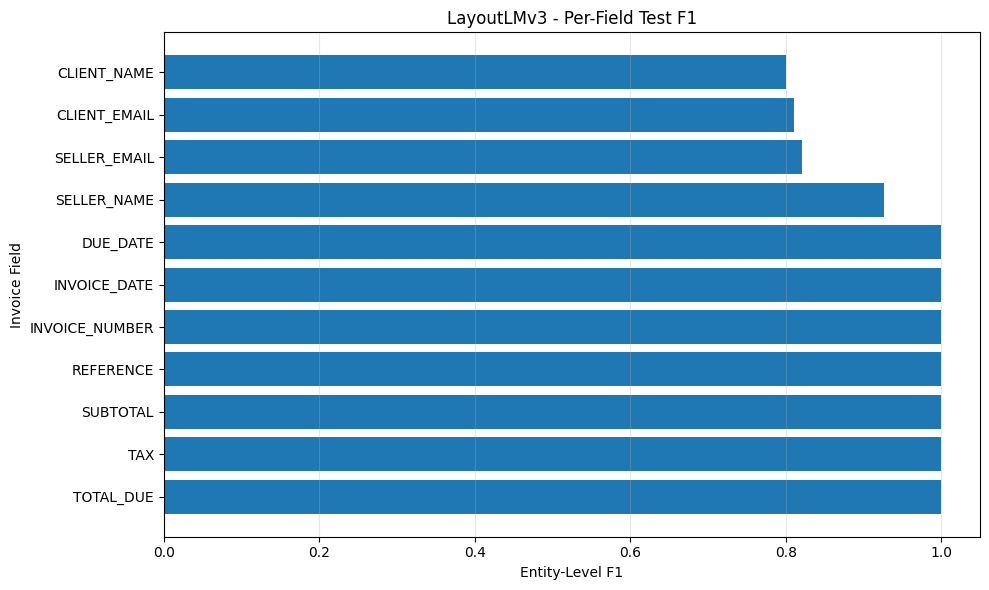

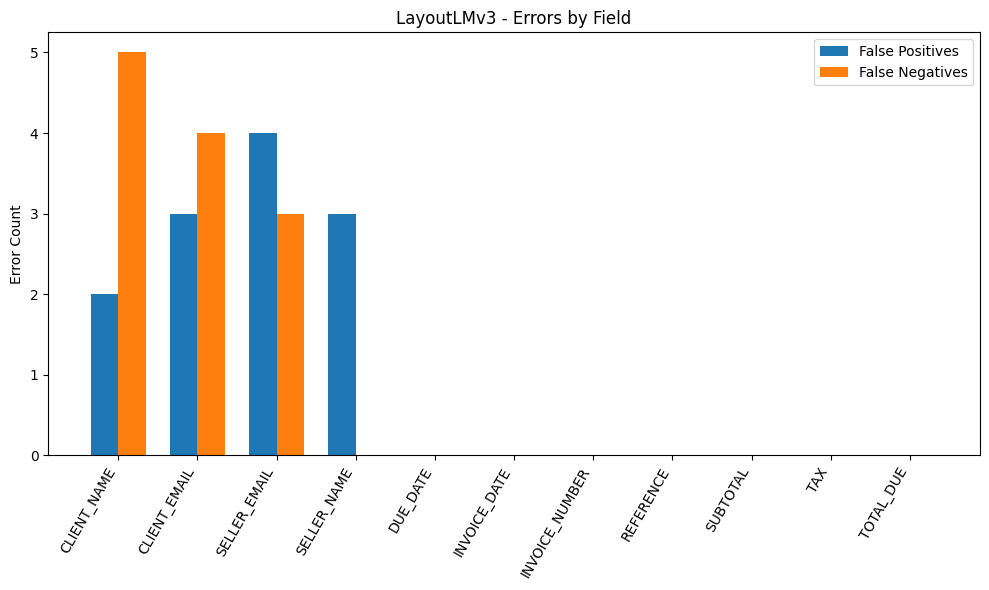


VISUAL ERROR INSPECTION


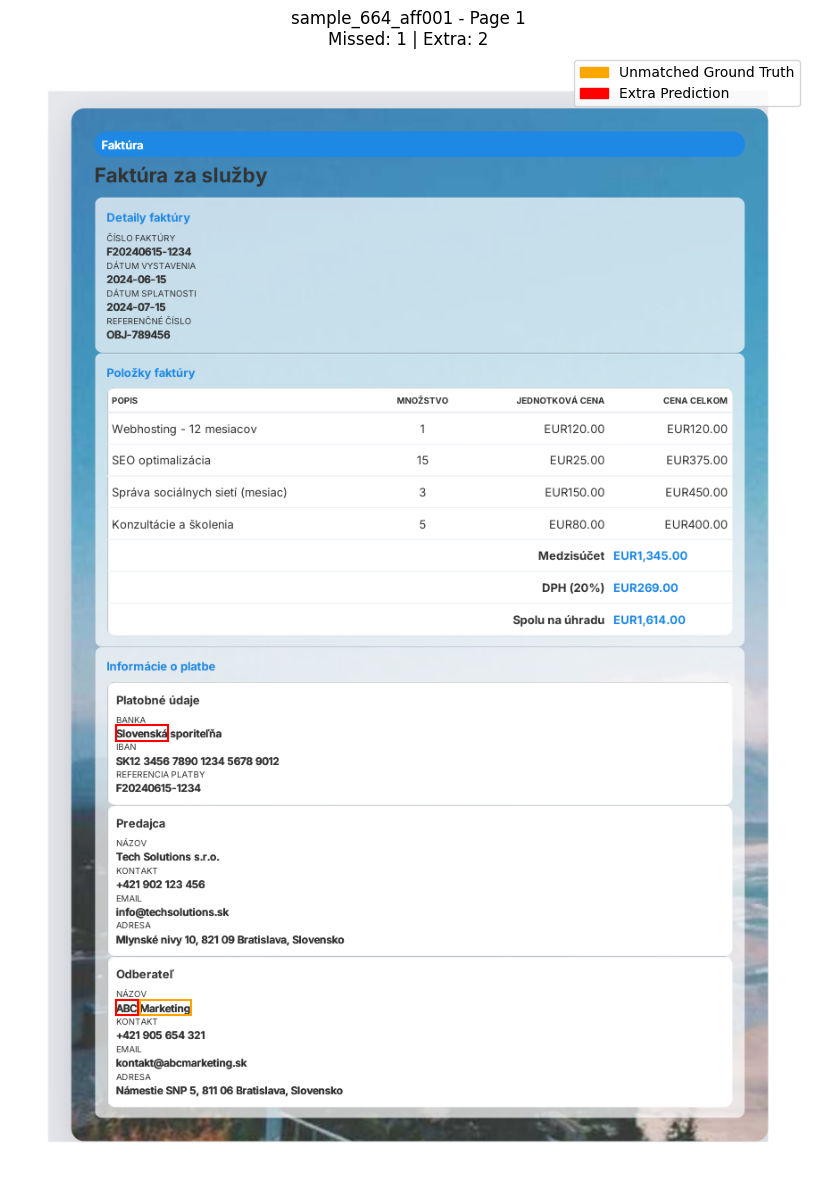

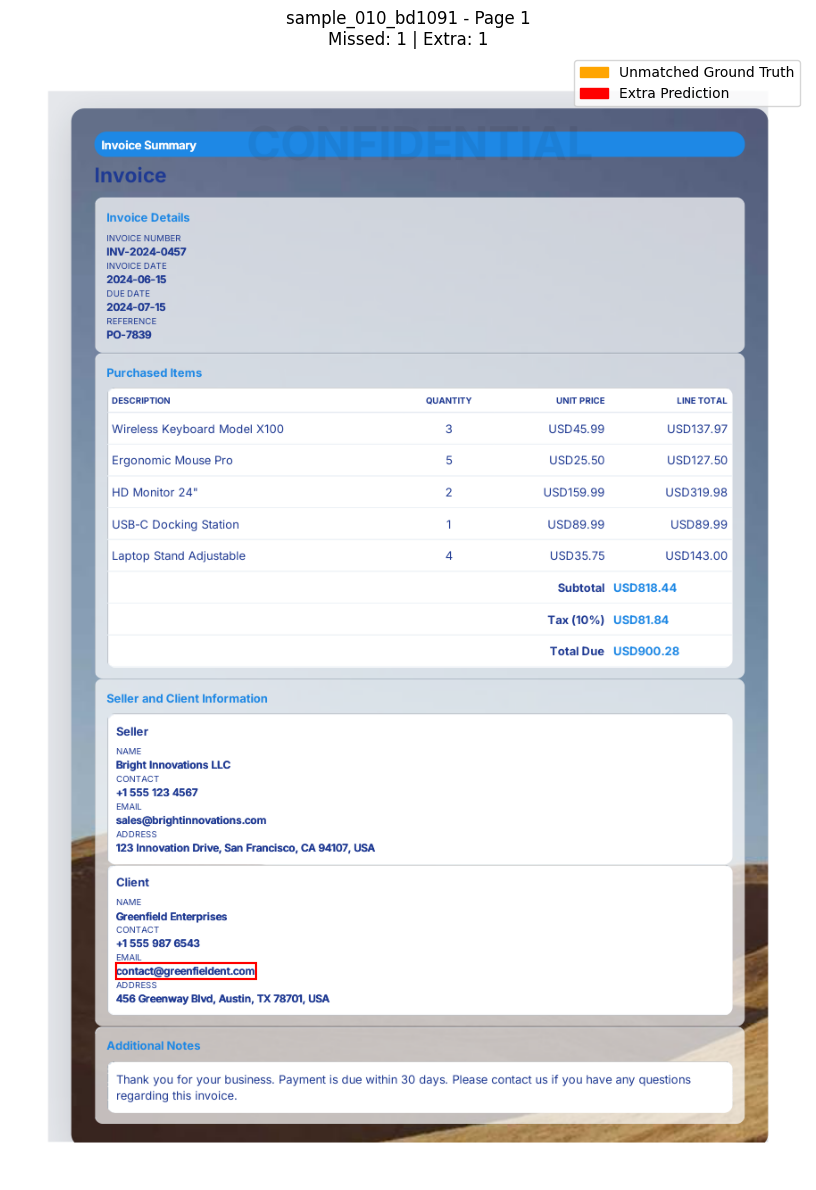


FINAL ERROR ANALYSIS SUMMARY
Test Invoices: 19
Ground Truth Entities: 209
Predicted Entities: 209
Correct Entity Matches: 197
False Positives: 12
False Negatives: 12

Micro Entity F1: 0.9426
Invoice Exact-Match Rate: 42.11%

Worst Performing Fields:


,Field,GT Count,FP,FN,F1
0,CLIENT_NAME,19,2,5,0.8000
1,CLIENT_EMAIL,19,3,4,0.8108
2,SELLER_EMAIL,19,4,3,0.8205
3,SELLER_NAME,19,3,0,0.9268
4,DUE_DATE,19,0,0,1.0000



Error analysis completed successfully!


In [22]:

# ============================================================
# PROJECT 9: PER-FIELD ERROR ANALYSIS
# ============================================================
# Uses existing test-set predictions.
#
# Includes:
# 1. Per-field Precision / Recall / F1
# 2. False Positive / False Negative analysis
# 3. Error categorization
# 4. Invoice-level exact match
# 5. Per-field F1 visualization
# 6. Visualizing errors on original PDF pages
#
# No retraining, no inference, no output files.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pymupdf

from PIL import Image
from collections import Counter, defaultdict
from matplotlib.patches import Rectangle, Patch
from IPython.display import display


# ============================================================
# 1. VERIFY REQUIRED OBJECTS
# ============================================================

required = [
    "page_predictions",
    "page_samples",
    "model"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Run the held-out test evaluation cell first."
    )

if not page_predictions:
    raise RuntimeError("page_predictions is empty.")

id_to_label = {
    int(k): v
    for k, v in model.config.id2label.items()
}

ENTITY_TYPES = sorted({
    label[2:]
    for label in id_to_label.values()
    if label.startswith("B-")
})

# Original OCR words and normalized boxes
page_lookup = {
    (p["invoice_id"], p["page_index"]): p
    for p in page_samples
}

print("=" * 65)
print("ERROR ANALYSIS CONFIGURATION")
print("=" * 65)

print("Entity Classes:", len(ENTITY_TYPES))
print("Evaluated Pages:", len(page_predictions))
print("Evaluated Invoices:", len(set(
    key[0] for key in page_predictions
)))


# ============================================================
# 2. STRICT BIO SPAN EXTRACTION
# ============================================================

def extract_spans(position_map, label_index):
    """
    position_map:
        {global_word_position: (true_id, predicted_id)}

    label_index:
        0 = Ground Truth
        1 = Prediction

    Returns:
        set of (entity_type, start, end)

    End position is exclusive.
    Invalid orphan I-tags are not counted as entities.
    """

    spans = set()

    active_type = None
    start = None
    previous = None

    for position in sorted(position_map):

        # Close entity when ignored-word gap exists
        if (
            previous is not None
            and position != previous + 1
        ):
            if active_type is not None:
                spans.add((
                    active_type, start, previous + 1
                ))

            active_type = None
            start = None

        label_id = position_map[position][label_index]
        tag = id_to_label[int(label_id)]

        if tag.startswith("B-"):

            if active_type is not None:
                spans.add((
                    active_type, start, position
                ))

            active_type = tag[2:]
            start = position

        elif tag.startswith("I-"):

            if active_type != tag[2:]:
                # Invalid I-tag: close old entity,
                # but do not start a new entity.
                if active_type is not None:
                    spans.add((
                        active_type, start, position
                    ))

                active_type = None
                start = None

        else:
            # O label closes any active entity
            if active_type is not None:
                spans.add((
                    active_type, start, position
                ))

            active_type = None
            start = None

        previous = position

    if active_type is not None:
        spans.add((
            active_type, start, previous + 1
        ))

    return spans


# ============================================================
# 3. TEXT & CONTEXT HELPERS
# ============================================================

def get_span_text(page, span):
    entity, start, end = span

    return " ".join(
        page["words"][start:end]
    )


def get_context(page, span, radius=5):
    entity, start, end = span
    words = page["words"]

    return " ".join(
        words[
            max(0, start - radius):
            min(len(words), end + radius)
        ]
    )


def find_overlapping_spans(span, candidates):
    _, start, end = span

    overlapping = [
        candidate
        for candidate in candidates
        if candidate[1] < end
        and start < candidate[2]
    ]

    return sorted(
        overlapping,
        key=lambda x: (
            -(
                min(end, x[2])
                - max(start, x[1])
            ),
            x[1]
        )
    )


# ============================================================
# 4. COMPARE TRUE VS PREDICTED ENTITIES
# ============================================================

field_counts = {
    entity: Counter()
    for entity in ENTITY_TYPES
}

invoice_results = defaultdict(
    lambda: {
        "ground_truth": set(),
        "predictions": set()
    }
)

false_negatives = []
false_positives = []

page_errors = {}

for page_key, position_map in page_predictions.items():

    if page_key not in page_lookup:
        raise RuntimeError(
            f"Page not found in original dataset: {page_key}"
        )

    invoice_id, page_index = page_key
    page = page_lookup[page_key]

    gt_spans = extract_spans(
        position_map, label_index=0
    )

    pred_spans = extract_spans(
        position_map, label_index=1
    )

    correct = gt_spans & pred_spans
    missed = gt_spans - pred_spans
    extra = pred_spans - gt_spans

    page_errors[page_key] = {
        "missed": missed,
        "extra": extra
    }

    # ----------------------------------------
    # True positives
    # ----------------------------------------

    for span in correct:
        field_counts[span[0]]["TP"] += 1

    # ----------------------------------------
    # False negatives
    # ----------------------------------------

    for span in missed:

        field_counts[span[0]]["FN"] += 1

        overlapping = find_overlapping_spans(
            span, pred_spans
        )

        if not overlapping:
            reason = "MISSED_ENTITY"
            competing = None

        else:
            competing = overlapping[0]

            if competing[0] == span[0]:
                reason = "BOUNDARY_ERROR"
            else:
                reason = "WRONG_CLASS"

        false_negatives.append({
            "Invoice": invoice_id,
            "Page": page_index + 1,
            "GT Field": span[0],
            "GT Text": get_span_text(page, span),
            "Predicted Field": (
                competing[0]
                if competing else None
            ),
            "Predicted Text": (
                get_span_text(page, competing)
                if competing else None
            ),
            "Error Type": reason,
            "OCR Context": get_context(page, span)
        })

    # ----------------------------------------
    # False positives
    # ----------------------------------------

    for span in extra:

        field_counts[span[0]]["FP"] += 1

        overlapping = find_overlapping_spans(
            span, gt_spans
        )

        if not overlapping:
            reason = "EXTRA_PREDICTION"
            competing = None

        else:
            competing = overlapping[0]

            if competing[0] == span[0]:
                reason = "BOUNDARY_ERROR"
            else:
                reason = "WRONG_CLASS"

        false_positives.append({
            "Invoice": invoice_id,
            "Page": page_index + 1,
            "Predicted Field": span[0],
            "Predicted Text": get_span_text(page, span),
            "GT Field": (
                competing[0]
                if competing else None
            ),
            "GT Text": (
                get_span_text(page, competing)
                if competing else None
            ),
            "Error Type": reason,
            "OCR Context": get_context(page, span)
        })

    # ----------------------------------------
    # Invoice-level collection
    # ----------------------------------------

    invoice_results[invoice_id][
        "ground_truth"
    ].update(
        (page_index, *span)
        for span in gt_spans
    )

    invoice_results[invoice_id][
        "predictions"
    ].update(
        (page_index, *span)
        for span in pred_spans
    )


# ============================================================
# 5. PER-FIELD PRECISION, RECALL, F1
# ============================================================

field_rows = []

for entity in ENTITY_TYPES:

    tp = field_counts[entity]["TP"]
    fp = field_counts[entity]["FP"]
    fn = field_counts[entity]["FN"]

    precision = (
        tp / (tp + fp)
        if tp + fp > 0 else 0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0 else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    field_rows.append({
        "Field": entity,
        "GT Count": tp + fn,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

field_df = pd.DataFrame(field_rows)

field_df = field_df.sort_values(
    ["F1", "Field"]
).reset_index(drop=True)

print("\n" + "=" * 65)
print("PER-FIELD TEST PERFORMANCE")
print("=" * 65)

display(
    field_df.round(4)
)


# ============================================================
# 6. VERIFY OVERALL TEST METRICS
# ============================================================

TP = int(field_df["TP"].sum())
FP = int(field_df["FP"].sum())
FN = int(field_df["FN"].sum())

micro_precision = TP / (TP + FP) if TP + FP else 0
micro_recall = TP / (TP + FN) if TP + FN else 0

micro_f1 = (
    2 * micro_precision * micro_recall
    / (micro_precision + micro_recall)
    if micro_precision + micro_recall else 0
)

print("\n" + "=" * 65)
print("OVERALL TEST METRICS")
print("=" * 65)

print("True Positives :", TP)
print("False Positives:", FP)
print("False Negatives:", FN)

print(f"Precision: {micro_precision:.4f}")
print(f"Recall   : {micro_recall:.4f}")
print(f"F1 Score : {micro_f1:.4f}")

if "test_metrics" in globals():
    print(
        "Previous Test F1:",
        round(test_metrics["f1"], 4)
    )

    if abs(micro_f1 - test_metrics["f1"]) > 1e-5:
        print(
            "WARNING: F1 differs from earlier test. "
            "Verify that page_predictions belongs "
            "to the same test run."
        )


# ============================================================
# 7. FALSE NEGATIVE ANALYSIS
# ============================================================

fn_df = pd.DataFrame(false_negatives)

print("\n" + "=" * 65)
print("FALSE NEGATIVE ANALYSIS")
print("=" * 65)

print("Total unmatched GT entities:", len(fn_df))

if not fn_df.empty:

    print("\nError type distribution:")
    display(
        fn_df["Error Type"]
        .value_counts()
        .to_frame("Count")
    )

    print("\nExamples:")
    display(
        fn_df.sort_values(
            ["GT Field", "Invoice"]
        ).head(25)
    )

else:
    print("No false negatives found.")


# ============================================================
# 8. FALSE POSITIVE ANALYSIS
# ============================================================

fp_df = pd.DataFrame(false_positives)

print("\n" + "=" * 65)
print("FALSE POSITIVE ANALYSIS")
print("=" * 65)

print("Total extra predicted entities:", len(fp_df))

if not fp_df.empty:

    print("\nError type distribution:")
    display(
        fp_df["Error Type"]
        .value_counts()
        .to_frame("Count")
    )

    print("\nExamples:")
    display(
        fp_df.sort_values(
            ["Predicted Field", "Invoice"]
        ).head(25)
    )

else:
    print("No false positives found.")


# ============================================================
# 9. INVOICE-LEVEL EXACT MATCH
# ============================================================

invoice_rows = []

for invoice_id, result in invoice_results.items():

    gt = result["ground_truth"]
    pred = result["predictions"]

    invoice_rows.append({
        "Invoice": invoice_id,
        "GT Entities": len(gt),
        "Predicted Entities": len(pred),
        "Correct Entities": len(gt & pred),
        "All Evaluated Entities Correct": gt == pred
    })

invoice_df = pd.DataFrame(invoice_rows)

fully_correct = int(
    invoice_df[
        "All Evaluated Entities Correct"
    ].sum()
)

invoice_accuracy = (
    100 * fully_correct / len(invoice_df)
    if len(invoice_df) else 0
)

print("\n" + "=" * 65)
print("INVOICE-LEVEL EXACT MATCH")
print("=" * 65)

print("Total Test Invoices:", len(invoice_df))
print("Fully Correct Invoices:", fully_correct)

print(
    f"Invoice Exact-Match Rate: "
    f"{invoice_accuracy:.2f}%"
)

display(
    invoice_df.sort_values(
        ["All Evaluated Entities Correct",
         "Correct Entities"]
    ).reset_index(drop=True)
)


# ============================================================
# 10. VISUALIZE PER-FIELD F1
# ============================================================

plt.figure(figsize=(10, 6))

plt.barh(
    field_df["Field"],
    field_df["F1"]
)

plt.xlabel("Entity-Level F1")
plt.ylabel("Invoice Field")
plt.title("LayoutLMv3 - Per-Field Test F1")

plt.xlim(0, 1.05)
plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 11. VISUALIZE ERROR COUNTS BY FIELD
# ============================================================

plt.figure(figsize=(10, 6))

x = np.arange(len(field_df))
width = 0.35

plt.bar(
    x - width / 2,
    field_df["FP"],
    width,
    label="False Positives"
)

plt.bar(
    x + width / 2,
    field_df["FN"],
    width,
    label="False Negatives"
)

plt.xticks(
    x,
    field_df["Field"],
    rotation=60,
    ha="right"
)

plt.ylabel("Error Count")
plt.title("LayoutLMv3 - Errors by Field")

plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 12. VISUALIZE ERRORS ON INVOICE IMAGES
# ============================================================

# Select pages having the most unmatched entity spans

error_page_keys = sorted(
    [
        key for key, errors in page_errors.items()
        if errors["missed"] or errors["extra"]
    ],
    key=lambda key: (
        len(page_errors[key]["missed"])
        + len(page_errors[key]["extra"])
    ),
    reverse=True
)

print("\n" + "=" * 65)
print("VISUAL ERROR INSPECTION")
print("=" * 65)

for page_key in error_page_keys[:2]:

    page = page_lookup[page_key]
    errors = page_errors[page_key]

    with pymupdf.open(page["pdf"]) as doc:

        pdf_page = doc[page["page_index"]]

        pix = pdf_page.get_pixmap(
            matrix=pymupdf.Matrix(1.5, 1.5),
            alpha=False
        )

        image = Image.frombytes(
            "RGB",
            (pix.width, pix.height),
            pix.samples
        )

    fig, ax = plt.subplots(figsize=(10, 12))

    ax.imshow(image)

    # Missed GT entities: orange
    # Extra predicted entities: red

    for spans, color in [
        (errors["missed"], "orange"),
        (errors["extra"], "red")
    ]:

        for entity, start, end in spans:

            for box in page["boxes"][start:end]:

                x0, y0, x1, y1 = box

                ax.add_patch(Rectangle(
                    (
                        x0 * image.width / 1000,
                        y0 * image.height / 1000
                    ),
                    (x1 - x0) * image.width / 1000,
                    (y1 - y0) * image.height / 1000,
                    fill=False,
                    edgecolor=color,
                    linewidth=1.5
                ))

    ax.set_title(
        f"{page_key[0]} - Page {page_key[1] + 1}\n"
        f"Missed: {len(errors['missed'])} | "
        f"Extra: {len(errors['extra'])}"
    )

    ax.legend(
        handles=[
            Patch(
                color="orange",
                label="Unmatched Ground Truth"
            ),
            Patch(
                color="red",
                label="Extra Prediction"
            )
        ],
        loc="upper right"
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()


# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("FINAL ERROR ANALYSIS SUMMARY")
print("=" * 65)

print("Test Invoices:", len(invoice_df))
print("Ground Truth Entities:", TP + FN)
print("Predicted Entities:", TP + FP)

print("Correct Entity Matches:", TP)
print("False Positives:", FP)
print("False Negatives:", FN)

print(f"\nMicro Entity F1: {micro_f1:.4f}")
print(
    f"Invoice Exact-Match Rate: "
    f"{invoice_accuracy:.2f}%"
)

print("\nWorst Performing Fields:")

display(
    field_df[
        ["Field", "GT Count", "FP", "FN", "F1"]
    ].head(5).round(4)
)

print("\nError analysis completed successfully!")


EXPERIMENT CONFIGURATION
Device: cuda:0
Model: LayoutLMv3ForTokenClassification
Validation windows: 37
Entity classes: 23
Experimental conditions: 5

========== HEADING DETECTION TEST ==========
Seller               -> SELLER
Client               -> CLIENT
Verkäufer            -> SELLER
Kunde                -> CLIENT
Dodavatel            -> SELLER
Odberateľ            -> CLIENT

RUNNING CONTROLLED ABLATION EXPERIMENTS


Validation Ablations:   0%|          | 0/37 [00:00<?, ?it/s]


Experiment inference completed.
Windows with detected role headings: 23
Role-heading tokens masked: 163
Random-control tokens masked: 163

CONTROLLED VALIDATION RESULTS


,Condition,All Entity F1,Seller/Client F1,Role B Accuracy,Wrong Opposite-Role B,Mean Role Logit Margin,Delta Role F1
0,BASELINE,0.9713,0.9211,0.9342,4,2.3200,0.0000
1,MASK_ROLE_CUES,0.9266,0.8166,0.9342,4,2.2761,-0.1045
2,RANDOM_O_MASK,0.9553,0.8917,0.9211,5,2.2708,-0.0293
3,NO_TEXT_BBOX,0.0761,0.0866,0.1974,18,0.0431,-0.8345
4,BLANK_IMAGE,0.9667,0.9221,0.9474,3,1.9865,0.0010



Previously reported best validation F1: 0.8947
Current baseline validation F1: 0.9713

WHEN DOES THE MODEL FAIL?

FACTOR: Correct Cue Earlier


...

,Invoice,Page,Word Position,GT Field,Baseline Prediction,Baseline Correct,Modified Prediction,Modified Correct,Condition
0,sample_252_103183,2,0,SELLER_EMAIL,B-SELLER_EMAIL,True,B-CLIENT_EMAIL,False,RANDOM_O_MASK
1,sample_001_dfe662,1,72,SELLER_NAME,B-SELLER_NAME,True,B-CLIENT_NAME,False,NO_TEXT_BBOX
2,sample_001_dfe662,1,78,SELLER_EMAIL,B-SELLER_EMAIL,True,O,False,NO_TEXT_BBOX
3,sample_001_dfe662,1,90,CLIENT_NAME,B-CLIENT_NAME,True,O,False,NO_TEXT_BBOX
4,sample_001_dfe662,1,95,CLIENT_EMAIL,B-CLIENT_EMAIL,True,B-CLIENT_NAME,False,NO_TEXT_BBOX
5,sample_021_f4c5ee,1,74,SELLER_NAME,B-SELLER_NAME,True,B-CLIENT_NAME,False,NO_TEXT_BBOX
6,sample_021_f4c5ee,1,92,SELLER_EMAIL,B-SELLER_EMAIL,True,B-CLIENT_NAME,False,NO_TEXT_BBOX
7,sample_021_f4c5ee,1,95,CLIENT_EMAIL,B-CLIENT_EMAIL,True,B-CLIENT_NAME,False,NO_TEXT_BBOX
8,sample_031_1feb50,1,141,SELLER_NAME,B-SELLER_NAME,True,B-CLIENT_NAME,False,NO_TEXT_BBOX
9,sample_031_1feb50,2,1,SELLER_EMAIL,B-SELLER_EMAIL,True,B-CLIENT_EMAIL,False,NO_TEXT_BBOX



ORIGINAL ROLE PREDICTION ERRORS
Incorrect Seller/Client entity beginnings: 5


,Invoice,Page,OCR Word,GT Field,Predicted Tag,Correct Cue Earlier,Nearest Earlier Cue Role,Correct Cue Distance,At Window Edge,Role Logit Margin
140,sample_195_e71290,2,Kancelářské,SELLER_NAME,B-CLIENT_NAME,True,SELLER,2.0,True,-0.125000
141,sample_195_e71290,2,info@kancelarskepotreby.cz,SELLER_EMAIL,B-CLIENT_EMAIL,True,SELLER,11.0,False,-0.285156
225,sample_249_c8c332,2,kontakt@mueller-partner.de,SELLER_EMAIL,B-CLIENT_EMAIL,False,NONE,NaN,True,-0.976562
361,sample_736_72cbb8,1,info@softverove-riesenia.sk,SELLER_EMAIL,B-CLIENT_EMAIL,True,SELLER,11.0,False,-0.085938
362,sample_736_72cbb8,1,KANCELÁRIA,CLIENT_NAME,O,True,CLIENT,2.0,False,2.248047



TRAINING PATTERN SUPPORT


,Field,Training Entity Examples,Examples with Earlier Correct Cue,Cue Coverage
0,CLIENT_EMAIL,151,141,0.9338
1,CLIENT_NAME,151,146,0.9669
2,SELLER_EMAIL,151,131,0.8675
3,SELLER_NAME,151,135,0.8940


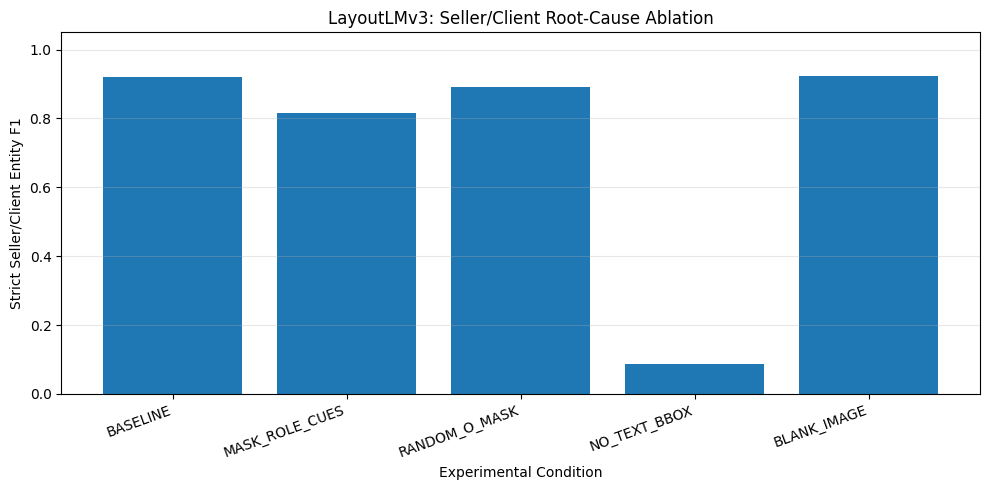


ROOT-CAUSE EXPERIMENT COMPLETED
Validation windows: 37
Conditions tested: 5
Baseline all-entity F1: 0.9713
Baseline Seller/Client F1: 0.9211

Model weights unchanged.
No training performed.
No output files created.

NOTE: Input ablations establish model sensitivity, not definitive causation.


In [26]:

# ============================================================
# PROJECT 9: SELLER / CLIENT ROOT-CAUSE EXPERIMENT
# COMPLETE STANDALONE FIXED CELL
#
# Hypotheses:
# H1: Role headings are important
# H2: Model relies on bounding-box positions
# H3: Model relies on visual features
# H4: Windowing removes useful context
# H5: Some role patterns have limited training support
#
# No training. No test-set inference. No files saved.
# ============================================================

import random
import unicodedata
from collections import defaultdict, Counter
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from tqdm.auto import tqdm
from IPython.display import display


# ============================================================
# 1. VERIFY REQUIRED OBJECTS
# ============================================================

required = ["model", "processor", "val_loader"]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing objects: {missing}. "
        "Run the Dataset and Model Initialization cells."
    )

model.eval()

DEVICE = next(model.parameters()).device
tokenizer = processor.tokenizer
val_dataset_local = val_loader.dataset

if not hasattr(val_dataset_local, "records"):
    raise RuntimeError(
        "Validation dataset must have a 'records' attribute."
    )

if not tokenizer.is_fast:
    raise RuntimeError(
        "Fast tokenizer required for word_ids()."
    )

if tokenizer.mask_token_id is None:
    raise RuntimeError(
        "Tokenizer has no mask token."
    )

ID2 = {
    int(k): v
    for k, v in model.config.id2label.items()
}

LABEL2ID = {
    k: int(v)
    for k, v in model.config.label2id.items()
}

ROLE_FIELDS = {
    "SELLER_NAME",
    "CLIENT_NAME",
    "SELLER_EMAIL",
    "CLIENT_EMAIL"
}

CONDITIONS = [
    "BASELINE",
    "MASK_ROLE_CUES",
    "RANDOM_O_MASK",
    "NO_TEXT_BBOX",
    "BLANK_IMAGE"
]

# Match previous evaluation precision when possible
USE_AMP = DEVICE.type == "cuda"

if USE_AMP:
    EVAL_DTYPE = globals().get(
        "AMP_DTYPE", torch.float16
    )

    if EVAL_DTYPE not in (
        torch.float16, torch.bfloat16
    ):
        EVAL_DTYPE = torch.float16

print("=" * 65)
print("EXPERIMENT CONFIGURATION")
print("=" * 65)

print("Device:", DEVICE)
print("Model:", type(model).__name__)
print("Validation windows:", len(val_dataset_local))
print("Entity classes:", len(ID2))
print("Experimental conditions:", len(CONDITIONS))


# ============================================================
# 2. MULTILINGUAL HEADING DETECTION
# ============================================================

def normalize_heading(text):
    text = str(text).casefold().replace("ß", "ss")
    text = unicodedata.normalize("NFKD", text)

    return "".join(
        c for c in text
        if c.isalnum()
        and not unicodedata.combining(c)
    )


ROLE_VOCAB_RAW = {
    "SELLER": [
        "seller", "supplier", "vendor",
        "lieferant", "verkäufer", "verkaeufer",
        "prodejce", "dodavatel",
        "predajca", "predávajúci",
        "predavajuci", "aussteller"
    ],

    "CLIENT": [
        "client", "customer", "buyer",
        "kunde", "kunden", "käufer",
        "rechnungsempfänger",
        "rechnungsempfaenger",
        "auftraggeber", "odběratel",
        "odberateľ", "odberatel",
        "zákazník", "zakaznik",
        "klient", "kupujúci", "kupujici"
    ]
}

ROLE_VOCAB = {
    role: {
        normalize_heading(word)
        for word in vocabulary
    }
    for role, vocabulary in ROLE_VOCAB_RAW.items()
}


def cue_role(word):
    normalized = normalize_heading(word)

    matches = [
        role
        for role, vocab in ROLE_VOCAB.items()
        if normalized in vocab
    ]

    return matches[0] if len(matches) == 1 else None


def party(field):
    if field.startswith("SELLER_"):
        return "SELLER"

    if field.startswith("CLIENT_"):
        return "CLIENT"

    return None


print("\n========== HEADING DETECTION TEST ==========")

for word in [
    "Seller", "Client", "Verkäufer",
    "Kunde", "Dodavatel", "Odberateľ"
]:
    print(f"{word:20s} -> {cue_role(word)}")


# ============================================================
# 3. STRICT BIO ENTITY EXTRACTION
# ============================================================

def extract_bio_spans(position_map, side):
    """
    position_map:
        {original_word_index: (gold_id, predicted_id)}

    side:
        0 = ground truth
        1 = prediction

    Returns:
        {(entity_type, start, end), ...}
    """

    result = set()

    active_type = None
    start = None
    previous = None

    for pos in sorted(position_map):

        # Close an entity at ignored-word gaps
        if (
            previous is not None
            and pos != previous + 1
            and active_type is not None
        ):
            result.add((
                active_type, start, previous + 1
            ))

            active_type = None
            start = None

        label_id = position_map[pos][side]
        tag = ID2[int(label_id)]

        if tag.startswith("B-"):

            if active_type is not None:
                result.add((
                    active_type, start, pos
                ))

            active_type = tag[2:]
            start = pos

        elif (
            tag.startswith("I-")
            and active_type == tag[2:]
        ):
            pass

        else:

            if active_type is not None:
                result.add((
                    active_type, start, pos
                ))

            active_type = None
            start = None

        previous = pos

    if active_type is not None:
        result.add((
            active_type, start, previous + 1
        ))

    return result


# ============================================================
# 4. ENTITY-LEVEL METRIC FUNCTION
# ============================================================

def compute_entity_f1(page_maps, selected_fields=None):

    tp = 0
    fp = 0
    fn = 0

    for position_map in page_maps.values():

        gold = extract_bio_spans(
            position_map, 0
        )

        pred = extract_bio_spans(
            position_map, 1
        )

        if selected_fields is not None:

            gold = {
                x for x in gold
                if x[0] in selected_fields
            }

            pred = {
                x for x in pred
                if x[0] in selected_fields
            }

        tp += len(gold & pred)
        fp += len(pred - gold)
        fn += len(gold - pred)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn else 0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


# ============================================================
# 5. PREDICTION HELPERS
# ============================================================

def predict_logits(inputs):

    if USE_AMP:
        context = torch.autocast(
            device_type="cuda",
            dtype=EVAL_DTYPE
        )
    else:
        context = nullcontext()

    with context:
        outputs = model(**inputs)

    return outputs.logits[0].float().cpu()


def entity_from_id(label_id):
    tag = ID2[int(label_id)]

    if tag.startswith(("B-", "I-")):
        return tag[2:]

    return "O"


# ============================================================
# 6. EXPERIMENT STORAGE
# ============================================================

condition_predictions = {
    name: defaultdict(dict)
    for name in CONDITIONS
}

role_records = []

maskable_windows = 0
total_masked_heading_tokens = 0
total_masked_control_tokens = 0


# ============================================================
# 7. RUN CONTROLLED VALIDATION EXPERIMENTS
# ============================================================

print("\n" + "=" * 65)
print("RUNNING CONTROLLED ABLATION EXPERIMENTS")
print("=" * 65)

with torch.inference_mode():

    for idx in tqdm(
        range(len(val_dataset_local)),
        desc="Validation Ablations"
    ):

        record = val_dataset_local.records[idx]
        sample = val_dataset_local[idx]

        words = record["words"]
        word_labels = record["label_ids"]

        gold_ids = sample["labels"].tolist()

        # ----------------------------------------
        # Reconstruct token-to-word mapping
        # ----------------------------------------

        tokenized = tokenizer(
            words,
            boxes=record["boxes"],
            word_labels=word_labels,
            truncation=False,
            padding="max_length",
            max_length=len(gold_ids)
        )

        if (
            tokenized["input_ids"]
            != sample["input_ids"].tolist()
        ):
            raise RuntimeError(
                f"Tokenizer mismatch in validation window {idx}"
            )

        word_ids = tokenized.word_ids()

        # ----------------------------------------
        # Identify role headings
        # ----------------------------------------

        role_cues = [
            (i, cue_role(word))
            for i, word in enumerate(words)
            if (
                cue_role(word) is not None
                and word_labels[i] == 0
            )
        ]

        heading_word_ids = {
            i for i, role in role_cues
        }

        # Mask ALL subword tokens belonging
        # to each detected heading word
        heading_token_indices = [
            ti
            for ti, wi in enumerate(word_ids)
            if wi in heading_word_ids
        ]

        if heading_token_indices:
            maskable_windows += 1

        total_masked_heading_tokens += len(
            heading_token_indices
        )

        # ----------------------------------------
        # Random control: same number of tokens
        # drawn from OTHER background words
        # ----------------------------------------

        background_token_indices = [
            ti
            for ti, wi in enumerate(word_ids)
            if (
                wi is not None
                and wi not in heading_word_ids
                and word_labels[wi] == 0
            )
        ]

        rng = random.Random(42 + idx)

        random_token_indices = rng.sample(
            background_token_indices,
            k=min(
                len(heading_token_indices),
                len(background_token_indices)
            )
        )

        total_masked_control_tokens += len(
            random_token_indices
        )

        # ----------------------------------------
        # Original model inputs
        # ----------------------------------------

        inputs = {
            key: sample[key].unsqueeze(0).to(DEVICE)
            for key in (
                "input_ids",
                "attention_mask",
                "bbox",
                "pixel_values"
            )
        }

        def masked_input(token_indices):
            ids = inputs["input_ids"].clone()

            if token_indices:
                ids[0, token_indices] = (
                    tokenizer.mask_token_id
                )

            return ids

        # ----------------------------------------
        # Five experimental conditions
        # ----------------------------------------

        variants = {
            "BASELINE": inputs,

            "MASK_ROLE_CUES": {
                **inputs,
                "input_ids": masked_input(
                    heading_token_indices
                )
            },

            "RANDOM_O_MASK": {
                **inputs,
                "input_ids": masked_input(
                    random_token_indices
                )
            },

            "NO_TEXT_BBOX": {
                **inputs,
                "bbox": torch.zeros_like(
                    inputs["bbox"]
                )
            },

            "BLANK_IMAGE": {
                **inputs,
                "pixel_values": torch.zeros_like(
                    inputs["pixel_values"]
                )
            }
        }

        page_key = (
            record["invoice_id"],
            int(record["page_index"])
        )

        # ----------------------------------------
        # Inference for every condition
        # ----------------------------------------

        for condition, variant_inputs in variants.items():

            logits = predict_logits(variant_inputs)

            predicted_ids = logits.argmax(
                dim=-1
            ).tolist()

            page_map = condition_predictions[
                condition
            ][page_key]

            for ti, gold_id in enumerate(gold_ids):

                if gold_id == -100:
                    continue

                local_word = word_ids[ti]

                if local_word is None:
                    raise RuntimeError(
                        "Supervised token has no OCR word."
                    )

                if word_labels[local_word] != gold_id:
                    raise RuntimeError(
                        "Ground-truth label alignment mismatch."
                    )

                global_word = (
                    record["word_start"] + local_word
                )

                if global_word in page_map:
                    raise RuntimeError(
                        "Duplicate supervised word detected."
                    )

                predicted_id = int(
                    predicted_ids[ti]
                )

                page_map[global_word] = (
                    int(gold_id),
                    predicted_id
                )

                # --------------------------------
                # Investigate Seller/Client
                # entity beginnings only
                # --------------------------------

                gt_tag = ID2[int(gold_id)]

                if not gt_tag.startswith("B-"):
                    continue

                gt_field = gt_tag[2:]

                if gt_field not in ROLE_FIELDS:
                    continue

                true_party = party(gt_field)

                opposite_party = (
                    "CLIENT"
                    if true_party == "SELLER"
                    else "SELLER"
                )

                field_suffix = gt_field.split("_", 1)[1]

                opposite_tag = (
                    "B-" + opposite_party
                    + "_" + field_suffix
                )

                opposite_id = LABEL2ID[opposite_tag]

                predicted_tag = ID2[predicted_id]

                # True vs opposite-role logit
                margin = (
                    logits[ti, int(gold_id)]
                    - logits[ti, opposite_id]
                ).item()

                correct_cues = [
                    cue_idx
                    for cue_idx, cue_type in role_cues
                    if (
                        cue_type == true_party
                        and cue_idx < local_word
                    )
                ]

                preceding_cues = [
                    (cue_idx, cue_type)
                    for cue_idx, cue_type in role_cues
                    if cue_idx < local_word
                ]

                nearest_role = (
                    preceding_cues[-1][1]
                    if preceding_cues
                    else "NONE"
                )

                heading_distance = (
                    local_word - max(correct_cues)
                    if correct_cues else np.nan
                )

                role_records.append({
                    "Condition": condition,
                    "Invoice": record["invoice_id"],
                    "Page": record["page_index"] + 1,
                    "Word Position": global_word,
                    "OCR Word": words[local_word],
                    "GT Field": gt_field,
                    "Predicted Tag": predicted_tag,
                    "Correct B Label": (
                        predicted_tag == gt_tag
                    ),
                    "Opposite Role B": (
                        predicted_tag == opposite_tag
                    ),
                    "Correct Cue Earlier": bool(
                        correct_cues
                    ),
                    "Nearest Earlier Cue Role":
                        nearest_role,
                    "Correct Cue Distance":
                        heading_distance,
                    "At Window Edge": (
                        min(
                            local_word,
                            len(words) - local_word - 1
                        ) < 20
                    ),
                    "Role Logit Margin": margin
                })


print("\nExperiment inference completed.")
print(
    "Windows with detected role headings:",
    maskable_windows
)

print(
    "Role-heading tokens masked:",
    total_masked_heading_tokens
)

print(
    "Random-control tokens masked:",
    total_masked_control_tokens
)


# ============================================================
# 8. COMPUTE EXPERIMENT METRICS
# ============================================================

role_df = pd.DataFrame(role_records)

if role_df.empty:
    raise RuntimeError(
        "No Seller/Client entity beginnings found."
    )

results = []

for condition in CONDITIONS:

    all_metrics = compute_entity_f1(
        condition_predictions[condition]
    )

    role_metrics = compute_entity_f1(
        condition_predictions[condition],
        selected_fields=ROLE_FIELDS
    )

    sub = role_df[
        role_df["Condition"] == condition
    ]

    results.append({
        "Condition": condition,
        "All Entity F1": all_metrics["F1"],
        "Seller/Client F1": role_metrics["F1"],
        "Role B Accuracy": sub[
            "Correct B Label"
        ].mean(),
        "Wrong Opposite-Role B": int(
            sub["Opposite Role B"].sum()
        ),
        "Mean Role Logit Margin": sub[
            "Role Logit Margin"
        ].mean()
    })


experiment_df = pd.DataFrame(results)

baseline_f1 = experiment_df.loc[
    experiment_df["Condition"] == "BASELINE",
    "Seller/Client F1"
].iloc[0]

experiment_df["Delta Role F1"] = (
    experiment_df["Seller/Client F1"]
    - baseline_f1
)

print("\n" + "=" * 65)
print("CONTROLLED VALIDATION RESULTS")
print("=" * 65)

display(experiment_df.round(4))

# Optional baseline consistency check
baseline_all_f1 = experiment_df.loc[
    experiment_df["Condition"] == "BASELINE",
    "All Entity F1"
].iloc[0]

if "best_f1" in globals():

    print(
        "\nPreviously reported best validation F1:",
        round(float(best_f1), 4)
    )

    print(
        "Current baseline validation F1:",
        round(float(baseline_all_f1), 4)
    )

    if abs(baseline_all_f1 - best_f1) > 0.02:
        print(
            "WARNING: Baseline differs noticeably. "
            "Verify that the restored best model "
            "and validation dataset are unchanged."
        )


# ============================================================
# 9. ANALYZE WHEN THE MODEL FAILS
# ============================================================

baseline = role_df[
    role_df["Condition"] == "BASELINE"
].copy()

print("\n" + "=" * 65)
print("WHEN DOES THE MODEL FAIL?")
print("=" * 65)

for factor in [
    "Correct Cue Earlier",
    "Nearest Earlier Cue Role",
    "At Window Edge"
]:

    print("\nFACTOR:", factor)

    summary = baseline.groupby(
        factor, dropna=False
    ).agg(
        Entity_Starts=("Correct B Label", "size"),
        Accuracy=("Correct B Label", "mean"),
        Opposite_Role_Errors=(
            "Opposite Role B", "sum"
        ),
        Mean_Role_Margin=(
            "Role Logit Margin", "mean"
        )
    )

    display(summary.round(4))


# ============================================================
# 10. PAIRED ABLATION IMPACT
# ============================================================

keys = ["Invoice", "Page", "Word Position"]

baseline_pair = baseline[
    keys + [
        "GT Field",
        "Predicted Tag",
        "Correct B Label"
    ]
].rename(columns={
    "Predicted Tag": "Baseline Prediction",
    "Correct B Label": "Baseline Correct"
})

impact_rows = []

changed_examples = []

for condition in CONDITIONS[1:]:

    modified = role_df[
        role_df["Condition"] == condition
    ][
        keys + [
            "Predicted Tag",
            "Correct B Label"
        ]
    ].rename(columns={
        "Predicted Tag": "Modified Prediction",
        "Correct B Label": "Modified Correct"
    })

    paired = baseline_pair.merge(
        modified,
        on=keys,
        validate="one_to_one"
    )

    prediction_changed = (
        paired["Baseline Prediction"]
        != paired["Modified Prediction"]
    )

    correct_to_wrong = (
        paired["Baseline Correct"]
        & ~paired["Modified Correct"]
    )

    wrong_to_correct = (
        ~paired["Baseline Correct"]
        & paired["Modified Correct"]
    )

    impact_rows.append({
        "Condition": condition,
        "Entities Checked": len(paired),
        "Prediction Changed": int(
            prediction_changed.sum()
        ),
        "Correct -> Wrong": int(
            correct_to_wrong.sum()
        ),
        "Wrong -> Correct": int(
            wrong_to_correct.sum()
        )
    })

    changes = paired[prediction_changed].copy()

    changes["Condition"] = condition

    changed_examples.append(changes)


impact_df = pd.DataFrame(impact_rows)

print("\n" + "=" * 65)
print("PAIRED ABLATION IMPACT")
print("=" * 65)

display(impact_df)

if changed_examples:

    changes_df = pd.concat(
        changed_examples,
        ignore_index=True
    )

    print("\nEXAMPLES OF CHANGED PREDICTIONS:")

    display(changes_df.head(25))


# ============================================================
# 11. INSPECT ORIGINAL ROLE ERRORS
# ============================================================

incorrect = baseline[
    ~baseline["Correct B Label"]
].copy()

print("\n" + "=" * 65)
print("ORIGINAL ROLE PREDICTION ERRORS")
print("=" * 65)

print(
    "Incorrect Seller/Client entity beginnings:",
    len(incorrect)
)

display(
    incorrect[
        [
            "Invoice",
            "Page",
            "OCR Word",
            "GT Field",
            "Predicted Tag",
            "Correct Cue Earlier",
            "Nearest Earlier Cue Role",
            "Correct Cue Distance",
            "At Window Edge",
            "Role Logit Margin"
        ]
    ].head(30)
)


# ============================================================
# 12. OPTIONAL TRAINING PATTERN SUPPORT AUDIT
# ============================================================

if "train_loader" in globals():

    training_counts = Counter()
    training_with_cue = Counter()

    for record in train_loader.dataset.records:

        cues = [
            (i, cue_role(w))
            for i, w in enumerate(record["words"])
            if (
                cue_role(w) is not None
                and record["label_ids"][i] == 0
            )
        ]

        for wi, label_id in enumerate(
            record["label_ids"]
        ):

            if label_id < 0:
                continue

            tag = ID2[int(label_id)]

            if not tag.startswith("B-"):
                continue

            field = tag[2:]

            if field not in ROLE_FIELDS:
                continue

            training_counts[field] += 1

            if any(
                cue_idx < wi
                and cue_type == party(field)
                for cue_idx, cue_type in cues
            ):
                training_with_cue[field] += 1

    train_support_df = pd.DataFrame([
        {
            "Field": field,
            "Training Entity Examples":
                training_counts[field],
            "Examples with Earlier Correct Cue":
                training_with_cue[field],
            "Cue Coverage": (
                training_with_cue[field]
                / training_counts[field]
                if training_counts[field] else 0
            )
        }
        for field in sorted(ROLE_FIELDS)
    ])

    print("\n" + "=" * 65)
    print("TRAINING PATTERN SUPPORT")
    print("=" * 65)

    display(train_support_df.round(4))


# ============================================================
# 13. VISUALIZE RESULTS
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    experiment_df["Condition"],
    experiment_df["Seller/Client F1"]
)

plt.ylim(0, 1.05)
plt.ylabel("Strict Seller/Client Entity F1")
plt.xlabel("Experimental Condition")

plt.title(
    "LayoutLMv3: Seller/Client Root-Cause Ablation"
)

plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("ROOT-CAUSE EXPERIMENT COMPLETED")
print("=" * 65)

print("Validation windows:", len(val_dataset_local))
print("Conditions tested:", len(CONDITIONS))
print(
    "Baseline all-entity F1:",
    round(float(baseline_all_f1), 4)
)
print(
    "Baseline Seller/Client F1:",
    round(float(baseline_f1), 4)
)

print("\nModel weights unchanged.")
print("No training performed.")
print("No output files created.")

print(
    "\nNOTE: Input ablations establish model "
    "sensitivity, not definitive causation."
)


In [27]:

# ============================================================
# BASELINE F1 CONSISTENCY DIAGNOSTIC
# No training, no test evaluation, no files.
# ============================================================

import pandas as pd
from IPython.display import display

assert "condition_predictions" in globals()
assert "compute_entity_f1" in globals()

model.eval()

cached = condition_predictions["BASELINE"]

results = []

# 1. New scorer on previously cached predictions
new_metrics = compute_entity_f1(cached)

results.append({
    "Method": "Ablation scorer (cached predictions)",
    "Validation F1": float(new_metrics["F1"])
})

# 2. Previous training scorer on SAME predictions
if "score_pages" in globals() and callable(score_pages):

    old_metrics = score_pages(cached)

    results.append({
        "Method": "Original scorer (same predictions)",
        "Validation F1": float(old_metrics["f1"])
    })

# 3. Original batched validation inference
if "validate" in globals() and callable(validate):

    batched_metrics = validate()

    results.append({
        "Method": "Original batched validation",
        "Validation F1": float(batched_metrics["f1"])
    })

# 4. F1 reported during training
if "best_f1" in globals():

    results.append({
        "Method": "Historical training best F1",
        "Validation F1": float(best_f1)
    })

results_df = pd.DataFrame(results)

print("=" * 65)
print("BASELINE CONSISTENCY AUDIT")
print("=" * 65)

display(results_df.round(6))

print("\nModel device:",
      next(model.parameters()).device)
print("Model training mode:", model.training)
print("Validation batches:", len(val_loader))
print("Validation windows:", len(val_loader.dataset))

if "AMP_DTYPE" in globals():
    print("Configured AMP dtype:", AMP_DTYPE)

print("\nF1 spread:",
      round(
          results_df["Validation F1"].max()
          - results_df["Validation F1"].min(),
          6
      ))

print("\nAudit completed.")


Validation:   0%|          | 0/19 [00:00<?, ?it/s]

BASELINE CONSISTENCY AUDIT


,Method,Validation F1
0,Ablation scorer (cached predictions),0.971292
1,Original scorer (same predictions),0.971292
2,Original batched validation,0.971292
3,Historical training best F1,0.894737



Model device: cuda:0
Model training mode: False
Validation batches: 19
Validation windows: 37
Configured AMP dtype: torch.float16

F1 spread: 0.076555

Audit completed.


VALIDATION CONSISTENCY EXPERIMENT
GPU: Tesla T4
Device: cuda:0
Model: LayoutLMv3ForTokenClassification
Model dtype: torch.float32
Validation Windows: 37
Original Batch Size: 2
Maximum Tokens: 512

========== CLASSIFICATION HEAD ==========
LayoutLMv3ClassificationHead(
  (dense): Linear(in_features=768, out_features=768, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (out_proj): Linear(in_features=768, out_features=23, bias=True)
)

Classifier Fingerprint: 4375a37abc30a78e
Fingerprint successfully generated.
Historical fingerprint: Not available

========== GPU PRECISION SUPPORT ==========
Compute Capability: (7, 5)
FP32 Available: True
FP16 Available: True
BF16 Supported: True
NOTE: Native BF16 acceleration may be unavailable; emulation may be used.

Preparing word alignment...


Token Alignment:   0%|          | 0/37 [00:00<?, ?it/s]

Prepared word maps: 37

RUNNING PRECISION / BATCH EXPERIMENTS

Evaluating: FP32 | Batch Size 1


FP32 | Batch 1:   0%|          | 0/37 [00:00<?, ?it/s]


Evaluating: FP32 | Batch Size 2


...


PRECISION / BATCH CONSISTENCY RESULTS


,Precision Mode,Batch Size,Entity F1,Precision,Recall,TP,FP,FN,Status
0,FP32,1,0.971292,0.971292,0.971292,203,6,6,SUCCESS
1,FP32,2,0.971292,0.971292,0.971292,203,6,6,SUCCESS
2,FP16,1,0.971292,0.971292,0.971292,203,6,6,SUCCESS
3,FP16,2,0.971292,0.971292,0.971292,203,6,6,SUCCESS
4,BF16,1,0.971292,0.971292,0.971292,203,6,6,SUCCESS
5,BF16,2,0.971292,0.971292,0.971292,203,6,6,SUCCESS



PREDICTION STABILITY


,Precision,Batch Size,Compared Words,Changed Predictions,Prediction Agreement %
0,FP32,1,3562,0,100.0000
1,FP32,2,3562,0,100.0000
2,FP16,1,3562,0,100.0000
3,FP16,2,3562,0,100.0000
4,BF16,1,3562,1,99.9719
5,BF16,2,3562,1,99.9719



HISTORICAL VALIDATION COMPARISON
Historical Training F1 : 0.894737
Current Ablation F1   : 0.971292

Minimum Current F1    : 0.971292
Maximum Current F1    : 0.971292
Current F1 Spread     : 0.000000
Gap from Historical   : 0.076555


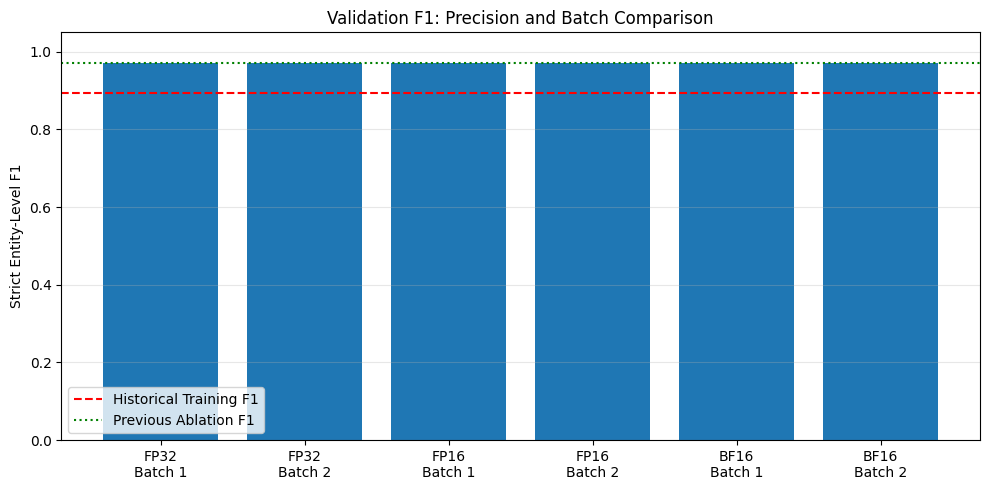


FINAL DIAGNOSTIC SUMMARY
Historical F1 lies outside the observed precision/batch experiment range.
Precision/batching alone has not reproduced the historical result.
Investigate historical model state, checkpoint, or evaluation configuration.

Classifier Fingerprint: 4375a37abc30a78e

No training performed.
No test set evaluated.
No output files created.

Consistency experiment completed!


In [29]:

# ============================================================
# PROJECT 9: VALIDATION CONSISTENCY EXPERIMENT
# COMPLETE FIXED VERSION
#
# Investigates:
# 1. FP32 vs FP16 vs BF16
# 2. Batch size 1 vs batch size 2
# 3. Prediction consistency
# 4. Historical validation F1 mismatch
#
# No training.
# No test-set evaluation.
# No files created.
# ============================================================

import hashlib
from collections import defaultdict
from contextlib import nullcontext

import torch
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from IPython.display import display


# ============================================================
# 1. VERIFY REQUIRED OBJECTS
# ============================================================

required = [
    "model",
    "processor",
    "val_loader"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Run previous model and dataset cells first."
    )

model.eval()

DEVICE = next(model.parameters()).device
val_ds = val_loader.dataset

if DEVICE.type != "cuda":
    raise RuntimeError(
        "Enable Kaggle GPU before running this experiment."
    )

if not hasattr(val_ds, "records"):
    raise RuntimeError(
        "Validation dataset must contain .records"
    )

if not processor.tokenizer.is_fast:
    raise RuntimeError(
        "Fast tokenizer required for word alignment."
    )

ID2LABEL = {
    int(k): v
    for k, v in model.config.id2label.items()
}

MAX_LENGTH = int(
    val_ds[0]["input_ids"].shape[0]
)

HISTORICAL_F1 = 0.894737

print("=" * 65)
print("VALIDATION CONSISTENCY EXPERIMENT")
print("=" * 65)

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Device:", DEVICE)
print("Model:", type(model).__name__)
print("Model dtype:", next(model.parameters()).dtype)
print("Validation Windows:", len(val_ds))
print("Original Batch Size:", val_loader.batch_size)
print("Maximum Tokens:", MAX_LENGTH)


# ============================================================
# 2. FIXED MODEL FINGERPRINT
# ============================================================

# LayoutLMv3ClassificationHead contains nested layers.
# It does not expose model.classifier.weight directly.

print("\n========== CLASSIFICATION HEAD ==========")

print(model.classifier)

hasher = hashlib.sha256()

for name, tensor in sorted(
    model.classifier.state_dict().items()
):

    # Include parameter name, shape, and dtype
    hasher.update(name.encode("utf-8"))
    hasher.update(
        str(tuple(tensor.shape)).encode("utf-8")
    )
    hasher.update(
        str(tensor.dtype).encode("utf-8")
    )

    values = (
        tensor.detach()
        .cpu()
        .contiguous()
    )

    # float conversion supports BF16 tensors
    if values.is_floating_point():
        values = values.float()

    hasher.update(
        values.numpy().tobytes()
    )

MODEL_FINGERPRINT = hasher.hexdigest()[:16]

print("\nClassifier Fingerprint:", MODEL_FINGERPRINT)
print("Fingerprint successfully generated.")
print("Historical fingerprint: Not available")


# ============================================================
# 3. CHECK GPU PRECISION SUPPORT
# ============================================================

capability = torch.cuda.get_device_capability(
    DEVICE
)

BF16_SUPPORTED = torch.cuda.is_bf16_supported()

print("\n========== GPU PRECISION SUPPORT ==========")

print("Compute Capability:", capability)
print("FP32 Available: True")
print("FP16 Available: True")
print("BF16 Supported:", BF16_SUPPORTED)

if BF16_SUPPORTED and capability[0] < 8:
    print(
        "NOTE: Native BF16 acceleration may be "
        "unavailable; emulation may be used."
    )

if not BF16_SUPPORTED:
    print(
        "BF16 experiment will be skipped automatically."
    )


# ============================================================
# 4. PRECOMPUTE TOKEN-TO-WORD ALIGNMENT
# ============================================================

print("\nPreparing word alignment...")

word_maps = []

for record in tqdm(
    val_ds.records,
    desc="Token Alignment"
):

    encoding = processor.tokenizer(
        record["words"],
        boxes=record["boxes"],
        word_labels=record["label_ids"],
        truncation=False,
        padding="max_length",
        max_length=MAX_LENGTH
    )

    if len(encoding["input_ids"]) != MAX_LENGTH:
        raise RuntimeError(
            "Unexpected token sequence length."
        )

    word_maps.append({
        "input_ids": encoding["input_ids"],
        "word_ids": encoding.word_ids()
    })

print("Prepared word maps:", len(word_maps))


# ============================================================
# 5. STRICT BIO SPAN EXTRACTION
# ============================================================

def extract_entities(position_map, side):

    entities = set()

    active_type = None
    start = None
    previous_pos = None

    for pos in sorted(position_map):

        # Close an active entity at ignored-word gaps
        if (
            previous_pos is not None
            and pos != previous_pos + 1
            and active_type is not None
        ):
            entities.add((
                active_type,
                start,
                previous_pos + 1
            ))

            active_type = None
            start = None

        label_id = int(
            position_map[pos][side]
        )

        tag = ID2LABEL[label_id]

        if tag.startswith("B-"):

            if active_type is not None:
                entities.add((
                    active_type,
                    start,
                    pos
                ))

            active_type = tag[2:]
            start = pos

        elif (
            tag.startswith("I-")
            and active_type == tag[2:]
        ):
            # Correct entity continuation
            pass

        else:

            if active_type is not None:
                entities.add((
                    active_type,
                    start,
                    pos
                ))

            active_type = None
            start = None

        previous_pos = pos

    if active_type is not None:
        entities.add((
            active_type,
            start,
            previous_pos + 1
        ))

    return entities


# ============================================================
# 6. ENTITY-LEVEL METRIC FUNCTION
# ============================================================

def calculate_entity_metrics(page_predictions):

    tp = 0
    fp = 0
    fn = 0

    for position_map in page_predictions.values():

        true_spans = extract_entities(
            position_map, 0
        )

        predicted_spans = extract_entities(
            position_map, 1
        )

        tp += len(
            true_spans & predicted_spans
        )

        fp += len(
            predicted_spans - true_spans
        )

        fn += len(
            true_spans - predicted_spans
        )

    precision = (
        tp / (tp + fp)
        if tp + fp else 0.0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn else 0.0
    )

    f1 = (
        2 * tp / (2 * tp + fp + fn)
        if (2 * tp + fp + fn) else 0.0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


# ============================================================
# 7. EVALUATE SPECIFIC PRECISION & BATCH SIZE
# ============================================================

@torch.inference_mode()
def evaluate_configuration(mode, batch_size):

    loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    page_predictions = defaultdict(dict)

    offset = 0

    for batch in tqdm(
        loader,
        desc=f"{mode} | Batch {batch_size}",
        leave=False
    ):

        current_batch_size = (
            batch["input_ids"].shape[0]
        )

        inputs = {
            key: batch[key].to(DEVICE)
            for key in (
                "input_ids",
                "attention_mask",
                "bbox",
                "pixel_values"
            )
        }

        # ----------------------------------------
        # Explicit precision control
        # ----------------------------------------

        if mode == "FP32":

            context = torch.autocast(
                device_type="cuda",
                enabled=False
            )

        elif mode == "FP16":

            context = torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            )

        elif mode == "BF16":

            context = torch.autocast(
                device_type="cuda",
                dtype=torch.bfloat16
            )

        else:
            raise ValueError(
                f"Unknown precision mode: {mode}"
            )

        # ----------------------------------------
        # Forward inference
        # ----------------------------------------

        with context:
            outputs = model(**inputs)

        logits = outputs.logits.float()

        if not torch.isfinite(logits).all().item():
            raise RuntimeError(
                f"Non-finite logits with {mode}"
            )

        predictions = logits.argmax(
            dim=-1
        ).cpu()

        # ----------------------------------------
        # Reconstruct OCR-word predictions
        # ----------------------------------------

        for row in range(current_batch_size):

            record_index = offset + row
            record = val_ds.records[record_index]

            alignment = word_maps[record_index]

            original_ids = batch[
                "input_ids"
            ][row].tolist()

            if (
                alignment["input_ids"]
                != original_ids
            ):
                raise RuntimeError(
                    "Tokenizer/DataLoader mismatch."
                )

            word_ids = alignment["word_ids"]

            page_key = (
                record["invoice_id"],
                int(record["page_index"])
            )

            gold_labels = batch[
                "labels"
            ][row].tolist()

            predicted_labels = predictions[
                row
            ].tolist()

            for token_pos, true_label in enumerate(
                gold_labels
            ):

                if true_label == -100:
                    continue

                local_word = word_ids[token_pos]

                if local_word is None:
                    raise RuntimeError(
                        "Supervised token has no OCR word."
                    )

                expected_label = record[
                    "label_ids"
                ][local_word]

                if expected_label != true_label:
                    raise RuntimeError(
                        "BIO label alignment mismatch."
                    )

                global_word = (
                    record["word_start"]
                    + local_word
                )

                if (
                    global_word
                    in page_predictions[page_key]
                ):
                    raise RuntimeError(
                        "Duplicate supervised OCR word."
                    )

                page_predictions[page_key][
                    global_word
                ] = (
                    int(true_label),
                    int(predicted_labels[token_pos])
                )

        offset += current_batch_size

    if offset != len(val_ds):
        raise RuntimeError(
            "Some validation windows were not evaluated."
        )

    metrics = calculate_entity_metrics(
        page_predictions
    )

    return metrics, page_predictions


# ============================================================
# 8. RUN FP32 / FP16 / BF16 EXPERIMENTS
# ============================================================

results = []
prediction_cache = {}

batch_sizes = sorted(set([
    1,
    val_loader.batch_size
]))

print("\n" + "=" * 65)
print("RUNNING PRECISION / BATCH EXPERIMENTS")
print("=" * 65)

for mode in ("FP32", "FP16", "BF16"):

    for batch_size in batch_sizes:

        print(
            f"\nEvaluating: "
            f"{mode} | Batch Size {batch_size}"
        )

        # Skip unsupported BF16 configurations
        if mode == "BF16" and not BF16_SUPPORTED:

            print("SKIPPED: BF16 not supported.")

            results.append({
                "Precision Mode": mode,
                "Batch Size": batch_size,
                "Entity F1": None,
                "Precision": None,
                "Recall": None,
                "TP": None,
                "FP": None,
                "FN": None,
                "Status": "SKIPPED"
            })

            continue

        try:

            metrics, predictions = (
                evaluate_configuration(
                    mode,
                    batch_size
                )
            )

        except RuntimeError as error:

            message = str(error).lower()

            unsupported_bf16 = (
                mode == "BF16"
                and (
                    "bfloat16" in message
                    or "bf16" in message
                    or "not supported" in message
                )
            )

            if not unsupported_bf16:
                raise

            print(
                "BF16 unavailable:",
                str(error)[:200]
            )

            results.append({
                "Precision Mode": mode,
                "Batch Size": batch_size,
                "Entity F1": None,
                "Precision": None,
                "Recall": None,
                "TP": None,
                "FP": None,
                "FN": None,
                "Status": "UNAVAILABLE"
            })

            continue

        prediction_cache[
            (mode, batch_size)
        ] = predictions

        results.append({
            "Precision Mode": mode,
            "Batch Size": batch_size,
            "Entity F1": metrics["F1"],
            "Precision": metrics["Precision"],
            "Recall": metrics["Recall"],
            "TP": metrics["TP"],
            "FP": metrics["FP"],
            "FN": metrics["FN"],
            "Status": "SUCCESS"
        })


# ============================================================
# 9. DISPLAY PRECISION COMPARISON
# ============================================================

result_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("PRECISION / BATCH CONSISTENCY RESULTS")
print("=" * 65)

display(result_df.round(6))


# ============================================================
# 10. CHECK PREDICTION STABILITY
# ============================================================

reference_key = (
    "FP32",
    val_loader.batch_size
)

if reference_key not in prediction_cache:
    raise RuntimeError(
        "FP32 reference predictions unavailable."
    )

reference = prediction_cache[reference_key]

stability_rows = []

for key, candidate in prediction_cache.items():

    changed_words = 0
    total_words = 0

    if set(reference) != set(candidate):
        raise RuntimeError(
            "Different page sets in evaluation."
        )

    for page_key in reference:

        ref_positions = reference[page_key]
        candidate_positions = candidate[page_key]

        if set(ref_positions) != set(candidate_positions):
            raise RuntimeError(
                "Supervised word positions differ."
            )

        for word_pos in ref_positions:

            ref_true, ref_pred = ref_positions[word_pos]
            cand_true, cand_pred = candidate_positions[word_pos]

            if ref_true != cand_true:
                raise RuntimeError(
                    "Ground truth differs across evaluations."
                )

            total_words += 1

            if ref_pred != cand_pred:
                changed_words += 1

    stability_rows.append({
        "Precision": key[0],
        "Batch Size": key[1],
        "Compared Words": total_words,
        "Changed Predictions": changed_words,
        "Prediction Agreement %": (
            100 * (total_words - changed_words)
            / total_words
            if total_words else 0
        )
    })

stability_df = pd.DataFrame(stability_rows)

print("\n" + "=" * 65)
print("PREDICTION STABILITY")
print("=" * 65)

display(stability_df.round(4))


# ============================================================
# 11. HISTORICAL VALIDATION COMPARISON
# ============================================================

successful = result_df[
    result_df["Status"] == "SUCCESS"
].copy()

min_f1 = successful["Entity F1"].min()
max_f1 = successful["Entity F1"].max()

print("\n" + "=" * 65)
print("HISTORICAL VALIDATION COMPARISON")
print("=" * 65)

print(f"Historical Training F1 : {HISTORICAL_F1:.6f}")
print("Current Ablation F1   : 0.971292")

print(f"\nMinimum Current F1    : {min_f1:.6f}")
print(f"Maximum Current F1    : {max_f1:.6f}")

print(
    f"Current F1 Spread     : "
    f"{max_f1 - min_f1:.6f}"
)

print(
    f"Gap from Historical   : "
    f"{min(abs(min_f1 - HISTORICAL_F1), abs(max_f1 - HISTORICAL_F1)):.6f}"
)


# ============================================================
# 12. VISUALIZE F1 COMPARISON
# ============================================================

plt.figure(figsize=(10, 5))

labels = [
    f"{row['Precision Mode']}\nBatch {row['Batch Size']}"
    for _, row in successful.iterrows()
]

plt.bar(
    labels,
    successful["Entity F1"]
)

plt.axhline(
    HISTORICAL_F1,
    color="red",
    linestyle="--",
    label="Historical Training F1"
)

plt.axhline(
    0.971292,
    color="green",
    linestyle=":",
    label="Previous Ablation F1"
)

plt.ylim(0, 1.05)
plt.ylabel("Strict Entity-Level F1")
plt.title("Validation F1: Precision and Batch Comparison")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 13. FINAL DIAGNOSTIC
# ============================================================

print("\n" + "=" * 65)
print("FINAL DIAGNOSTIC SUMMARY")
print("=" * 65)

if min_f1 <= HISTORICAL_F1 <= max_f1:

    print(
        "Historical F1 lies within the observed "
        "precision/batch experiment range."
    )

    print(
        "Precision or batching sensitivity may "
        "help explain the discrepancy."
    )

else:

    print(
        "Historical F1 lies outside the observed "
        "precision/batch experiment range."
    )

    print(
        "Precision/batching alone has not "
        "reproduced the historical result."
    )

    print(
        "Investigate historical model state, "
        "checkpoint, or evaluation configuration."
    )

print("\nClassifier Fingerprint:", MODEL_FINGERPRINT)

print("\nNo training performed.")
print("No test set evaluated.")
print("No output files created.")
print("\nConsistency experiment completed!")


In [30]:

# ============================================================
# PROJECT 9: SELLER vs CLIENT EMAIL ANCHOR INVESTIGATION
#
# A. Find Seller/Client heading and name anchors
# B. Check spatial association with each email
# C. Redact email text, keeping its section unchanged
# D. Swap Seller/Client heading words
# E. Swap Seller/Client email strings
# F. Train a small POSITION-ONLY diagnostic probe
#
# LayoutLMv3 weights are NEVER updated.
# Counterfactuals run on VALIDATION only.
# No files are created.
# ============================================================

import unicodedata
from collections import Counter
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from IPython.display import display


# ============================================================
# 1. SETUP
# ============================================================

required = ["model", "processor", "val_loader"]

missing = [k for k in required if k not in globals()]

if missing:
    raise RuntimeError(f"Missing: {missing}")

model.eval()

device = next(model.parameters()).device
tokenizer = processor.tokenizer
val_ds = val_loader.dataset

if not hasattr(val_ds, "records"):
    raise RuntimeError("Validation dataset needs .records")

if not tokenizer.is_fast:
    raise RuntimeError("Fast tokenizer required.")

ID2 = {
    int(k): v
    for k, v in model.config.id2label.items()
}

L2 = {
    str(k): int(v)
    for k, v in model.config.label2id.items()
}

SELLER_ID = L2["B-SELLER_EMAIL"]
CLIENT_ID = L2["B-CLIENT_EMAIL"]

CONDITIONS = [
    "BASELINE",
    "CANONICAL_HEADINGS",
    "FLIPPED_HEADINGS",
    "REDACT_EMAIL_TEXT",
    "SWAP_EMAIL_STRINGS"
]

print("=" * 65)
print("EMAIL ROLE-ANCHOR INVESTIGATION")
print("=" * 65)

print("Device:", device)
print("Validation windows:", len(val_ds))
print("Model:", type(model).__name__)
print("Conditions:", CONDITIONS)


# ============================================================
# 2. MULTILINGUAL SELLER/CLIENT CUES
# ============================================================

def normalize_word(word):

    s = str(word).casefold().replace("ß", "ss")
    s = unicodedata.normalize("NFKD", s)

    return "".join(
        c for c in s
        if c.isalnum()
        and not unicodedata.combining(c)
    )


RAW_CUES = {
    "SELLER": [
        "seller", "supplier", "vendor",
        "lieferant", "verkäufer", "verkaeufer",
        "prodejce", "dodavatel",
        "predajca", "predávajúci",
        "aussteller"
    ],
    "CLIENT": [
        "client", "customer", "buyer",
        "kunde", "kunden", "käufer",
        "rechnungsempfänger",
        "rechnungsempfaenger",
        "odběratel", "odberateľ",
        "zákazník", "klient", "kupujúci"
    ]
}

CUES = {
    role: {normalize_word(x) for x in words}
    for role, words in RAW_CUES.items()
}


def detect_cue(word):

    s = normalize_word(word)

    matched = [
        role
        for role, vocabulary in CUES.items()
        if s in vocabulary
    ]

    return matched[0] if len(matched) == 1 else None


def label_name(label_id):

    if int(label_id) == -100:
        return "IGNORE"

    return ID2[int(label_id)]


def box_center(box):

    x0, y0, x1, y1 = map(float, box)

    return (
        (x0 + x1) / 2,
        (y0 + y1) / 2
    )


def spatial_cost(anchor_box, email_box):
    """
    Diagnostic spatial heuristic:
    - Prefer horizontally nearby anchors
    - Prefer vertically nearby anchors
    - Penalize anchors below the email

    This is NOT a trained model.
    """

    ax, ay = box_center(anchor_box)
    ex, ey = box_center(email_box)

    dx = abs(ex - ax)
    dy = abs(ey - ay)

    below_penalty = 2.0 * max(0.0, ay - ey)

    return (
        1.5 * dx
        + dy
        + below_penalty
    )


def nearest_role(email_box, anchors):
    """
    Require evidence for BOTH roles.
    Returns nearest anchor role or None.
    """

    distances = {
        "SELLER": [],
        "CLIENT": []
    }

    for role, anchor_box in anchors:

        distances[role].append(
            spatial_cost(anchor_box, email_box)
        )

    if (
        not distances["SELLER"]
        or not distances["CLIENT"]
    ):
        return None, np.nan, np.nan

    ds = min(distances["SELLER"])
    dc = min(distances["CLIENT"])

    vote = (
        "SELLER"
        if ds < dc
        else "CLIENT"
        if dc < ds
        else None
    )

    return vote, ds, dc


# ============================================================
# 3. EMAIL AND ANCHOR EXTRACTION
# ============================================================

def extract_window_info(record):

    words = record["words"]
    boxes = record["boxes"]
    labels = record["label_ids"]

    email_starts = []
    heading_anchors = []

    name_boxes = {
        "SELLER": [],
        "CLIENT": []
    }

    for i, (word, lid) in enumerate(
        zip(words, labels)
    ):

        tag = label_name(lid)
        cue = detect_cue(word)

        # Headings may be ignored in overlap context,
        # but their OCR text is still visible to model.
        if cue is not None and tag in ("O", "IGNORE"):
            heading_anchors.append(
                (i, cue, word, boxes[i])
            )

        if tag == "B-SELLER_EMAIL":
            email_starts.append((i, "SELLER"))

        elif tag == "B-CLIENT_EMAIL":
            email_starts.append((i, "CLIENT"))

        if tag in (
            "B-SELLER_NAME", "I-SELLER_NAME"
        ):
            name_boxes["SELLER"].append(boxes[i])

        elif tag in (
            "B-CLIENT_NAME", "I-CLIENT_NAME"
        ):
            name_boxes["CLIENT"].append(boxes[i])

    # Ground-truth name positions are used
    # ONLY for diagnostic analysis.
    name_anchors = []

    for role in ("SELLER", "CLIENT"):

        role_boxes = name_boxes[role]

        if role_boxes:

            x0 = min(b[0] for b in role_boxes)
            y0 = min(b[1] for b in role_boxes)
            x1 = max(b[2] for b in role_boxes)
            y1 = max(b[3] for b in role_boxes)

            name_anchors.append(
                (role, [x0, y0, x1, y1])
            )

    return (
        email_starts,
        heading_anchors,
        name_anchors
    )


# ============================================================
# 4. BUILD COUNTERFACTUAL INPUTS
# ============================================================

def build_variants(record, info):

    email_starts, headings, _ = info

    original = list(record["words"])

    variants = {
        "BASELINE": original
    }

    # ----------------------------------------
    # Canonical English headings: control
    # ----------------------------------------

    canonical = original.copy()

    for idx, role, word, box in headings:
        canonical[idx] = (
            "Seller" if role == "SELLER"
            else "Client"
        )

    variants["CANONICAL_HEADINGS"] = canonical

    # ----------------------------------------
    # Flip role words at the SAME positions
    # Only when BOTH roles are present
    # ----------------------------------------

    roles_present = {
        role for _, role, _, _ in headings
    }

    if roles_present == {"SELLER", "CLIENT"}:

        flipped = original.copy()

        for idx, role, word, box in headings:

            flipped[idx] = (
                "Client" if role == "SELLER"
                else "Seller"
            )

        variants["FLIPPED_HEADINGS"] = flipped

    # ----------------------------------------
    # Make all supervised emails look identical
    # ----------------------------------------

    redacted = original.copy()

    for i, lid in enumerate(record["label_ids"]):

        tag = label_name(lid)

        if tag in (
            "B-SELLER_EMAIL",
            "I-SELLER_EMAIL",
            "B-CLIENT_EMAIL",
            "I-CLIENT_EMAIL"
        ):
            redacted[i] = "x@y.co"

    variants["REDACT_EMAIL_TEXT"] = redacted

    # ----------------------------------------
    # Swap actual email strings only when:
    # - One seller email
    # - One client email
    # - Each occupies exactly one OCR word
    # - Both are in the SAME window
    # ----------------------------------------

    sellers = [
        i for i, role in email_starts
        if role == "SELLER"
    ]

    clients = [
        i for i, role in email_starts
        if role == "CLIENT"
    ]

    has_continuations = any(
        label_name(lid) in (
            "I-SELLER_EMAIL",
            "I-CLIENT_EMAIL"
        )
        for lid in record["label_ids"]
    )

    if (
        len(sellers) == 1
        and len(clients) == 1
        and not has_continuations
    ):

        swapped = original.copy()

        s, c = sellers[0], clients[0]

        swapped[s], swapped[c] = (
            swapped[c], swapped[s]
        )

        variants["SWAP_EMAIL_STRINGS"] = swapped

    return variants


# ============================================================
# 5. RUN MODEL WITH MODIFIED OCR TEXT
# ============================================================

def infer_window(sample, record, words):

    max_len = int(sample["input_ids"].shape[0])

    encoding = tokenizer(
        words,
        boxes=record["boxes"],
        truncation=False,
        padding="max_length",
        max_length=max_len,
        return_tensors="pt"
    )

    # Modified text may increase token count.
    # Never silently truncate an email or anchor.
    if encoding["input_ids"].shape[1] != max_len:
        return None

    inputs = {
        "input_ids": encoding["input_ids"].to(device),
        "attention_mask": encoding[
            "attention_mask"
        ].to(device),
        "bbox": encoding["bbox"].to(device),
        "pixel_values": sample[
            "pixel_values"
        ].unsqueeze(0).to(device)
    }

    if device.type == "cuda":
        amp = torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        )
    else:
        amp = nullcontext()

    with torch.inference_mode(), amp:

        logits = model(**inputs).logits[0].float()

    return (
        logits.cpu(),
        encoding.word_ids(batch_index=0),
        encoding["input_ids"][0].tolist()
    )


# ============================================================
# 6. RUN ALL COUNTERFACTUAL EXPERIMENTS
# ============================================================

experiment_rows = []
anchor_rows = []

condition_windows = Counter()
skipped_length = Counter()

print("\n" + "=" * 65)
print("RUNNING EMAIL-ROLE COUNTERFACTUALS")
print("=" * 65)

for wi in tqdm(
    range(len(val_ds)),
    desc="Email Anchor Experiments"
):

    record = val_ds.records[wi]
    sample = val_ds[wi]

    info = extract_window_info(record)

    email_starts, headings, name_anchors = info

    if not email_starts:
        continue

    variants = build_variants(record, info)

    # ----------------------------------------
    # Anchor geometry: independent of model
    # ----------------------------------------

    heading_pairs = [
        (role, box)
        for _, role, _, box in headings
    ]

    for local_word, true_role in email_starts:

        email_box = record["boxes"][local_word]

        head_vote, ds, dc = nearest_role(
            email_box,
            heading_pairs
        )

        name_vote, ns, nc = nearest_role(
            email_box,
            name_anchors
        )

        anchor_rows.append({
            "Invoice": record["invoice_id"],
            "Page": record["page_index"] + 1,
            "Global Word": (
                record["word_start"] + local_word
            ),
            "Email": record["words"][local_word],
            "True Role": true_role,
            "Heading Anchor Vote": (
                head_vote if head_vote else "UNKNOWN"
            ),
            "Name Anchor Vote": (
                name_vote if name_vote else "UNKNOWN"
            ),
            "Heading Seller Distance": ds,
            "Heading Client Distance": dc,
            "Name Seller Distance": ns,
            "Name Client Distance": nc,
            "Detected Headings": ", ".join(
                f"{role}:{word}"
                for _, role, word, _ in headings
            ) or "NONE"
        })

    # ----------------------------------------
    # Counterfactual inference
    # ----------------------------------------

    for condition, modified_words in variants.items():

        result = infer_window(
            sample, record, modified_words
        )

        if result is None:
            skipped_length[condition] += 1
            continue

        logits, word_ids, token_ids = result

        if condition == "BASELINE":

            original_ids = sample[
                "input_ids"
            ].tolist()

            if token_ids != original_ids:
                raise RuntimeError(
                    f"Baseline tokenization mismatch "
                    f"in window {wi}"
                )

        condition_windows[condition] += 1

        # First subtoken index of each OCR word
        first_token = {}

        for ti, word_id in enumerate(word_ids):

            if word_id is not None:
                first_token.setdefault(word_id, ti)

        for local_word, true_role in email_starts:

            if local_word not in first_token:
                continue

            ti = first_token[local_word]

            seller_logit = float(
                logits[ti, SELLER_ID]
            )

            client_logit = float(
                logits[ti, CLIENT_ID]
            )

            # Seller vs Client discrimination
            raw_margin = (
                seller_logit - client_logit
            )

            predicted_role = (
                "SELLER"
                if raw_margin > 0
                else "CLIENT"
                if raw_margin < 0
                else "TIE"
            )

            # Positive means the TRUE role has
            # higher logit than opposite role.
            true_margin = (
                raw_margin
                if true_role == "SELLER"
                else -raw_margin
            )

            pred_id = int(
                logits[ti].argmax().item()
            )

            expected_tag = (
                "B-" + true_role + "_EMAIL"
            )

            experiment_rows.append({
                "Condition": condition,
                "Invoice": record["invoice_id"],
                "Page": record["page_index"] + 1,
                "Global Word": (
                    record["word_start"] + local_word
                ),
                "True Role": true_role,
                "Original Email": record["words"][local_word],
                "Predicted Tag": ID2[pred_id],
                "Two-Role Vote": predicted_role,
                "Original Role Agreement": (
                    predicted_role == true_role
                ),
                "Full B Correct": (
                    ID2[pred_id] == expected_tag
                ),
                "Signed True-Role Margin": true_margin,
                "Seller Minus Client Logit": raw_margin
            })


# ============================================================
# 7. MODEL RESULTS
# ============================================================

result_df = pd.DataFrame(experiment_rows)
anchor_df = pd.DataFrame(anchor_rows)

if result_df.empty:
    raise RuntimeError(
        "No email predictions were collected."
    )

summary = result_df.groupby(
    "Condition"
).agg(
    Email_Entities=("True Role", "size"),
    Original_Role_Agreement=(
        "Original Role Agreement", "mean"
    ),
    Full_B_Agreement=(
        "Full B Correct", "mean"
    ),
    Mean_True_Role_Margin=(
        "Signed True-Role Margin", "mean"
    )
).reset_index()

summary["Windows Evaluated"] = summary[
    "Condition"
].map(condition_windows)

summary["Skipped Long Windows"] = summary[
    "Condition"
].map(skipped_length).fillna(0).astype(int)

print("\n" + "=" * 65)
print("COUNTERFACTUAL EXPERIMENT RESULTS")
print("=" * 65)

display(summary.round(4))

print("\nNote:")
print(
    "Original-role agreement for FLIPPED_HEADINGS "
    "is not a factual accuracy metric: "
    "the document text was deliberately changed."
)


# ============================================================
# 8. PAIRED COUNTERFACTUAL COMPARISON
# ============================================================

KEYS = [
    "Invoice", "Page", "Global Word"
]


def paired_impact(before, after):

    a = result_df[
        result_df["Condition"] == before
    ][
        KEYS + [
            "Two-Role Vote",
            "Signed True-Role Margin"
        ]
    ]

    b = result_df[
        result_df["Condition"] == after
    ][
        KEYS + [
            "Two-Role Vote",
            "Signed True-Role Margin"
        ]
    ]

    m = a.merge(
        b,
        on=KEYS,
        suffixes=("_Before", "_After"),
        validate="one_to_one"
    )

    if m.empty:
        return {
            "Comparison": f"{before} -> {after}",
            "Paired Emails": 0,
            "Role Vote Flipped": 0,
            "Mean Margin Change": np.nan
        }

    return {
        "Comparison": f"{before} -> {after}",
        "Paired Emails": len(m),
        "Role Vote Flipped": int(
            (
                m["Two-Role Vote_Before"]
                != m["Two-Role Vote_After"]
            ).sum()
        ),
        "Mean Margin Change": float(
            (
                m["Signed True-Role Margin_After"]
                - m["Signed True-Role Margin_Before"]
            ).mean()
        )
    }


comparisons = [
    ("BASELINE", "REDACT_EMAIL_TEXT"),
    ("BASELINE", "SWAP_EMAIL_STRINGS"),
    ("BASELINE", "CANONICAL_HEADINGS"),
    ("CANONICAL_HEADINGS", "FLIPPED_HEADINGS")
]

paired_df = pd.DataFrame([
    paired_impact(before, after)
    for before, after in comparisons
])

print("\n" + "=" * 65)
print("PAIRED ROLE-SWITCH ANALYSIS")
print("=" * 65)

display(paired_df.round(4))


# ============================================================
# 9. ANCHOR VALIDITY
# ============================================================

print("\n" + "=" * 65)
print("SPATIAL ANCHOR VALIDITY")
print("=" * 65)

anchor_summary = []

for anchor_column in [
    "Heading Anchor Vote",
    "Name Anchor Vote"
]:

    available = anchor_df[
        anchor_df[anchor_column] != "UNKNOWN"
    ]

    correct = (
        available[anchor_column]
        == available["True Role"]
    )

    anchor_summary.append({
        "Anchor": anchor_column,
        "Available Emails": len(available),
        "Total Emails": len(anchor_df),
        "Coverage": (
            len(available) / len(anchor_df)
            if len(anchor_df) else 0
        ),
        "Accuracy When Available": (
            correct.mean()
            if len(available) else np.nan
        )
    })

display(pd.DataFrame(anchor_summary).round(4))


# ============================================================
# 10. INSPECT ORIGINAL EMAIL ERRORS
# ============================================================

baseline = result_df[
    result_df["Condition"] == "BASELINE"
].copy()

baseline_audit = baseline.merge(
    anchor_df,
    on=KEYS + ["True Role"],
    validate="one_to_one"
)

wrong = baseline_audit[
    ~baseline_audit["Full B Correct"]
].copy()

print("\n" + "=" * 65)
print("WHY DID THE MODEL MISCLASSIFY EMAILS?")
print("=" * 65)

print("Total baseline email entities:", len(baseline))
print("Incorrect email beginnings:", len(wrong))

display(
    wrong[
        [
            "Invoice",
            "Page",
            "Original Email",
            "True Role",
            "Predicted Tag",
            "Two-Role Vote",
            "Signed True-Role Margin",
            "Heading Anchor Vote",
            "Name Anchor Vote",
            "Detected Headings"
        ]
    ]
)


# ============================================================
# 11. POSITION-ONLY SHORTCUT PROBE
# ============================================================

# Train a SMALL logistic-regression diagnostic probe.
# Uses only bbox center and page index.
# This does NOT train or modify LayoutLMv3.
# It tests whether role can be guessed from
# absolute position alone.

if (
    "train_loader" in globals()
    and hasattr(train_loader.dataset, "records")
):

    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import accuracy_score

    def collect_position_data(records):

        features = []
        labels = []
        identities = []

        for rec in records:

            for i, lid in enumerate(rec["label_ids"]):

                tag = label_name(lid)

                if tag not in (
                    "B-SELLER_EMAIL",
                    "B-CLIENT_EMAIL"
                ):
                    continue

                x, y = box_center(
                    rec["boxes"][i]
                )

                features.append([
                    x,
                    y,
                    rec["page_index"] + 1
                ])

                labels.append(
                    1 if tag == "B-SELLER_EMAIL"
                    else 0
                )

                identities.append((
                    rec["invoice_id"],
                    rec["page_index"] + 1,
                    rec["word_start"] + i
                ))

        return (
            np.array(features, dtype=float),
            np.array(labels, dtype=int),
            identities
        )

    xtrain, ytrain, train_keys = (
        collect_position_data(
            train_loader.dataset.records
        )
    )

    xval, yval, val_keys = (
        collect_position_data(
            val_ds.records
        )
    )

    if len(set(ytrain)) == 2 and len(yval) > 0:

        position_probe = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )

        position_probe.fit(xtrain, ytrain)

        train_pred = position_probe.predict(xtrain)
        val_pred = position_probe.predict(xval)

        pos_results = pd.DataFrame([
            {
                "Model": "Position-Only Logistic Probe",
                "Train Email Roles": len(ytrain),
                "Validation Email Roles": len(yval),
                "Train Accuracy": accuracy_score(
                    ytrain, train_pred
                ),
                "Validation Accuracy": accuracy_score(
                    yval, val_pred
                )
            }
        ])

        print("\n" + "=" * 65)
        print("POSITION-ONLY SHORTCUT PROBE")
        print("=" * 65)

        display(pos_results.round(4))

        print(
            "\nOriginal LayoutLMv3 two-role accuracy:",
            round(
                baseline[
                    "Original Role Agreement"
                ].mean(),
                4
            )
        )

        # Inspect disagreements on the same
        # validation email positions.
        probe_df = pd.DataFrame([
            {
                "Invoice": k[0],
                "Page": k[1],
                "Global Word": k[2],
                "Position-Only Role": (
                    "SELLER" if pred == 1
                    else "CLIENT"
                )
            }
            for k, pred in zip(val_keys, val_pred)
        ])

        probe_audit = baseline_audit.merge(
            probe_df,
            on=KEYS,
            validate="one_to_one"
        )

        disagreements = probe_audit[
            probe_audit["Two-Role Vote"]
            != probe_audit["Position-Only Role"]
        ]

        print("\nPOSITION-ONLY vs LayoutLMv3 DISAGREEMENTS")

        display(
            disagreements[
                [
                    "Invoice",
                    "Original Email",
                    "True Role",
                    "Two-Role Vote",
                    "Position-Only Role",
                    "Heading Anchor Vote",
                    "Name Anchor Vote"
                ]
            ]
        )

else:
    print(
        "\nPosition-only probe skipped: "
        "train_loader not available."
    )


# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("EMAIL ANCHOR EXPERIMENT COMPLETED")
print("=" * 65)

print("Validation email entities:",
      len(baseline))

print("Baseline correct B-email predictions:",
      int(baseline["Full B Correct"].sum()))

print("\nCounterfactual windows:")
for condition in CONDITIONS:
    print(
        f"  {condition}: "
        f"{condition_windows[condition]}"
    )

print("\nModel weights unchanged.")
print("No test-set inference.")
print("No output files created.")
print("\nIMPORTANT:")
print(
    "Modified OCR text and unchanged page images "
    "may disagree; counterfactual effects show "
    "sensitivity, not definitive causation."
)
print(
    "Name anchors used ground-truth labels "
    "for diagnosis only, not model inference."
)


EMAIL ROLE-ANCHOR INVESTIGATION
Device: cuda:0
Validation windows: 37
Model: LayoutLMv3ForTokenClassification
Conditions: ['BASELINE', 'CANONICAL_HEADINGS', 'FLIPPED_HEADINGS', 'REDACT_EMAIL_TEXT', 'SWAP_EMAIL_STRINGS']

RUNNING EMAIL-ROLE COUNTERFACTUALS


Email Anchor Experiments:   0%|          | 0/37 [00:00<?, ?it/s]


COUNTERFACTUAL EXPERIMENT RESULTS


,Condition,Email_Entities,Original_Role_Agreement,Full_B_Agreement,Mean_True_Role_Margin,Windows Evaluated,Skipped Long Windows
0,BASELINE,38,0.9211,0.9211,1.9272,20,0
1,CANONICAL_HEADINGS,38,0.9211,0.9211,1.9123,20,0
2,FLIPPED_HEADINGS,29,0.9655,0.9655,2.0346,15,0
3,REDACT_EMAIL_TEXT,38,0.8947,0.8684,1.4397,20,0
4,SWAP_EMAIL_STRINGS,36,0.8889,0.8889,1.5435,18,0



Note:
Original-role agreement for FLIPPED_HEADINGS is not a factual accuracy metric: the document text was deliberately changed.

PAIRED ROLE-SWITCH ANALYSIS


...


POSITION-ONLY SHORTCUT PROBE


,Model,Train Email Roles,Validation Email Roles,Train Accuracy,Validation Accuracy
0,Position-Only Logistic Probe,302,38,0.6126,0.5263



Original LayoutLMv3 two-role accuracy: 0.9211

POSITION-ONLY vs LayoutLMv3 DISAGREEMENTS


,Invoice,Original Email,True Role,Two-Role Vote,Position-Only Role,Heading Anchor Vote,Name Anchor Vote
1,sample_001_dfe662,accounts@acmecorp.com,CLIENT,CLIENT,SELLER,CLIENT,CLIENT
4,sample_031_1feb50,john.reynolds@blueocean.tech,SELLER,SELLER,CLIENT,UNKNOWN,UNKNOWN
6,sample_036_ea063d,john.matthews@brightside.com,SELLER,SELLER,CLIENT,CLIENT,UNKNOWN
9,sample_100_e35ba0,procurement@globalind.com,CLIENT,CLIENT,SELLER,CLIENT,CLIENT
11,sample_117_7962c1,kontakt@novakovestavby.cz,CLIENT,CLIENT,SELLER,CLIENT,CLIENT
13,sample_126_24d8fa,jana.novakova@email.cz,CLIENT,CLIENT,SELLER,UNKNOWN,CLIENT
17,sample_237_f3da5c,info@mueller-handels.de,CLIENT,CLIENT,SELLER,CLIENT,CLIENT
19,sample_238_50b3f5,kontakt@muellerhandels.de,CLIENT,CLIENT,SELLER,CLIENT,CLIENT
21,sample_240_eb6b17,info@muellerpartner.de,CLIENT,CLIENT,SELLER,CLIENT,CLIENT
24,sample_252_103183,kontakt@techsolutions.de,SELLER,SELLER,CLIENT,UNKNOWN,UNKNOWN



EMAIL ANCHOR EXPERIMENT COMPLETED
Validation email entities: 38
Baseline correct B-email predictions: 35

Counterfactual windows:
  BASELINE: 20
  CANONICAL_HEADINGS: 20
  FLIPPED_HEADINGS: 15
  REDACT_EMAIL_TEXT: 20
  SWAP_EMAIL_STRINGS: 18

Model weights unchanged.
No test-set inference.
No output files created.

IMPORTANT:
Modified OCR text and unchanged page images may disagree; counterfactual effects show sensitivity, not definitive causation.
Name anchors used ground-truth labels for diagnosis only, not model inference.


In [31]:

# ==============================================================
# PROJECT 9: BLOCK-SWAP COUNTERFACTUAL TRAINING
#
# ARM A: Normal training (control)
# ARM B: Seller/Client block-swap augmentation
#
# Both start from microsoft/layoutlmv3-base.
# Both use blank images and the SAME reading-order function.
# Both receive identical optimizer-update budgets.
#
# Validation:
#  1. Original invoices
#  2. Safely block-swapped invoices
#
# No test-set usage. No files saved.
# ==============================================================

import math
import random
import gc
import unicodedata

from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from transformers import (
    LayoutLMv3ForTokenClassification,
    get_linear_schedule_with_warmup
)
from tqdm.auto import tqdm
from IPython.display import display


# ==============================================================
# 1. EXPERIMENT SETTINGS
# ==============================================================

SEED = 42
EPOCHS = 5
SWAP_PROB = 0.50
BATCH_SIZE = 2
ACCUM_STEPS = 2

LR = 2e-5
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0

MAX_TOKENS = 512
OVERLAP_WORDS = 24
GLOBAL_JITTER = 2

MODEL_ID = "microsoft/layoutlmv3-base"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError("Enable Kaggle GPU first.")

print("=" * 65)
print("BLOCK-SWAP COUNTERFACTUAL TRAINING")
print("=" * 65)

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Epochs per arm:", EPOCHS)
print("Swap probability:", SWAP_PROB)
print("Batch size:", BATCH_SIZE)
print("Gradient accumulation:", ACCUM_STEPS)


# ==============================================================
# 2. LOAD EXISTING NOTEBOOK OBJECTS
# ==============================================================

required = ["processor", "window_samples", "model"]

missing = [
    key for key in required
    if key not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing objects: {missing}"
    )

PAGE_SOURCE = globals().get(
    "prepared_pages", None
)

if PAGE_SOURCE is None:
    PAGE_SOURCE = globals().get(
        "strict_pages", None
    )

if PAGE_SOURCE is None:
    raise RuntimeError(
        "Need prepared_pages or strict_pages."
    )

TOKENIZER = processor.tokenizer

if not TOKENIZER.is_fast:
    raise RuntimeError(
        "Fast tokenizer required."
    )

if not TOKENIZER.only_label_first_subword:
    raise RuntimeError(
        "Expected first-subword BIO labeling."
    )

ID2 = {
    int(i): str(label)
    for i, label in model.config.id2label.items()
}

L2 = {
    label: i
    for i, label in ID2.items()
}

PARTY_FIELDS = [
    "SELLER_NAME",
    "SELLER_EMAIL",
    "CLIENT_NAME",
    "CLIENT_EMAIL"
]

ROLE_FIELDS = set(PARTY_FIELDS)

EMAIL_FIELDS = {
    "SELLER_EMAIL",
    "CLIENT_EMAIL"
}

for field in PARTY_FIELDS:
    assert "B-" + field in L2
    assert "I-" + field in L2


# ==============================================================
# 3. PRESERVE EXISTING INVOICE-LEVEL SPLITS
# ==============================================================

split_of = {}

for window in window_samples:

    invoice = str(window["invoice_id"])
    split = str(window["split"])

    if (
        invoice in split_of
        and split_of[invoice] != split
    ):
        raise RuntimeError(
            "Invoice leakage detected."
        )

    split_of[invoice] = split


base_pages = {
    "train": [],
    "val": []
}

for page in PAGE_SOURCE:

    invoice = str(page["invoice_id"])
    split = split_of.get(invoice)

    # Never read test invoices for this experiment.
    if split not in base_pages:
        continue

    words = page["words"]
    boxes = page["boxes"]
    labels = page["label_ids"]

    if not (
        len(words) == len(boxes) == len(labels)
    ):
        raise RuntimeError(
            f"Invalid page alignment: {invoice}"
        )

    if not words:
        continue

    base_pages[split].append({
        "invoice_id": invoice,
        "page_index": int(page["page_index"]),
        "words": [str(w) for w in words],
        "boxes": [
            list(map(int, box))
            for box in boxes
        ],
        "label_ids": [
            int(label)
            for label in labels
        ]
    })

for split in base_pages:

    base_pages[split].sort(
        key=lambda p: (
            p["invoice_id"],
            p["page_index"]
        )
    )

    if not base_pages[split]:
        raise RuntimeError(
            f"No pages available for {split}."
        )

print("\nDATASET SPLITS")

for split in ("train", "val"):

    invoices = {
        p["invoice_id"]
        for p in base_pages[split]
    }

    print(
        f"{split.upper()}: "
        f"{len(invoices)} invoices, "
        f"{len(base_pages[split])} pages"
    )


# ==============================================================
# 4. DETECT MULTILINGUAL SELLER/CLIENT HEADINGS
# ==============================================================

def normalize_text(text):

    text = str(text).casefold().replace(
        "ß", "ss"
    )

    text = unicodedata.normalize(
        "NFKD", text
    )

    return "".join(
        char for char in text
        if (
            char.isalnum()
            and not unicodedata.combining(char)
        )
    )


RAW_HEADINGS = {
    "SELLER": {
        "seller", "supplier", "vendor",
        "lieferant", "verkaeufer",
        "verkäufer", "prodejce",
        "dodavatel", "predajca",
        "predávajúci", "aussteller"
    },
    "CLIENT": {
        "client", "customer", "buyer",
        "kunde", "kunden", "kaeufer",
        "käufer", "rechnungsempfänger",
        "rechnungsempfaenger",
        "odberatel", "odberateľ",
        "odběratel", "zákazník",
        "zakaznik", "klient",
        "kupujici", "kupujúci"
    }
}

HEADINGS = {
    role: {
        normalize_text(word)
        for word in vocabulary
    }
    for role, vocabulary in RAW_HEADINGS.items()
}


def heading_role(word):

    normalized = normalize_text(word)

    matches = [
        role
        for role, vocabulary in HEADINGS.items()
        if normalized in vocabulary
    ]

    return matches[0] if len(matches) == 1 else None


# ==============================================================
# 5. SPATIAL HELPERS
# ==============================================================

def box_center(box):

    return (
        (box[0] + box[2]) / 2,
        (box[1] + box[3]) / 2
    )


def box_envelope(boxes):

    return [
        min(b[0] for b in boxes),
        min(b[1] for b in boxes),
        max(b[2] for b in boxes),
        max(b[3] for b in boxes)
    ]


def overlap_ratio(box_a, box_b):

    dx = max(
        0,
        min(box_a[2], box_b[2])
        - max(box_a[0], box_b[0])
    )

    dy = max(
        0,
        min(box_a[3], box_b[3])
        - max(box_a[1], box_b[1])
    )

    area_a = (
        (box_a[2] - box_a[0])
        * (box_a[3] - box_a[1])
    )

    area_b = (
        (box_b[2] - box_b[0])
        * (box_b[3] - box_b[1])
    )

    return (
        (dx * dy)
        / max(1.0, min(area_a, area_b))
    )


# ==============================================================
# 6. DETECT AND SWAP PARTY BLOCKS
# ==============================================================

def try_swap_page(page):
    """
    Conservative block-swap augmentation.

    Requirements:
      - Seller name + email
      - Client name + email
      - A detectable heading for each party
      - Geometrically separated regions
      - No collisions after translation

    Words, headings, boxes and silver labels
    remain attached to their original roles.

    Returns:
      swapped_page, reason, diagnostic_info
    """

    words = page["words"]
    boxes = page["boxes"]
    labels = page["label_ids"]

    tags = [
        ID2[label] if label >= 0 else "IGNORE"
        for label in labels
    ]

    # ------------------------------------------
    # Require exactly one annotated occurrence
    # of each party field on this page.
    # ------------------------------------------

    for field in PARTY_FIELDS:

        beginnings = [
            i for i, tag in enumerate(tags)
            if tag == "B-" + field
        ]

        if len(beginnings) != 1:
            return (
                None,
                "missing_or_duplicate_fields",
                {}
            )

    owned = {}
    selected_headings = {}

    # ------------------------------------------
    # Find each party's labeled words and
    # nearest plausible own-role heading.
    # ------------------------------------------

    for role in ("SELLER", "CLIENT"):

        expected = {
            role + "_NAME",
            role + "_EMAIL"
        }

        entity_indices = {
            i for i, tag in enumerate(tags)
            if (
                tag.startswith(("B-", "I-"))
                and tag[2:] in expected
            )
        }

        if len(entity_indices) < 2:
            return None, "incomplete_entity", {}

        name_indices = [
            i for i in entity_indices
            if tags[i].endswith("_NAME")
        ]

        name_box = box_envelope([
            boxes[i]
            for i in name_indices
        ])

        nx, ny = box_center(name_box)

        candidates = []

        for i, word in enumerate(words):

            if labels[i] != 0:
                continue

            if heading_role(word) != role:
                continue

            x, y = box_center(boxes[i])

            dy = ny - y
            dx = abs(nx - x)

            if (
                -15 <= dy <= 135
                and dx <= 260
            ):

                cost = (
                    max(0, dy)
                    + 0.25 * dx
                    + 6 * max(0, -dy)
                )

                candidates.append((cost, i))

        if not candidates:
            return None, "heading_not_found", {}

        candidates.sort()

        if len(candidates) > 1:

            cost_gap = (
                candidates[1][0]
                - candidates[0][0]
            )

            y_gap = abs(
                box_center(
                    boxes[candidates[1][1]]
                )[1]
                - box_center(
                    boxes[candidates[0][1]]
                )[1]
            )

            if cost_gap < 6 and y_gap > 12:
                return None, "ambiguous_heading", {}

        heading_idx = candidates[0][1]

        selected_headings[role] = heading_idx

        hx, hy = box_center(
            boxes[heading_idx]
        )

        heading_height = max(
            6,
            boxes[heading_idx][3]
            - boxes[heading_idx][1]
        )

        # Include nearby words from heading line.
        heading_line = {
            i
            for i, box in enumerate(boxes)
            if (
                labels[i] == 0
                and abs(
                    box_center(box)[1] - hy
                ) <= 0.55 * heading_height
                and -24 <= (
                    box_center(box)[0] - hx
                ) <= 175
            )
        }

        owned[role] = (
            entity_indices
            | {heading_idx}
            | heading_line
        )

    # ------------------------------------------
    # Identify whether party regions are
    # separated horizontally or vertically.
    # ------------------------------------------

    seller_core = box_envelope([
        boxes[i]
        for i in owned["SELLER"]
    ])

    client_core = box_envelope([
        boxes[i]
        for i in owned["CLIENT"]
    ])

    if seller_core[2] + 12 < client_core[0]:

        axis = "x"
        divider = (
            seller_core[2] + client_core[0]
        ) / 2

        sides = {
            "SELLER": -1,
            "CLIENT": 1
        }

    elif client_core[2] + 12 < seller_core[0]:

        axis = "x"
        divider = (
            client_core[2] + seller_core[0]
        ) / 2

        sides = {
            "SELLER": 1,
            "CLIENT": -1
        }

    elif seller_core[3] + 12 < client_core[1]:

        axis = "y"
        divider = (
            seller_core[3] + client_core[1]
        ) / 2

        sides = {
            "SELLER": -1,
            "CLIENT": 1
        }

    elif client_core[3] + 12 < seller_core[1]:

        axis = "y"
        divider = (
            client_core[3] + seller_core[1]
        ) / 2

        sides = {
            "SELLER": 1,
            "CLIENT": -1
        }

    else:

        return (
            None,
            "party_regions_overlap",
            {}
        )

    # ------------------------------------------
    # Grow party regions to include surrounding
    # OCR words, such as field names / address.
    # ------------------------------------------

    blocks = {}

    for role in ("SELLER", "CLIENT"):

        envelope = box_envelope([
            boxes[i]
            for i in owned[role]
        ])

        x0 = envelope[0] - 65
        y0 = envelope[1] - 14
        x1 = envelope[2] + 100
        y1 = envelope[3] + 24

        indices = set(owned[role])

        for i, box in enumerate(boxes):

            x, y = box_center(box)

            inside = (
                x0 <= x <= x1
                and y0 <= y <= y1
            )

            position = (
                x if axis == "x" else y
            )

            on_side = (
                position < divider
                if sides[role] == -1
                else position > divider
            )

            if inside and on_side:
                indices.add(i)

        allowed = {
            "O",
            "IGNORE",
            "B-" + role + "_NAME",
            "I-" + role + "_NAME",
            "B-" + role + "_EMAIL",
            "I-" + role + "_EMAIL"
        }

        # Reject blocks containing other
        # supervised invoice fields.
        if any(
            tags[i] not in allowed
            for i in indices
        ):
            return (
                None,
                "other_gold_field_inside_block",
                {}
            )

        blocks[role] = indices

    if blocks["SELLER"] & blocks["CLIENT"]:
        return None, "block_word_overlap", {}

    for role in ("SELLER", "CLIENT"):

        if (
            selected_headings[role]
            not in blocks[role]
        ):
            return None, "heading_lost", {}

    # ------------------------------------------
    # Exchange top-left block positions.
    # ------------------------------------------

    seller_box = box_envelope([
        boxes[i]
        for i in blocks["SELLER"]
    ])

    client_box = box_envelope([
        boxes[i]
        for i in blocks["CLIENT"]
    ])

    dx = client_box[0] - seller_box[0]
    dy = client_box[1] - seller_box[1]

    if abs(dx) + abs(dy) < 30:
        return None, "negligible_movement", {}

    movements = {
        i: (dx, dy)
        for i in blocks["SELLER"]
    }

    movements.update({
        i: (-dx, -dy)
        for i in blocks["CLIENT"]
    })

    new_boxes = [
        box.copy()
        for box in boxes
    ]

    for i, (tx, ty) in movements.items():

        box = boxes[i]

        moved = [
            box[0] + tx,
            box[1] + ty,
            box[2] + tx,
            box[3] + ty
        ]

        if (
            min(moved) < 0
            or max(moved) > 1000
            or moved[2] < moved[0]
            or moved[3] < moved[1]
        ):
            return None, "outside_page", {}

        new_boxes[i] = moved

    # ------------------------------------------
    # Collision checks.
    # ------------------------------------------

    stationary = (
        set(range(len(words)))
        - set(movements)
    )

    for i in movements:

        for j in stationary:

            if overlap_ratio(
                new_boxes[i],
                new_boxes[j]
            ) > 0.27:

                return (
                    None,
                    "collides_with_static_text",
                    {}
                )

    for i in blocks["SELLER"]:

        for j in blocks["CLIENT"]:

            if overlap_ratio(
                new_boxes[i],
                new_boxes[j]
            ) > 0.27:

                return (
                    None,
                    "blocks_collide_after_swap",
                    {}
                )

    swapped_page = {
        **page,
        "boxes": new_boxes
    }

    details = {
        "Seller Words": len(blocks["SELLER"]),
        "Client Words": len(blocks["CLIENT"]),
        "Delta X": dx,
        "Delta Y": dy
    }

    return swapped_page, "ok", details


# ==============================================================
# 7. SAME GEOMETRIC READING ORDER FOR ALL PAGES
# ==============================================================

def reading_order(boxes):
    """
    Geometry-only reading order.

    Uses no ground-truth labels.
    Applied to normal and swapped documents.

    For future inference, use this same function.
    """

    heights = [
        max(1, b[3] - b[1])
        for b in boxes
    ]

    median_height = float(
        np.median(heights)
    )

    tolerance = max(
        4.0,
        min(11.0, 0.54 * median_height)
    )

    line_groups = []

    sorted_indices = sorted(
        range(len(boxes)),
        key=lambda i: (
            box_center(boxes[i])[1],
            boxes[i][0],
            i
        )
    )

    for i in sorted_indices:

        cy = box_center(boxes[i])[1]

        if (
            not line_groups
            or abs(
                cy - line_groups[-1][0]
            ) > tolerance
        ):

            line_groups.append([
                cy, [i]
            ])

        else:

            group = line_groups[-1]

            group[1].append(i)

            group[0] = sum(
                box_center(boxes[j])[1]
                for j in group[1]
            ) / len(group[1])

    order = []

    for _, indices in line_groups:

        indices.sort(
            key=lambda j: (
                boxes[j][0],
                boxes[j][1],
                j
            )
        )

        order.extend(indices)

    return order


# ==============================================================
# 8. REORDER WORDS, BOXES AND BIO LABELS
# ==============================================================

def canonical_page(page):

    old_labels = page["label_ids"]

    # Track original entity identities.
    entity_keys = []

    active = None
    serial = 0

    for label in old_labels:

        tag = (
            ID2[label]
            if label >= 0
            else "IGNORE"
        )

        if tag.startswith("B-"):

            serial += 1
            active = (tag[2:], serial)

        elif tag.startswith("I-"):

            if (
                active is None
                or active[0] != tag[2:]
            ):

                serial += 1
                active = (tag[2:], serial)

        else:

            active = None

        entity_keys.append(active)

    order = reading_order(
        page["boxes"]
    )

    new_labels = []
    previous_entity = None

    for original_idx in order:

        original_label = old_labels[
            original_idx
        ]

        entity = entity_keys[
            original_idx
        ]

        if original_label == -100:

            new_labels.append(-100)
            previous_entity = None

        elif entity is not None:

            prefix = (
                "I-"
                if entity == previous_entity
                else "B-"
            )

            new_labels.append(
                L2[prefix + entity[0]]
            )

            previous_entity = entity

        else:

            new_labels.append(0)
            previous_entity = None

    return {
        **page,
        "words": [
            page["words"][i]
            for i in order
        ],
        "boxes": [
            page["boxes"][i].copy()
            for i in order
        ],
        "label_ids": new_labels
    }


# ==============================================================
# 9. PRECOMPUTE SAFE SWAP CANDIDATES
# ==============================================================

original_pages = {}
swappable_pages = {}
skip_reasons = {}
swap_examples = {}

for split in ("train", "val"):

    original_pages[split] = []
    swappable_pages[split] = {}
    skip_reasons[split] = Counter()
    swap_examples[split] = []

    for page in base_pages[split]:

        page_key = (
            page["invoice_id"],
            page["page_index"]
        )

        normal = canonical_page(page)

        original_pages[split].append(normal)

        swapped, reason, details = (
            try_swap_page(page)
        )

        if swapped is not None:

            swapped = canonical_page(
                swapped
            )

            # Reject if reordering creates
            # unexpected extra entity fragments.
            def count_entities(p):

                return Counter(
                    ID2[label]
                    for label in p["label_ids"]
                    if (
                        label >= 0
                        and ID2[label].startswith("B-")
                    )
                )

            if (
                count_entities(normal)
                != count_entities(swapped)
            ):

                swapped = None
                reason = "BIO_fragmentation_after_swap"

        skip_reasons[split][reason] += 1

        if swapped is not None:

            swappable_pages[split][
                page_key
            ] = swapped

            swap_examples[split].append({
                "Invoice": page_key[0],
                "Page": page_key[1] + 1,
                **details
            })


# ==============================================================
# 10. REPORT AUGMENTATION COVERAGE
# ==============================================================

print("\n" + "=" * 65)
print("SAFE BLOCK-SWAP COVERAGE")
print("=" * 65)

for split in ("train", "val"):

    total_pages = len(
        original_pages[split]
    )

    eligible_pages = len(
        swappable_pages[split]
    )

    eligible_invoices = len({
        key[0]
        for key in swappable_pages[split]
    })

    coverage = (
        eligible_pages / total_pages
        if total_pages else 0
    )

    print(
        f"\n{split.upper()}: "
        f"{eligible_pages}/{total_pages} pages "
        f"({coverage:.1%}) | "
        f"{eligible_invoices} invoices"
    )

    print(
        "Status distribution:",
        dict(skip_reasons[split])
    )

    if swap_examples[split]:

        display(
            pd.DataFrame(
                swap_examples[split]
            ).head(5)
        )


eligible_val_invoices = {
    key[0]
    for key in swappable_pages["val"]
}

if (
    not swappable_pages["train"]
    or not swappable_pages["val"]
):
    raise RuntimeError(
        "No valid train/validation block swaps. "
        "Inspect skip reasons before training. "
        "Do not force ambiguous swaps."
    )

if len(eligible_val_invoices) < 5:

    print(
        "\nWARNING: Very few eligible validation "
        "invoices. Results will be uncertain."
    )


# ==============================================================
# 11. ENTITY-AWARE 512-TOKEN WINDOWING
# ==============================================================

def windows_for_page(page):

    words = page["words"]
    boxes = page["boxes"]
    labels = page["label_ids"]

    if not words:
        return []

    # Count subtokens per OCR word.
    complete = TOKENIZER(
        words,
        boxes=boxes,
        word_labels=labels,
        add_special_tokens=False,
        truncation=False,
        padding=False
    )

    token_lengths = [0] * len(words)

    for word_id in complete.word_ids():

        if word_id is not None:
            token_lengths[word_id] += 1

    if any(
        count > MAX_TOKENS - 2
        for count in token_lengths
    ):
        raise RuntimeError(
            "Single OCR word exceeds token limit."
        )

    for count, label in zip(
        token_lengths, labels
    ):

        if count == 0 and label not in (-100, 0):

            raise RuntimeError(
                "Labeled word disappeared in tokenization."
            )

    samples = []

    start = 0
    covered_end = 0
    total_words = len(words)

    while start < total_words:

        end = start
        used_tokens = 0

        budget = MAX_TOKENS - 2

        while (
            end < total_words
            and used_tokens + token_lengths[end]
            <= budget
        ):

            used_tokens += token_lengths[end]
            end += 1

        if end == start:
            raise RuntimeError(
                "Cannot create a valid token window."
            )

        # Ignore duplicated supervision
        # inside overlapping windows.
        window_labels = [
            -100
            if start + i < covered_end
            else labels[start + i]
            for i in range(end - start)
        ]

        encoded = TOKENIZER(
            words[start:end],
            boxes=boxes[start:end],
            word_labels=window_labels,
            max_length=MAX_TOKENS,
            truncation=False,
            padding="max_length",
            return_tensors="pt"
        )

        if (
            encoded["input_ids"].shape[-1]
            != MAX_TOKENS
        ):
            raise RuntimeError(
                "Token window length exceeded 512."
            )

        samples.append({
            "input_ids": encoded["input_ids"][0],
            "attention_mask": encoded[
                "attention_mask"
            ][0],
            "bbox": encoded["bbox"][0],
            "labels": encoded["labels"][0],
            "meta": (
                page["invoice_id"],
                page["page_index"],
                start,
                encoded.word_ids(batch_index=0)
            )
        })

        covered_end = max(
            covered_end, end
        )

        if end == total_words:
            break

        start = max(
            start + 1,
            end - OVERLAP_WORDS
        )

    return samples


def encode_pages(pages):

    return [
        sample
        for page in pages
        for sample in windows_for_page(page)
    ]


# ==============================================================
# 12. PREPARE FIXED VALIDATION SETS
# ==============================================================

val_original = encode_pages(
    original_pages["val"]
)

val_swapped_pages = []

for page in original_pages["val"]:

    key = (
        page["invoice_id"],
        page["page_index"]
    )

    val_swapped_pages.append(
        swappable_pages["val"].get(
            key, page
        )
    )

val_swapped = encode_pages(
    val_swapped_pages
)

print("\nVALIDATION WINDOWS")

print("Original:", len(val_original))
print("Swapped :", len(val_swapped))


# ==============================================================
# 13. PER-EPOCH GLOBAL BOX JITTER
# ==============================================================

def jitter_page(page, rng):

    if GLOBAL_JITTER <= 0:
        return page

    boxes = page["boxes"]

    min_x = min(b[0] for b in boxes)
    max_x = max(b[2] for b in boxes)

    min_y = min(b[1] for b in boxes)
    max_y = max(b[3] for b in boxes)

    dx = rng.randint(
        max(-GLOBAL_JITTER, -min_x),
        min(GLOBAL_JITTER, 1000 - max_x)
    )

    dy = rng.randint(
        max(-GLOBAL_JITTER, -min_y),
        min(GLOBAL_JITTER, 1000 - max_y)
    )

    return {
        **page,
        "boxes": [
            [
                b[0] + dx,
                b[1] + dy,
                b[2] + dx,
                b[3] + dy
            ]
            for b in boxes
        ]
    }


# ==============================================================
# 14. DYNAMIC TRAINING AUGMENTATION
# ==============================================================

def training_windows(arm, epoch):

    selector = random.Random(
        SEED + 1009 * epoch
    )

    invoice_ids = sorted({
        p["invoice_id"]
        for p in original_pages["train"]
    })

    swap_decisions = {
        invoice: (
            selector.random() < SWAP_PROB
        )
        for invoice in invoice_ids
    }

    jitter_rng = random.Random(
        8000 + SEED + epoch
    )

    selected_pages = []
    swapped_count = 0

    for page in original_pages["train"]:

        key = (
            page["invoice_id"],
            page["page_index"]
        )

        use_swap = (
            arm == "BLOCK_SWAP"
            and swap_decisions[
                page["invoice_id"]
            ]
            and key in swappable_pages["train"]
        )

        if use_swap:

            selected = swappable_pages[
                "train"
            ][key]

            swapped_count += 1

        else:

            selected = page

        selected = jitter_page(
            selected,
            jitter_rng
        )

        selected_pages.append(
            selected
        )

    return (
        encode_pages(selected_pages),
        swapped_count
    )


def collate_fn(samples):

    result = {
        key: torch.stack([
            s[key]
            for s in samples
        ])
        for key in (
            "input_ids",
            "attention_mask",
            "bbox",
            "labels"
        )
    }

    result["meta"] = [
        s["meta"]
        for s in samples
    ]

    return result


# ==============================================================
# 15. STRICT BIO ENTITY EXTRACTION
# ==============================================================

def extract_spans(position_map, side):

    spans = set()

    active = None
    previous = None

    for position in sorted(
        position_map
    ):

        if (
            previous is not None
            and position > previous + 1
            and active is not None
        ):

            spans.add((
                active[0],
                active[1],
                previous + 1
            ))

            active = None

        tag = ID2[
            position_map[position][side]
        ]

        if tag.startswith("B-"):

            if active is not None:

                spans.add((
                    active[0],
                    active[1],
                    position
                ))

            active = (
                tag[2:],
                position
            )

        elif (
            tag.startswith("I-")
            and active is not None
            and tag[2:] == active[0]
        ):

            pass

        else:

            if active is not None:

                spans.add((
                    active[0],
                    active[1],
                    position
                ))

            active = None

        previous = position

    if active is not None:

        spans.add((
            active[0],
            active[1],
            previous + 1
        ))

    return spans


# ==============================================================
# 16. EVALUATION METRICS
# ==============================================================

def calculate_metrics(
    prediction_maps,
    selected_fields=None,
    invoice_filter=None
):

    tp = 0
    fp = 0
    fn = 0

    invoice_gt = defaultdict(set)
    invoice_pred = defaultdict(set)

    for (
        invoice, page_index
    ), position_map in prediction_maps.items():

        if (
            invoice_filter is not None
            and invoice not in invoice_filter
        ):
            continue

        gold = extract_spans(
            position_map, 0
        )

        pred = extract_spans(
            position_map, 1
        )

        if selected_fields is not None:

            gold = {
                x for x in gold
                if x[0] in selected_fields
            }

            pred = {
                x for x in pred
                if x[0] in selected_fields
            }

        tp += len(gold & pred)
        fp += len(pred - gold)
        fn += len(gold - pred)

        invoice_gt[invoice].update(
            (page_index, *span)
            for span in gold
        )

        invoice_pred[invoice].update(
            (page_index, *span)
            for span in pred
        )

    denominator = 2 * tp + fp + fn

    f1 = (
        2 * tp / denominator
        if denominator else float("nan")
    )

    fully_correct = sum(
        invoice_gt[inv] == invoice_pred[inv]
        for inv in invoice_gt
    )

    exact_match = (
        fully_correct / len(invoice_gt)
        if invoice_gt
        else float("nan")
    )

    return {
        "F1": f1,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Invoice Exact Match": exact_match,
        "Invoices": len(invoice_gt)
    }


# ==============================================================
# 17. MODEL EVALUATION
# ==============================================================

@torch.inference_mode()
def evaluate_model(current_model, samples):

    current_model.eval()

    prediction_maps = defaultdict(dict)

    loader = DataLoader(
        samples,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_fn
    )

    for batch in loader:

        batch_size = len(
            batch["meta"]
        )

        inputs = {
            key: batch[key].to(DEVICE)
            for key in (
                "input_ids",
                "attention_mask",
                "bbox"
            )
        }

        # Same constant image in all experiments.
        inputs["pixel_values"] = torch.zeros(
            (
                batch_size,
                3,
                224,
                224
            ),
            device=DEVICE
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            logits = current_model(
                **inputs
            ).logits

        predictions = logits.argmax(
            dim=-1
        ).cpu()

        for row, metadata in enumerate(
            batch["meta"]
        ):

            invoice, page_idx, start, word_ids = (
                metadata
            )

            gold_labels = batch[
                "labels"
            ][row].tolist()

            pred_labels = predictions[
                row
            ].tolist()

            page_key = (
                invoice,
                page_idx
            )

            for token_idx, gold_id in enumerate(
                gold_labels
            ):

                if gold_id == -100:
                    continue

                local_word = word_ids[
                    token_idx
                ]

                if local_word is None:

                    raise RuntimeError(
                        "Token-to-word alignment failed."
                    )

                global_word = (
                    start + local_word
                )

                if (
                    global_word
                    in prediction_maps[page_key]
                ):

                    raise RuntimeError(
                        "Duplicate supervised word."
                    )

                prediction_maps[page_key][
                    global_word
                ] = (
                    int(gold_id),
                    int(pred_labels[token_idx])
                )

    return prediction_maps


# ==============================================================
# 18. PROBE EXISTING MODEL BEFORE RETRAINING
# ==============================================================

print("\n" + "=" * 65)
print("EXISTING MODEL: SWAP SENSITIVITY")
print("=" * 65)

old_device = next(
    model.parameters()
).device

if old_device.type == "cuda":

    old_original_predictions = evaluate_model(
        model,
        val_original
    )

    old_swapped_predictions = evaluate_model(
        model,
        val_swapped
    )

    old_orig_role = calculate_metrics(
        old_original_predictions,
        ROLE_FIELDS,
        eligible_val_invoices
    )

    old_swap_role = calculate_metrics(
        old_swapped_predictions,
        ROLE_FIELDS,
        eligible_val_invoices
    )

    print(
        "Original eligible role F1:",
        round(old_orig_role["F1"], 4)
    )

    print(
        "Swapped eligible role F1:",
        round(old_swap_role["F1"], 4)
    )

    print(
        "Note: This probe also uses the new "
        "reading order and blank images."
    )

else:

    print(
        "Skipped old-model probe: model is on CPU."
    )

# Preserve old model weights but free GPU memory.
model.to("cpu")

torch.cuda.empty_cache()
gc.collect()


# ==============================================================
# 19. FIX IDENTICAL TRAINING BUDGETS
# ==============================================================

control_windows, _ = training_windows(
    "BASELINE",
    epoch=1
)

updates_per_epoch = math.ceil(
    math.ceil(
        len(control_windows) / BATCH_SIZE
    ) / ACCUM_STEPS
)

total_updates = (
    EPOCHS * updates_per_epoch
)

target_batches = (
    updates_per_epoch * ACCUM_STEPS
)

print("\nTRAINING BUDGET")

print(
    "Control windows:",
    len(control_windows)
)

print(
    "Updates per epoch:",
    updates_per_epoch
)

print(
    "Total updates per model:",
    total_updates
)

del control_windows


# ==============================================================
# 20. TRAIN TWO MODELS FROM SAME PRETRAINED WEIGHTS
# ==============================================================

training_history = []
best_results = []

swap_model = None

for arm in (
    "BASELINE",
    "BLOCK_SWAP"
):

    # Identical random initialization.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    current_model = (
        LayoutLMv3ForTokenClassification
        .from_pretrained(
            MODEL_ID,
            num_labels=len(ID2),
            id2label=ID2,
            label2id=L2
        )
        .to(DEVICE)
    )

    optimizer = torch.optim.AdamW(
        current_model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(
            1,
            int(total_updates * 0.10)
        ),
        num_training_steps=total_updates
    )

    scaler = torch.amp.GradScaler(
        "cuda"
    )

    best_score = -1.0
    best_row = None
    best_state = None

    optimizer_updates = 0

    print("\n" + "=" * 65)
    print("TRAINING ARM:", arm)
    print("=" * 65)

    for epoch in range(
        1, EPOCHS + 1
    ):

        # Different augmentation choices every epoch.
        train_samples, swapped_count = (
            training_windows(
                arm, epoch
            )
        )

        train_loader_new = DataLoader(
            train_samples,
            batch_size=BATCH_SIZE,
            shuffle=True,
            collate_fn=collate_fn,
            num_workers=0,
            generator=(
                torch.Generator()
                .manual_seed(SEED + epoch)
            )
        )

        current_model.train()

        optimizer.zero_grad(
            set_to_none=True
        )

        epoch_loss = 0.0

        batch_iterator = iter(
            train_loader_new
        )

        progress = tqdm(
            range(target_batches),
            desc=f"{arm} Epoch {epoch}/{EPOCHS}",
            leave=False
        )

        for batch_idx in progress:

            # Same number of optimization steps,
            # even if augmentation changes window count.
            try:

                batch = next(
                    batch_iterator
                )

            except StopIteration:

                batch_iterator = iter(
                    train_loader_new
                )

                batch = next(
                    batch_iterator
                )

            current_batch_size = len(
                batch["meta"]
            )

            inputs = {
                key: batch[key].to(DEVICE)
                for key in (
                    "input_ids",
                    "attention_mask",
                    "bbox",
                    "labels"
                )
            }

            inputs["pixel_values"] = (
                torch.zeros(
                    (
                        current_batch_size,
                        3,
                        224,
                        224
                    ),
                    device=DEVICE
                )
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                loss = current_model(
                    **inputs
                ).loss

            if not torch.isfinite(
                loss
            ).item():

                raise RuntimeError(
                    f"Nonfinite loss: {arm}, "
                    f"epoch {epoch}"
                )

            scaler.scale(
                loss / ACCUM_STEPS
            ).backward()

            epoch_loss += float(
                loss.item()
            )

            if (
                batch_idx + 1
            ) % ACCUM_STEPS == 0:

                scaler.unscale_(
                    optimizer
                )

                torch.nn.utils.clip_grad_norm_(
                    current_model.parameters(),
                    MAX_GRAD_NORM
                )

                scaler.step(
                    optimizer
                )

                scaler.update()

                scheduler.step()

                optimizer.zero_grad(
                    set_to_none=True
                )

                optimizer_updates += 1

            if batch_idx % 25 == 0:

                progress.set_postfix(
                    loss=f"{epoch_loss / (batch_idx+1):.3f}",
                    swapped=swapped_count
                )

        # ------------------------------------------
        # Original validation
        # ------------------------------------------

        original_predictions = evaluate_model(
            current_model,
            val_original
        )

        original_all = calculate_metrics(
            original_predictions
        )

        original_role = calculate_metrics(
            original_predictions,
            ROLE_FIELDS
        )

        original_email = calculate_metrics(
            original_predictions,
            EMAIL_FIELDS
        )

        eligible_original_role = calculate_metrics(
            original_predictions,
            ROLE_FIELDS,
            eligible_val_invoices
        )

        # ------------------------------------------
        # Swapped validation
        # ------------------------------------------

        swapped_predictions = evaluate_model(
            current_model,
            val_swapped
        )

        eligible_swapped_role = calculate_metrics(
            swapped_predictions,
            ROLE_FIELDS,
            eligible_val_invoices
        )

        eligible_swapped_email = calculate_metrics(
            swapped_predictions,
            EMAIL_FIELDS,
            eligible_val_invoices
        )

        # Balanced objective for BOTH arms.
        selection_score = 0.5 * (
            original_role["F1"]
            + eligible_swapped_role["F1"]
        )

        row = {
            "Arm": arm,
            "Epoch": epoch,
            "Train Loss": (
                epoch_loss / target_batches
            ),
            "Train Windows": len(train_samples),
            "Optimizer Updates": optimizer_updates,
            "Augmented Pages": swapped_count,
            "Original All-Field F1": original_all["F1"],
            "Original Role F1": original_role["F1"],
            "Original Email F1": original_email["F1"],
            "Orig Eligible Role F1":
                eligible_original_role["F1"],
            "Swapped Eligible Role F1":
                eligible_swapped_role["F1"],
            "Swapped Eligible Email F1":
                eligible_swapped_email["F1"],
            "Original Invoice Exact Match":
                original_all["Invoice Exact Match"],
            "Balanced Role F1": selection_score
        }

        training_history.append(
            row
        )

        print(
            f"{arm} | Epoch {epoch}: "
            f"loss={row['Train Loss']:.4f}, "
            f"original role F1={original_role['F1']:.4f}, "
            f"swapped role F1={eligible_swapped_role['F1']:.4f}, "
            f"overall F1={original_all['F1']:.4f}, "
            f"invoice EM={original_all['Invoice Exact Match']:.4f}, "
            f"augmented pages={swapped_count}"
        )

        if selection_score > best_score:

            best_score = selection_score

            best_row = row.copy()

            # Keep best augmented model in RAM only.
            if arm == "BLOCK_SWAP":

                best_state = {
                    name: tensor.detach()
                    .cpu().clone()
                    for name, tensor
                    in current_model.state_dict().items()
                }

        del (
            train_samples,
            train_loader_new,
            original_predictions,
            swapped_predictions
        )

        gc.collect()

    best_results.append(
        best_row
    )

    print(
        f"\nBEST {arm}: "
        f"Epoch {best_row['Epoch']}, "
        f"Balanced Role F1="
        f"{best_row['Balanced Role F1']:.4f}"
    )

    if arm == "BLOCK_SWAP":

        current_model.load_state_dict(
            best_state
        )

        swap_model = (
            current_model.eval()
        )

        del best_state

    else:

        del current_model

        torch.cuda.empty_cache()

    del optimizer, scheduler, scaler

    gc.collect()


# ==============================================================
# 21. DISPLAY FULL TRAINING HISTORY
# ==============================================================

print("\n" + "=" * 65)
print("TRAINING HISTORY")
print("=" * 65)

history_df = pd.DataFrame(
    training_history
)

display(
    history_df.round(4)
)


# ==============================================================
# 22. FINAL CONTROLLED COMPARISON
# ==============================================================

print("\n" + "=" * 65)
print("BEST-EPOCH COMPARISON")
print("=" * 65)

comparison_df = pd.DataFrame(
    best_results
).set_index("Arm")

display(
    comparison_df.round(4)
)

baseline_result = comparison_df.loc[
    "BASELINE"
]

swap_result = comparison_df.loc[
    "BLOCK_SWAP"
]


# ==============================================================
# 23. COMPUTE IMPROVEMENT
# ==============================================================

print("\n" + "=" * 65)
print("BLOCK-SWAP IMPROVEMENT ANALYSIS")
print("=" * 65)

metric_names = [
    "Original Role F1",
    "Original Email F1",
    "Swapped Eligible Role F1",
    "Swapped Eligible Email F1",
    "Original All-Field F1",
    "Original Invoice Exact Match"
]

improvement_rows = []

for metric in metric_names:

    baseline_value = float(
        baseline_result[metric]
    )

    swap_value = float(
        swap_result[metric]
    )

    improvement_rows.append({
        "Metric": metric,
        "Baseline": baseline_value,
        "Block Swap": swap_value,
        "Delta": (
            swap_value - baseline_value
        )
    })

improvement_df = pd.DataFrame(
    improvement_rows
)

display(
    improvement_df.round(4)
)


# ==============================================================
# 24. EXPERIMENT CONCLUSION
# ==============================================================

original_role_delta = float(
    swap_result["Original Role F1"]
    - baseline_result["Original Role F1"]
)

swapped_role_delta = float(
    swap_result["Swapped Eligible Role F1"]
    - baseline_result["Swapped Eligible Role F1"]
)

original_all_delta = float(
    swap_result["Original All-Field F1"]
    - baseline_result["Original All-Field F1"]
)

print("\n" + "=" * 65)
print("FINAL DIAGNOSTIC")
print("=" * 65)

print(
    "Original Role F1 Delta:",
    round(original_role_delta, 4)
)

print(
    "Swapped Role F1 Delta:",
    round(swapped_role_delta, 4)
)

print(
    "Overall F1 Delta:",
    round(original_all_delta, 4)
)

if (
    original_role_delta > 0
    and swapped_role_delta > 0
    and original_all_delta >= 0
):

    print(
        "\nPROMISING: Block swapping improved "
        "both role evaluations without reducing "
        "overall original-validation F1."
    )

elif (
    swapped_role_delta > 0
    and original_role_delta < 0
):

    print(
        "\nTRADE-OFF: Swapped-layout robustness "
        "improved, but original-layout role "
        "performance decreased."
    )

elif (
    swapped_role_delta <= 0
    and original_role_delta <= 0
):

    print(
        "\nNO EVIDENCE OF IMPROVEMENT: "
        "Block swapping did not improve role F1 "
        "in this experiment."
    )

else:

    print(
        "\nMIXED RESULT: Inspect the metric "
        "table before making a decision."
    )

print(
    "\nSwappable validation invoices:",
    len(eligible_val_invoices)
)

print(
    "New augmented model: swap_model"
)

print(
    "Original model retained on CPU."
)

print(
    "\nNo test invoices evaluated."
)

print(
    "No model checkpoints/files created."
)

print(
    "\nEXPERIMENT COMPLETED."
)


BLOCK-SWAP COUNTERFACTUAL TRAINING
GPU: Tesla T4
Epochs per arm: 5
Swap probability: 0.5
Batch size: 2
Gradient accumulation: 2

DATASET SPLITS
TRAIN: 151 invoices, 260 pages
VAL: 19 invoices, 33 pages

SAFE BLOCK-SWAP COVERAGE

TRAIN: 56/260 pages (21.5%) | 56 invoices
Status distribution: {'collides_with_static_text': 10, 'ok': 56, 'missing_or_duplicate_fields': 145, 'party_regions_overlap': 31, 'other_gold_field_inside_block': 5, 'heading_not_found': 13}


,Invoice,Page,Seller Words,Client Words,Delta X,Delta Y
0,sample_006_5aead5,1,18,16,0,134
1,sample_009_2cb7d9,1,18,18,0,134
2,sample_011_1eed35,1,18,17,0,134
3,sample_013_7410a2,1,20,19,0,134
4,sample_015_0b498f,1,17,17,0,135



VAL: 12/33 pages (36.4%) | 12 invoices
Status distribution: {'ok': 12, 'party_regions_overlap': 2, 'missing_or_duplicate_fields': 18, 'heading_not_found': 1}


,Invoice,Page,Seller Words,Client Words,Delta X,Delta Y
0,sample_001_dfe662,1,17,16,0,134
1,sample_117_7962c1,1,20,19,0,134
2,sample_195_e71290,2,20,21,0,128
3,sample_237_f3da5c,1,17,17,0,134
4,sample_238_50b3f5,1,17,17,0,128


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (717 > 512). Running this sequence through the model will result in indexing errors


...


BEST-EPOCH COMPARISON


,Epoch,Train Loss,Train Windows,Optimizer Updates,Augmented Pages,Original All-Field F1,Original Role F1,Original Email F1,Orig Eligible Role F1,Swapped Eligible Role F1,Swapped Eligible Email F1,Original Invoice Exact Match,Balanced Role F1
Arm,,,,,,,,,,,,,
BASELINE,5,0.069,328,410,0,0.7208,0.6711,0.5789,0.6875,0.5361,0.5417,0.0000,0.6036
BLOCK_SWAP,5,0.068,328,410,26,0.8353,0.7237,0.6316,0.7500,0.6667,0.6250,0.1053,0.6952



BLOCK-SWAP IMPROVEMENT ANALYSIS


,Metric,Baseline,Block Swap,Delta
0,Original Role F1,0.6711,0.7237,0.0526
1,Original Email F1,0.5789,0.6316,0.0526
2,Swapped Eligible Role F1,0.5361,0.6667,0.1306
3,Swapped Eligible Email F1,0.5417,0.6250,0.0833
4,Original All-Field F1,0.7208,0.8353,0.1146
5,Original Invoice Exact Match,0.0000,0.1053,0.1053



FINAL DIAGNOSTIC
Original Role F1 Delta: 0.0526
Swapped Role F1 Delta: 0.1306
Overall F1 Delta: 0.1146

PROMISING: Block swapping improved both role evaluations without reducing overall original-validation F1.

Swappable validation invoices: 12
New augmented model: swap_model
Original model retained on CPU.

No test invoices evaluated.
No model checkpoints/files created.

EXPERIMENT COMPLETED.


In [32]:

# ================================================================
# PROJECT 9: TWO-STAGE SELLER / CLIENT ROLE CLASSIFIER
#
# Original LayoutLMv3: unchanged
# Second stage: block-level listwise role classification
#
# Features:
#   1. Name/email seller-vs-client logit margins
#   2. Multilingual heading embeddings
#   3. Block geometry and reading-order position
#
# Training: 5-fold invoice-level out-of-fold predictions
# Validation: confidence-gated corrections
#
# No test-set evaluation.
# No output files.
# ================================================================

import gc
import math
import random
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import torch

from IPython.display import display
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from transformers import (
    LayoutLMv3ForTokenClassification,
    get_linear_schedule_with_warmup,
    AutoTokenizer,
    AutoModel
)

from tqdm.auto import tqdm


# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42

OOF_FOLDS = 5
OOF_EPOCHS = 5

BATCH_SIZE = 2
GRAD_ACCUM = 2

LR = 2e-5
WEIGHT_DECAY = 0.01

BASE_MODEL = "microsoft/layoutlmv3-base"

HEADING_MODEL = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)

GATE_THRESHOLDS = [
    None, 0.0, 0.5, 1.0, 1.5,
    2.0, 3.0, 4.0, 5.0
]

ROLE_FIELDS = {
    "SELLER_NAME",
    "CLIENT_NAME",
    "SELLER_EMAIL",
    "CLIENT_EMAIL"
}

EMAIL_FIELDS = {
    "SELLER_EMAIL",
    "CLIENT_EMAIL"
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError("Enable Kaggle GPU first.")

required = [
    "model",
    "processor",
    "train_dataset",
    "val_dataset"
]

for name in required:
    if name not in globals():
        raise RuntimeError(f"Missing: {name}")

assert hasattr(train_dataset, "records")
assert hasattr(val_dataset, "records")
assert processor.tokenizer.is_fast

id2label_local = {
    int(k): str(v)
    for k, v in model.config.id2label.items()
}

label2id_local = {
    name: idx
    for idx, name in id2label_local.items()
}

assert len(id2label_local) == 23

for field in ROLE_FIELDS:
    assert "B-" + field in label2id_local

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("=" * 65)
print("TWO-STAGE ROLE CLASSIFICATION EXPERIMENT")
print("=" * 65)

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("OOF folds:", OOF_FOLDS)
print("Epochs per fold:", OOF_EPOCHS)
print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))


# ================================================================
# 2. MULTILINGUAL HEADING ENCODER
# ================================================================

# Use Hugging Face AutoModel directly.
# No sentence-transformers installation required.

try:
    heading_tokenizer = AutoTokenizer.from_pretrained(
        HEADING_MODEL
    )

    heading_model = AutoModel.from_pretrained(
        HEADING_MODEL
    ).eval().to("cpu")

except Exception as e:
    raise RuntimeError(
        "Cannot load multilingual heading encoder. "
        "Enable Kaggle Internet or attach the model."
    ) from e

HEADING_DIM = int(
    heading_model.config.hidden_size
)

heading_cache = {
    "": np.zeros(HEADING_DIM, dtype=np.float32)
}


def encode_headings(texts):

    missing = sorted({
        t for t in texts
        if t and t not in heading_cache
    })

    if not missing:
        return

    with torch.inference_mode():

        for start in range(0, len(missing), 32):

            current = missing[start:start + 32]

            tokens = heading_tokenizer(
                current,
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt"
            )

            outputs = heading_model(**tokens)

            hidden = outputs.last_hidden_state

            mask = tokens[
                "attention_mask"
            ].unsqueeze(-1)

            pooled = (
                (hidden * mask).sum(dim=1)
                / mask.sum(dim=1).clamp(min=1)
            )

            pooled = torch.nn.functional.normalize(
                pooled,
                p=2,
                dim=1
            )

            vectors = (
                pooled.cpu().numpy()
                .astype(np.float32)
            )

            for text, vector in zip(current, vectors):
                heading_cache[text] = vector


print("Multilingual heading dimension:", HEADING_DIM)


# ================================================================
# 3. ORIGINAL DATA AND SPLIT VERIFICATION
# ================================================================

source_pages = globals().get(
    "prepared_pages",
    globals().get("strict_pages", None)
)

if source_pages is None:
    raise RuntimeError(
        "Need prepared_pages or strict_pages."
    )

train_invoices = {
    str(r["invoice_id"])
    for r in train_dataset.records
}

val_invoices = {
    str(r["invoice_id"])
    for r in val_dataset.records
}

assert not (train_invoices & val_invoices)

needed_keys = {
    (
        str(r["invoice_id"]),
        int(r["page_index"])
    )
    for r in (
        list(train_dataset.records)
        + list(val_dataset.records)
    )
}

page_lookup = {}

for page in source_pages:

    key = (
        str(page["invoice_id"]),
        int(page["page_index"])
    )

    if key not in needed_keys:
        continue

    page_lookup[key] = {
        "words": list(page["words"]),
        "boxes": [
            list(map(int, box))
            for box in page["boxes"]
        ],
        "gold": [
            int(x)
            for x in page["label_ids"]
        ]
    }

if set(page_lookup) != needed_keys:
    raise RuntimeError(
        "Some original OCR pages are unavailable."
    )

print("\nTRAIN INVOICES:", len(train_invoices))
print("VAL INVOICES:", len(val_invoices))
print("Original OCR pages:", len(page_lookup))


# ================================================================
# 4. TOKEN-TO-WORD ALIGNMENT
# ================================================================

def prepare_alignment(dataset):

    alignments = []
    supervised = defaultdict(set)

    for record in dataset.records:

        encoding = processor.tokenizer(
            record["words"],
            boxes=record["boxes"],
            word_labels=record["label_ids"],
            truncation=False,
            padding="max_length",
            max_length=512
        )

        alignments.append({
            "input_ids": encoding["input_ids"],
            "word_ids": encoding.word_ids()
        })

        page_key = (
            str(record["invoice_id"]),
            int(record["page_index"])
        )

        for i, label in enumerate(
            record["label_ids"]
        ):

            if label != -100:

                supervised[page_key].add(
                    int(record["word_start"]) + i
                )

    return alignments, supervised


train_alignment, train_supervision = (
    prepare_alignment(train_dataset)
)

val_alignment, val_supervision = (
    prepare_alignment(val_dataset)
)


# ================================================================
# 5. MODEL INFERENCE WITH FULL WORD LOGITS
# ================================================================

@torch.inference_mode()
def infer_pages(current_model, dataset, alignments,
                indices, description):

    current_model.eval()

    indices = sorted(
        list(indices),
        key=lambda i: (
            str(dataset.records[i]["invoice_id"]),
            int(dataset.records[i]["page_index"]),
            int(dataset.records[i]["word_start"])
        )
    )

    loader = DataLoader(
        Subset(dataset, indices),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    collected = {}
    offset = 0

    for batch in tqdm(
        loader,
        desc=description,
        leave=False
    ):

        batch_size = batch["input_ids"].shape[0]

        inputs = {
            key: batch[key].to(DEVICE)
            for key in [
                "input_ids",
                "attention_mask",
                "bbox",
                "pixel_values"
            ]
        }

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            logits = current_model(
                **inputs
            ).logits.float().cpu().numpy()

        for row in range(batch_size):

            record_idx = indices[offset + row]
            record = dataset.records[record_idx]

            page_key = (
                str(record["invoice_id"]),
                int(record["page_index"])
            )

            if page_key not in collected:

                original = page_lookup[page_key]

                collected[page_key] = {
                    "words": original["words"],
                    "boxes": original["boxes"],
                    "logits": np.full(
                        (
                            len(original["words"]),
                            len(id2label_local)
                        ),
                        np.nan,
                        dtype=np.float32
                    )
                }

            page = collected[page_key]

            alignment = alignments[record_idx]

            if (
                alignment["input_ids"]
                != batch["input_ids"][row].tolist()
            ):
                raise RuntimeError(
                    "Tokenizer alignment mismatch."
                )

            word_ids = alignment["word_ids"]

            visited = set()

            for token_idx, local_word in enumerate(word_ids):

                if local_word is None:
                    continue

                if local_word in visited:
                    continue

                visited.add(local_word)

                global_word = (
                    int(record["word_start"])
                    + int(local_word)
                )

                if global_word >= len(page["words"]):
                    raise RuntimeError(
                        "Invalid global OCR word index."
                    )

                # Earliest window supplies prediction.
                # No ground truth controls block extraction.
                if not np.isfinite(
                    page["logits"][global_word, 0]
                ):

                    page["logits"][global_word] = (
                        logits[row, token_idx]
                    )

        offset += batch_size

    if offset != len(indices):
        raise RuntimeError(
            "Incomplete inference."
        )

    for key, page in collected.items():

        if not np.isfinite(
            page["logits"]
        ).all():

            raise RuntimeError(
                f"Some OCR words were not covered: {key}"
            )

    return collected


# ================================================================
# 6. STRICT BIO EVALUATION
# ================================================================

def decode_eval_spans(position_map, side):

    spans = set()

    active = None
    previous = None

    for pos in sorted(position_map):

        if (
            previous is not None
            and pos != previous + 1
        ):

            if active is not None:
                spans.add((
                    active[0],
                    active[1],
                    previous + 1
                ))

            active = None

        tag = id2label_local[
            int(position_map[pos][side])
        ]

        if tag.startswith("B-"):

            if active is not None:
                spans.add((
                    active[0],
                    active[1],
                    pos
                ))

            active = (tag[2:], pos)

        elif (
            tag.startswith("I-")
            and active is not None
            and tag[2:] == active[0]
        ):
            pass

        else:

            if active is not None:
                spans.add((
                    active[0],
                    active[1],
                    pos
                ))

            active = None

        previous = pos

    if active is not None:

        spans.add((
            active[0],
            active[1],
            previous + 1
        ))

    return spans


def evaluate_tags(tag_maps, supervised, selected=None):

    TP = FP = FN = 0

    invoice_true = defaultdict(set)
    invoice_pred = defaultdict(set)

    for page_key, predictions in tag_maps.items():

        position_map = {
            pos: (
                page_lookup[page_key]["gold"][pos],
                int(predictions[pos])
            )
            for pos in supervised[page_key]
        }

        gold_spans = decode_eval_spans(
            position_map, 0
        )

        pred_spans = decode_eval_spans(
            position_map, 1
        )

        if selected is not None:

            gold_spans = {
                span for span in gold_spans
                if span[0] in selected
            }

            pred_spans = {
                span for span in pred_spans
                if span[0] in selected
            }

        TP += len(gold_spans & pred_spans)
        FP += len(pred_spans - gold_spans)
        FN += len(gold_spans - pred_spans)

        invoice_id, page_idx = page_key

        invoice_true[invoice_id].update(
            (page_idx, *span)
            for span in gold_spans
        )

        invoice_pred[invoice_id].update(
            (page_idx, *span)
            for span in pred_spans
        )

    total = 2 * TP + FP + FN

    f1 = 2 * TP / total if total else 0.0

    all_invoices = (
        set(invoice_true) | set(invoice_pred)
    )

    exact = (
        sum(
            invoice_true[i] == invoice_pred[i]
            for i in all_invoices
        ) / len(all_invoices)
        if all_invoices else np.nan
    )

    return {
        "F1": f1,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Invoice Exact": exact
    }


# ================================================================
# 7. PREFLIGHT ORIGINAL MODEL
# ================================================================

# Move previous experimental model off GPU.
if (
    "swap_model" in globals()
    and swap_model is not model
):
    swap_model.to("cpu")

model.to(DEVICE).eval()

validation_pages = infer_pages(
    model,
    val_dataset,
    val_alignment,
    range(len(val_dataset.records)),
    "Checking original model"
)

original_tags = {
    key: page["logits"].argmax(axis=1)
    for key, page in validation_pages.items()
}

preflight = evaluate_tags(
    original_tags,
    val_supervision
)

print("\n" + "=" * 65)
print("ORIGINAL MODEL PREFLIGHT")
print("=" * 65)

print(
    "Original Validation F1:",
    round(preflight["F1"], 6)
)

if abs(preflight["F1"] - 0.971292) > 0.02:

    raise RuntimeError(
        "The current model does not reproduce "
        "the previous 0.9713 validation F1. "
        "Restore the original best model first."
    )

print("Baseline verified. Starting OOF training.")

model.to("cpu")
torch.cuda.empty_cache()


# ================================================================
# 8. PREDICTED ENTITY SPANS
# ================================================================

def predicted_party_spans(page, page_key):

    predicted_ids = page["logits"].argmax(axis=1)

    spans = []
    active = None

    def finish(end):

        nonlocal active

        if active is None:
            return

        kind, start = active

        if kind in ROLE_FIELDS:

            b = np.asarray(
                page["boxes"][start:end]
            )

            spans.append({
                "kind": kind,
                "type": kind.split("_", 1)[1],
                "page_key": page_key,
                "start": start,
                "end": end,
                "box": [
                    int(b[:, 0].min()),
                    int(b[:, 1].min()),
                    int(b[:, 2].max()),
                    int(b[:, 3].max())
                ]
            })

        active = None

    for i, label_id in enumerate(predicted_ids):

        tag = id2label_local[int(label_id)]

        if tag.startswith("B-"):

            finish(i)
            active = (tag[2:], i)

        elif (
            tag.startswith("I-")
            and active is not None
            and tag[2:] == active[0]
        ):
            pass

        else:
            finish(i)

    finish(len(predicted_ids))

    return spans


# ================================================================
# 9. GEOMETRIC NAME-EMAIL PAIRING
# ================================================================

def box_center(box):

    return (
        (box[0] + box[2]) / 2,
        (box[1] + box[3]) / 2
    )


def pairing_cost(name, email):

    # Conservative: same-page pairs only.
    if name["page_key"] != email["page_key"]:
        return 9999.0

    nx, ny = box_center(name["box"])
    ex, ey = box_center(email["box"])

    return (
        0.70 * abs(nx - ex)
        + abs(ny - ey)
        + 0.5 * max(0, ny - ey)
    )


# ================================================================
# 10. HEADING-LINE EXTRACTION (NO LEXICON)
# ================================================================

def nearest_heading_text(name, page):

    words = page["words"]
    boxes = page["boxes"]

    name_y = name["box"][1]
    name_x = box_center(name["box"])[0]

    excluded = set(
        range(name["start"], name["end"])
    )

    candidates = []

    for i, (word, box) in enumerate(
        zip(words, boxes)
    ):

        if i in excluded or "@" in word:
            continue

        x, y = box_center(box)

        if (
            0 <= name_y - box[3] <= 110
            and abs(x - name_x) <= 200
        ):

            candidates.append(
                (i, word, box, y)
            )

    if not candidates:
        return ""

    candidates.sort(
        key=lambda item: (
            item[3],
            item[2][0]
        )
    )

    lines = []

    for item in candidates:

        if (
            not lines
            or abs(
                item[3] - lines[-1][-1][3]
            ) > 8
        ):

            lines.append([item])

        else:
            lines[-1].append(item)

    segments = []

    for line in lines:

        line.sort(
            key=lambda item: item[2][0]
        )

        chunks = [[line[0]]]

        for item in line[1:]:

            if (
                item[2][0]
                - chunks[-1][-1][2][2]
                > 110
            ):

                chunks.append([item])

            else:
                chunks[-1].append(item)

        for chunk in chunks:

            if not (1 <= len(chunk) <= 5):
                continue

            text = " ".join(
                item[1]
                for item in chunk
            )

            if len(text) > 85:
                continue

            centers = [
                box_center(item[2])[0]
                for item in chunk
            ]

            bottom = max(
                item[2][3]
                for item in chunk
            )

            distance = (
                max(0, name_y - bottom)
                + 0.4 * abs(
                    float(np.mean(centers))
                    - name_x
                )
            )

            segments.append(
                (distance, text)
            )

    segments.sort(
        key=lambda item: item[0]
    )

    return " | ".join(
        text
        for distance, text in segments[:2]
    )


# ================================================================
# 11. BUILD TWO PREDICTED PARTY BLOCKS
# ================================================================

def construct_party_blocks(pages, invoice_id):

    spans = []

    for key, page in pages.items():

        if key[0] != invoice_id:
            continue

        spans.extend(
            predicted_party_spans(page, key)
        )

    names = [
        span for span in spans
        if span["type"] == "NAME"
    ]

    emails = [
        span for span in spans
        if span["type"] == "EMAIL"
    ]

    # Require exactly two name and email
    # candidates. Ambiguous invoices are skipped.
    if len(names) != 2 or len(emails) != 2:

        return None, "missing_or_extra_entities"

    names.sort(
        key=lambda s: (
            s["page_key"][1],
            s["start"]
        )
    )

    emails.sort(
        key=lambda s: (
            s["page_key"][1],
            s["start"]
        )
    )

    direct_cost = (
        pairing_cost(names[0], emails[0])
        + pairing_cost(names[1], emails[1])
    )

    crossed_cost = (
        pairing_cost(names[0], emails[1])
        + pairing_cost(names[1], emails[0])
    )

    if abs(direct_cost - crossed_cost) < 20:

        return None, "ambiguous_pairing"

    if direct_cost < crossed_cost:

        assignments = [
            emails[0],
            emails[1]
        ]

    else:

        assignments = [
            emails[1],
            emails[0]
        ]

    blocks = []

    for name, email in zip(names, assignments):

        if pairing_cost(name, email) > 350:

            return None, "distant_or_cross_page_pair"

        page = pages[name["page_key"]]

        blocks.append({
            "name": name,
            "email": email,
            "heading": nearest_heading_text(
                name, page
            )
        })

    return blocks, "ok"


# ================================================================
# 12. BLOCK-LEVEL LOGIT FEATURES
# ================================================================

def mean_role_margin(page, span, entity_type):

    logits = page["logits"][
        span["start"]:span["end"]
    ]

    seller = np.maximum(
        logits[
            :,
            label2id_local[
                "B-SELLER_" + entity_type
            ]
        ],
        logits[
            :,
            label2id_local[
                "I-SELLER_" + entity_type
            ]
        ]
    )

    client = np.maximum(
        logits[
            :,
            label2id_local[
                "B-CLIENT_" + entity_type
            ]
        ],
        logits[
            :,
            label2id_local[
                "I-CLIENT_" + entity_type
            ]
        ]
    )

    return float(
        np.mean(
            np.clip(
                seller - client,
                -20,
                20
            )
        )
    )


def block_features(block, pages, order_idx):

    name = block["name"]
    email = block["email"]

    name_box = name["box"]
    email_box = email["box"]

    nx, ny = box_center(name_box)
    ex, ey = box_center(email_box)

    name_margin = mean_role_margin(
        pages[name["page_key"]],
        name,
        "NAME"
    )

    email_margin = mean_role_margin(
        pages[email["page_key"]],
        email,
        "EMAIL"
    )

    geometry = np.array([
        name_margin / 10,
        email_margin / 10,
        nx / 1000,
        ny / 1000,
        ex / 1000,
        ey / 1000,
        (ex - nx) / 1000,
        (ey - ny) / 1000,
        (name_box[2] - name_box[0]) / 1000,
        (name_box[3] - name_box[1]) / 1000,
        (email_box[2] - email_box[0]) / 1000,
        (email_box[3] - email_box[1]) / 1000,
        name["page_key"][1] / 3,
        float(order_idx)
    ], dtype=np.float32)

    embedding = heading_cache[
        block["heading"]
    ]

    return np.concatenate([
        geometry,
        embedding
    ])


# ================================================================
# 13. OOF TRAINING TARGETS
# ================================================================

def true_block_role(block):

    # Ground truth used ONLY to supervise the
    # second-stage head, not to construct blocks.

    roles = []

    for entity_type in ["NAME", "EMAIL"]:

        span = block[
            entity_type.lower()
        ]

        labels = page_lookup[
            span["page_key"]
        ]["gold"][
            span["start"]:span["end"]
        ]

        seller_count = sum(
            id2label_local[label].endswith(
                "SELLER_" + entity_type
            )
            for label in labels
            if label >= 0
        )

        client_count = sum(
            id2label_local[label].endswith(
                "CLIENT_" + entity_type
            )
            for label in labels
            if label >= 0
        )

        minimum = max(
            1,
            math.ceil(0.6 * len(labels))
        )

        if (
            seller_count >= minimum
            and client_count == 0
        ):
            roles.append(1)

        elif (
            client_count >= minimum
            and seller_count == 0
        ):
            roles.append(0)

        else:
            return None

    if roles[0] != roles[1]:
        return None

    return roles[0]


# ================================================================
# 14. CONSTRUCT PAIR FEATURES
# ================================================================

def build_pair_features(pages, require_targets=False):

    candidates = []
    reasons = Counter()

    invoice_ids = sorted({
        key[0]
        for key in pages
    })

    for invoice_id in invoice_ids:

        blocks, reason = construct_party_blocks(
            pages, invoice_id
        )

        reasons[reason] += 1

        if blocks is not None:
            candidates.append(
                (invoice_id, blocks)
            )

    encode_headings([
        block["heading"]
        for invoice_id, blocks in candidates
        for block in blocks
    ])

    pairs = []

    for invoice_id, blocks in candidates:

        f0 = block_features(
            blocks[0], pages, 0
        )

        f1 = block_features(
            blocks[1], pages, 1
        )

        target = None

        if require_targets:

            roles = [
                true_block_role(block)
                for block in blocks
            ]

            if roles not in (
                [1, 0],
                [0, 1]
            ):

                reasons[
                    "ambiguous_silver_target"
                ] += 1

                continue

            target = roles[0]

        pairs.append({
            "invoice": invoice_id,
            "blocks": blocks,
            "difference": f0 - f1,
            "target": target
        })

    return pairs, reasons


# ================================================================
# 15. FIVE-FOLD OOF TRAINING
# ================================================================

indices = np.arange(
    len(train_dataset.records)
)

groups = np.array([
    str(r["invoice_id"])
    for r in train_dataset.records
])

splitter = GroupKFold(
    n_splits=OOF_FOLDS
)

oof_pages = {}

print("\n" + "=" * 65)
print("STARTING OUT-OF-FOLD TRAINING")
print("=" * 65)

for fold, (fit_idx, holdout_idx) in enumerate(
    splitter.split(
        indices,
        groups=groups
    ),
    start=1
):

    fit_invoices = set(
        groups[fit_idx]
    )

    held_invoices = set(
        groups[holdout_idx]
    )

    assert not (
        fit_invoices & held_invoices
    )

    print(
        f"\nFold {fold}/{OOF_FOLDS}: "
        f"Train={len(fit_invoices)} invoices, "
        f"OOF={len(held_invoices)} invoices"
    )

    torch.manual_seed(SEED + fold)
    torch.cuda.manual_seed_all(SEED + fold)

    fold_model = (
        LayoutLMv3ForTokenClassification
        .from_pretrained(
            BASE_MODEL,
            num_labels=len(id2label_local),
            id2label=id2label_local,
            label2id=label2id_local
        )
        .to(DEVICE)
    )

    optimizer = torch.optim.AdamW(
        fold_model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    batches_per_epoch = math.ceil(
        len(fit_idx) / BATCH_SIZE
    )

    updates_per_epoch = math.ceil(
        batches_per_epoch / GRAD_ACCUM
    )

    total_steps = (
        updates_per_epoch * OOF_EPOCHS
    )

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(
            1,
            int(0.1 * total_steps)
        ),
        num_training_steps=total_steps
    )

    scaler = torch.amp.GradScaler(
        "cuda"
    )

    for epoch in range(OOF_EPOCHS):

        generator = (
            torch.Generator()
            .manual_seed(
                SEED + fold * 100 + epoch
            )
        )

        loader = DataLoader(
            Subset(
                train_dataset,
                fit_idx.tolist()
            ),
            batch_size=BATCH_SIZE,
            shuffle=True,
            generator=generator,
            num_workers=0
        )

        fold_model.train()

        optimizer.zero_grad(
            set_to_none=True
        )

        epoch_losses = []

        iterator = tqdm(
            loader,
            desc=(
                f"Fold {fold} "
                f"Epoch {epoch + 1}/{OOF_EPOCHS}"
            ),
            leave=False
        )

        remainder = len(loader) % GRAD_ACCUM

        for batch_idx, batch in enumerate(iterator):

            inputs = {
                key: batch[key].to(DEVICE)
                for key in [
                    "input_ids",
                    "attention_mask",
                    "bbox",
                    "pixel_values",
                    "labels"
                ]
            }

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                loss = fold_model(
                    **inputs
                ).loss

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    "Non-finite training loss."
                )

            final_partial = (
                remainder > 0
                and batch_idx >= len(loader) - remainder
            )

            divisor = (
                remainder
                if final_partial
                else GRAD_ACCUM
            )

            scaler.scale(
                loss / divisor
            ).backward()

            epoch_losses.append(
                float(loss.detach().item())
            )

            boundary = (
                (batch_idx + 1) % GRAD_ACCUM == 0
                or batch_idx + 1 == len(loader)
            )

            if boundary:

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    fold_model.parameters(),
                    1.0
                )

                old_scale = scaler.get_scale()

                scaler.step(optimizer)
                scaler.update()

                if scaler.get_scale() >= old_scale:
                    scheduler.step()

                optimizer.zero_grad(
                    set_to_none=True
                )

        print(
            f"Fold {fold}, Epoch {epoch + 1}, "
            f"Loss={np.mean(epoch_losses):.4f}"
        )

    # Predict ONLY invoices not seen during
    # this fold's training.
    fold_predictions = infer_pages(
        fold_model,
        train_dataset,
        train_alignment,
        holdout_idx.tolist(),
        f"OOF inference {fold}/{OOF_FOLDS}"
    )

    if set(oof_pages) & set(fold_predictions):

        raise RuntimeError(
            "Duplicate OOF predictions."
        )

    oof_pages.update(
        fold_predictions
    )

    del (
        fold_model,
        optimizer,
        scheduler,
        scaler
    )

    gc.collect()
    torch.cuda.empty_cache()


assert {
    key[0]
    for key in oof_pages
} == train_invoices

print("\nOOF inference completed successfully!")


# ================================================================
# 16. BUILD BLOCK-LEVEL OOF TRAINING DATA
# ================================================================

train_pairs, train_reasons = build_pair_features(
    oof_pages,
    require_targets=True
)

print("\n" + "=" * 65)
print("OOF PARTY-BLOCK COVERAGE")
print("=" * 65)

print("Available training invoices:", len(train_invoices))
print("Usable block pairs:", len(train_pairs))
print("Reasons:", dict(train_reasons))

if len(train_pairs) < 20:

    raise RuntimeError(
        "Too few reliable OOF block pairs. "
        "Inspect block grouping before training "
        "the second-stage classifier."
    )


# ================================================================
# 17. TRAIN LISTWISE TWO-BLOCK CLASSIFIER
# ================================================================

X = np.stack([
    pair["difference"]
    for pair in train_pairs
])

y = np.array([
    pair["target"]
    for pair in train_pairs
], dtype=int)

# Pair A seller = 1, pair B seller = 0.
# Include reversed examples to make
# classification antisymmetric.

X_train = np.concatenate([
    X,
    -X
], axis=0)

y_train = np.concatenate([
    y,
    1 - y
], axis=0)

feature_scaler = StandardScaler()

X_scaled = feature_scaler.fit_transform(
    X_train
)

# A linear pairwise scorer on feature
# differences is equivalent to a
# two-candidate listwise softmax head.

role_head = LogisticRegression(
    C=0.1,
    fit_intercept=False,
    solver="lbfgs",
    max_iter=3000,
    random_state=SEED
)

role_head.fit(
    X_scaled,
    y_train
)

print("\n" + "=" * 65)
print("SECOND-STAGE ROLE HEAD TRAINED")
print("=" * 65)

print("OOF invoice pairs:", len(train_pairs))
print("Head feature dimension:", X.shape[1])
print("Head type: Pairwise/Listwise Logistic")


# ================================================================
# 18. ORIGINAL VALIDATION PREDICTIONS
# ================================================================

val_pairs, val_reasons = build_pair_features(
    validation_pages,
    require_targets=False
)

print("\n" + "=" * 65)
print("VALIDATION PARTY-BLOCK COVERAGE")
print("=" * 65)

print("Validation invoices:", len(val_invoices))
print("Usable pairs:", len(val_pairs))
print("Reasons:", dict(val_reasons))

for pair in val_pairs:

    feature = feature_scaler.transform(
        pair["difference"][None, :]
    )

    margin = float(
        role_head.decision_function(feature)[0]
    )

    pair["margin"] = margin

    # One seller, one client.
    pair["seller_block"] = (
        0 if margin >= 0 else 1
    )


# ================================================================
# 19. CONFIDENCE-GATED ROLE CORRECTION
# ================================================================

def apply_role_correction(pages, pairs, threshold):

    corrected = {
        key: page["logits"]
        .argmax(axis=1)
        .astype(int)
        .copy()
        for key, page in pages.items()
    }

    changed = set()

    if threshold is None:
        return corrected, changed

    for pair in pairs:

        if abs(pair["margin"]) < threshold:
            continue

        assigned = [
            "CLIENT",
            "CLIENT"
        ]

        assigned[
            pair["seller_block"]
        ] = "SELLER"

        for block, role in zip(
            pair["blocks"],
            assigned
        ):

            for span in [
                block["name"],
                block["email"]
            ]:

                page_key = span["page_key"]

                for i in range(
                    span["start"],
                    span["end"]
                ):

                    prefix = (
                        "B-"
                        if i == span["start"]
                        else "I-"
                    )

                    new_label = label2id_local[
                        prefix
                        + role
                        + "_"
                        + span["type"]
                    ]

                    if (
                        corrected[page_key][i]
                        != new_label
                    ):

                        corrected[page_key][i] = (
                            new_label
                        )

                        changed.add(
                            (page_key, i)
                        )

    return corrected, changed


# ================================================================
# 20. VALIDATION THRESHOLD SWEEP
# ================================================================

result_rows = []

for threshold in GATE_THRESHOLDS:

    corrected, changed = apply_role_correction(
        validation_pages,
        val_pairs,
        threshold
    )

    overall = evaluate_tags(
        corrected,
        val_supervision
    )

    roles = evaluate_tags(
        corrected,
        val_supervision,
        ROLE_FIELDS
    )

    emails = evaluate_tags(
        corrected,
        val_supervision,
        EMAIL_FIELDS
    )

    result_rows.append({
        "Gate": (
            "DISABLED"
            if threshold is None
            else threshold
        ),
        "Overall F1": overall["F1"],
        "Role F1": roles["F1"],
        "Email F1": emails["F1"],
        "Invoice Exact Match": overall["Invoice Exact"],
        "Changed Words": len(changed),
        "Corrected Invoices": len({
            key[0]
            for key, word_idx in changed
        })
    })


results_df = pd.DataFrame(
    result_rows
)

print("\n" + "=" * 65)
print("CONFIDENCE-GATE VALIDATION RESULTS")
print("=" * 65)

display(results_df.round(4))


# ================================================================
# 21. SELECT A SAFE VALIDATION THRESHOLD
# ================================================================

baseline = results_df.iloc[0]

eligible = results_df[
    (
        results_df["Overall F1"]
        >= baseline["Overall F1"] - 1e-9
    )
    &
    (
        results_df["Role F1"]
        > baseline["Role F1"] + 1e-9
    )
]

if eligible.empty:

    selected_gate = None

    print(
        "\nNo validation improvement without "
        "overall-F1 regression."
    )

    print(
        "Decision: KEEP ORIGINAL MODEL OUTPUT."
    )

else:

    best = eligible.sort_values(
        [
            "Role F1",
            "Overall F1",
            "Invoice Exact Match",
            "Changed Words"
        ],
        ascending=[
            False,
            False,
            False,
            True
        ]
    ).iloc[0]

    selected_gate = float(
        best["Gate"]
    )

    print("\nSELECTED GATE:", selected_gate)

    print(
        "Baseline Role F1:",
        round(baseline["Role F1"], 4)
    )

    print(
        "Corrected Role F1:",
        round(best["Role F1"], 4)
    )

    print(
        "Baseline Overall F1:",
        round(baseline["Overall F1"], 4)
    )

    print(
        "Corrected Overall F1:",
        round(best["Overall F1"], 4)
    )


# ================================================================
# 22. PER-FIELD ANALYSIS
# ================================================================

before_tags, _ = apply_role_correction(
    validation_pages,
    val_pairs,
    None
)

after_tags, _ = apply_role_correction(
    validation_pages,
    val_pairs,
    selected_gate
)

field_results = []

for field in sorted(ROLE_FIELDS):

    before = evaluate_tags(
        before_tags,
        val_supervision,
        {field}
    )

    after = evaluate_tags(
        after_tags,
        val_supervision,
        {field}
    )

    field_results.append({
        "Field": field,
        "GT Count": before["TP"] + before["FN"],
        "Baseline F1": before["F1"],
        "Corrected F1": after["F1"],
        "Improvement": (
            after["F1"] - before["F1"]
        )
    })

print("\n" + "=" * 65)
print("PER-FIELD VALIDATION IMPROVEMENT")
print("=" * 65)

display(
    pd.DataFrame(field_results).round(4)
)


# ================================================================
# 23. BLOCK-LEVEL DECISION AUDIT
# ================================================================

audit_rows = []

for pair in val_pairs:

    audit_rows.append({
        "Invoice": pair["invoice"],
        "Block A Heading": pair["blocks"][0]["heading"],
        "Block B Heading": pair["blocks"][1]["heading"],
        "Seller Block": pair["seller_block"],
        "Decision Margin": pair["margin"],
        "Override Applied": (
            selected_gate is not None
            and abs(pair["margin"]) >= selected_gate
        )
    })

print("\n" + "=" * 65)
print("VALIDATION BLOCK-LEVEL DECISIONS")
print("=" * 65)

if audit_rows:
    display(
        pd.DataFrame(audit_rows).round(4)
    )


# ================================================================
# 24. REUSABLE INFERENCE FUNCTION
# ================================================================

def two_stage_predict_from_logits(new_pages):
    """
    Input:
      {
        (invoice_id, page_index): {
          "words": [...],
          "boxes": [...],
          "logits": numpy array [N_words, 23]
        }
      }

    Returns:
      corrected label IDs and changed positions.

    Does NOT require ground-truth labels.
    The original PDF -> OCR -> LayoutLMv3
    inference pipeline remains unchanged.
    """

    pairs, reasons = build_pair_features(
        new_pages,
        require_targets=False
    )

    for pair in pairs:

        features = feature_scaler.transform(
            pair["difference"][None, :]
        )

        margin = float(
            role_head.decision_function(
                features
            )[0]
        )

        pair["margin"] = margin

        pair["seller_block"] = (
            0 if margin >= 0 else 1
        )

    return apply_role_correction(
        new_pages,
        pairs,
        selected_gate
    )


# ================================================================
# 25. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 65)
print("FINAL TWO-STAGE EXPERIMENT SUMMARY")
print("=" * 65)

print("Original validation F1:", preflight["F1"])
print("OOF folds completed:", OOF_FOLDS)
print("Usable training pairs:", len(train_pairs))
print("Covered validation invoices:", len(val_pairs))
print("Selected confidence gate:", selected_gate)

print("\nOriginal LayoutLMv3 weights unchanged.")
print("No test-set tuning.")
print("No files created.")

print(
    "\nInference function:"
    " two_stage_predict_from_logits(new_pages)"
)

print(
    "\nNOTE: Validation results are used for "
    "gate selection; improvements are not "
    "yet unbiased generalization estimates."
)

print("\nEXPERIMENT COMPLETED!")


TWO-STAGE ROLE CLASSIFICATION EXPERIMENT
GPU: Tesla T4
OOF folds: 5
Epochs per fold: 5
Training windows: 328
Validation windows: 37


config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

...


SELECTED GATE: 0.0
Baseline Role F1: 0.9211
Corrected Role F1: 0.9474
Baseline Overall F1: 0.9713
Corrected Overall F1: 0.9809

PER-FIELD VALIDATION IMPROVEMENT


,Field,GT Count,Baseline F1,Corrected F1,Improvement
0,CLIENT_EMAIL,19,0.9268,0.9500,0.0232
1,CLIENT_NAME,19,0.9231,0.9474,0.0243
2,SELLER_EMAIL,19,0.9143,0.9444,0.0302
3,SELLER_NAME,19,0.9189,0.9474,0.0284



VALIDATION BLOCK-LEVEL DECISIONS


,Invoice,Block A Heading,Block B Heading,Seller Block,Decision Margin,Override Applied
0,sample_001_dfe662,NAME | Seller,NAME | Client,0,7.4005,True
1,sample_036_ea063d,NAME | Seller,NAME | Client,0,7.2091,True
2,sample_117_7962c1,NÁZEV | Prodejce,NÁZEV | Odběratel,0,6.4797,True
3,sample_126_24d8fa,NÁZEV | Prodávající,NÁZEV | Odběratel,0,7.3774,True
4,sample_195_e71290,NÁZEV | Prodejce,NÁZEV | Klient,0,7.8685,True
5,sample_237_f3da5c,NAME | Verkäufer,NAME | Kunde,0,7.2857,True
6,sample_238_50b3f5,NAME | Verkäufer,NAME | Kunde,0,7.4671,True
7,sample_240_eb6b17,NAME | Verkäufer,NAME | Kunde,0,7.1881,True
8,sample_288_c59df0,NAME | Verkäufer,NAME | Kunde,0,7.1046,True
9,sample_299_9d5848,NAME | Verkäufer,NAME | Kunde,0,7.2534,True



FINAL TWO-STAGE EXPERIMENT SUMMARY
Original validation F1: 0.9712918660287081
OOF folds completed: 5
Usable training pairs: 105
Covered validation invoices: 13
Selected confidence gate: 0.0

Original LayoutLMv3 weights unchanged.
No test-set tuning.
No files created.

Inference function: two_stage_predict_from_logits(new_pages)

NOTE: Validation results are used for gate selection; improvements are not yet unbiased generalization estimates.

EXPERIMENT COMPLETED!


In [33]:

# ============================================================
# PROJECT 9: SELLER-FIRST SHORTCUT AUDIT
#
# Question:
# Does the second-stage role classifier understand
# Seller/Client evidence, or simply assume
# Block A = Seller and Block B = Client?
#
# Experiments:
# 1. Natural training/validation role-order distribution
# 2. First-block heuristic vs trained role head
# 3. Counterfactual order/geometry swaps
# 4. Counterfactual semantic-evidence swaps
# 5. Linear feature contribution analysis
#
# No training, no test evaluation, no files.
# ============================================================

import numpy as np
import pandas as pd

from collections import Counter
from IPython.display import display


# ============================================================
# 1. VERIFY PREVIOUS EXPERIMENT OBJECTS
# ============================================================

required = [
    "train_pairs",
    "val_pairs",
    "role_head",
    "feature_scaler",
    "true_block_role",
    "validation_pages",
    "val_supervision",
    "apply_role_correction",
    "evaluate_tags",
    "ROLE_FIELDS",
    "EMAIL_FIELDS"
]

missing = [
    k for k in required
    if k not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing objects: {missing}. "
        "Run the Two-Stage Experiment cell first."
    )

if not train_pairs or not val_pairs:
    raise RuntimeError(
        "No block pairs available for this audit."
    )


# ============================================================
# 2. INSPECT NATURAL BLOCK ORDER
# ============================================================

# Training:
# target=1 means Block A is Seller
# target=0 means Block B is Seller

train_seller_idx = np.array([
    0 if int(pair["target"]) == 1 else 1
    for pair in train_pairs
])

# Validation ground truth is used ONLY to audit.
# Never feed these labels to the role classifier.

valid_val_pairs = []
val_seller_idx = []

for pair in val_pairs:

    role_a = true_block_role(
        pair["blocks"][0]
    )

    role_b = true_block_role(
        pair["blocks"][1]
    )

    if (role_a, role_b) == (1, 0):
        valid_val_pairs.append(pair)
        val_seller_idx.append(0)

    elif (role_a, role_b) == (0, 1):
        valid_val_pairs.append(pair)
        val_seller_idx.append(1)

val_seller_idx = np.asarray(
    val_seller_idx,
    dtype=int
)

if not valid_val_pairs:
    raise RuntimeError(
        "No validation block pairs with "
        "unambiguous silver targets."
    )

orientation_df = pd.DataFrame([
    {
        "Dataset": "OOF Train (natural order)",
        "Usable Pairs": len(train_seller_idx),
        "Seller First": int(
            (train_seller_idx == 0).sum()
        ),
        "Client First": int(
            (train_seller_idx == 1).sum()
        )
    },
    {
        "Dataset": "Validation (natural order)",
        "Usable Pairs": len(val_seller_idx),
        "Seller First": int(
            (val_seller_idx == 0).sum()
        ),
        "Client First": int(
            (val_seller_idx == 1).sum()
        )
    }
])

print("\n" + "=" * 65)
print("NATURAL BLOCK-ORDER DISTRIBUTION")
print("=" * 65)

display(orientation_df)

print(
    "\nNote: Reversed feature copies generated "
    "during head training are NOT independent "
    "real-world client-first invoices."
)


# ============================================================
# 3. PAIRWISE HEAD SCORING
# ============================================================

X = np.stack([
    np.asarray(
        pair["difference"],
        dtype=float
    )
    for pair in valid_val_pairs
])

n_features = X.shape[1]

if n_features < 15:
    raise RuntimeError(
        "Unexpected feature vector structure."
    )

# Layout of original block_features():
#
# 0:2   = Name/email role logit margins
# 2:13  = Absolute/relative box geometry
# 13    = Block order index
# 14:   = Multilingual heading embedding

FEATURE_GROUPS = {
    "Tagger Name/Email Evidence": slice(0, 2),
    "Spatial Geometry": slice(2, 13),
    "Block Order Index": slice(13, 14),
    "Heading Semantics": slice(14, n_features)
}


def head_scores(features):

    standardized = feature_scaler.transform(
        np.asarray(features, dtype=float)
    )

    scores = role_head.decision_function(
        standardized
    )

    return np.asarray(
        scores,
        dtype=float
    ).reshape(-1)


def seller_indices(scores):

    # Positive score -> Block A is Seller
    # Negative score -> Block B is Seller

    return np.where(
        scores >= 0,
        0,
        1
    )


original_scores = head_scores(X)

head_seller_idx = seller_indices(
    original_scores
)

# Simplest possible shortcut:
# Always make first block the Seller.

first_block_idx = np.zeros(
    len(valid_val_pairs),
    dtype=int
)


# ============================================================
# 4. FIRST-BLOCK RULE VS TRAINED HEAD
# ============================================================

comparison_df = pd.DataFrame([
    {
        "Method": "Always First Block = Seller",
        "Evaluated Pairs": len(val_seller_idx),
        "Correct Pairs": int(
            (first_block_idx == val_seller_idx).sum()
        ),
        "Pair Accuracy": float(
            (first_block_idx == val_seller_idx).mean()
        )
    },
    {
        "Method": "Trained Second-Stage Head",
        "Evaluated Pairs": len(val_seller_idx),
        "Correct Pairs": int(
            (head_seller_idx == val_seller_idx).sum()
        ),
        "Pair Accuracy": float(
            (head_seller_idx == val_seller_idx).mean()
        )
    }
])

print("\n" + "=" * 65)
print("FIRST-BLOCK RULE VS TRAINED HEAD")
print("=" * 65)

display(comparison_df.round(4))

same_decisions = np.array_equal(
    first_block_idx,
    head_seller_idx
)

print(
    "\nAre all decisions identical?",
    same_decisions
)


# ============================================================
# 5. FULL VALIDATION CORRECTION COMPARISON
# ============================================================

# Use the same gate=0 for both methods.
# This tests role assignment without threshold
# selection becoming another confounding factor.

head_pairs = []

first_block_pairs = []

for pair in val_pairs:

    features = np.asarray(
        pair["difference"],
        dtype=float
    ).reshape(1, -1)

    margin = float(
        head_scores(features)[0]
    )

    head_pairs.append({
        **pair,
        "margin": margin,
        "seller_block": (
            0 if margin >= 0 else 1
        )
    })

    first_block_pairs.append({
        **pair,
        "margin": 1e6,
        "seller_block": 0
    })


baseline_tags, _ = apply_role_correction(
    validation_pages,
    val_pairs,
    None
)

head_tags, head_changes = apply_role_correction(
    validation_pages,
    head_pairs,
    0.0
)

first_tags, first_changes = apply_role_correction(
    validation_pages,
    first_block_pairs,
    0.0
)


def metrics_row(name, tags):

    overall = evaluate_tags(
        tags,
        val_supervision
    )

    roles = evaluate_tags(
        tags,
        val_supervision,
        ROLE_FIELDS
    )

    emails = evaluate_tags(
        tags,
        val_supervision,
        EMAIL_FIELDS
    )

    return {
        "Method": name,
        "Overall F1": overall["F1"],
        "Role F1": roles["F1"],
        "Email F1": emails["F1"],
        "Invoice Exact Match": overall[
            "Invoice Exact"
        ]
    }


end_to_end_df = pd.DataFrame([
    metrics_row(
        "Original LayoutLMv3",
        baseline_tags
    ),
    metrics_row(
        "Trained Second Stage",
        head_tags
    ),
    metrics_row(
        "Always First Block Seller",
        first_tags
    )
])

print("\n" + "=" * 65)
print("FULL VALIDATION PIPELINE COMPARISON")
print("=" * 65)

display(end_to_end_df.round(4))

identical_final_output = all(
    np.array_equal(
        head_tags[key],
        first_tags[key]
    )
    for key in baseline_tags
)

print(
    "\nTrained head and simple first-block "
    "rule produce identical final labels:",
    identical_final_output
)


# ============================================================
# 6. COUNTERFACTUAL FEATURE SWAPS
# ============================================================

# IMPORTANT:
#
# We keep each block's identity fixed.
#
# Layout swaps:
#   Position/order changes but the original
#   Seller/Client content stays with its block.
#
# Semantic swaps:
#   Heading embeddings and/or tagger evidence
#   are exchanged between the blocks.
#   They measure sensitivity, NOT accuracy.
#
# We do NOT merely reverse the candidate list:
# pairwise heads are designed to reverse their
# sign when candidate order is reversed.
# That alone proves nothing.


def counterfactual(features, condition):

    modified = features.copy()

    if condition == "ORIGINAL":
        pass

    elif condition == "SWAP_ORDER_ONLY":
        modified[:, 13] *= -1

    elif condition == "SWAP_GEOMETRY_ONLY":
        modified[:, 2:13] *= -1

    elif condition == "SWAP_LAYOUT_AND_ORDER":
        modified[:, 2:14] *= -1

    elif condition == "SWAP_HEADINGS_ONLY":
        modified[:, 14:] *= -1

    elif condition == "SWAP_TAGGER_EVIDENCE_ONLY":
        modified[:, 0:2] *= -1

    elif condition == "SWAP_ALL_ROLE_EVIDENCE":
        modified[:, 0:2] *= -1
        modified[:, 14:] *= -1

    elif condition == "REMOVE_ORDER_SIGNAL":
        modified[:, 13] = 0

    elif condition == "REMOVE_ALL_LAYOUT_SIGNAL":
        modified[:, 2:14] = 0

    elif condition == "REMOVE_HEADING_SIGNAL":
        modified[:, 14:] = 0

    elif condition == "REMOVE_TAGGER_EVIDENCE":
        modified[:, 0:2] = 0

    else:
        raise ValueError(condition)

    return modified


CONDITIONS = [
    "ORIGINAL",
    "SWAP_ORDER_ONLY",
    "SWAP_GEOMETRY_ONLY",
    "SWAP_LAYOUT_AND_ORDER",
    "SWAP_HEADINGS_ONLY",
    "SWAP_TAGGER_EVIDENCE_ONLY",
    "SWAP_ALL_ROLE_EVIDENCE",
    "REMOVE_ORDER_SIGNAL",
    "REMOVE_ALL_LAYOUT_SIGNAL",
    "REMOVE_HEADING_SIGNAL",
    "REMOVE_TAGGER_EVIDENCE"
]

# Only for these conditions does the
# original block identity clearly remain
# the intended evaluation target.
LAYOUT_CONDITIONS = {
    "ORIGINAL",
    "SWAP_ORDER_ONLY",
    "SWAP_GEOMETRY_ONLY",
    "SWAP_LAYOUT_AND_ORDER"
}

counterfactual_rows = []
counterfactual_scores = {}
counterfactual_predictions = {}

for condition in CONDITIONS:

    X_modified = counterfactual(
        X, condition
    )

    scores = head_scores(
        X_modified
    )

    predicted = seller_indices(
        scores
    )

    counterfactual_scores[condition] = scores
    counterfactual_predictions[
        condition
    ] = predicted

    flips = int(
        (predicted != head_seller_idx).sum()
    )

    row = {
        "Condition": condition,
        "Pairs": len(predicted),
        "Seller Block A Predictions": int(
            (predicted == 0).sum()
        ),
        "Decision Flips": flips,
        "Mean Decision Margin": float(
            scores.mean()
        ),
        "Mean Absolute Margin": float(
            np.abs(scores).mean()
        ),
        "Role Accuracy": (
            float(
                (predicted == val_seller_idx).mean()
            )
            if condition in LAYOUT_CONDITIONS
            else np.nan
        )
    }

    counterfactual_rows.append(
        row
    )


counterfactual_df = pd.DataFrame(
    counterfactual_rows
)

print("\n" + "=" * 65)
print("COUNTERFACTUAL ROLE-ORDER EXPERIMENT")
print("=" * 65)

display(counterfactual_df.round(4))


# ============================================================
# 7. HOW MUCH DOES EACH FEATURE GROUP CONTRIBUTE?
# ============================================================

# The role head is linear, so its decision score
# can be decomposed exactly into feature terms.
#
# Correlated features can share information.
# Contribution is not causal importance.

Z = feature_scaler.transform(X)

weights = np.asarray(
    role_head.coef_[0],
    dtype=float
)

if len(weights) != n_features:
    raise RuntimeError(
        "Role head feature dimension mismatch."
    )

weighted_features = Z * weights[None, :]

contribution_rows = []

for group, group_slice in FEATURE_GROUPS.items():

    group_score = weighted_features[
        :, group_slice
    ].sum(axis=1)

    contribution_rows.append({
        "Feature Group": group,
        "Mean Signed Contribution": float(
            group_score.mean()
        ),
        "Mean Absolute Contribution": float(
            np.abs(group_score).mean()
        )
    })

contribution_df = pd.DataFrame(
    contribution_rows
)

total_absolute = contribution_df[
    "Mean Absolute Contribution"
].sum()

contribution_df["Relative Absolute Share"] = (
    contribution_df["Mean Absolute Contribution"]
    / max(total_absolute, 1e-12)
)

print("\n" + "=" * 65)
print("ROLE-HEAD FEATURE CONTRIBUTIONS")
print("=" * 65)

display(contribution_df.round(4))


# ============================================================
# 8. PER-INVOICE COUNTERFACTUAL AUDIT
# ============================================================

audit_rows = []

layout_scores = counterfactual_scores[
    "SWAP_LAYOUT_AND_ORDER"
]

semantic_scores = counterfactual_scores[
    "SWAP_ALL_ROLE_EVIDENCE"
]

for i, pair in enumerate(
    valid_val_pairs
):

    audit_rows.append({
        "Invoice": pair["invoice"],
        "True Seller Block": (
            "A" if val_seller_idx[i] == 0
            else "B"
        ),
        "Original Head Prediction": (
            "A" if head_seller_idx[i] == 0
            else "B"
        ),
        "Original Margin": original_scores[i],
        "After Layout Swap": (
            "A" if layout_scores[i] >= 0
            else "B"
        ),
        "After Semantic Swap": (
            "A" if semantic_scores[i] >= 0
            else "B"
        ),
        "Layout Swap Flipped": bool(
            (layout_scores[i] >= 0)
            != (original_scores[i] >= 0)
        ),
        "Semantic Swap Flipped": bool(
            (semantic_scores[i] >= 0)
            != (original_scores[i] >= 0)
        ),
        "Block A Heading":
            pair["blocks"][0]["heading"],
        "Block B Heading":
            pair["blocks"][1]["heading"]
    })

audit_df = pd.DataFrame(
    audit_rows
)

print("\n" + "=" * 65)
print("PER-INVOICE SHORTCUT AUDIT")
print("=" * 65)

display(audit_df.round(4))


# ============================================================
# 9. INTERPRETATION
# ============================================================

train_first_only = np.all(
    train_seller_idx == 0
)

val_first_only = np.all(
    val_seller_idx == 0
)

layout_flip_count = int(
    (
        counterfactual_predictions[
            "SWAP_LAYOUT_AND_ORDER"
        ] != head_seller_idx
    ).sum()
)

semantic_flip_count = int(
    (
        counterfactual_predictions[
            "SWAP_ALL_ROLE_EVIDENCE"
        ] != head_seller_idx
    ).sum()
)

print("\n" + "=" * 65)
print("FINAL SHORTCUT DIAGNOSTIC")
print("=" * 65)

print(
    "Natural train: only Seller-first?",
    bool(train_first_only)
)

print(
    "Natural validation: only Seller-first?",
    bool(val_first_only)
)

print(
    "Head identical to first-block heuristic?",
    bool(same_decisions)
)

print(
    "Final pipeline predictions identical?",
    bool(identical_final_output)
)

print(
    "Flips after layout/order exchange:",
    layout_flip_count
)

print(
    "Flips after semantic evidence exchange:",
    semantic_flip_count
)

if train_first_only and val_first_only:

    print(
        "\nCRITICAL FINDING:"
        "\nAll usable natural examples have "
        "Seller in Block A."
        "\nTherefore, natural validation accuracy "
        "CANNOT distinguish semantic learning "
        "from the Seller-first shortcut."
    )

if identical_final_output:

    print(
        "\nThe trained second stage has not "
        "demonstrated improvement beyond the "
        "first-block heuristic on this validation set."
    )

if layout_flip_count > semantic_flip_count:

    print(
        "\nThe head appears more sensitive to "
        "layout/order interventions than to "
        "role-evidence interventions."
    )

elif semantic_flip_count > layout_flip_count:

    print(
        "\nThe head appears more sensitive to "
        "role evidence than to layout/order, "
        "which is encouraging but not proof "
        "of generalization."
    )

else:

    print(
        "\nLayout and semantic interventions "
        "produced equal numbers of flips."
    )

print(
    "\nThese are feature-level counterfactuals, "
    "not full edited-invoice evaluations."
)

print(
    "Model weights unchanged."
    "\nNo test set evaluated."
    "\nNo files created."
    "\nExperiment completed."
)



NATURAL BLOCK-ORDER DISTRIBUTION


,Dataset,Usable Pairs,Seller First,Client First
0,OOF Train (natural order),105,104,1
1,Validation (natural order),13,13,0



Note: Reversed feature copies generated during head training are NOT independent real-world client-first invoices.

FIRST-BLOCK RULE VS TRAINED HEAD


,Method,Evaluated Pairs,Correct Pairs,Pair Accuracy
0,Always First Block = Seller,13,13,1.0
1,Trained Second-Stage Head,13,13,1.0



Are all decisions identical? True

FULL VALIDATION PIPELINE COMPARISON


...


ROLE-HEAD FEATURE CONTRIBUTIONS


,Feature Group,Mean Signed Contribution,Mean Absolute Contribution,Relative Absolute Share
0,Tagger Name/Email Evidence,0.9139,0.9139,0.1291
1,Spatial Geometry,0.0431,0.0675,0.0095
2,Block Order Index,0.0743,0.0743,0.0105
3,Heading Semantics,6.0242,6.0242,0.8509



PER-INVOICE SHORTCUT AUDIT


,Invoice,True Seller Block,Original Head Prediction,Original Margin,After Layout Swap,After Semantic Swap,Layout Swap Flipped,Semantic Swap Flipped,Block A Heading,Block B Heading
0,sample_001_dfe662,A,A,7.4005,A,B,False,True,NAME | Seller,NAME | Client
1,sample_036_ea063d,A,A,7.2091,A,B,False,True,NAME | Seller,NAME | Client
2,sample_117_7962c1,A,A,6.4797,A,B,False,True,NÁZEV | Prodejce,NÁZEV | Odběratel
3,sample_126_24d8fa,A,A,7.3774,A,B,False,True,NÁZEV | Prodávající,NÁZEV | Odběratel
4,sample_195_e71290,A,A,7.8685,A,B,False,True,NÁZEV | Prodejce,NÁZEV | Klient
5,sample_237_f3da5c,A,A,7.2857,A,B,False,True,NAME | Verkäufer,NAME | Kunde
6,sample_238_50b3f5,A,A,7.4671,A,B,False,True,NAME | Verkäufer,NAME | Kunde
7,sample_240_eb6b17,A,A,7.1881,A,B,False,True,NAME | Verkäufer,NAME | Kunde
8,sample_288_c59df0,A,A,7.1046,A,B,False,True,NAME | Verkäufer,NAME | Kunde
9,sample_299_9d5848,A,A,7.2534,A,B,False,True,NAME | Verkäufer,NAME | Kunde



FINAL SHORTCUT DIAGNOSTIC
Natural train: only Seller-first? False
Natural validation: only Seller-first? True
Head identical to first-block heuristic? True
Final pipeline predictions identical? True
Flips after layout/order exchange: 0
Flips after semantic evidence exchange: 13

The trained second stage has not demonstrated improvement beyond the first-block heuristic on this validation set.

The head appears more sensitive to role evidence than to layout/order, which is encouraging but not proof of generalization.

These are feature-level counterfactuals, not full edited-invoice evaluations.
Model weights unchanged.
No test set evaluated.
No files created.
Experiment completed.


CLIENT-FIRST GENERALIZATION EXPERIMENT
GPU: Tesla T4
Validation invoices: 19
Validation pages: 33
Existing role-head gate: 0.0

CLIENT-FIRST SYNTHESIS COVERAGE
Accepted invoices: 12 / 19
Reasons: {'accepted': 12, 'party_regions_overlap': 2, 'missing_or_duplicate_fields': 18, 'heading_not_found': 1}


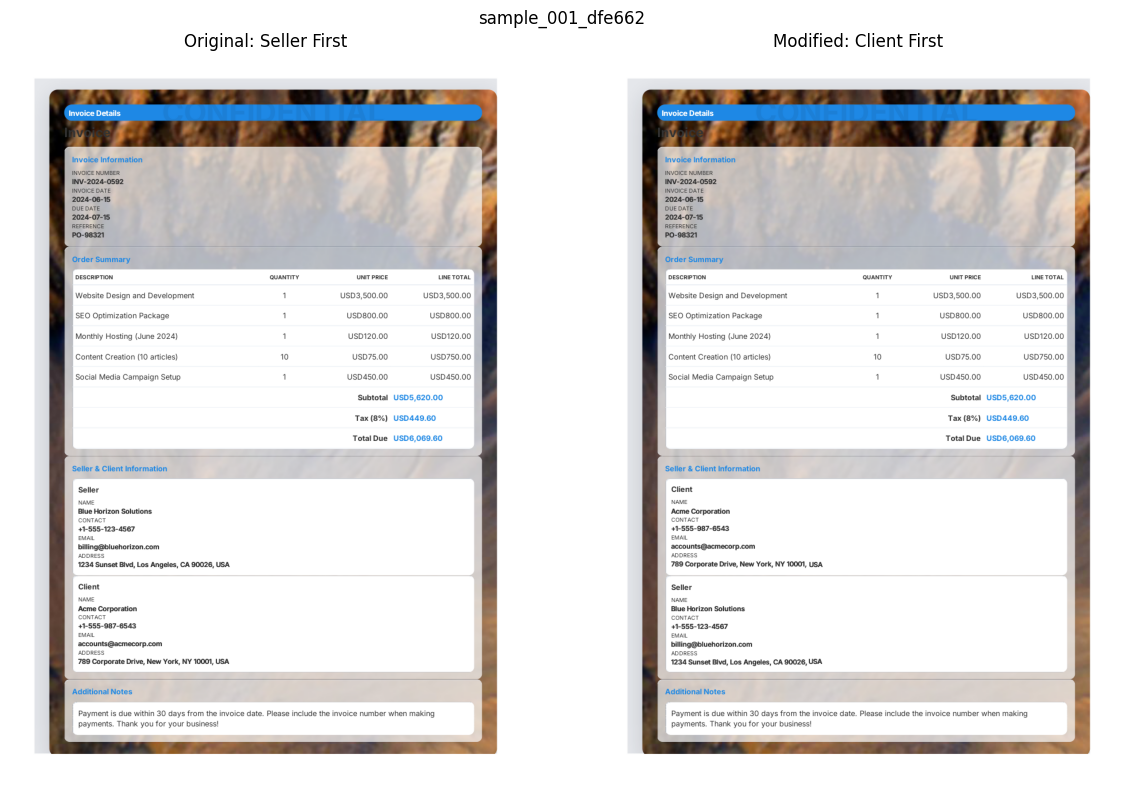

Visually inspect the image: Seller/Client headings and values should move together.
Original invoices: 24 windows, 20 pages
Client-first invoices: 24 windows, 20 pages

PARTY BLOCK PAIRING COVERAGE
Original: 11 {'ok': 11, 'missing_or_extra_entities': 1}
Client-first: 12 {'ok': 12}

MATCHED ORIGINAL VS CLIENT-FIRST RESULTS


,Layout,Method,Invoices,Overall F1,Role F1,Email F1,Invoice Exact Match
0,Original Seller-first,Original LayoutLMv3,12,0.9658,0.9053,0.9167,0.8333
1,Original Seller-first,Two-stage role head,12,0.9810,0.9474,0.9583,0.9167
2,Original Seller-first,First-block heuristic,12,0.9810,0.9474,0.9583,0.9167
3,Synthetic Client-first,Original LayoutLMv3,12,0.7045,0.1875,0.1250,0.0000
4,Synthetic Client-first,Two-stage role head,12,0.9848,0.9583,1.0000,0.8333
5,Synthetic Client-first,First-block heuristic,12,0.6364,0.0000,0.0000,0.0000



PAIR-LEVEL SELLER/CLIENT AUDIT


,Layout,Invoice,True Seller Block,Role-Head Seller Block,Role Head Correct,First-Block Correct,Decision Margin,Block A Heading,Block B Heading
0,Original Seller-first,sample_001_dfe662,0,0,True,True,7.4005,NAME | Seller,NAME | Client
1,Original Seller-first,sample_117_7962c1,0,0,True,True,6.4797,NÁZEV | Prodejce,NÁZEV | Odběratel
2,Original Seller-first,sample_195_e71290,0,0,True,True,7.8685,NÁZEV | Prodejce,NÁZEV | Klient
3,Original Seller-first,sample_237_f3da5c,0,0,True,True,7.2857,NAME | Verkäufer,NAME | Kunde
4,Original Seller-first,sample_238_50b3f5,0,0,True,True,7.4671,NAME | Verkäufer,NAME | Kunde
5,Original Seller-first,sample_240_eb6b17,0,0,True,True,7.1881,NAME | Verkäufer,NAME | Kunde
6,Original Seller-first,sample_288_c59df0,0,0,True,True,7.1046,NAME | Verkäufer,NAME | Kunde
7,Original Seller-first,sample_299_9d5848,0,0,True,True,7.2534,NAME | Verkäufer,NAME | Kunde
8,Original Seller-first,sample_320_a1ee7e,0,0,True,True,7.1663,NAME | Verkäufer,NAME | Kunde
9,Original Seller-first,sample_328_b7ad99,0,0,True,True,7.1140,NAME | Verkäufer,NAME | Kunde


,Pairs,Role_Head_Accuracy,Seller_First_Rule_Accuracy
Layout,,,
Original Seller-first,11,1.0,1.0
Synthetic Client-first,12,1.0,0.0



CLIENT-FIRST EXPERIMENT COMPLETED
Counterfactual invoices: 12
Original/Client-first inference completed.
Original LayoutLMv3 weights unchanged.
Second-stage role-head weights unchanged.
Original gate used without retuning: 0.0
No training.
No test-set evaluation.
No files created.

IMPORTANT: These are synthetic client-first invoices, not independent real-world client-first documents.


In [34]:

# ============================================================
# PROJECT 9: CLIENT-FIRST FULL-PIPELINE EXPERIMENT
#
# Goal:
# Test whether our second-stage role classifier
# really understands Seller/Client relationships.
#
# Original: Seller block first, Client second
# Modified: Client block first, Seller second
#
# Both OCR words/boxes AND page-image regions move.
# Silver labels stay attached to their original words.
#
# Compare:
# 1. Original LayoutLMv3
# 2. Two-stage role head
# 3. Always-first-block-is-Seller heuristic
#
# No training. No test-set evaluation. No files.
# ============================================================

import math
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw
from IPython.display import display

try:
    import pymupdf
except ImportError:
    import fitz as pymupdf


# ============================================================
# 1. CHECK EXISTING NOTEBOOK OBJECTS
# ============================================================

required = [
    "model",
    "processor",
    "val_dataset",
    "try_swap_page",
    "build_pair_features",
    "role_head",
    "feature_scaler",
    "apply_role_correction",
    "selected_gate",
    "id2label_local",
    "label2id_local"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous notebook objects: "
        + ", ".join(missing)
    )

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError("Enable Kaggle GPU.")

VAL_INVOICES = {
    str(r["invoice_id"])
    for r in val_dataset.records
}

VAL_KEYS = {
    (
        str(r["invoice_id"]),
        int(r["page_index"])
    )
    for r in val_dataset.records
}

SOURCE = globals().get(
    "prepared_pages",
    globals().get("strict_pages")
)

if SOURCE is None:
    raise RuntimeError(
        "prepared_pages / strict_pages unavailable."
    )


# ============================================================
# 2. RESTORE ORIGINAL VALIDATION PAGES
# ============================================================

raw_pages = {}

for page in SOURCE:

    key = (
        str(page["invoice_id"]),
        int(page["page_index"])
    )

    if key not in VAL_KEYS:
        continue

    raw_pages[key] = {
        "invoice_id": key[0],
        "page_index": key[1],
        "words": list(page["words"]),
        "boxes": [
            list(map(int, b))
            for b in page["boxes"]
        ],
        "label_ids": [
            int(v)
            for v in page["label_ids"]
        ],
        "pdf": page.get("pdf")
    }

if set(raw_pages) != VAL_KEYS:
    raise RuntimeError(
        "Some validation OCR pages are missing."
    )

if any(
    page["pdf"] is None
    for page in raw_pages.values()
):

    if "page_samples" not in globals():
        raise RuntimeError(
            "PDF paths missing. Need page_samples."
        )

    pdf_lookup = {
        (
            str(p["invoice_id"]),
            int(p["page_index"])
        ): p["pdf"]
        for p in page_samples
    }

    for key, page in raw_pages.items():

        if page["pdf"] is None:
            page["pdf"] = pdf_lookup[key]


print("=" * 65)
print("CLIENT-FIRST GENERALIZATION EXPERIMENT")
print("=" * 65)

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Validation invoices:", len(VAL_INVOICES))
print("Validation pages:", len(raw_pages))
print("Existing role-head gate:", selected_gate)


# ============================================================
# 3. SPATIAL AND IMAGE UTILITIES
# ============================================================

def envelope(boxes):

    return [
        min(b[0] for b in boxes),
        min(b[1] for b in boxes),
        max(b[2] for b in boxes),
        max(b[3] for b in boxes)
    ]


def expand_box(box, padding=1.5):

    return [
        box[0] - padding,
        box[1] - padding,
        box[2] + padding,
        box[3] + padding
    ]


def translate_box(box, dx, dy):

    return [
        box[0] + dx,
        box[1] + dy,
        box[2] + dx,
        box[3] + dy
    ]


def intersects(a, b):

    return (
        min(a[2], b[2]) > max(a[0], b[0])
        and
        min(a[3], b[3]) > max(a[1], b[1])
    )


image_cache = {}


def render_pdf_page(key):

    if key not in image_cache:

        page = raw_pages[key]

        with pymupdf.open(str(page["pdf"])) as doc:

            pix = doc[
                page["page_index"]
            ].get_pixmap(
                matrix=pymupdf.Matrix(1.5, 1.5),
                alpha=False
            )

        image_cache[key] = Image.frombytes(
            "RGB",
            (pix.width, pix.height),
            pix.samples
        )

    return image_cache[key]


# ============================================================
# 4. SWAP ACTUAL IMAGE REGIONS
# ============================================================

def swap_image_regions(
    image,
    original_boxes,
    swapped_boxes
):
    """
    Derive the two translation vectors from
    the accepted geometric block swap.

    Crop the actual Seller/Client raster
    regions and paste at exchanged positions.

    Reject crops intersecting stationary OCR.
    """

    movements = defaultdict(list)

    for i, (old, new) in enumerate(
        zip(original_boxes, swapped_boxes)
    ):

        dx = new[0] - old[0]
        dy = new[1] - old[1]

        if dx == 0 and dy == 0:
            continue

        if (
            new[2] - old[2] != dx
            or new[3] - old[3] != dy
        ):
            return None, "non_translation"

        movements[(dx, dy)].append(i)

    if len(movements) != 2:
        return None, "expected_two_blocks"

    deltas = list(movements)

    if tuple(
        -v for v in deltas[0]
    ) != deltas[1]:

        return None, "non_opposite_moves"

    moved_ids = {
        i
        for indices in movements.values()
        for i in indices
    }

    stationary = (
        set(range(len(original_boxes)))
        - moved_ids
    )

    patches = []

    for (dx, dy), indices in movements.items():

        src = expand_box(
            envelope([
                original_boxes[i]
                for i in indices
            ])
        )

        dst = translate_box(
            src, dx, dy
        )

        if any(
            value < 0 or value > 1000
            for value in src + dst
        ):
            return None, "outside_page"

        # Do not erase or cover stationary text.
        for i in stationary:

            if (
                intersects(src, original_boxes[i])
                or intersects(dst, original_boxes[i])
            ):
                return None, "crop_hits_static_text"

        patches.append((src, dst))

    if intersects(
        patches[0][0],
        patches[1][0]
    ):
        return None, "source_crops_overlap"

    if intersects(
        patches[0][1],
        patches[1][1]
    ):
        return None, "destination_crops_overlap"

    W, H = image.size

    def to_pixels(box):

        return [
            round(box[0] * W / 1000),
            round(box[1] * H / 1000),
            round(box[2] * W / 1000),
            round(box[3] * H / 1000)
        ]

    raster_patches = []

    for src, dst in patches:

        source_rect = to_pixels(src)
        target_rect = to_pixels(dst)

        raster_patches.append((
            source_rect,
            target_rect,
            image.crop(tuple(source_rect))
        ))

    result = image.copy()
    draw = ImageDraw.Draw(result)

    # Erase both source regions.
    for source_rect, target_rect, patch in raster_patches:

        draw.rectangle(
            tuple(source_rect),
            fill=(255, 255, 255)
        )

    # Paste each block at its new position.
    for source_rect, target_rect, patch in raster_patches:

        result.paste(
            patch,
            (
                target_rect[0],
                target_rect[1]
            )
        )

    return result, "ok"


# ============================================================
# 5. PRESERVE CORRECT OCR READING ORDER
# ============================================================

def reorder_swapped_blocks(
    original_page,
    translated_page
):
    """
    Exchange two contiguous OCR block sequences.

    All other words retain their original order.
    Words, boxes and labels move together.

    Noncontiguous/interleaved blocks are rejected.
    """

    movements = defaultdict(list)

    for i, (old, new) in enumerate(
        zip(
            original_page["boxes"],
            translated_page["boxes"]
        )
    ):

        dx = new[0] - old[0]
        dy = new[1] - old[1]

        if dx or dy:
            movements[(dx, dy)].append(i)

    if len(movements) != 2:
        return None, "not_two_moved_blocks"

    chunks = sorted(
        [
            sorted(indices)
            for indices in movements.values()
        ],
        key=lambda indices: indices[0]
    )

    left, right = chunks

    # Avoid synthetic examples whose original
    # OCR order interleaves unrelated words.
    if (
        left[-1] - left[0] + 1 != len(left)
        or right[-1] - right[0] + 1 != len(right)
        or left[-1] >= right[0]
    ):
        return None, "noncontiguous_ocr_blocks"

    n = len(original_page["words"])

    permutation = (
        list(range(left[0]))
        + right
        + list(range(left[-1] + 1, right[0]))
        + left
        + list(range(right[-1] + 1, n))
    )

    if sorted(permutation) != list(range(n)):
        return None, "invalid_permutation"

    return {
        **translated_page,
        "words": [
            translated_page["words"][i]
            for i in permutation
        ],
        "boxes": [
            translated_page["boxes"][i]
            for i in permutation
        ],
        "label_ids": [
            translated_page["label_ids"][i]
            for i in permutation
        ]
    }, "ok"


# ============================================================
# 6. VERIFY TRUE SECTION ORDER
# ============================================================

def actual_first_role(page):

    positions = {}

    for i, label in enumerate(
        page["label_ids"]
    ):

        tag = id2label_local.get(
            int(label), "IGNORE"
        )

        if tag == "B-SELLER_NAME":
            positions.setdefault("SELLER", i)

        elif tag == "B-CLIENT_NAME":
            positions.setdefault("CLIENT", i)

    if set(positions) != {
        "SELLER", "CLIENT"
    }:
        return "UNKNOWN"

    return (
        "CLIENT"
        if positions["CLIENT"] < positions["SELLER"]
        else "SELLER"
    )


def labeled_word_inventory(page):

    def field_name(label):

        tag = id2label_local.get(
            int(label), "IGNORE"
        )

        if tag.startswith(("B-", "I-")):
            return tag[2:]

        return tag

    return Counter(
        (
            word,
            field_name(label)
        )
        for word, label in zip(
            page["words"],
            page["label_ids"]
        )
    )


# ============================================================
# 7. GENERATE SAFE CLIENT-FIRST INVOICES
# ============================================================

accepted = {}
skip_reasons = Counter()

for key, page in sorted(
    raw_pages.items()
):

    translated, reason, details = (
        try_swap_page(page)
    )

    if translated is None:

        skip_reasons[reason] += 1
        continue

    modified, reason = reorder_swapped_blocks(
        page, translated
    )

    if modified is None:

        skip_reasons[reason] += 1
        continue

    if (
        actual_first_role(page) != "SELLER"
        or actual_first_role(modified) != "CLIENT"
    ):

        skip_reasons[
            "not_seller_to_client_first"
        ] += 1

        continue

    # All original labeled words must survive.
    if (
        labeled_word_inventory(page)
        != labeled_word_inventory(modified)
    ):

        skip_reasons[
            "silver_labels_changed"
        ] += 1

        continue

    new_image, reason = swap_image_regions(
        render_pdf_page(key),
        page["boxes"],
        translated["boxes"]
    )

    if new_image is None:

        skip_reasons[reason] += 1
        continue

    # One swapped page per invoice.
    if key[0] in accepted:

        skip_reasons[
            "additional_swap_page"
        ] += 1

        continue

    accepted[key[0]] = {
        "key": key,
        "original": page,
        "modified": modified,
        "original_image": render_pdf_page(key),
        "modified_image": new_image
    }

    skip_reasons["accepted"] += 1


print("\n" + "=" * 65)
print("CLIENT-FIRST SYNTHESIS COVERAGE")
print("=" * 65)

print(
    "Accepted invoices:",
    len(accepted),
    "/",
    len(VAL_INVOICES)
)

print("Reasons:", dict(skip_reasons))

if not accepted:
    raise RuntimeError(
        "No safe client-first invoices could be "
        "generated. Do not force invalid swaps."
    )

if len(accepted) < 5:
    print(
        "WARNING: Very small counterfactual "
        "sample. Results will be exploratory."
    )


# ============================================================
# 8. VISUALIZE THE ACTUAL INVOICE SWAP
# ============================================================

example_id = sorted(accepted)[0]
example = accepted[example_id]

fig, axes = plt.subplots(
    1, 2, figsize=(12, 8)
)

axes[0].imshow(
    example["original_image"]
)

axes[0].set_title(
    "Original: Seller First"
)

axes[1].imshow(
    example["modified_image"]
)

axes[1].set_title(
    "Modified: Client First"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(example_id)
plt.tight_layout()
plt.show()

print(
    "Visually inspect the image: Seller/Client "
    "headings and values should move together."
)


# ============================================================
# 9. PREPARE MATCHED ORIGINAL AND CLIENT-FIRST DATA
# ============================================================

original_documents = {}
client_first_documents = {}

for invoice_id, info in sorted(
    accepted.items()
):

    for key, page in raw_pages.items():

        if key[0] != invoice_id:
            continue

        original_documents[key] = {
            **page,
            "image": render_pdf_page(key)
        }

        if key == info["key"]:

            client_first_documents[key] = {
                **info["modified"],
                "image": info["modified_image"]
            }

        else:

            client_first_documents[key] = {
                **page,
                "image": render_pdf_page(key)
            }

assert (
    set(original_documents)
    == set(client_first_documents)
)


# ============================================================
# 10. CREATE 512-TOKEN INFERENCE WINDOWS
# ============================================================

MAX_TOKENS = 512
OVERLAP_WORDS = 24


def prepare_windows(document_pages):

    windows = []

    for key, page in sorted(
        document_pages.items()
    ):

        words = page["words"]
        boxes = page["boxes"]

        token_counts = [0] * len(words)

        all_tokens = processor.tokenizer(
            words,
            boxes=boxes,
            truncation=False,
            padding=False,
            add_special_tokens=False
        )

        for word_id in all_tokens.word_ids():

            if word_id is not None:
                token_counts[word_id] += 1

        if (
            not words
            or any(
                count == 0 or count > 510
                for count in token_counts
            )
        ):

            raise RuntimeError(
                f"Invalid OCR tokenization: {key}"
            )

        pixel_values = (
            processor.image_processor(
                page["image"],
                return_tensors="pt"
            )["pixel_values"][0]
        )

        start = 0

        while start < len(words):

            end = start
            token_count = 0

            while (
                end < len(words)
                and token_count + token_counts[end]
                <= MAX_TOKENS - 2
            ):

                token_count += token_counts[end]
                end += 1

            if end == start:

                raise RuntimeError(
                    f"Window creation failed: {key}"
                )

            encoding = processor.tokenizer(
                words[start:end],
                boxes=boxes[start:end],
                truncation=False,
                padding="max_length",
                max_length=MAX_TOKENS,
                return_tensors="pt"
            )

            if encoding["input_ids"].shape[1] != 512:

                raise RuntimeError(
                    "A window exceeds 512 tokens."
                )

            windows.append({
                "key": key,
                "start": start,
                "word_ids": encoding.word_ids(0),
                "input_ids": encoding[
                    "input_ids"
                ][0],
                "attention_mask": encoding[
                    "attention_mask"
                ][0],
                "bbox": encoding["bbox"][0],
                "pixel_values": pixel_values
            })

            if end == len(words):
                break

            start = max(
                start + 1,
                end - OVERLAP_WORDS
            )

    return windows


# ============================================================
# 11. RE-RUN ORIGINAL LAYOUTLMv3
# ============================================================

@torch.inference_mode()
def infer_documents(document_pages, description):

    windows = prepare_windows(
        document_pages
    )

    predictions = {}

    for key, page in document_pages.items():

        predictions[key] = {
            "words": page["words"],
            "boxes": page["boxes"],
            "logits": np.full(
                (
                    len(page["words"]),
                    len(id2label_local)
                ),
                np.nan,
                dtype=np.float32
            )
        }

    model.eval()

    for batch_start in range(
        0, len(windows), 2
    ):

        batch = windows[
            batch_start:batch_start + 2
        ]

        inputs = {
            name: torch.stack([
                item[name]
                for item in batch
            ]).to(DEVICE)
            for name in (
                "input_ids",
                "attention_mask",
                "bbox",
                "pixel_values"
            )
        }

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            logits = model(
                **inputs
            ).logits.float().cpu().numpy()

        for row, item in enumerate(batch):

            page = predictions[
                item["key"]
            ]

            visited = set()

            for token_idx, word_idx in enumerate(
                item["word_ids"]
            ):

                if (
                    word_idx is None
                    or word_idx in visited
                ):
                    continue

                visited.add(word_idx)

                global_word = (
                    item["start"]
                    + int(word_idx)
                )

                # First covering window owns word.
                if not np.isfinite(
                    page["logits"][global_word, 0]
                ):

                    page["logits"][
                        global_word
                    ] = logits[row, token_idx]

    for key, page in predictions.items():

        if not np.isfinite(
            page["logits"]
        ).all():

            raise RuntimeError(
                f"Incomplete inference: {key}"
            )

    print(
        f"{description}: "
        f"{len(windows)} windows, "
        f"{len(predictions)} pages"
    )

    return predictions


original_device = next(
    model.parameters()
).device

model.to(DEVICE)

try:

    original_logits = infer_documents(
        original_documents,
        "Original invoices"
    )

    client_first_logits = infer_documents(
        client_first_documents,
        "Client-first invoices"
    )

finally:

    model.to(original_device)
    torch.cuda.empty_cache()


# ============================================================
# 12. APPLY SECOND-STAGE CLASSIFIER
# ============================================================

def run_three_methods(logit_pages):

    pairs, reasons = build_pair_features(
        logit_pages,
        require_targets=False
    )

    for pair in pairs:

        features = feature_scaler.transform(
            pair["difference"][None, :]
        )

        margin = float(
            role_head.decision_function(
                features
            )[0]
        )

        pair["margin"] = margin

        pair["seller_block"] = (
            0 if margin >= 0 else 1
        )

    # Method A: original LayoutLMv3
    baseline = {
        key: page["logits"]
        .argmax(axis=1)
        .copy()
        for key, page in logit_pages.items()
    }

    # Method B: trained role classifier,
    # using already-selected fixed gate.
    corrected, _ = apply_role_correction(
        logit_pages,
        pairs,
        selected_gate
    )

    # Method C: always first block Seller.
    first_block_pairs = [
        {
            **pair,
            "margin": 1e6,
            "seller_block": 0
        }
        for pair in pairs
    ]

    first_rule, _ = apply_role_correction(
        logit_pages,
        first_block_pairs,
        0.0
    )

    methods = {
        "Original LayoutLMv3": baseline,
        "Two-stage role head": corrected,
        "First-block heuristic": first_rule
    }

    return methods, pairs, reasons


original_outputs, original_pairs, original_reasons = (
    run_three_methods(original_logits)
)

client_outputs, client_pairs, client_reasons = (
    run_three_methods(client_first_logits)
)

print("\n" + "=" * 65)
print("PARTY BLOCK PAIRING COVERAGE")
print("=" * 65)

print(
    "Original:",
    len(original_pairs),
    dict(original_reasons)
)

print(
    "Client-first:",
    len(client_pairs),
    dict(client_reasons)
)


# ============================================================
# 13. STRICT BIO EVALUATION
# ============================================================

def extract_strict_spans(
    position_map,
    side
):

    result = set()

    active = None
    previous = None

    for pos in sorted(position_map):

        if (
            previous is not None
            and pos != previous + 1
        ):

            if active is not None:

                result.add((
                    active[0],
                    active[1],
                    previous + 1
                ))

            active = None

        tag = id2label_local[
            int(position_map[pos][side])
        ]

        if tag.startswith("B-"):

            if active is not None:

                result.add((
                    active[0],
                    active[1],
                    pos
                ))

            active = (
                tag[2:], pos
            )

        elif (
            tag.startswith("I-")
            and active is not None
            and tag[2:] == active[0]
        ):
            pass

        else:

            if active is not None:

                result.add((
                    active[0],
                    active[1],
                    pos
                ))

            active = None

        previous = pos

    if active is not None:

        result.add((
            active[0],
            active[1],
            previous + 1
        ))

    return result


def evaluate_documents(
    documents,
    predictions,
    selected_fields=None
):

    TP = FP = FN = 0

    gold_by_invoice = defaultdict(set)
    pred_by_invoice = defaultdict(set)

    for key, page in documents.items():

        position_map = {
            i: (
                int(gold),
                int(predictions[key][i])
            )
            for i, gold in enumerate(
                page["label_ids"]
            )
            if gold != -100
        }

        gold_spans = extract_strict_spans(
            position_map, 0
        )

        pred_spans = extract_strict_spans(
            position_map, 1
        )

        if selected_fields is not None:

            gold_spans = {
                span for span in gold_spans
                if span[0] in selected_fields
            }

            pred_spans = {
                span for span in pred_spans
                if span[0] in selected_fields
            }

        TP += len(
            gold_spans & pred_spans
        )

        FP += len(
            pred_spans - gold_spans
        )

        FN += len(
            gold_spans - pred_spans
        )

        for span in gold_spans:

            gold_by_invoice[
                key[0]
            ].add(
                (key[1], *span)
            )

        for span in pred_spans:

            pred_by_invoice[
                key[0]
            ].add(
                (key[1], *span)
            )

    invoice_ids = {
        key[0]
        for key in documents
    }

    exact_match = sum(
        gold_by_invoice[i]
        == pred_by_invoice[i]
        for i in invoice_ids
    ) / len(invoice_ids)

    denominator = (
        2 * TP + FP + FN
    )

    return {
        "F1": (
            2 * TP / denominator
            if denominator else 0
        ),
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Invoice Exact Match": exact_match,
        "Invoices": len(invoice_ids)
    }


# ============================================================
# 14. COMPARE ORIGINAL VS CLIENT-FIRST
# ============================================================

ROLE_FIELDS_AUDIT = {
    "SELLER_NAME",
    "SELLER_EMAIL",
    "CLIENT_NAME",
    "CLIENT_EMAIL"
}

EMAIL_FIELDS_AUDIT = {
    "SELLER_EMAIL",
    "CLIENT_EMAIL"
}

results = []

for layout, documents, output_dict in [
    (
        "Original Seller-first",
        original_documents,
        original_outputs
    ),
    (
        "Synthetic Client-first",
        client_first_documents,
        client_outputs
    )
]:

    for method, predictions in output_dict.items():

        overall = evaluate_documents(
            documents,
            predictions
        )

        roles = evaluate_documents(
            documents,
            predictions,
            ROLE_FIELDS_AUDIT
        )

        emails = evaluate_documents(
            documents,
            predictions,
            EMAIL_FIELDS_AUDIT
        )

        results.append({
            "Layout": layout,
            "Method": method,
            "Invoices": overall["Invoices"],
            "Overall F1": overall["F1"],
            "Role F1": roles["F1"],
            "Email F1": emails["F1"],
            "Invoice Exact Match":
                overall["Invoice Exact Match"]
        })


comparison_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("MATCHED ORIGINAL VS CLIENT-FIRST RESULTS")
print("=" * 65)

display(
    comparison_df.round(4)
)


# ============================================================
# 15. VERIFY PAIR-LEVEL TRUE ROLES
# ============================================================

def ground_truth_block_role(
    block,
    documents
):
    """
    Silver labels are used ONLY for evaluation.
    Never supplied to the role head.
    """

    roles = []

    for kind in ("name", "email"):

        span = block[kind]

        labels = documents[
            span["page_key"]
        ]["label_ids"][
            span["start"]:span["end"]
        ]

        tags = [
            id2label_local.get(
                int(label), "IGNORE"
            )
            for label in labels
        ]

        votes = Counter(
            tag[2:].split("_", 1)[0]
            for tag in tags
            if (
                tag.startswith(("B-", "I-"))
                and tag[2:] in ROLE_FIELDS_AUDIT
            )
        )

        role = (
            votes.most_common(1)[0][0]
            if votes else None
        )

        if (
            role is None
            or votes[role] < max(
                1,
                math.ceil(0.6 * len(labels))
            )
        ):
            return None

        roles.append(role)

    if len(set(roles)) != 1:
        return None

    return roles[0]


audit_rows = []

for layout, pairs, documents in [
    (
        "Original Seller-first",
        original_pairs,
        original_documents
    ),
    (
        "Synthetic Client-first",
        client_pairs,
        client_first_documents
    )
]:

    for pair in pairs:

        true_roles = [
            ground_truth_block_role(
                block,
                documents
            )
            for block in pair["blocks"]
        ]

        if true_roles not in (
            ["SELLER", "CLIENT"],
            ["CLIENT", "SELLER"]
        ):
            continue

        true_seller_idx = (
            true_roles.index("SELLER")
        )

        audit_rows.append({
            "Layout": layout,
            "Invoice": pair["invoice"],
            "True Seller Block": true_seller_idx,
            "Role-Head Seller Block":
                pair["seller_block"],
            "Role Head Correct": (
                pair["seller_block"]
                == true_seller_idx
            ),
            "First-Block Correct": (
                true_seller_idx == 0
            ),
            "Decision Margin": pair["margin"],
            "Block A Heading":
                pair["blocks"][0]["heading"],
            "Block B Heading":
                pair["blocks"][1]["heading"]
        })


print("\n" + "=" * 65)
print("PAIR-LEVEL SELLER/CLIENT AUDIT")
print("=" * 65)

if audit_rows:

    audit_df = pd.DataFrame(
        audit_rows
    )

    display(audit_df.round(4))

    display(
        audit_df.groupby("Layout").agg(
            Pairs=("Invoice", "count"),
            Role_Head_Accuracy=(
                "Role Head Correct", "mean"
            ),
            Seller_First_Rule_Accuracy=(
                "First-Block Correct", "mean"
            )
        ).round(4)
    )

else:

    print(
        "No reliable predicted block pairs "
        "could be evaluated."
    )


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("CLIENT-FIRST EXPERIMENT COMPLETED")
print("=" * 65)

print(
    "Counterfactual invoices:",
    len(accepted)
)

print(
    "Original/Client-first inference completed."
)

print(
    "Original LayoutLMv3 weights unchanged."
)

print(
    "Second-stage role-head weights unchanged."
)

print(
    "Original gate used without retuning:",
    selected_gate
)

print("No training.")
print("No test-set evaluation.")
print("No files created.")

print(
    "\nIMPORTANT: These are synthetic "
    "client-first invoices, not independent "
    "real-world client-first documents."
)


FAILURE PATTERN DISCOVERY EXPERIMENT
Validation Invoices: 19
Validation Pages: 33
Second-stage Gate: 0.0

INVOICE-LEVEL FAILURE IDENTIFICATION
Fully Correct: 16
Failed: 3


,Invoice,Status,Stage1 Exact,Stage2 Exact,GT Entities,TP,FP,FN,Stage2 Changed Words,Block Pair Found
0,sample_100_e35ba0,FAILED,False,False,11,11,1,0,0,False
1,sample_249_c8c332,FAILED,False,False,11,10,1,1,0,False
2,sample_736_72cbb8,FAILED,False,False,11,8,2,3,0,False
3,sample_001_dfe662,CORRECT,True,True,11,11,0,0,0,True
4,sample_021_f4c5ee,CORRECT,True,True,11,11,0,0,0,False
5,sample_031_1feb50,CORRECT,True,True,11,11,0,0,0,False
6,sample_036_ea063d,CORRECT,True,True,11,11,0,0,0,True
7,sample_117_7962c1,CORRECT,True,True,11,11,0,0,0,True
8,sample_126_24d8fa,CORRECT,True,True,11,11,0,0,0,True
9,sample_195_e71290,CORRECT,False,True,11,11,0,0,4,True



EXACT ERRORS IN THE 3 FAILED INVOICES


,Invoice,Page,GT Field,GT Text,Stage1 Predicted Field,Stage2 Predicted Field,Stage2 Predicted Text,Error Type,Context
0,sample_100_e35ba0,2,NONE,,N/A,CLIENT_NAME,First National Bank,EXTRA_PREDICTION,TOTAL Payment Information Bank Details BANK NAME First National Bank IBAN
1,sample_249_c8c332,2,SELLER_EMAIL,kontakt@mueller-partner.de,CLIENT_EMAIL,CLIENT_EMAIL,kontakt@mueller-partner.de,SELLER_CLIENT_ROLE_CONFUSION,"kontakt@mueller-partner.de ADRESSE Hauptstraße 45, 10115 Berlin, Deutschland Kunde"
2,sample_736_72cbb8,1,CLIENT_NAME,KANCELÁRIA ARCHITEKTA,NONE,NONE,,MISSED_ENTITY,"12, 821 09 Bratislava, Slovensko Klient NÁZOV KANCELÁRIA ARCHITEKTA KONTAKT +421 902 654 321 EMAIL kontakt..."
3,sample_736_72cbb8,1,SELLER_EMAIL,info@softverove-riesenia.sk,CLIENT_EMAIL,CLIENT_EMAIL,info@softverove-riesenia.sk,SELLER_CLIENT_ROLE_CONFUSION,"s.r.o. KONTAKT +421 905 123 456 EMAIL info@softverove-riesenia.sk ADRESA Mlynské nivy 12, 821 09 Bratislava,"
4,sample_736_72cbb8,1,SELLER_NAME,Softvérové riešenia s.r.o.,SELLER_NAME,SELLER_NAME,Softvérové riešenia,BOUNDARY_ERROR,Informácie o predajcovi a klientovi Predajca NÁZOV Softvérové riešenia s.r.o. KONTAKT +421 905 123 456 EMA...



ERROR TYPE DISTRIBUTION


...


NOTE: p-values are exploratory and unadjusted. With only 3 failures, avoid causal conclusions.

HEADING AND LAYOUT PATTERNS BY INVOICE


,Invoice,Status,Pages,Block Pair Available,Pairing Reason,Seller Heading,Client Heading,Seller Heading Train Similarity,Client Heading Train Similarity
0,sample_100_e35ba0,FAILED,3,0,missing_or_extra_entities,SELLER NAME | Seller & Client Info,CLIENT NAME | BrightTech Solutions Ltd.,0.610169,0.537313
1,sample_249_c8c332,FAILED,2,0,distant_or_cross_page_pair,NAME | Verkäufer,NAME | Kunde,1.000000,1.000000
2,sample_736_72cbb8,FAILED,2,0,missing_or_extra_entities,NÁZOV | Predajca,NÁZOV | Klient,1.000000,1.000000
3,sample_001_dfe662,CORRECT,1,1,ok,NAME | Seller,NAME | Client,1.000000,1.000000
4,sample_021_f4c5ee,CORRECT,1,0,ambiguous_pairing,SELLER NAME | Seller & Client Information,Bright Solutions Ltd. | CLIENT NAME,0.757576,0.433333
5,sample_031_1feb50,CORRECT,2,0,distant_or_cross_page_pair,NAME | Seller,NAME | Client,1.000000,1.000000
6,sample_036_ea063d,CORRECT,2,1,ok,NAME | Seller,NAME | Client,1.000000,1.000000
7,sample_117_7962c1,CORRECT,1,1,ok,NÁZEV | Prodejce,NÁZEV | Odběratel,1.000000,1.000000
8,sample_126_24d8fa,CORRECT,1,1,ok,NÁZEV | Prodávající,NÁZEV | Odběratel,1.000000,1.000000
9,sample_195_e71290,CORRECT,2,1,ok,NÁZEV | Prodejce,NÁZEV | Klient,1.000000,1.000000



LIKELY FAILURE STAGE FOR EACH INVOICE


,Invoice,Likely Failure Category,Pair Found,Stage1 Exact,Stage2 Exact,Party GT Misses,Other GT Misses,Stage2 Changed Words
0,sample_100_e35ba0,BLOCK PAIRING / COVERAGE FAILURE,False,False,False,0,0,0
1,sample_249_c8c332,BLOCK PAIRING / COVERAGE FAILURE,False,False,False,1,0,0
2,sample_736_72cbb8,BLOCK PAIRING / COVERAGE FAILURE,False,False,False,3,0,0



VISUAL INSPECTION OF FAILED INVOICES


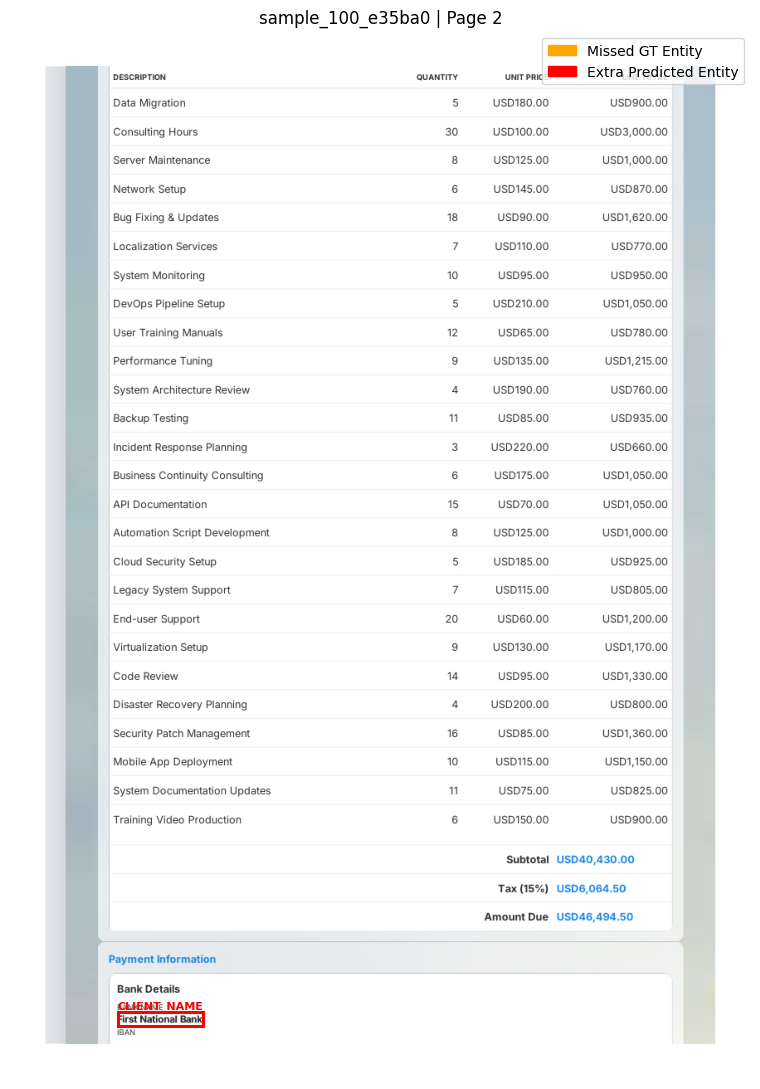

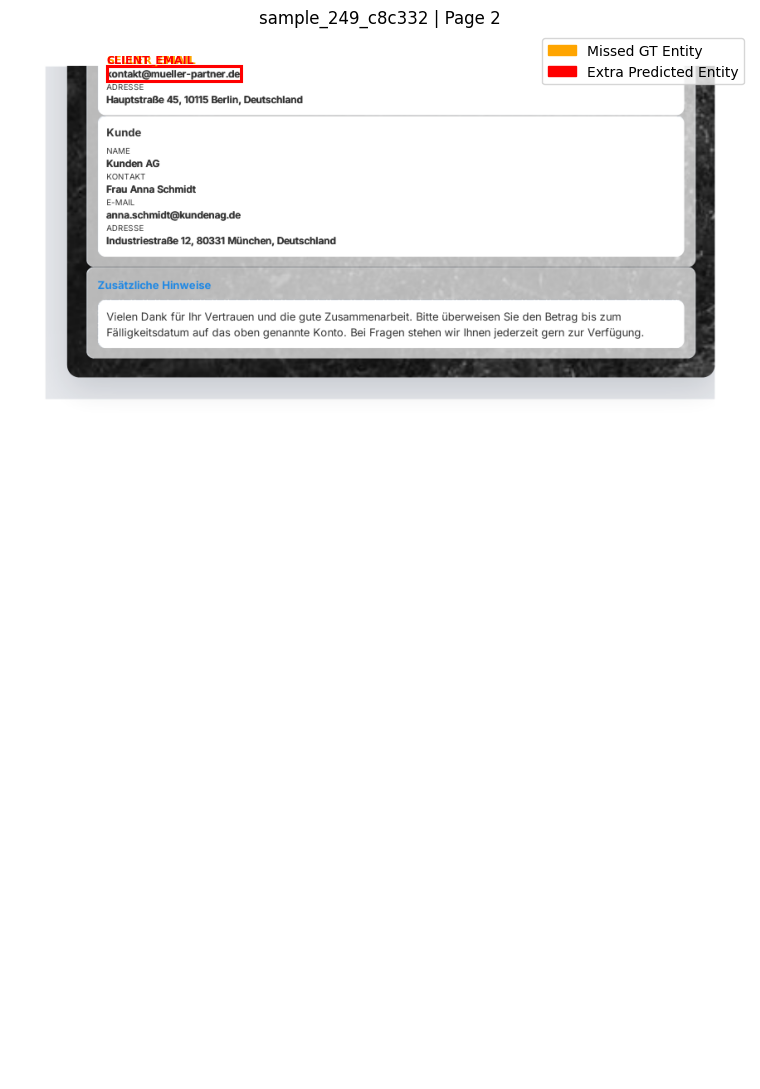

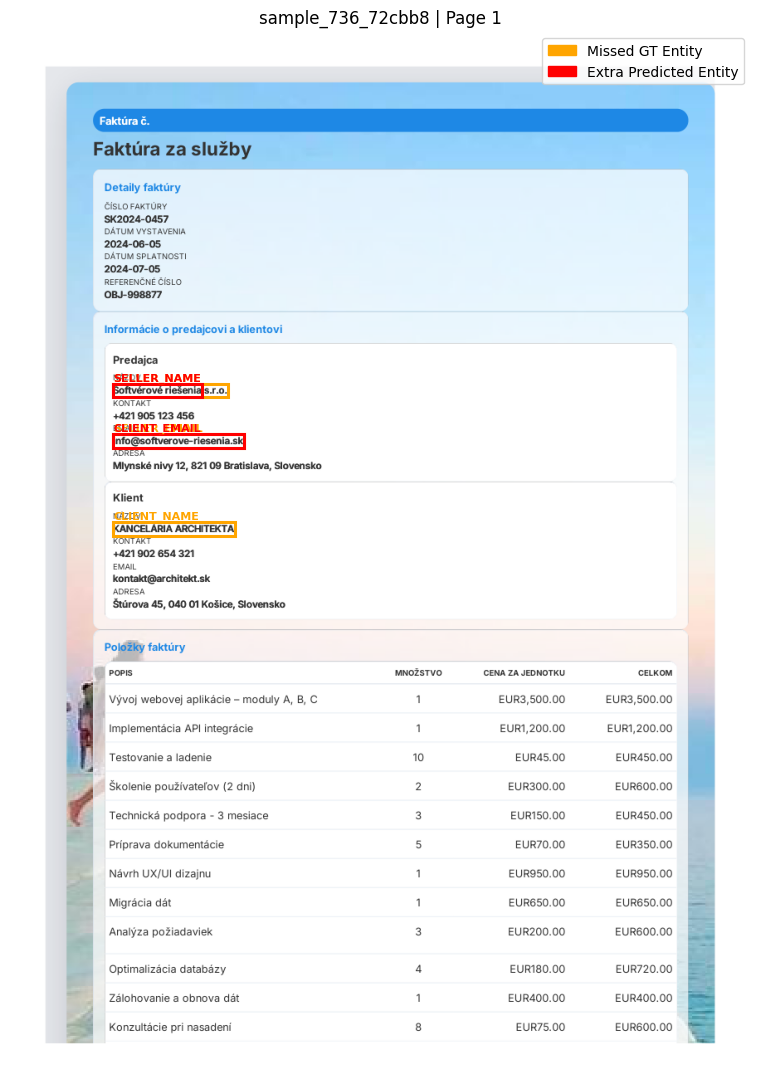


FAILURE PATTERN ANALYSIS COMPLETED
Correct Invoices: 16
Failed Invoices: 3

Failed Invoice IDs:
 - sample_100_e35ba0
 - sample_249_c8c332
 - sample_736_72cbb8

Most different measured features:


,Feature,Correct Mean,Failed Mean,Standardized Difference,Exploratory Permutation p
3,Block Pair Available,0.8125,0.0000,-1.7013,0.0206
5,Client Name-Email Distance,56.6033,73.9640,1.0384,0.0609
1,OCR Words,175.0000,254.6667,1.0332,0.1011
8,Minimum GT Role Margin,1.3638,0.3184,-1.0106,0.1115
7,Mean GT Role Margin,2.4010,1.8884,-0.9227,0.1465
0,Pages,1.6250,2.3333,1.0841,0.1465



No training performed.
No new model inference.
No test-set evaluation.
No files created.

IMPORTANT:
This experiment identifies associations and candidate failure mechanisms, not definitive causes.


In [35]:

# ============================================================
# PROJECT 9: WHY ARE 3 OF 19 INVOICES STILL WRONG?
#
# Failure-pattern discovery:
# 1. Reproduce 16/19 exact match
# 2. Find every incorrect field and error type
# 3. Determine whether stage 1 or stage 2 failed
# 4. Audit block-pairing coverage
# 5. Compare layout, OCR, headings and confidence
# 6. Check heading similarity to OOF training data
# 7. Exploratory exact permutation comparisons
# 8. Visualize failed invoice regions
#
# NO training, NO inference, NO test-set usage.
# NO output files.
# ============================================================

import numpy as np
import pandas as pd
import unicodedata
import difflib
from collections import defaultdict, Counter
from itertools import combinations
from IPython.display import display

# ============================================================
# 1. VERIFY PREVIOUS EXPERIMENT OBJECTS
# ============================================================

required = [
    "validation_pages",
    "page_lookup",
    "val_supervision",
    "val_pairs",
    "role_head",
    "feature_scaler",
    "selected_gate",
    "apply_role_correction",
    "id2label_local",
    "label2id_local"
]

missing = [k for k in required if k not in globals()]

if missing:
    raise RuntimeError(
        f"Missing: {missing}. "
        "Run the previous Two-Stage Pipeline cell."
    )

PARTY_FIELDS = {
    "SELLER_NAME", "CLIENT_NAME",
    "SELLER_EMAIL", "CLIENT_EMAIL"
}

all_pages = sorted(validation_pages)

all_invoices = sorted({
    key[0] for key in all_pages
})

print("=" * 70)
print("FAILURE PATTERN DISCOVERY EXPERIMENT")
print("=" * 70)

print("Validation Invoices:", len(all_invoices))
print("Validation Pages:", len(all_pages))
print("Second-stage Gate:", selected_gate)


# ============================================================
# 2. RECONSTRUCT BASELINE AND CORRECTED PREDICTIONS
# ============================================================

baseline_tags = {
    key: page["logits"]
    .argmax(axis=1).astype(int)
    for key, page in validation_pages.items()
}

scored_pairs = []
pair_lookup = {}

for pair in val_pairs:

    X = np.asarray(
        pair["difference"],
        dtype=np.float32
    ).reshape(1, -1)

    score = float(
        role_head.decision_function(
            feature_scaler.transform(X)
        )[0]
    )

    updated = {
        **pair,
        "margin": score,
        "seller_block": (
            0 if score >= 0 else 1
        )
    }

    scored_pairs.append(updated)
    pair_lookup[pair["invoice"]] = updated

corrected_tags, changed_positions = (
    apply_role_correction(
        validation_pages,
        scored_pairs,
        selected_gate
    )
)


# ============================================================
# 3. STRICT BIO SPAN EXTRACTION
# ============================================================

def extract_spans_for_page(page_key, labels):

    positions = sorted(
        val_supervision[page_key]
    )

    result = set()
    active = None
    previous = None

    def close(end):
        nonlocal active

        if active is not None:
            result.add((
                active[0],
                active[1],
                end
            ))
            active = None

    for pos in positions:

        if previous is not None and pos != previous + 1:
            close(previous + 1)

        tag = id2label_local[int(labels[pos])]

        if tag.startswith("B-"):

            close(pos)
            active = (tag[2:], pos)

        elif (
            tag.startswith("I-")
            and active is not None
            and active[0] == tag[2:]
        ):
            pass

        else:
            close(pos)

        previous = pos

    if previous is not None:
        close(previous + 1)

    return result


gold_docs = defaultdict(set)
baseline_docs = defaultdict(set)
corrected_docs = defaultdict(set)

for key in all_pages:

    invoice, page_index = key

    gold = page_lookup[key]["gold"]

    if len(gold) != len(validation_pages[key]["words"]):
        raise RuntimeError(
            f"Word alignment mismatch: {key}"
        )

    maps = [
        (gold_docs, gold),
        (baseline_docs, baseline_tags[key]),
        (corrected_docs, corrected_tags[key])
    ]

    for destination, labels in maps:

        spans = extract_spans_for_page(
            key, labels
        )

        destination[invoice].update(
            (page_index, *span)
            for span in spans
        )


# ============================================================
# 4. REPRODUCE INVOICE EXACT MATCH
# ============================================================

invoice_rows = []

for invoice in all_invoices:

    gt = gold_docs[invoice]
    before = baseline_docs[invoice]
    after = corrected_docs[invoice]

    tp = len(gt & after)
    fp = len(after - gt)
    fn = len(gt - after)

    stage2_changed = sum(
        int(np.count_nonzero(
            baseline_tags[key] != corrected_tags[key]
        ))
        for key in all_pages
        if key[0] == invoice
    )

    invoice_rows.append({
        "Invoice": invoice,
        "Status": (
            "CORRECT" if gt == after
            else "FAILED"
        ),
        "Stage1 Exact": gt == before,
        "Stage2 Exact": gt == after,
        "GT Entities": len(gt),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Stage2 Changed Words": stage2_changed,
        "Block Pair Found": invoice in pair_lookup
    })

invoice_df = pd.DataFrame(invoice_rows)

failed_ids = invoice_df.loc[
    invoice_df["Status"] == "FAILED",
    "Invoice"
].tolist()

correct_ids = invoice_df.loc[
    invoice_df["Status"] == "CORRECT",
    "Invoice"
].tolist()

print("\n" + "=" * 70)
print("INVOICE-LEVEL FAILURE IDENTIFICATION")
print("=" * 70)

print("Fully Correct:", len(correct_ids))
print("Failed:", len(failed_ids))

display(
    invoice_df.sort_values(
        ["Status", "Invoice"],
        ascending=[False, True]
    ).reset_index(drop=True)
)

if len(correct_ids) != 16 or len(failed_ids) != 3:
    raise RuntimeError(
        "Expected 16 correct and 3 failed invoices. "
        "Previous notebook objects may have changed."
    )


# ============================================================
# 5. FIELD-LEVEL ERROR CLASSIFICATION
# ============================================================

def span_text(invoice, span):

    page_idx, field, start, end = span

    words = validation_pages[
        (invoice, page_idx)
    ]["words"]

    return " ".join(
        words[start:end]
    )


def span_context(invoice, span, radius=7):

    page_idx, field, start, end = span

    words = validation_pages[
        (invoice, page_idx)
    ]["words"]

    return " ".join(
        words[
            max(0, start - radius):
            min(len(words), end + radius)
        ]
    )


def overlap_size(a, b):

    if a[0] != b[0]:
        return 0

    return max(
        0,
        min(a[3], b[3])
        - max(a[2], b[2])
    )


def best_overlap(target, candidates):

    overlapping = [
        span for span in candidates
        if overlap_size(target, span) > 0
    ]

    if not overlapping:
        return None

    return max(
        overlapping,
        key=lambda span: overlap_size(
            target, span
        )
    )


def classify_error(gt, pred):

    if pred is None:
        return "MISSED_ENTITY"

    true_field = gt[1]
    pred_field = pred[1]

    if true_field == pred_field:
        return "BOUNDARY_ERROR"

    true_suffix = true_field.split("_")[-1]
    pred_suffix = pred_field.split("_")[-1]

    if (
        true_suffix == pred_suffix
        and true_field in PARTY_FIELDS
        and pred_field in PARTY_FIELDS
    ):
        return "SELLER_CLIENT_ROLE_CONFUSION"

    return "WRONG_CLASS"


error_rows = []

for invoice in failed_ids:

    gt = gold_docs[invoice]
    after = corrected_docs[invoice]
    before = baseline_docs[invoice]

    missed = sorted(gt - after)
    extra = sorted(after - gt)

    accounted_extra = set()

    for span in missed:

        competing = best_overlap(span, extra)
        stage1_competing = best_overlap(
            span, before
        )

        if competing is not None:
            accounted_extra.add(competing)

        error_rows.append({
            "Invoice": invoice,
            "Page": span[0] + 1,
            "GT Field": span[1],
            "GT Text": span_text(invoice, span),
            "Stage1 Predicted Field": (
                stage1_competing[1]
                if stage1_competing else "NONE"
            ),
            "Stage2 Predicted Field": (
                competing[1]
                if competing else "NONE"
            ),
            "Stage2 Predicted Text": (
                span_text(invoice, competing)
                if competing else ""
            ),
            "Error Type": classify_error(
                span, competing
            ),
            "Context": span_context(
                invoice, span
            )
        })

    for span in extra:

        if span in accounted_extra:
            continue

        error_rows.append({
            "Invoice": invoice,
            "Page": span[0] + 1,
            "GT Field": "NONE",
            "GT Text": "",
            "Stage1 Predicted Field": "N/A",
            "Stage2 Predicted Field": span[1],
            "Stage2 Predicted Text":
                span_text(invoice, span),
            "Error Type": "EXTRA_PREDICTION",
            "Context": span_context(
                invoice, span
            )
        })

errors_df = pd.DataFrame(error_rows)

print("\n" + "=" * 70)
print("EXACT ERRORS IN THE 3 FAILED INVOICES")
print("=" * 70)

with pd.option_context(
    "display.max_colwidth", 110,
    "display.max_columns", None
):
    display(errors_df)

print("\nERROR TYPE DISTRIBUTION")

if not errors_df.empty:
    display(
        errors_df["Error Type"]
        .value_counts()
        .to_frame("Count")
    )


# ============================================================
# 6. INSPECT BLOCK PAIRING FAILURE
# ============================================================

pairing_reasons = {}

for invoice in all_invoices:

    if invoice in pair_lookup:
        pairing_reasons[invoice] = "ok"

    elif (
        "construct_party_blocks" in globals()
        and callable(construct_party_blocks)
    ):
        try:
            _, reason = construct_party_blocks(
                validation_pages,
                invoice
            )
            pairing_reasons[invoice] = reason

        except Exception as e:
            pairing_reasons[invoice] = (
                "CHECK_FAILED: "
                + type(e).__name__
            )

    else:
        pairing_reasons[invoice] = "UNAVAILABLE"


pair_audit = invoice_df[
    [
        "Invoice", "Status",
        "Stage1 Exact", "Stage2 Exact",
        "Block Pair Found",
        "Stage2 Changed Words"
    ]
].copy()

pair_audit["Pairing Reason"] = (
    pair_audit["Invoice"].map(
        pairing_reasons
    )
)

pair_audit["Role-Head Absolute Margin"] = (
    pair_audit["Invoice"].map({
        inv: abs(pair["margin"])
        for inv, pair in pair_lookup.items()
    })
)

print("\n" + "=" * 70)
print("STAGE-1 VS STAGE-2 FAILURE DIAGNOSIS")
print("=" * 70)

display(
    pair_audit.sort_values(
        ["Status", "Invoice"],
        ascending=[False, True]
    )
)

print("\nPAIRING REASON VS SUCCESS")

display(
    pd.crosstab(
        pair_audit["Pairing Reason"],
        pair_audit["Status"]
    )
)


# ============================================================
# 7. GEOMETRY AND CONFIDENCE FEATURES
# ============================================================

def get_field_span(invoice, field):

    candidates = [
        span
        for span in gold_docs[invoice]
        if span[1] == field
    ]

    if not candidates:
        return None

    return sorted(candidates)[0]


def bbox_of_span(invoice, span):

    if span is None:
        return None

    page_idx, field, start, end = span

    boxes = np.asarray(
        validation_pages[
            (invoice, page_idx)
        ]["boxes"][start:end],
        dtype=float
    )

    if len(boxes) == 0:
        return None

    return [
        boxes[:, 0].min(),
        boxes[:, 1].min(),
        boxes[:, 2].max(),
        boxes[:, 3].max()
    ]


def center_of_box(box):

    return (
        (box[0] + box[2]) / 2,
        (box[1] + box[3]) / 2
    )


def span_distance(invoice, span_a, span_b):

    if (
        span_a is None or span_b is None
        or span_a[0] != span_b[0]
    ):
        return np.nan

    box_a = bbox_of_span(invoice, span_a)
    box_b = bbox_of_span(invoice, span_b)

    ax, ay = center_of_box(box_a)
    bx, by = center_of_box(box_b)

    return float(
        np.hypot(ax - bx, ay - by)
    )


def get_heading_near_name(invoice, name_span):

    if name_span is None:
        return ""

    page_idx, field, start, end = name_span

    page = validation_pages[
        (invoice, page_idx)
    ]

    box = bbox_of_span(
        invoice, name_span
    )

    descriptor = {
        "start": start,
        "end": end,
        "box": box
    }

    # Reuse original two-stage heading extraction.
    if (
        "nearest_heading_text" in globals()
        and callable(nearest_heading_text)
    ):
        return nearest_heading_text(
            descriptor, page
        )

    # Fallback: preceding OCR context.
    return " ".join(
        page["words"][
            max(0, start - 9):start
        ]
    )


def normalize_heading(text):

    text = unicodedata.normalize(
        "NFKD", str(text).casefold()
    )

    return "".join(
        c for c in text
        if not unicodedata.combining(c)
    ).strip()


# ============================================================
# 8. TRAINING HEADING PATTERN REFERENCE
# ============================================================

training_headings = {
    "SELLER": set(),
    "CLIENT": set()
}

if "train_pairs" in globals():

    for pair in train_pairs:

        if pair.get("target") not in (0, 1):
            continue

        seller_idx = (
            0 if pair["target"] == 1
            else 1
        )

        client_idx = 1 - seller_idx

        for role, block_idx in [
            ("SELLER", seller_idx),
            ("CLIENT", client_idx)
        ]:

            heading = normalize_heading(
                pair["blocks"][block_idx]["heading"]
            )

            if heading:
                training_headings[role].add(heading)


def heading_similarity(text, role):

    reference = training_headings[role]

    text = normalize_heading(text)

    if not text or not reference:
        return np.nan

    return max(
        difflib.SequenceMatcher(
            None, text, known
        ).ratio()
        for known in reference
    )


# ============================================================
# 9. BUILD INVOICE-WISE PATTERN FEATURES
# ============================================================

feature_rows = []

for invoice in all_invoices:

    invoice_pages = [
        key for key in all_pages
        if key[0] == invoice
    ]

    page_count = len(invoice_pages)

    total_words = sum(
        len(validation_pages[key]["words"])
        for key in invoice_pages
    )

    seller_name = get_field_span(
        invoice, "SELLER_NAME"
    )

    seller_email = get_field_span(
        invoice, "SELLER_EMAIL"
    )

    client_name = get_field_span(
        invoice, "CLIENT_NAME"
    )

    client_email = get_field_span(
        invoice, "CLIENT_EMAIL"
    )

    s_heading = get_heading_near_name(
        invoice, seller_name
    )

    c_heading = get_heading_near_name(
        invoice, client_name
    )

    # Post-hoc GT-signed role margins:
    # These use ground truth ONLY for diagnosis.
    margins = []

    for field in sorted(PARTY_FIELDS):

        span = get_field_span(
            invoice, field
        )

        if span is None:
            continue

        page_idx, _, start, end = span

        logits = validation_pages[
            (invoice, page_idx)
        ]["logits"][start]

        role = field.split("_", 1)[0]
        kind = field.split("_", 1)[1]

        other = (
            "CLIENT" if role == "SELLER"
            else "SELLER"
        )

        true_id = label2id_local[
            "B-" + field
        ]

        opposite_id = label2id_local[
            "B-" + other + "_" + kind
        ]

        margins.append(float(
            logits[true_id]
            - logits[opposite_id]
        ))

    party_gt = {
        span
        for span in gold_docs[invoice]
        if span[1] in PARTY_FIELDS
    }

    party_before = {
        span
        for span in baseline_docs[invoice]
        if span[1] in PARTY_FIELDS
    }

    party_after = {
        span
        for span in corrected_docs[invoice]
        if span[1] in PARTY_FIELDS
    }

    role_pages = {
        span[0]
        for span in party_gt
    }

    if (
        seller_name is not None
        and client_name is not None
    ):
        true_seller_first = (
            (seller_name[0], seller_name[2])
            < (client_name[0], client_name[2])
        )
    else:
        true_seller_first = np.nan

    pair = pair_lookup.get(invoice)

    feature_rows.append({
        "Invoice": invoice,
        "Status": (
            "FAILED" if invoice in failed_ids
            else "CORRECT"
        ),
        "Pages": page_count,
        "OCR Words": total_words,
        "Role Pages": len(role_pages),
        "Seller First": true_seller_first,
        "Block Pair Available": int(
            pair is not None
        ),
        "Pairing Reason":
            pairing_reasons[invoice],
        "Role Head Abs Margin": (
            abs(pair["margin"])
            if pair else np.nan
        ),
        "Seller Name-Email Distance":
            span_distance(
                invoice,
                seller_name,
                seller_email
            ),
        "Client Name-Email Distance":
            span_distance(
                invoice,
                client_name,
                client_email
            ),
        "Seller-Client Name Distance":
            span_distance(
                invoice,
                seller_name,
                client_name
            ),
        "Mean GT Role Margin": (
            np.mean(margins)
            if margins else np.nan
        ),
        "Minimum GT Role Margin": (
            min(margins)
            if margins else np.nan
        ),
        "Negative GT Role Margins": sum(
            x < 0 for x in margins
        ),
        "Stage1 Party Misses":
            len(party_gt - party_before),
        "Stage2 Party Misses":
            len(party_gt - party_after),
        "Seller Heading": s_heading,
        "Client Heading": c_heading,
        "Seller Heading Train Similarity":
            heading_similarity(
                s_heading, "SELLER"
            ),
        "Client Heading Train Similarity":
            heading_similarity(
                c_heading, "CLIENT"
            )
    })

feature_df = pd.DataFrame(feature_rows)

print("\n" + "=" * 70)
print("THE 3 FAILED INVOICES: COMPLETE PATTERN AUDIT")
print("=" * 70)

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 100
):
    display(
        feature_df[
            feature_df["Status"] == "FAILED"
        ].T
    )


# ============================================================
# 10. COMPARE 16 CORRECT VS 3 FAILED
# ============================================================

comparison_features = [
    "Pages",
    "OCR Words",
    "Role Pages",
    "Block Pair Available",
    "Seller Name-Email Distance",
    "Client Name-Email Distance",
    "Seller-Client Name Distance",
    "Role Head Abs Margin",
    "Mean GT Role Margin",
    "Minimum GT Role Margin",
    "Negative GT Role Margins",
    "Seller Heading Train Similarity",
    "Client Heading Train Similarity"
]


# Exact permutation comparison of group means.
# Exploratory only: 3 failures, many candidate features.

def exact_permutation_p(values, failed_mask):

    values = np.asarray(
        values, dtype=float
    )

    failed_mask = np.asarray(
        failed_mask, dtype=bool
    )

    n_fail = int(failed_mask.sum())
    n = len(values)

    observed = (
        values[failed_mask].mean()
        - values[~failed_mask].mean()
    )

    extreme = 0
    total = 0

    for selected in combinations(
        range(n), n_fail
    ):

        mask = np.zeros(
            n, dtype=bool
        )

        mask[list(selected)] = True

        difference = (
            values[mask].mean()
            - values[~mask].mean()
        )

        if abs(difference) >= (
            abs(observed) - 1e-10
        ):
            extreme += 1

        total += 1

    return extreme / total


comparison_rows = []

for feature in comparison_features:

    subset = feature_df[
        ["Status", feature]
    ].copy()

    subset[feature] = pd.to_numeric(
        subset[feature],
        errors="coerce"
    )

    subset = subset.dropna()

    failure = subset[
        subset["Status"] == "FAILED"
    ][feature].to_numpy(dtype=float)

    success = subset[
        subset["Status"] == "CORRECT"
    ][feature].to_numpy(dtype=float)

    if len(failure) == 0 or len(success) == 0:
        continue

    difference = (
        failure.mean() - success.mean()
    )

    combined = subset[feature].to_numpy(
        dtype=float
    )

    standard_deviation = np.std(
        combined, ddof=1
    ) if len(combined) > 1 else 0.0

    standardized = (
        difference / standard_deviation
        if standard_deviation > 0 else 0
    )

    # Require at least two failed cases and
    # four correct cases for an exploratory test.
    if len(failure) >= 2 and len(success) >= 4:

        p = exact_permutation_p(
            combined,
            subset["Status"].eq(
                "FAILED"
            ).to_numpy()
        )

    else:
        p = np.nan

    comparison_rows.append({
        "Feature": feature,
        "Correct N": len(success),
        "Failed N": len(failure),
        "Correct Mean": success.mean(),
        "Failed Mean": failure.mean(),
        "Difference (Failed-Correct)": difference,
        "Standardized Difference": standardized,
        "Exploratory Permutation p": p
    })


pattern_df = pd.DataFrame(
    comparison_rows
)

pattern_df = pattern_df.sort_values(
    [
        "Exploratory Permutation p",
        "Feature"
    ],
    na_position="last"
)

print("\n" + "=" * 70)
print("CORRECT VS FAILED: PATTERN DIFFERENCES")
print("=" * 70)

display(
    pattern_df.round(4)
)

print(
    "\nNOTE: p-values are exploratory and unadjusted. "
    "With only 3 failures, avoid causal conclusions."
)


# ============================================================
# 11. HEADING / LAYOUT COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("HEADING AND LAYOUT PATTERNS BY INVOICE")
print("=" * 70)

display(
    feature_df[
        [
            "Invoice",
            "Status",
            "Pages",
            "Block Pair Available",
            "Pairing Reason",
            "Seller Heading",
            "Client Heading",
            "Seller Heading Train Similarity",
            "Client Heading Train Similarity"
        ]
    ].sort_values(
        ["Status", "Invoice"],
        ascending=[False, True]
    ).reset_index(drop=True)
)


# ============================================================
# 12. FAILURE MECHANISM SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("LIKELY FAILURE STAGE FOR EACH INVOICE")
print("=" * 70)

diagnosis_rows = []

for invoice in failed_ids:

    pair_found = invoice in pair_lookup

    gt = gold_docs[invoice]
    before = baseline_docs[invoice]
    after = corrected_docs[invoice]

    missed = gt - after

    party_missed = [
        s for s in missed
        if s[1] in PARTY_FIELDS
    ]

    other_missed = [
        s for s in missed
        if s[1] not in PARTY_FIELDS
    ]

    if not party_missed and other_missed:
        reason = "NON-PARTY EXTRACTION FAILURE"

    elif not pair_found:
        reason = "BLOCK PAIRING / COVERAGE FAILURE"

    elif gt == before and gt != after:
        reason = "SECOND STAGE INTRODUCED ERROR"

    elif party_missed:
        reason = "RESIDUAL PARTY CLASSIFICATION OR SPAN ERROR"

    else:
        reason = "EXTRA PREDICTION / BOUNDARY ERROR"

    diagnosis_rows.append({
        "Invoice": invoice,
        "Likely Failure Category": reason,
        "Pair Found": pair_found,
        "Stage1 Exact": gt == before,
        "Stage2 Exact": gt == after,
        "Party GT Misses": len(party_missed),
        "Other GT Misses": len(other_missed),
        "Stage2 Changed Words": int(
            invoice_df.set_index("Invoice").loc[
                invoice,
                "Stage2 Changed Words"
            ]
        )
    })

diagnosis_df = pd.DataFrame(
    diagnosis_rows
)

display(diagnosis_df)


# ============================================================
# 13. OPTIONAL: VISUALIZE FAILED INVOICE ERRORS
# ============================================================

print("\n" + "=" * 70)
print("VISUAL INSPECTION OF FAILED INVOICES")
print("=" * 70)

if "page_samples" in globals():

    try:
        import pymupdf
        import matplotlib.pyplot as plt
        from matplotlib.patches import Rectangle, Patch
        from PIL import Image

        pdf_paths = {
            (
                str(p["invoice_id"]),
                int(p["page_index"])
            ): p["pdf"]
            for p in page_samples
        }

        for invoice in failed_ids:

            missed = gold_docs[invoice] - corrected_docs[invoice]
            extra = corrected_docs[invoice] - gold_docs[invoice]

            error_pages = Counter(
                [s[0] for s in missed]
                + [s[0] for s in extra]
            )

            if not error_pages:
                continue

            page_idx = error_pages.most_common(1)[0][0]
            key = (invoice, page_idx)

            if key not in pdf_paths:
                continue

            with pymupdf.open(
                str(pdf_paths[key])
            ) as doc:

                pix = doc[page_idx].get_pixmap(
                    matrix=pymupdf.Matrix(1.5, 1.5),
                    alpha=False
                )

                image = Image.frombytes(
                    "RGB",
                    (pix.width, pix.height),
                    pix.samples
                )

            fig, ax = plt.subplots(
                figsize=(9, 11)
            )

            ax.imshow(image)

            for spans, color in [
                (missed, "orange"),
                (extra, "red")
            ]:

                for span in sorted(spans):

                    if span[0] != page_idx:
                        continue

                    b = bbox_of_span(
                        invoice, span
                    )

                    if b is None:
                        continue

                    x0 = b[0] * image.width / 1000
                    y0 = b[1] * image.height / 1000

                    w = (
                        b[2] - b[0]
                    ) * image.width / 1000

                    h = (
                        b[3] - b[1]
                    ) * image.height / 1000

                    ax.add_patch(Rectangle(
                        (x0, y0),
                        w, h,
                        fill=False,
                        edgecolor=color,
                        linewidth=2.2
                    ))

                    ax.text(
                        x0, max(0, y0 - 4),
                        span[1],
                        fontsize=8,
                        color=color,
                        weight="bold"
                    )

            ax.set_title(
                f"{invoice} | Page {page_idx + 1}"
            )

            ax.legend(
                handles=[
                    Patch(
                        color="orange",
                        label="Missed GT Entity"
                    ),
                    Patch(
                        color="red",
                        label="Extra Predicted Entity"
                    )
                ]
            )

            ax.axis("off")

            plt.tight_layout()
            plt.show()

    except Exception as error:

        print(
            "Visualization skipped:",
            type(error).__name__,
            str(error)[:250]
        )

else:

    print(
        "page_samples unavailable; "
        "image visualization skipped."
    )


# ============================================================
# 14. FINAL REPORT
# ============================================================

print("\n" + "=" * 70)
print("FAILURE PATTERN ANALYSIS COMPLETED")
print("=" * 70)

print("Correct Invoices:", len(correct_ids))
print("Failed Invoices:", len(failed_ids))

print("\nFailed Invoice IDs:")
for invoice in failed_ids:
    print(" -", invoice)

print("\nMost different measured features:")

display(
    pattern_df[
        [
            "Feature",
            "Correct Mean",
            "Failed Mean",
            "Standardized Difference",
            "Exploratory Permutation p"
        ]
    ].head(6).round(4)
)

print("\nNo training performed.")
print("No new model inference.")
print("No test-set evaluation.")
print("No files created.")
print("\nIMPORTANT:")
print(
    "This experiment identifies associations "
    "and candidate failure mechanisms, "
    "not definitive causes."
)


In [37]:

# ============================================================
# PROJECT 9: CONFIDENCE-GATED CANDIDATE RECOVERY
#
# Existing LayoutLMv3 + role head: UNCHANGED
#
# Adds:
# 1. High-recall NAME / EMAIL candidates
# 2. Multilingual heading associations
# 3. Bank-name false-positive filtering
# 4. Cross-page NAME -> EMAIL pairing
# 5. Missing-name / partial-name recovery
# 6. Conservative confidence-gated correction
#
# Validation only. No training. No files.
# ============================================================

import re
import itertools
import unicodedata
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from IPython.display import display


# ============================================================
# 1. CHECK EXISTING OBJECTS
# ============================================================

REQUIRED = [
    "validation_pages",
    "val_supervision",
    "page_lookup",
    "id2label_local",
    "label2id_local",
    "val_pairs",
    "train_pairs",
    "role_head",
    "feature_scaler",
    "block_features",
    "nearest_heading_text",
    "encode_headings",
    "heading_cache",
    "apply_role_correction",
    "evaluate_tags",
    "construct_party_blocks",
    "selected_gate"
]

missing = [
    k for k in REQUIRED if k not in globals()
]

if missing:
    raise RuntimeError(
        "Run the previous Two-Stage experiment first. "
        "Missing: " + ", ".join(missing)
    )

ROLE_FIELDS_REC = {
    "SELLER_NAME", "CLIENT_NAME",
    "SELLER_EMAIL", "CLIENT_EMAIL"
}

EMAIL_FIELDS_REC = {
    "SELLER_EMAIL", "CLIENT_EMAIL"
}

# Fixed exploratory thresholds.
# Do not optimize these on the inspected test set.
CONFIG = {
    "min_head_margin": 3.0,
    "min_heading_delta": 0.025,
    "max_same_page_cost": 260,
    "max_cross_page_cost": 350
}

print("=" * 65)
print("CANDIDATE RECOVERY EXPERIMENT")
print("=" * 65)
print("Validation invoices:", len({
    k[0] for k in validation_pages
}))
print("Existing role head: unchanged")


# ============================================================
# 2. RECONSTRUCT ORIGINAL TWO-STAGE BASELINE
# ============================================================

base_labels = {
    key: page["logits"].argmax(
        axis=1
    ).astype(int).copy()
    for key, page in validation_pages.items()
}

old_pairs = []

for pair in val_pairs:

    X = np.asarray(
        pair["difference"]
    ).reshape(1, -1)

    margin = float(
        role_head.decision_function(
            feature_scaler.transform(X)
        )[0]
    )

    old_pairs.append({
        **pair,
        "margin": margin,
        "seller_block": (
            0 if margin >= 0 else 1
        )
    })

old_labels, _ = apply_role_correction(
    validation_pages,
    old_pairs,
    selected_gate
)

baseline_metrics = evaluate_tags(
    old_labels,
    val_supervision
)

print(
    "Existing Two-Stage F1:",
    round(baseline_metrics["F1"], 6)
)

if abs(
    baseline_metrics["F1"] - 0.980861
) > 0.025:
    raise RuntimeError(
        "Baseline mismatch. Restore previous "
        "two-stage notebook state first."
    )


# ============================================================
# 3. HEADING PROTOTYPES FROM OOF TRAINING DATA
# ============================================================

# Only existing TRAINING pair labels are used.
# No validation/test ground truth enters features.

role_headings = {
    "SELLER": [],
    "CLIENT": []
}

for pair in train_pairs:

    if pair.get("target") not in (0, 1):
        continue

    seller_idx = (
        0 if int(pair["target"]) == 1
        else 1
    )

    assignments = [
        ("SELLER", pair["blocks"][seller_idx]),
        ("CLIENT", pair["blocks"][1 - seller_idx])
    ]

    for role, block in assignments:

        heading = str(
            block.get("heading", "")
        ).strip()

        if heading:
            role_headings[role].append(heading)

if not all(role_headings.values()):
    raise RuntimeError(
        "OOF heading examples unavailable."
    )

encode_headings(
    role_headings["SELLER"]
    + role_headings["CLIENT"]
)


def unit_vector(x):
    x = np.asarray(x, dtype=np.float32)
    return x / max(np.linalg.norm(x), 1e-8)


heading_prototypes = {
    role: unit_vector(
        np.stack([
            heading_cache[text]
            for text in texts
        ]).mean(axis=0)
    )
    for role, texts in role_headings.items()
}


def heading_difference(text):

    text = str(text).strip()

    if not text:
        return 0.0

    encode_headings([text])

    vector = heading_cache[text]

    seller_score = np.dot(
        vector,
        heading_prototypes["SELLER"]
    )

    client_score = np.dot(
        vector,
        heading_prototypes["CLIENT"]
    )

    return float(seller_score - client_score)


# ============================================================
# 4. OCR TEXT NORMALIZATION
# ============================================================

def normalize_text(text):

    text = unicodedata.normalize(
        "NFKD",
        str(text).casefold().replace("ß", "ss")
    )

    return "".join(
        c for c in text
        if c.isalnum()
        and not unicodedata.combining(c)
    )


NAME_MARKERS = {
    "name", "nazov", "nazev",
    "firma", "companyname", "firmenname"
}

STOP_WORDS = {
    "email", "e-mail", "kontakt", "contact",
    "telefon", "phone", "address", "adresa",
    "adresse", "iban", "tax", "subtotal",
    "bank", "client", "seller", "kunde", "klient"
}

STOP_WORDS = {
    normalize_text(x) for x in STOP_WORDS
}

BANK_MARKERS = {
    "bank", "bankname", "bankdetails",
    "iban", "swift", "bic", "bankverbindung",
    "bankove", "bankovni", "bankovy",
    "platobneudaje", "paymentinformation"
}

COMPANY_SUFFIXES = {
    "sro", "as", "gmbh", "llc", "ltd",
    "limited", "inc", "ag", "plc", "corp"
}

EMAIL_PATTERN = re.compile(
    r"^[^\s@]+@[^\s@]+\.[^\s@]+$"
)


# ============================================================
# 5. GROUP OCR WORDS INTO LINES
# ============================================================

def group_ocr_lines(page):

    boxes = page["boxes"]
    words = page["words"]

    if not boxes:
        return [], {}

    heights = [
        max(1, b[3] - b[1])
        for b in boxes
    ]

    tolerance = max(
        4.0,
        min(
            11.0,
            0.6 * float(np.median(heights))
        )
    )

    centers = [
        (
            (b[0] + b[2]) / 2,
            (b[1] + b[3]) / 2
        )
        for b in boxes
    ]

    order = sorted(
        range(len(words)),
        key=lambda i: (
            centers[i][1],
            boxes[i][0]
        )
    )

    lines = []

    for i in order:

        y = centers[i][1]
        best = None

        for k, line in enumerate(lines):

            distance = abs(y - line["y"])

            if distance <= tolerance:
                if best is None or distance < best[0]:
                    best = (distance, k)

        if best is None:
            lines.append({
                "ids": [i],
                "y": y
            })

        else:
            line = lines[best[1]]
            line["ids"].append(i)

            line["y"] = float(np.mean([
                centers[j][1]
                for j in line["ids"]
            ]))

    lines.sort(key=lambda line: line["y"])

    word_to_line = {}

    for line_idx, line in enumerate(lines):

        line["ids"].sort(
            key=lambda i: boxes[i][0]
        )

        line["text"] = " ".join(
            words[i] for i in line["ids"]
        )

        for i in line["ids"]:
            word_to_line[i] = line_idx

    return lines, word_to_line


page_lines = {
    key: group_ocr_lines(page)
    for key, page in validation_pages.items()
}


# ============================================================
# 6. HEADING AND BANK-SECTION HELPERS
# ============================================================

def candidate_heading(span):

    page = validation_pages[
        span["page_key"]
    ]

    if "box" not in span:

        boxes = np.asarray(
            page["boxes"][
                span["start"]:span["end"]
            ]
        )

        span = {
            **span,
            "box": [
                int(boxes[:, 0].min()),
                int(boxes[:, 1].min()),
                int(boxes[:, 2].max()),
                int(boxes[:, 3].max())
            ]
        }

    return nearest_heading_text(
        span, page
    ).strip()


def is_bank_section(span):

    lines, word_to_line = page_lines[
        span["page_key"]
    ]

    row = word_to_line.get(
        span["start"]
    )

    if row is None:
        return False

    context = " ".join(
        line["text"]
        for line in lines[
            max(0, row - 3):row + 1
        ]
    )

    context_words = {
        normalize_text(w)
        for w in context.split()
    }

    heading = candidate_heading(span)
    normalized_heading = normalize_text(heading)

    bank_evidence = bool(
        context_words & BANK_MARKERS
    ) or any(
        keyword in normalized_heading
        for keyword in [
            "bankdetails",
            "bankname",
            "paymentinformation",
            "iban"
        ]
    )

    # Avoid automatically removing an actual
    # party whose name contains "Bank".
    strong_party_heading = (
        abs(heading_difference(heading)) > 0.12
    )

    return (
        bank_evidence
        and not strong_party_heading
    )


# ============================================================
# 7. CREATE CANDIDATE SPANS
# ============================================================

def add_candidate(
    pool, page_key, start, end,
    entity_type, origin
):

    page = validation_pages[page_key]

    if not (
        0 <= start < end <= len(page["words"])
        and end - start <= 12
    ):
        return

    predicted = page["logits"].argmax(
        axis=1
    )

    # Never overwrite other invoice fields.
    for i in range(start, end):

        tag = id2label_local[
            int(predicted[i])
        ]

        if tag != "O" and (
            not tag.startswith(("B-", "I-"))
            or tag[2:] not in ROLE_FIELDS_REC
        ):
            return

    boxes = np.asarray(
        page["boxes"][start:end]
    )

    candidate = {
        "page_key": page_key,
        "start": start,
        "end": end,
        "type": entity_type,
        "origin": origin,
        "box": [
            int(boxes[:, 0].min()),
            int(boxes[:, 1].min()),
            int(boxes[:, 2].max()),
            int(boxes[:, 3].max())
        ]
    }

    identity = (
        page_key,
        start,
        end,
        entity_type
    )

    if identity not in pool or origin == "tagger":
        pool[identity] = candidate


# ============================================================
# 8. HIGH-RECALL CANDIDATE GENERATION
# ============================================================

def generate_candidates(invoice):

    pool = {}

    for page_key, page in validation_pages.items():

        if page_key[0] != invoice:
            continue

        predicted = page["logits"].argmax(
            axis=1
        )

        # ----------------------------------------
        # A. Original model's NAME/EMAIL spans
        # ----------------------------------------

        active = None

        def close_entity(end):
            nonlocal active

            if active is not None:

                field, start = active
                entity_type = field.split("_", 1)[1]

                add_candidate(
                    pool,
                    page_key,
                    start,
                    end,
                    entity_type,
                    "tagger"
                )

            active = None

        for i, label_id in enumerate(predicted):

            tag = id2label_local[int(label_id)]

            if tag.startswith("B-"):

                close_entity(i)

                field = tag[2:]

                if field in ROLE_FIELDS_REC:
                    active = (field, i)

            elif (
                tag.startswith("I-")
                and active is not None
                and tag[2:] == active[0]
            ):
                pass

            else:
                close_entity(i)

        close_entity(len(predicted))

        # ----------------------------------------
        # B. Recover email candidates from OCR
        # ----------------------------------------

        for i, word in enumerate(page["words"]):

            cleaned = str(word).strip(".,;:")

            if EMAIL_PATTERN.match(cleaned):

                add_candidate(
                    pool,
                    page_key,
                    i,
                    i + 1,
                    "EMAIL",
                    "ocr_regex"
                )

        # ----------------------------------------
        # C. Find names after NAME/NÁZOV/NÁZEV
        # ----------------------------------------

        lines, word_to_line = page_lines[
            page_key
        ]

        for marker_idx, word in enumerate(
            page["words"]
        ):

            if normalize_text(word) not in NAME_MARKERS:
                continue

            row = word_to_line.get(
                marker_idx
            )

            if row is None:
                continue

            marker_line = lines[row]

            marker_words = {
                normalize_text(w)
                for w in marker_line["text"].split()
            }

            if marker_words & BANK_MARKERS:
                continue

            marker_x = page[
                "boxes"
            ][marker_idx][0]

            possible = []

            for line in lines[row:row + 4]:

                dy = (
                    line["y"]
                    - marker_line["y"]
                )

                if dy < -3 or dy > 47:
                    continue

                indices = [
                    j for j in line["ids"]
                    if (
                        j != marker_idx
                        and marker_x - 16
                        <= page["boxes"][j][0]
                        <= marker_x + 340
                    )
                ]

                if line is marker_line:

                    indices = [
                        j for j in indices
                        if page["boxes"][j][0]
                        > page["boxes"][marker_idx][2] + 2
                    ]

                if not 1 <= len(indices) <= 8:
                    continue

                if any(
                    "@" in page["words"][j]
                    or normalize_text(
                        page["words"][j]
                    ) in STOP_WORDS
                    or any(
                        c.isdigit()
                        for c in page["words"][j]
                    )
                    for j in indices
                ):
                    continue

                indices = sorted(indices)

                # Require contiguous OCR positions
                # to preserve valid BIO annotations.
                if indices != list(range(
                    indices[0],
                    indices[-1] + 1
                )):
                    continue

                prototype = {
                    "page_key": page_key,
                    "start": indices[0],
                    "end": indices[-1] + 1
                }

                heading = candidate_heading(
                    prototype
                )

                if abs(
                    heading_difference(heading)
                ) < CONFIG["min_heading_delta"]:
                    continue

                if is_bank_section(prototype):
                    continue

                cost = (
                    dy
                    + 0.06 * abs(
                        page["boxes"][indices[0]][0]
                        - marker_x
                    )
                )

                possible.append(
                    (cost, indices)
                )

            if possible:

                _, indices = min(
                    possible,
                    key=lambda item: item[0]
                )

                add_candidate(
                    pool,
                    page_key,
                    indices[0],
                    indices[-1] + 1,
                    "NAME",
                    "name_marker"
                )

    # --------------------------------------------
    # D. Recover incomplete company-name suffixes
    # --------------------------------------------

    originals = list(pool.values())

    for candidate in originals:

        if candidate["type"] != "NAME":
            continue

        page_key = candidate["page_key"]
        page = validation_pages[page_key]
        end = candidate["end"]

        if end >= len(page["words"]):
            continue

        suffix = normalize_text(
            page["words"][end]
        )

        if suffix not in COMPANY_SUFFIXES:
            continue

        before_box = page["boxes"][end - 1]
        after_box = page["boxes"][end]

        dy = abs(
            (before_box[1] + before_box[3])
            - (after_box[1] + after_box[3])
        ) / 2

        dx = (
            after_box[0] - before_box[2]
        )

        if dy < 10 and -3 <= dx <= 30:

            add_candidate(
                pool,
                page_key,
                candidate["start"],
                end + 1,
                "NAME",
                "suffix_extension"
            )

    # --------------------------------------------
    # E. Add semantic scores and remove bank names
    # --------------------------------------------

    candidates = []
    removed_bank = 0

    for candidate in pool.values():

        heading = candidate_heading(
            candidate
        )

        candidate["heading"] = heading

        candidate["heading_delta"] = (
            heading_difference(heading)
        )

        page = validation_pages[
            candidate["page_key"]
        ]

        candidate["text"] = " ".join(
            page["words"][
                candidate["start"]:candidate["end"]
            ]
        )

        if (
            candidate["type"] == "NAME"
            and is_bank_section(candidate)
        ):

            removed_bank += 1
            continue

        candidates.append(candidate)

    return candidates, removed_bank


# ============================================================
# 9. ALLOW CROSS-PAGE NAME-EMAIL ASSOCIATION
# ============================================================

def association_cost(name, email):

    name_page = name["page_key"][1]
    email_page = email["page_key"][1]

    nb = name["box"]
    eb = email["box"]

    nx = (nb[0] + nb[2]) / 2
    ny = (nb[1] + nb[3]) / 2

    ex = (eb[0] + eb[2]) / 2
    ey = (eb[1] + eb[3]) / 2

    if name_page == email_page:

        cost = (
            0.55 * abs(nx - ex)
            + abs(ny - ey)
            + 0.4 * max(0, ny - ey)
        )

        if cost <= CONFIG["max_same_page_cost"]:
            return cost

    # Conservative page-continuation rule:
    # A name on page N may be linked to an
    # email near the top of page N+1.
    elif (
        email_page == name_page + 1
        and ey <= 350
    ):

        cost = (
            135
            + 0.22 * ey
            + 0.04 * abs(nx - ex)
        )

        if cost <= CONFIG["max_cross_page_cost"]:
            return cost

    return None


def distinct_candidates(a, b):

    if a["page_key"] != b["page_key"]:
        return True

    return (
        a["end"] <= b["start"]
        or b["end"] <= a["start"]
    )


# ============================================================
# 10. DECIDE WHETHER AN INVOICE NEEDS RECOVERY
# ============================================================

def needs_recovery(invoice):

    predicted_fields = []

    for key, page in validation_pages.items():

        if key[0] != invoice:
            continue

        for label in page["logits"].argmax(axis=1):

            tag = id2label_local[int(label)]

            if (
                tag.startswith("B-")
                and tag[2:] in ROLE_FIELDS_REC
            ):

                predicted_fields.append(
                    tag[2:]
                )

    names = [
        x for x in predicted_fields
        if x.endswith("_NAME")
    ]

    emails = [
        x for x in predicted_fields
        if x.endswith("_EMAIL")
    ]

    if len(names) != 2 or len(emails) != 2:
        return True

    if set(names) != {
        "SELLER_NAME", "CLIENT_NAME"
    }:
        return True

    if set(emails) != {
        "SELLER_EMAIL", "CLIENT_EMAIL"
    }:
        return True

    return False


# ============================================================
# 11. SEARCH FOR THE BEST DOCUMENT-LEVEL PAIR
# ============================================================

def choose_document_blocks(candidates):

    names = [
        c for c in candidates
        if c["type"] == "NAME"
    ]

    emails = [
        c for c in candidates
        if c["type"] == "EMAIL"
    ]

    if len(names) < 2 or len(emails) < 2:
        return None, "insufficient_candidates"

    priority = {
        "name_marker": 2,
        "suffix_extension": 3,
        "tagger": 2,
        "ocr_regex": 1
    }

    names.sort(
        key=lambda c: (
            abs(c["heading_delta"])
            + 0.03 * priority[c["origin"]]
        ),
        reverse=True
    )

    names = names[:8]

    emails.sort(
        key=lambda c: (
            0 if c["origin"] == "tagger" else 1
        )
    )

    emails = emails[:8]

    encode_headings([
        c["heading"] for c in names
    ])

    choices = []

    for two_names in itertools.combinations(
        names, 2
    ):

        if not distinct_candidates(*two_names):
            continue

        heading_signs = [
            n["heading_delta"]
            for n in two_names
        ]

        # Require evidence for opposite roles.
        if heading_signs[0] * heading_signs[1] >= 0:
            continue

        if min(
            abs(x) for x in heading_signs
        ) < CONFIG["min_heading_delta"]:
            continue

        for two_emails in itertools.combinations(
            emails, 2
        ):

            if not distinct_candidates(*two_emails):
                continue

            for ordered_emails in [
                two_emails,
                two_emails[::-1]
            ]:

                cost0 = association_cost(
                    two_names[0],
                    ordered_emails[0]
                )

                cost1 = association_cost(
                    two_names[1],
                    ordered_emails[1]
                )

                if cost0 is None or cost1 is None:
                    continue

                blocks = [
                    {
                        "name": two_names[i],
                        "email": ordered_emails[i],
                        "heading": two_names[i]["heading"]
                    }
                    for i in range(2)
                ]

                blocks.sort(
                    key=lambda block: (
                        block["name"]["page_key"][1],
                        block["name"]["start"]
                    )
                )

                try:

                    f0 = block_features(
                        blocks[0],
                        validation_pages,
                        0
                    )

                    f1 = block_features(
                        blocks[1],
                        validation_pages,
                        1
                    )

                    X = (f0 - f1).reshape(1, -1)

                    margin = float(
                        role_head.decision_function(
                            feature_scaler.transform(X)
                        )[0]
                    )

                except (KeyError, ValueError):
                    continue

                seller_idx = (
                    0 if margin >= 0 else 1
                )

                heading_scores = [
                    block["name"]["heading_delta"]
                    for block in blocks
                ]

                # The trained role-head decision and
                # heading evidence must agree.
                if (
                    heading_scores[seller_idx] <= 0
                    or heading_scores[
                        1 - seller_idx
                    ] >= 0
                ):
                    continue

                association = cost0 + cost1

                source_support = sum(
                    block["name"]["origin"]
                    in ("tagger", "suffix_extension")
                    for block in blocks
                )

                quality = (
                    abs(margin)
                    - 0.007 * association
                    + 0.12 * source_support
                    + 0.008 * sum(
                        len(block["name"]["text"])
                        for block in blocks
                    )
                )

                choices.append({
                    "quality": quality,
                    "margin": abs(margin),
                    "blocks": blocks,
                    "seller_idx": seller_idx,
                    "association_cost": association
                })

    if not choices:
        return None, "no_consistent_pair"

    best = max(
        choices,
        key=lambda item: item["quality"]
    )

    if best["margin"] < CONFIG["min_head_margin"]:
        return None, "low_role_head_margin"

    return best, "ok"


# ============================================================
# 12. CONFIDENCE-GATED LABEL CORRECTION
# ============================================================

def apply_recovery(invoice, selection, current_labels):

    # Copy-on-write; no model logits are modified.
    changed = {
        key: labels.copy()
        for key, labels in current_labels.items()
        if key[0] == invoice
    }

    original = {
        key: base_labels[key]
        for key in changed
    }

    selected_blocks = selection["blocks"]

    # ----------------------------------------
    # A. Assign NAME and EMAIL to correct party
    # ----------------------------------------

    for block_idx, block in enumerate(
        selected_blocks
    ):

        role = (
            "SELLER"
            if block_idx == selection["seller_idx"]
            else "CLIENT"
        )

        for kind in ("NAME", "EMAIL"):

            candidate = block[kind.lower()]
            page_key = candidate["page_key"]

            for pos in range(
                candidate["start"],
                candidate["end"]
            ):

                previous_tag = id2label_local[
                    int(original[page_key][pos])
                ]

                # Do not overwrite non-party labels.
                if previous_tag != "O" and (
                    not previous_tag.startswith(
                        ("B-", "I-")
                    )
                    or previous_tag[2:]
                    not in ROLE_FIELDS_REC
                ):
                    return None, "would_overwrite_other_field"

                prefix = (
                    "B-"
                    if pos == candidate["start"]
                    else "I-"
                )

                new_tag = (
                    prefix + role + "_" + kind
                )

                changed[page_key][pos] = (
                    label2id_local[new_tag]
                )

    # ----------------------------------------
    # B. Suppress clear bank-name false positives
    # ----------------------------------------

    for page_key in changed:

        page = validation_pages[page_key]
        predicted = page["logits"].argmax(axis=1)

        i = 0

        while i < len(predicted):

            tag = id2label_local[
                int(predicted[i])
            ]

            if (
                tag.startswith("B-")
                and tag[2:] in (
                    "SELLER_NAME",
                    "CLIENT_NAME"
                )
            ):

                end = i + 1

                while end < len(predicted):

                    next_tag = id2label_local[
                        int(predicted[end])
                    ]

                    if next_tag != "I-" + tag[2:]:
                        break

                    end += 1

                covered = any(
                    block["name"]["page_key"] == page_key
                    and block["name"]["start"] <= i
                    < block["name"]["end"]
                    for block in selected_blocks
                )

                if not covered:

                    boxes = np.asarray(
                        page["boxes"][i:end]
                    )

                    candidate = {
                        "page_key": page_key,
                        "start": i,
                        "end": end,
                        "box": [
                            int(boxes[:, 0].min()),
                            int(boxes[:, 1].min()),
                            int(boxes[:, 2].max()),
                            int(boxes[:, 3].max())
                        ]
                    }

                    if is_bank_section(candidate):

                        for pos in range(i, end):
                            changed[page_key][pos] = (
                                label2id_local["O"]
                            )

                i = end

            else:
                i += 1

    edits = sum(
        int(np.count_nonzero(
            changed[key] != current_labels[key]
        ))
        for key in changed
    )

    if edits > 30:
        return None, "too_many_changes"

    return changed, "ok"


# ============================================================
# 13. RUN CANDIDATE RECOVERY
# ============================================================

recovered_labels = {
    key: labels.copy()
    for key, labels in old_labels.items()
}

audit_rows = []

invoice_ids = sorted({
    key[0]
    for key in validation_pages
})

for invoice in invoice_ids:

    old_blocks, old_reason = construct_party_blocks(
        validation_pages,
        invoice
    )

    record = {
        "Invoice": invoice,
        "Old Pair": old_reason,
        "Eligible": False,
        "NAME Candidates": 0,
        "EMAIL Candidates": 0,
        "Bank Candidates Removed": 0,
        "Recovery Applied": False,
        "Changed Words": 0,
        "Reason": ""
    }

    # Existing successful block construction
    # is protected from changes.
    if old_blocks is not None:

        record["Reason"] = "keep_existing_pair"
        audit_rows.append(record)
        continue

    # If original predictions already contain
    # one Seller and one Client for each field,
    # do not force a new correction.
    if not needs_recovery(invoice):

        record["Reason"] = (
            "baseline_roles_already_unique"
        )

        audit_rows.append(record)
        continue

    record["Eligible"] = True

    candidates, bank_removed = generate_candidates(
        invoice
    )

    record["NAME Candidates"] = sum(
        c["type"] == "NAME"
        for c in candidates
    )

    record["EMAIL Candidates"] = sum(
        c["type"] == "EMAIL"
        for c in candidates
    )

    record["Bank Candidates Removed"] = (
        bank_removed
    )

    selection, reason = choose_document_blocks(
        candidates
    )

    if selection is None:

        record["Reason"] = reason
        audit_rows.append(record)
        continue

    changes, reason = apply_recovery(
        invoice,
        selection,
        recovered_labels
    )

    if changes is None:

        record["Reason"] = reason
        audit_rows.append(record)
        continue

    for key, labels in changes.items():
        recovered_labels[key] = labels

    record.update({
        "Recovery Applied": True,
        "Changed Words": sum(
            int(np.count_nonzero(
                labels != old_labels[key]
            ))
            for key, labels in changes.items()
        ),
        "Head Margin": round(
            selection["margin"], 3
        ),
        "Seller Heading": selection["blocks"][
            selection["seller_idx"]
        ]["heading"],
        "Client Heading": selection["blocks"][
            1 - selection["seller_idx"]
        ]["heading"],
        "Reason": "accepted"
    })

    audit_rows.append(record)


# ============================================================
# 14. COVERAGE REPORT
# ============================================================

audit_df = pd.DataFrame(audit_rows)

print("\n" + "=" * 65)
print("CANDIDATE RECOVERY COVERAGE")
print("=" * 65)

display(audit_df)

print("\nRecovery status:")
display(
    audit_df["Reason"].value_counts()
    .to_frame("Invoices")
)


# ============================================================
# 15. STRICT VALIDATION COMPARISON
# ============================================================

metric_rows = []

methods = [
    ("Original LayoutLMv3", base_labels),
    ("Existing Two-Stage", old_labels),
    ("Candidate Recovery + Two-Stage", recovered_labels)
]

for name, predictions in methods:

    overall = evaluate_tags(
        predictions,
        val_supervision
    )

    roles = evaluate_tags(
        predictions,
        val_supervision,
        ROLE_FIELDS_REC
    )

    emails = evaluate_tags(
        predictions,
        val_supervision,
        EMAIL_FIELDS_REC
    )

    metric_rows.append({
        "Method": name,
        "Overall F1": overall["F1"],
        "Seller/Client F1": roles["F1"],
        "Email F1": emails["F1"],
        "Invoice Exact Match": overall[
            "Invoice Exact"
        ],
        "Fully Correct Invoices": round(
            overall["Invoice Exact"]
            * len(invoice_ids)
        )
    })

comparison_df = pd.DataFrame(
    metric_rows
)

print("\n" + "=" * 65)
print("VALIDATION PERFORMANCE COMPARISON")
print("=" * 65)

display(comparison_df.round(4))


# ============================================================
# 16. INVOICE-WISE ERROR ANALYSIS
# ============================================================

def strict_spans(page_key, predictions, side):

    positions = sorted(
        val_supervision[page_key]
    )

    found = set()
    active = None
    previous = None

    for pos in positions:

        if (
            previous is not None
            and pos != previous + 1
        ):

            if active is not None:
                found.add((
                    active[0],
                    active[1],
                    previous + 1
                ))

            active = None

        if side == "gold":

            label = page_lookup[
                page_key
            ]["gold"][pos]

        else:

            label = predictions[
                page_key
            ][pos]

        tag = id2label_local[
            int(label)
        ]

        if tag.startswith("B-"):

            if active is not None:
                found.add((
                    active[0],
                    active[1],
                    pos
                ))

            active = (tag[2:], pos)

        elif (
            tag.startswith("I-")
            and active is not None
            and active[0] == tag[2:]
        ):
            pass

        else:

            if active is not None:
                found.add((
                    active[0],
                    active[1],
                    pos
                ))

            active = None

        previous = pos

    if active is not None:

        found.add((
            active[0],
            active[1],
            previous + 1
        ))

    return found


invoice_results = []

for invoice in invoice_ids:

    keys = [
        key for key in validation_pages
        if key[0] == invoice
    ]

    gold = set()
    before = set()
    after = set()

    for key in keys:

        page_index = key[1]

        gold.update(
            (page_index, *span)
            for span in strict_spans(
                key, old_labels, "gold"
            )
        )

        before.update(
            (page_index, *span)
            for span in strict_spans(
                key, old_labels, "pred"
            )
        )

        after.update(
            (page_index, *span)
            for span in strict_spans(
                key, recovered_labels, "pred"
            )
        )

    invoice_results.append({
        "Invoice": invoice,
        "Before Exact": before == gold,
        "After Exact": after == gold,
        "Before FN": len(gold - before),
        "Before FP": len(before - gold),
        "After FN": len(gold - after),
        "After FP": len(after - gold)
    })

invoice_df = pd.DataFrame(
    invoice_results
)

print("\n" + "=" * 65)
print("INVOICE-BY-INVOICE ERROR CHANGES")
print("=" * 65)

display(invoice_df)


# ============================================================
# 17. REGRESSION AUDIT
# ============================================================

new_failures = invoice_df[
    invoice_df["Before Exact"]
    & ~invoice_df["After Exact"]
]

fixed_invoices = invoice_df[
    ~invoice_df["Before Exact"]
    & invoice_df["After Exact"]
]

print("\n" + "=" * 65)
print("FINAL RECOVERY EXPERIMENT SUMMARY")
print("=" * 65)

print(
    "Recovery applied to:",
    int(audit_df["Recovery Applied"].sum()),
    "invoices"
)

print(
    "Previously failed invoices recovered:",
    len(fixed_invoices)
)

print(
    "Previously correct invoices damaged:",
    len(new_failures)
)

if not fixed_invoices.empty:
    print("\nRecovered invoice IDs:")
    print(fixed_invoices["Invoice"].tolist())

if not new_failures.empty:
    print("\nRegressed invoice IDs:")
    print(new_failures["Invoice"].tolist())

print("\nNo model retraining.")
print("No test-set usage.")
print("No output files created.")

print(
    "\nNOTE: Ground truth was used only for "
    "validation evaluation."
)

print(
    "These inspected validation invoices are "
    "development cases, not an unbiased holdout."
)

print("\nEXPERIMENT COMPLETED.")


CANDIDATE RECOVERY EXPERIMENT
Validation invoices: 19
Existing role head: unchanged
Existing Two-Stage F1: 0.980861

CANDIDATE RECOVERY COVERAGE


,Invoice,Old Pair,Eligible,NAME Candidates,EMAIL Candidates,Bank Candidates Removed,Recovery Applied,Changed Words,Reason,Head Margin,Seller Heading,Client Heading
0,sample_001_dfe662,ok,False,0,0,0,False,0,keep_existing_pair,NaN,NaN,NaN
1,sample_021_f4c5ee,ambiguous_pairing,False,0,0,0,False,0,baseline_roles_already_unique,NaN,NaN,NaN
2,sample_031_1feb50,distant_or_cross_page_pair,False,0,0,0,False,0,baseline_roles_already_unique,NaN,NaN,NaN
3,sample_036_ea063d,ok,False,0,0,0,False,0,keep_existing_pair,NaN,NaN,NaN
4,sample_100_e35ba0,missing_or_extra_entities,True,4,3,1,True,5,accepted,8.828,SELLER NAME | Seller & Client Info,CLIENT NAME | BrightTech Solutions Ltd.
5,sample_117_7962c1,ok,False,0,0,0,False,0,keep_existing_pair,NaN,NaN,NaN
6,sample_126_24d8fa,ok,False,0,0,0,False,0,keep_existing_pair,NaN,NaN,NaN
7,sample_195_e71290,ok,False,0,0,0,False,0,keep_existing_pair,NaN,NaN,NaN
8,sample_237_f3da5c,ok,False,0,0,0,False,0,keep_existing_pair,NaN,NaN,NaN
9,sample_238_50b3f5,ok,False,0,0,0,False,0,keep_existing_pair,NaN,NaN,NaN



Recovery status:


,Invoices
Reason,
keep_existing_pair,13
baseline_roles_already_unique,3
accepted,2
no_consistent_pair,1



VALIDATION PERFORMANCE COMPARISON


,Method,Overall F1,Seller/Client F1,Email F1,Invoice Exact Match,Fully Correct Invoices
0,Original LayoutLMv3,0.9713,0.9211,0.9211,0.7895,15
1,Existing Two-Stage,0.9809,0.9474,0.9474,0.8421,16
2,Candidate Recovery + Two-Stage,0.9713,0.9211,0.8684,0.8421,16



INVOICE-BY-INVOICE ERROR CHANGES


,Invoice,Before Exact,After Exact,Before FN,Before FP,After FN,After FP
0,sample_001_dfe662,True,True,0,0,0,0
1,sample_021_f4c5ee,True,True,0,0,0,0
2,sample_031_1feb50,True,True,0,0,0,0
3,sample_036_ea063d,True,True,0,0,0,0
4,sample_100_e35ba0,False,False,0,1,2,2
5,sample_117_7962c1,True,True,0,0,0,0
6,sample_126_24d8fa,True,True,0,0,0,0
7,sample_195_e71290,True,True,0,0,0,0
8,sample_237_f3da5c,True,True,0,0,0,0
9,sample_238_50b3f5,True,True,0,0,0,0



FINAL RECOVERY EXPERIMENT SUMMARY
Recovery applied to: 2 invoices
Previously failed invoices recovered: 0
Previously correct invoices damaged: 0

No model retraining.
No test-set usage.
No output files created.

NOTE: Ground truth was used only for validation evaluation.
These inspected validation invoices are development cases, not an unbiased holdout.

EXPERIMENT COMPLETED.


In [38]:

# ================================================================
# PROJECT 9: DOCUMENT-LEVEL CANDIDATE-TO-SLOT RECOVERY
#
# Keeps existing LayoutLMv3 and second-stage role head.
#
# NEW:
# 1. Soft-logit and OCR-based name/email candidate recovery
# 2. OCR line-based name boundary expansion
# 3. Document-wide, cross-page candidate pooling
# 4. Party-ness classifier with hard negatives
# 5. Four-slot constrained assignment with NULL
# 6. Existing role-head consistency check
# 7. OOF-only gate selection and regression protection
#
# No LayoutLMv3 retraining.
# No test-set evaluation.
# No output files.
# ================================================================

import re
import math
import itertools
import unicodedata

from collections import defaultdict, Counter

import numpy as np
import pandas as pd

from scipy.special import softmax

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

from IPython.display import display


# ================================================================
# 1. VERIFY PREVIOUS EXPERIMENT OBJECTS
# ================================================================

required = [
    "oof_pages",
    "validation_pages",
    "page_lookup",
    "train_supervision",
    "val_supervision",
    "id2label_local",
    "label2id_local",
    "train_pairs",
    "val_pairs",
    "role_head",
    "feature_scaler",
    "block_features",
    "encode_headings",
    "heading_cache",
    "apply_role_correction",
    "selected_gate",
    "build_pair_features"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run the previous Two-Stage Experiment first. "
        f"Missing: {missing}"
    )

SLOTS = (
    "SELLER_NAME",
    "SELLER_EMAIL",
    "CLIENT_NAME",
    "CLIENT_EMAIL"
)

ID2 = {
    int(k): v
    for k, v in id2label_local.items()
}

L2 = {
    k: int(v)
    for k, v in label2id_local.items()
}

train_ids = sorted({
    key[0] for key in oof_pages
})

val_ids = sorted({
    key[0] for key in validation_pages
})

assert not (set(train_ids) & set(val_ids))
assert len(train_ids) == 151
assert len(val_ids) == 19

print("=" * 65)
print("DOCUMENT-LEVEL CANDIDATE RECOVERY")
print("=" * 65)

print("OOF training invoices:", len(train_ids))
print("Validation invoices:", len(val_ids))
print("Original LayoutLMv3: unchanged")
print("Existing role head: unchanged")


# ================================================================
# 2. MULTILINGUAL HEADING AND TEXT UTILITIES
# ================================================================

def nrm(text):

    text = unicodedata.normalize(
        "NFKD",
        str(text).casefold().replace("\u00df", "ss")
    )

    return "".join(
        char for char in text
        if (
            not unicodedata.combining(char)
            and char.isalnum()
        )
    )


ROLE_VOCAB = {
    "SELLER": {
        "seller", "supplier", "vendor",
        "lieferant", "verkaufer", "verkaeufer",
        "prodejce", "dodavatel",
        "predajca", "predavajuci", "aussteller"
    },
    "CLIENT": {
        "client", "customer", "buyer",
        "kunde", "kunden", "kaufer",
        "rechnungsempfanger", "auftraggeber",
        "odberatel", "zakaznik",
        "klient", "kupujici"
    }
}

ROLE_VOCAB = {
    role: {nrm(w) for w in words}
    for role, words in ROLE_VOCAB.items()
}

PREFIX_WORDS = {
    nrm(x) for x in [
        "NAME", "NAMES", "N\u00c1ZOV", "N\u00c1ZEV",
        "FIRMY", "FIRMA", "SPOLECNOST",
        "COMPANY", "CUSTOMER", "CLIENT",
        "SELLER", "KONTAKT", "CONTACT",
        "EMAIL", "E-MAIL", "OBCHODNI",
        "CLIENTNAME", "SELLERNAME",
        "N\u00c1ZOV FIRMY", "N\u00c1ZEV FIRMY",
        "COMPANY NAME"
    ]
}

BAD_NAME_WORDS = {
    nrm(x) for x in [
        "IBAN", "BIC", "SWIFT", "BANK", "BANKA",
        "BANKNAME", "AMOUNT", "TAX", "TOTAL",
        "SUBTOTAL", "CENA", "EUR", "USD",
        "CZK", "ADRESA", "ADDRESS",
        "PHONE", "TELEFON", "REFERENCE"
    ]
}

BANK_WORDS = {
    nrm(x) for x in [
        "BANK", "BANKA", "BANKNAME",
        "IBAN", "BIC", "SWIFT",
        "PAYMENT", "PLATBA", "ZAHLUNG",
        "BANKDETAILS"
    ]
}

EMAIL_RX = re.compile(
    r"(?i)[a-z0-9._%+\-]+@[a-z0-9.\-]+\.[a-z]{2,}"
)


def center(box):

    return (
        (box[0] + box[2]) / 2,
        (box[1] + box[3]) / 2
    )


def heading_role(word):

    normalized = nrm(word)

    matches = [
        role
        for role, vocab in ROLE_VOCAB.items()
        if normalized in vocab
    ]

    return matches[0] if len(matches) == 1 else None


def invoice_pages(pages, invoice):

    return sorted(
        [
            (key, page)
            for key, page in pages.items()
            if key[0] == invoice
        ],
        key=lambda item: item[0][1]
    )


# ================================================================
# 3. OCR LINE SEGMENTATION
# ================================================================

def line_segments(words, boxes):

    if not words:
        return []

    heights = [
        max(2, box[3] - box[1])
        for box in boxes
    ]

    tolerance = max(
        5.0,
        min(14.0, np.median(heights) * 0.72)
    )

    rows = []

    sorted_indices = sorted(
        range(len(words)),
        key=lambda i: (
            center(boxes[i])[1],
            boxes[i][0]
        )
    )

    for i in sorted_indices:

        cy = center(boxes[i])[1]

        if (
            rows
            and abs(rows[-1][0] - cy) <= tolerance
        ):

            rows[-1][1].append(i)

            rows[-1][0] = float(
                np.mean([
                    center(boxes[j])[1]
                    for j in rows[-1][1]
                ])
            )

        else:
            rows.append([cy, [i]])

    segments = []

    for _, indices in rows:

        indices.sort(
            key=lambda i: boxes[i][0]
        )

        group = []

        for i in indices:

            if (
                group
                and boxes[i][0]
                - boxes[group[-1]][2] > 44
            ):

                segments.append(group)
                group = []

            group.append(i)

        if group:
            segments.append(group)

    return sorted(
        segments,
        key=lambda indices: (
            min(indices),
            center(boxes[indices[0]])[1]
        )
    )


# ================================================================
# 4. GENERATE CANDIDATES WITHOUT HARD BIO DEPENDENCY
# ================================================================

def candidates_for_invoice(pages, invoice):

    entries = invoice_pages(
        pages, invoice
    )

    candidates = {}
    heading_cues = []

    for page_key, page in entries:

        words = page["words"]
        boxes = page["boxes"]

        logits = np.asarray(
            page["logits"],
            dtype=np.float64
        )

        if (
            logits.shape != (
                len(words), len(ID2)
            )
            or not np.isfinite(logits).all()
        ):
            raise RuntimeError(
                f"Invalid logits: {page_key}"
            )

        probabilities = softmax(
            logits,
            axis=1
        )

        name_probs = sum(
            probabilities[:, L2[tag]]
            for tag in [
                "B-SELLER_NAME",
                "I-SELLER_NAME",
                "B-CLIENT_NAME",
                "I-CLIENT_NAME"
            ]
        )

        email_probs = sum(
            probabilities[:, L2[tag]]
            for tag in [
                "B-SELLER_EMAIL",
                "I-SELLER_EMAIL",
                "B-CLIENT_EMAIL",
                "I-CLIENT_EMAIL"
            ]
        )

        segments = line_segments(
            words, boxes
        )

        word_to_segment = {
            i: segment
            for segment in segments
            for i in segment
        }

        # Collect unambiguous party headings.
        for segment in segments:

            roles = {
                heading_role(words[i])
                for i in segment
            } - {None}

            if len(roles) != 1:
                continue

            role = next(iter(roles))

            for i in segment:

                if heading_role(words[i]) == role:

                    heading_cues.append((
                        page_key,
                        i,
                        role,
                        " ".join(
                            words[j]
                            for j in segment
                        ),
                        boxes[i]
                    ))

        def add(kind, start, end, source):

            if not (
                0 <= start < end <= len(words)
            ):
                return

            if end - start > 10:
                return

            text = " ".join(
                words[start:end]
            ).strip()

            if not text:
                return

            if kind == "NAME":

                if (
                    "@" in text
                    or EMAIL_RX.search(text)
                    or len(text) > 105
                ):
                    return

                normalized = [
                    nrm(w)
                    for w in words[start:end]
                ]

                if (
                    not any(normalized)
                    or all(
                        w in PREFIX_WORDS | BAD_NAME_WORDS
                        for w in normalized
                    )
                ):
                    return

                digit_words = sum(
                    any(ch.isdigit() for ch in w)
                    for w in words[start:end]
                )

                if digit_words > max(
                    1, (end - start) // 2
                ):
                    return

            else:

                if not (
                    EMAIL_RX.search(text)
                    or max(email_probs[start:end]) > 0.03
                ):
                    return

            candidate_id = (
                page_key, kind, start, end
            )

            if candidate_id not in candidates:

                region = np.asarray(
                    boxes[start:end]
                )

                candidates[candidate_id] = {
                    "key": page_key,
                    "page_key": page_key,
                    "kind": kind,
                    "type": kind,
                    "start": start,
                    "end": end,
                    "text": text,
                    "box": [
                        float(region[:, 0].min()),
                        float(region[:, 1].min()),
                        float(region[:, 2].max()),
                        float(region[:, 3].max())
                    ],
                    "sources": set()
                }

            candidates[candidate_id][
                "sources"
            ].add(source)

        def clean_segment(segment):

            indices = sorted(segment)

            # Avoid including unrelated interleaved words.
            if (
                indices[-1] - indices[0] + 1
                != len(indices)
            ):
                return None

            while (
                indices
                and nrm(words[indices[0]])
                in PREFIX_WORDS
            ):
                indices = indices[1:]

            if not indices:
                return None

            return (
                indices[0],
                indices[-1] + 1
            )

        # ----------------------------------------
        # A. Email regex and soft probabilities
        # ----------------------------------------

        for i, word in enumerate(words):

            if EMAIL_RX.search(word):

                add(
                    "EMAIL",
                    i, i + 1,
                    "regex"
                )

            elif email_probs[i] >= 0.10:

                add(
                    "EMAIL",
                    i, i + 1,
                    "soft"
                )

        # ----------------------------------------
        # B. Name candidates from soft labels
        # ----------------------------------------

        hard_predictions = logits.argmax(
            axis=1
        )

        for i in range(len(words)):

            tag = ID2[int(
                hard_predictions[i]
            )]

            if (
                tag in (
                    "B-SELLER_NAME",
                    "B-CLIENT_NAME"
                )
                or name_probs[i] >= 0.035
            ):

                if i in word_to_segment:

                    span = clean_segment(
                        word_to_segment[i]
                    )

                    if span is not None:

                        add(
                            "NAME",
                            span[0],
                            span[1],
                            "soft_line"
                        )

            if tag in (
                "B-SELLER_EMAIL",
                "B-CLIENT_EMAIL"
            ):

                add(
                    "EMAIL",
                    i, i + 1,
                    "hard"
                )

        # ----------------------------------------
        # C. Raw predicted name spans
        # ----------------------------------------

        for i in range(len(words)):

            tag = ID2[int(
                hard_predictions[i]
            )]

            if tag not in (
                "B-SELLER_NAME",
                "B-CLIENT_NAME"
            ):
                continue

            field = tag[2:]
            j = i + 1

            while (
                j < len(words)
                and ID2[int(hard_predictions[j])]
                == "I-" + field
            ):
                j += 1

            add(
                "NAME",
                i, j,
                "hard_span"
            )

        # ----------------------------------------
        # D. Recover names below party headings
        # ----------------------------------------

        for segment_idx, segment in enumerate(
            segments
        ):

            roles = {
                heading_role(words[i])
                for i in segment
            } - {None}

            if len(roles) != 1:
                continue

            cue_y = min(
                boxes[i][1]
                for i in segment
            )

            recovered = 0

            for future in segments[
                segment_idx + 1:
                segment_idx + 6
            ]:

                next_y = min(
                    boxes[i][1]
                    for i in future
                )

                if next_y - cue_y > 125:
                    break

                if any(
                    "@" in words[i]
                    for i in future
                ):
                    break

                if any(
                    nrm(words[i]) in BANK_WORDS
                    for i in future
                ):
                    break

                span = clean_segment(future)

                if span is None:
                    continue

                start, end = span

                text = " ".join(
                    words[start:end]
                )

                if (
                    len(text) > 2
                    and sum(ch.isdigit() for ch in text) < 4
                ):

                    add(
                        "NAME",
                        start, end,
                        "after_party_heading"
                    )

                    recovered += 1

                if recovered >= 2:
                    break

        # ----------------------------------------
        # E. Explicit bank-related negatives
        # ----------------------------------------

        for segment_idx, segment in enumerate(
            segments
        ):

            if not any(
                nrm(words[i]) in BANK_WORDS
                for i in segment
            ):
                continue

            for future in segments[
                segment_idx + 1:
                segment_idx + 3
            ]:

                if (
                    min(boxes[i][1] for i in future)
                    - min(boxes[i][1] for i in segment)
                    > 55
                ):
                    break

                span = clean_segment(future)

                if span is not None:

                    add(
                        "NAME",
                        span[0],
                        span[1],
                        "bank_negative"
                    )

                break

    # ============================================================
    # 5. ASSOCIATE HEADING + PROBABILITY FEATURES
    # ============================================================

    page_map = dict(entries)

    for candidate in candidates.values():

        page_key = candidate["key"]

        x, y = center(
            candidate["box"]
        )

        start = candidate["start"]

        preceding = []

        for (
            cue_key,
            cue_idx,
            role,
            heading,
            cue_box
        ) in heading_cues:

            if (
                cue_key[1] > page_key[1]
                or (
                    cue_key[1] == page_key[1]
                    and cue_idx >= start
                )
            ):
                continue

            page_gap = (
                page_key[1] - cue_key[1]
            )

            if page_gap == 0:

                vertical = max(
                    0,
                    y - center(cue_box)[1]
                )

                horizontal = abs(
                    x - center(cue_box)[0]
                )

                cost = (
                    vertical
                    + 0.20 * horizontal
                    + 0.75 * max(
                        0, start - cue_idx
                    )
                )

            else:

                cost = (
                    230
                    + 180 * (page_gap - 1)
                    + 0.10 * (start + 1)
                )

            preceding.append((
                cost,
                role,
                heading,
                page_gap
            ))

        if preceding:

            cost, role, heading, page_gap = min(
                preceding
            )

            candidate.update({
                "heading_role": role,
                "heading": heading,
                "heading_distance": min(
                    1000.0, float(cost)
                ),
                "heading_page_gap": page_gap
            })

        else:

            candidate.update({
                "heading_role": "NONE",
                "heading": "",
                "heading_distance": 1000.0,
                "heading_page_gap": 3
            })

        page = page_map[page_key]

        words = page["words"]

        start = candidate["start"]
        end = candidate["end"]

        logits = np.asarray(
            page["logits"],
            dtype=np.float64
        )

        probabilities = softmax(
            logits[start:end],
            axis=1
        )

        kind = candidate["kind"]

        seller_probs = probabilities[
            :,
            [
                L2[f"B-SELLER_{kind}"],
                L2[f"I-SELLER_{kind}"]
            ]
        ].sum(axis=1)

        client_probs = probabilities[
            :,
            [
                L2[f"B-CLIENT_{kind}"],
                L2[f"I-CLIENT_{kind}"]
            ]
        ].sum(axis=1)

        candidate["p_party"] = float(
            np.mean(
                seller_probs + client_probs
            )
        )

        candidate["p_seller"] = float(
            np.mean(seller_probs)
        )

        candidate["p_client"] = float(
            np.mean(client_probs)
        )

        candidate["margin"] = float(
            np.clip(
                np.mean(
                    np.log(
                        np.maximum(
                            seller_probs, 1e-6
                        )
                        / np.maximum(
                            client_probs, 1e-6
                        )
                    )
                ),
                -8, 8
            )
        )

        candidate["p_o"] = float(
            np.mean(
                probabilities[:, L2["O"]]
            )
        )

        nearby = [
            nrm(w)
            for w in words[
                max(0, start - 12):
                min(len(words), end + 5)
            ]
        ]

        candidate["bank_context"] = int(
            any(
                w in BANK_WORDS
                for w in nearby
            )
        )

    result = list(
        candidates.values()
    )

    # Limit search size while retaining broad recall.
    for kind, limit in [
        ("NAME", 35),
        ("EMAIL", 30)
    ]:

        pool = [
            c for c in result
            if c["kind"] == kind
        ]

        if len(pool) <= limit:
            continue

        ranked = sorted(
            pool,
            key=lambda c: (
                c["p_party"]
                + 0.25 * (
                    "after_party_heading" in c["sources"]
                )
                + 0.20 * (
                    "regex" in c["sources"]
                )
                + 0.20 * (
                    "hard_span" in c["sources"]
                )
            ),
            reverse=True
        )[:limit]

        selected = {
            id(c) for c in ranked
        }

        result = [
            c for c in result
            if (
                c["kind"] != kind
                or id(c) in selected
            )
        ]

    return sorted(
        result,
        key=lambda c: (
            c["key"][1],
            c["start"],
            c["kind"],
            c["end"]
        )
    )


# ================================================================
# 6. TRAINING-ONLY SILVER LABEL MATCHING
# ================================================================

def gold_spans(invoice, pages):

    result = defaultdict(list)

    for page_key, _ in invoice_pages(
        pages, invoice
    ):

        labels = page_lookup[
            page_key
        ]["gold"]

        active = None

        for i in range(len(labels) + 1):

            tag = (
                ID2.get(
                    int(labels[i]), "O"
                )
                if i < len(labels)
                else "O"
            )

            should_close = (
                tag.startswith("B-")
                or tag in ("O", "IGNORE")
                or (
                    tag.startswith("I-")
                    and (
                        active is None
                        or active[0] != tag[2:]
                    )
                )
            )

            if should_close and active:

                field, start = active

                if field in SLOTS:
                    result[field].append((
                        page_key, start, i
                    ))

                active = None

            if (
                tag.startswith("B-")
                or (
                    tag.startswith("I-")
                    and active is None
                )
            ):

                active = (
                    tag[2:], i
                )

    return result


def span_iou(candidate, gold):

    page_key, start, end = gold

    if candidate["key"] != page_key:
        return 0.0

    overlap = max(
        0,
        min(end, candidate["end"])
        - max(start, candidate["start"])
    )

    union = (
        max(end, candidate["end"])
        - min(start, candidate["start"])
    )

    return (
        overlap / union
        if union else 0.0
    )


def measure_candidate_recall(
    candidate_pools,
    pages,
    invoice_ids
):

    rows = []

    for invoice in invoice_ids:

        truth = gold_spans(
            invoice, pages
        )

        candidates = candidate_pools[
            invoice
        ]

        for slot in SLOTS:

            gold = truth.get(
                slot, []
            )

            if len(gold) != 1:
                continue

            kind = slot.split("_")[-1]

            best_iou = max(
                [
                    span_iou(
                        c, gold[0]
                    )
                    for c in candidates
                    if c["kind"] == kind
                ] + [0.0]
            )

            rows.append({
                "Invoice": invoice,
                "Slot": slot,
                "Best IoU": best_iou,
                "Recovered": best_iou >= 0.5,
                "Exact Span": best_iou >= 0.999
            })

    return pd.DataFrame(rows)


# ================================================================
# 7. PARTY-NESS AND SLOT FEATURE EXTRACTION
# ================================================================

def base_features(candidate):

    box = candidate["box"]

    x, y = center(box)

    text = candidate["text"]
    sources = candidate["sources"]

    return np.asarray([
        float(candidate["kind"] == "EMAIL"),
        candidate["p_party"],
        candidate["p_seller"],
        candidate["p_client"],
        candidate["margin"] / 8,
        candidate["p_o"],

        x / 1000,
        y / 1000,

        (box[2] - box[0]) / 1000,
        (box[3] - box[1]) / 1000,

        min(
            10,
            candidate["end"] - candidate["start"]
        ) / 10,

        candidate["key"][1] / 3,

        float(
            candidate["heading_role"] == "SELLER"
        ),
        float(
            candidate["heading_role"] == "CLIENT"
        ),

        min(
            candidate["heading_distance"], 1000
        ) / 1000,

        min(
            candidate["heading_page_gap"], 3
        ) / 3,

        float(candidate["bank_context"]),

        float("regex" in sources),
        float("hard_span" in sources),
        float("soft_line" in sources),
        float("after_party_heading" in sources),
        float("bank_negative" in sources),

        min(
            12,
            sum(ch.isdigit() for ch in text)
        ) / 12,

        float(
            "s.r.o" in text.lower()
            or "ltd" in text.lower()
            or "gmbh" in text.lower()
        )

    ], dtype=np.float64)


def slot_features(candidate, slot):

    sign = (
        1 if slot.startswith("SELLER")
        else -1
    )

    heading = (
        1
        if candidate["heading_role"] == "SELLER"
        else -1
        if candidate["heading_role"] == "CLIENT"
        else 0
    )

    return np.concatenate([
        base_features(candidate),
        [
            sign,
            sign * candidate["margin"] / 8,
            sign * heading,
            float(sign * heading > 0),
            float(sign * heading < 0)
        ]
    ])


# ================================================================
# 8. TRAIN SCORERS FROM OOF CANDIDATES
# ================================================================

def fit_candidate_heads(
    invoice_ids,
    candidate_pools,
    pages
):

    party_X, party_y = [], []
    slot_X, slot_y = [], []

    for invoice in invoice_ids:

        truth = gold_spans(
            invoice, pages
        )

        for candidate in candidate_pools[
            invoice
        ]:

            matches = {
                slot: max(
                    [
                        span_iou(candidate, gold)
                        for gold in truth.get(slot, [])
                    ] + [0.0]
                )
                for slot in SLOTS
                if slot.endswith(candidate["kind"])
            }

            party_X.append(
                base_features(candidate)
            )

            party_y.append(
                int(
                    max(
                        matches.values(),
                        default=0
                    ) >= 0.60
                )
            )

            for slot, iou in matches.items():

                slot_X.append(
                    slot_features(candidate, slot)
                )

                slot_y.append(
                    int(iou >= 0.86)
                )

            # Training-only weak-logit augmentation:
            # simulate a missed entity where its own
            # heading still provides a reliable clue.
            positive_slots = [
                slot for slot, iou in matches.items()
                if iou >= 0.86
            ]

            if (
                len(positive_slots) == 1
                and candidate["heading_role"]
                == positive_slots[0].split("_")[0]
                and not candidate["bank_context"]
            ):

                weak = dict(
                    candidate,
                    p_party=0.03,
                    p_seller=0.015,
                    p_client=0.015,
                    margin=0.0,
                    p_o=0.90
                )

                party_X.append(
                    base_features(weak)
                )
                party_y.append(1)

                for slot in matches:

                    slot_X.append(
                        slot_features(weak, slot)
                    )

                    slot_y.append(
                        int(slot == positive_slots[0])
                    )

    if (
        not party_X
        or len(set(party_y)) < 2
        or len(set(slot_y)) < 2
        or sum(slot_y) < 25
    ):
        raise RuntimeError(
            "Insufficient OOF candidate training "
            "examples. Inspect candidate recall."
        )

    def make_head():

        return make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=0.5,
                class_weight="balanced",
                max_iter=1500,
                random_state=42
            )
        )

    party_head = make_head()
    slot_head = make_head()

    party_head.fit(
        np.asarray(party_X),
        party_y
    )

    slot_head.fit(
        np.asarray(slot_X),
        slot_y
    )

    counts = {
        "Party Training Examples": len(party_y),
        "Party Positives": sum(party_y),
        "Slot Training Examples": len(slot_y),
        "Slot Positives": sum(slot_y)
    }

    return party_head, slot_head, counts


# ================================================================
# 9. SCORE EACH CANDIDATE AGAINST THE FOUR SLOTS
# ================================================================

def log_odds(probability):

    p = float(
        np.clip(
            probability,
            0.01, 0.99
        )
    )

    return math.log(
        p / (1 - p)
    )


def score_candidates(candidates, heads):

    party_head, slot_head = heads

    if not candidates:
        return []

    party_probs = party_head.predict_proba(
        np.stack([
            base_features(c)
            for c in candidates
        ])
    )[:, 1]

    vectors = []
    mapping = []

    for i, candidate in enumerate(candidates):

        for slot in SLOTS:

            if not slot.endswith(
                candidate["kind"]
            ):
                continue

            vectors.append(
                slot_features(candidate, slot)
            )

            mapping.append((i, slot))

    slot_probs = slot_head.predict_proba(
        np.stack(vectors)
    )[:, 1]

    scored = [
        dict(
            candidate,
            party_probability=float(p),
            slot_probs={},
            slot_scores={}
        )
        for candidate, p in zip(
            candidates, party_probs
        )
    ]

    for (i, slot), probability in zip(
        mapping, slot_probs
    ):

        scored[i]["slot_probs"][slot] = float(
            probability
        )

        scored[i]["slot_scores"][slot] = (
            log_odds(probability)
            + 0.35 * log_odds(party_probs[i])
        )

    return scored


# ================================================================
# 10. CROSS-PAGE NAME / EMAIL ASSOCIATION
# ================================================================

def name_email_bonus(name, email):

    if name is None or email is None:
        return -0.2

    nx, ny = center(name["box"])
    ex, ey = center(email["box"])

    dx = abs(nx - ex) / 1000
    dy = abs(ny - ey) / 1000

    page_gap = abs(
        name["key"][1] - email["key"][1]
    )

    if page_gap == 0:

        return (
            0.30
            - 0.40 * dx
            - 0.80 * dy
        )

    # Cross-page pairing is allowed.
    return (
        -0.20
        - 0.20 * (page_gap - 1)
    )


# ================================================================
# 11. CONSTRAINED FOUR-SLOT ASSIGNMENT
# ================================================================

def constrained_assignment(scored):

    # Up to seven candidates per slot plus NULL.
    # Exhaustive search within this bounded shortlist.

    options = []

    for slot in SLOTS:

        ranked = sorted(
            [
                c for c in scored
                if slot in c["slot_scores"]
            ],
            key=lambda c: c["slot_scores"][slot],
            reverse=True
        )[:7]

        options.append(
            [
                (c, c["slot_scores"][slot])
                for c in ranked
            ] + [(None, -0.35)]
        )

    best = []

    for combination in itertools.product(
        *options
    ):

        selected = [
            item[0]
            for item in combination
        ]

        identities = [
            (
                c["key"],
                c["kind"],
                c["start"],
                c["end"]
            )
            for c in selected
            if c is not None
        ]

        if (
            len(set(identities))
            != len(identities)
        ):
            continue

        # Two role slots cannot use overlapping
        # spans of the same entity type.
        conflict = False

        for a_idx, b_idx in (
            (0, 2), (1, 3)
        ):

            a = selected[a_idx]
            b = selected[b_idx]

            if (
                a is not None
                and b is not None
                and a["key"] == b["key"]
                and max(
                    a["start"], b["start"]
                ) < min(
                    a["end"], b["end"]
                )
            ):
                conflict = True
                break

        if conflict:
            continue

        score = sum(
            item[1]
            for item in combination
        )

        score += name_email_bonus(
            selected[0],
            selected[1]
        )

        score += name_email_bonus(
            selected[2],
            selected[3]
        )

        if (
            len(best) < 2
            or score > best[-1][0]
        ):

            best.append((
                score, selected
            ))

            best.sort(
                key=lambda item: -item[0]
            )

            best = best[:2]

    if not best:
        return None

    score, selected = best[0]

    second_score = (
        best[1][0]
        if len(best) > 1
        else score
    )

    gap = score - second_score

    if any(
        item is None
        for item in selected
    ):

        return {
            "complete": False,
            "gap": gap,
            "slots": {}
        }

    return {
        "complete": True,
        "best_score": score,
        "gap": gap,
        "min_slot_p": min(
            c["slot_probs"][slot]
            for slot, c in zip(
                SLOTS, selected
            )
        ),
        "slots": dict(
            zip(SLOTS, selected)
        )
    }


# ================================================================
# 12. REUSE EXISTING SECOND-STAGE ROLE HEAD
# ================================================================

def existing_head_margin(solution, pages):

    slots = solution["slots"]

    seller_block = {
        "name": slots["SELLER_NAME"],
        "email": slots["SELLER_EMAIL"],
        "heading": slots[
            "SELLER_NAME"
        ]["heading"]
    }

    client_block = {
        "name": slots["CLIENT_NAME"],
        "email": slots["CLIENT_EMAIL"],
        "heading": slots[
            "CLIENT_NAME"
        ]["heading"]
    }

    encode_headings([
        seller_block["heading"],
        client_block["heading"]
    ])

    seller_features = block_features(
        seller_block,
        pages,
        0
    )

    client_features = block_features(
        client_block,
        pages,
        1
    )

    difference = (
        seller_features - client_features
    )[None, :]

    return float(
        role_head.decision_function(
            feature_scaler.transform(
                difference
            )
        )[0]
    )


def propose_assignment(
    invoice,
    pages,
    candidate_pools,
    heads
):

    scored = score_candidates(
        candidate_pools[invoice],
        heads
    )

    result = constrained_assignment(
        scored
    )

    if result and result["complete"]:

        try:

            result["old_head_margin"] = (
                existing_head_margin(
                    result, pages
                )
            )

        except Exception as error:

            result["old_head_margin"] = (
                float("-inf")
            )

            result["head_error"] = str(
                error
            )[:150]

    return result


# ================================================================
# 13. CORRECTION WITH NON-PARTY REGRESSION PROTECTION
# ================================================================

def raw_predictions(pages):

    return {
        key: page["logits"]
        .argmax(axis=1)
        .astype(int)
        for key, page in pages.items()
    }


def replace_party_slots(
    prediction_map,
    solution
):

    updated = {
        key: np.array(
            labels, copy=True
        )
        for key, labels in prediction_map.items()
    }

    if not solution or not solution["complete"]:
        return updated, 0

    invoice = next(
        iter(solution["slots"].values())
    )["key"][0]

    party_label_ids = {
        L2[prefix + slot]
        for slot in SLOTS
        for prefix in ("B-", "I-")
    }

    # Never overwrite an existing non-party label.
    for slot, candidate in solution["slots"].items():

        page_key = candidate["key"]

        for i in range(
            candidate["start"],
            candidate["end"]
        ):

            if int(
                updated[page_key][i]
            ) not in (
                party_label_ids | {L2["O"]}
            ):

                return updated, 0

    # Clear previous party entities on this invoice.
    # This also removes false positives like bank names.
    for page_key in updated:

        if page_key[0] != invoice:
            continue

        party_mask = np.isin(
            updated[page_key],
            list(party_label_ids)
        )

        updated[page_key][party_mask] = L2["O"]

    # Insert the selected four candidate spans.
    for slot, candidate in solution["slots"].items():

        page_key = candidate["key"]

        for i in range(
            candidate["start"],
            candidate["end"]
        ):

            prefix = (
                "B-"
                if i == candidate["start"]
                else "I-"
            )

            updated[page_key][i] = L2[
                prefix + slot
            ]

    changed = sum(
        int(np.sum(
            updated[key] != prediction_map[key]
        ))
        for key in updated
        if key[0] == invoice
    )

    return updated, changed


# ================================================================
# 14. STRICT ENTITY-LEVEL EVALUATION
# ================================================================

def evaluate_predictions(
    predictions,
    supervision,
    selected_fields=None
):

    TP = FP = FN = 0

    gold_invoices = defaultdict(set)
    predicted_invoices = defaultdict(set)

    for page_key, predicted_labels in predictions.items():

        gold_labels = page_lookup[
            page_key
        ]["gold"]

        valid_positions = sorted(
            supervision[page_key]
        )

        def extract(side):

            spans = set()

            active = None
            previous = None

            for position in valid_positions:

                if (
                    previous is not None
                    and position != previous + 1
                ):

                    if active is not None:

                        spans.add((
                            active[0],
                            active[1],
                            previous + 1
                        ))

                    active = None

                label_id = (
                    gold_labels[position]
                    if side == 0
                    else predicted_labels[position]
                )

                tag = ID2.get(
                    int(label_id), "O"
                )

                if tag.startswith("B-"):

                    if active is not None:

                        spans.add((
                            active[0],
                            active[1],
                            position
                        ))

                    active = (
                        tag[2:], position
                    )

                elif (
                    tag.startswith("I-")
                    and active is not None
                    and active[0] == tag[2:]
                ):
                    pass

                else:

                    if active is not None:

                        spans.add((
                            active[0],
                            active[1],
                            position
                        ))

                    active = None

                previous = position

            if active is not None:

                spans.add((
                    active[0],
                    active[1],
                    previous + 1
                ))

            return {
                span for span in spans
                if (
                    selected_fields is None
                    or span[0] in selected_fields
                )
            }

        truth = extract(0)
        prediction = extract(1)

        TP += len(
            truth & prediction
        )

        FP += len(
            prediction - truth
        )

        FN += len(
            truth - prediction
        )

        invoice, page_index = page_key

        gold_invoices[invoice].update(
            (page_index, *span)
            for span in truth
        )

        predicted_invoices[invoice].update(
            (page_index, *span)
            for span in prediction
        )

    invoice_ids = (
        set(gold_invoices)
        | set(predicted_invoices)
    )

    return {
        "F1": (
            2 * TP / max(
                1, 2 * TP + FP + FN
            )
        ),
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Exact": (
            sum(
                gold_invoices[i]
                == predicted_invoices[i]
                for i in invoice_ids
            ) / max(1, len(invoice_ids))
        )
    }


# ================================================================
# 15. GENERATE TRAIN AND VALIDATION CANDIDATE POOLS
# ================================================================

print("\n" + "=" * 65)
print("GENERATING CANDIDATE POOLS")
print("=" * 65)

train_candidate_pools = {
    invoice: candidates_for_invoice(
        oof_pages, invoice
    )
    for invoice in train_ids
}

val_candidate_pools = {
    invoice: candidates_for_invoice(
        validation_pages, invoice
    )
    for invoice in val_ids
}

train_candidate_recall = (
    measure_candidate_recall(
        train_candidate_pools,
        oof_pages,
        train_ids
    )
)

val_candidate_recall = (
    measure_candidate_recall(
        val_candidate_pools,
        validation_pages,
        val_ids
    )
)

print("\nOOF TRAINING CANDIDATE RECALL")

display(
    train_candidate_recall.groupby(
        "Slot"
    )[
        ["Recovered", "Exact Span"]
    ].agg(["mean", "sum"]).round(4)
)

print("\nVALIDATION CANDIDATE RECALL")

display(
    val_candidate_recall.groupby(
        "Slot"
    )[
        ["Recovered", "Exact Span"]
    ].agg(["mean", "sum"]).round(4)
)

print("\nVALIDATION PER-INVOICE CANDIDATE COVERAGE")

display(
    val_candidate_recall.pivot(
        index="Invoice",
        columns="Slot",
        values="Best IoU"
    ).round(2)
)

all_four_recovered = int(
    val_candidate_recall.groupby(
        "Invoice"
    )["Recovered"].all().sum()
)

print(
    "\nInvoices with all four candidates:",
    all_four_recovered,
    "/",
    len(val_ids)
)


# ================================================================
# 16. OOF CROSS-FITTING OF CANDIDATE HEADS
# ================================================================

# Invoices already supported by the old role head
# are excluded from new recovery interventions.

covered_train = {
    pair["invoice"]
    for pair in train_pairs
}

covered_val = {
    pair["invoice"]
    for pair in val_pairs
}

splitter = GroupKFold(
    n_splits=3
)

invoice_array = np.asarray(
    train_ids
)

cv_assignments = {}

print("\n" + "=" * 65)
print("CANDIDATE HEAD CROSS-FITTING")
print("=" * 65)

for fold, (fit_indices, held_indices) in enumerate(
    splitter.split(
        invoice_array,
        groups=invoice_array
    ),
    start=1
):

    training_invoices = invoice_array[
        fit_indices
    ]

    held_invoices = invoice_array[
        held_indices
    ]

    party_head, slot_head, counts = (
        fit_candidate_heads(
            training_invoices,
            train_candidate_pools,
            oof_pages
        )
    )

    for invoice in held_invoices:

        if invoice in covered_train:
            continue

        cv_assignments[invoice] = (
            propose_assignment(
                invoice,
                oof_pages,
                train_candidate_pools,
                (party_head, slot_head)
            )
        )

    print(
        f"Fold {fold}: "
        f"Train={len(training_invoices)}, "
        f"Held-out={len(held_invoices)}"
    )

assert set(cv_assignments) == (
    set(train_ids) - covered_train
)


# ================================================================
# 17. SELECT CONFIDENCE GATE USING ONLY OOF DATA
# ================================================================

oof_baseline_tags = raw_predictions(
    oof_pages
)

oof_baseline_metrics = (
    evaluate_predictions(
        oof_baseline_tags,
        train_supervision
    )
)

threshold_grid = [
    (p, gap)
    for p in (
        0.45, 0.55, 0.65, 0.75, 0.85
    )
    for gap in (
        0.0, 0.25, 0.75, 1.5
    )
]

cv_rows = []

for min_probability, min_gap in threshold_grid:

    current = {
        key: value.copy()
        for key, value in oof_baseline_tags.items()
    }

    changed_invoices = 0

    for invoice, proposal in cv_assignments.items():

        if not (
            proposal
            and proposal["complete"]
            and proposal["min_slot_p"]
            >= min_probability
            and proposal["gap"] >= min_gap
            and proposal["old_head_margin"] >= -0.5
        ):
            continue

        current, changed = replace_party_slots(
            current,
            proposal
        )

        if changed:
            changed_invoices += 1

    metrics = evaluate_predictions(
        current,
        train_supervision
    )

    cv_rows.append({
        "Min Probability": min_probability,
        "Min Score Gap": min_gap,
        "OOF F1": metrics["F1"],
        "OOF Invoice Exact": metrics["Exact"],
        "Changed Invoices": changed_invoices
    })

cv_results_df = pd.DataFrame(
    cv_rows
)

eligible_gates = cv_results_df[
    (
        cv_results_df["OOF F1"]
        >= oof_baseline_metrics["F1"] - 1e-10
    )
    &
    (
        cv_results_df["OOF Invoice Exact"]
        >= oof_baseline_metrics["Exact"] - 1e-10
    )
    &
    (
        cv_results_df["Changed Invoices"] > 0
    )
]

if (
    not eligible_gates.empty
    and eligible_gates["OOF F1"].max()
    > oof_baseline_metrics["F1"] + 1e-6
):

    best_gate = eligible_gates.sort_values(
        [
            "OOF F1",
            "OOF Invoice Exact",
            "Min Probability",
            "Min Score Gap"
        ],
        ascending=[
            False, False, False, False
        ]
    ).iloc[0]

    RECOVERY_GATE = (
        float(best_gate["Min Probability"]),
        float(best_gate["Min Score Gap"])
    )

else:

    RECOVERY_GATE = None

print("\n" + "=" * 65)
print("OOF-ONLY CONFIDENCE GATE SELECTION")
print("=" * 65)

print(
    "OOF baseline F1:",
    round(
        oof_baseline_metrics["F1"], 4
    )
)

print(
    "Selected recovery gate:",
    RECOVERY_GATE
)

display(
    cv_results_df.sort_values(
        [
            "OOF F1",
            "OOF Invoice Exact"
        ],
        ascending=False
    ).head(10).round(4)
)


# ================================================================
# 18. FINAL LIGHTWEIGHT HEAD TRAINING
# ================================================================

final_party_head, final_slot_head, training_counts = (
    fit_candidate_heads(
        train_ids,
        train_candidate_pools,
        oof_pages
    )
)

FINAL_HEADS = (
    final_party_head,
    final_slot_head
)

print("\n" + "=" * 65)
print("FINAL CANDIDATE HEAD TRAINING")
print("=" * 65)

print(training_counts)


# ================================================================
# 19. PRESERVE EXISTING TWO-STAGE VALIDATION BASELINE
# ================================================================

before_tags, _ = apply_role_correction(
    validation_pages,
    val_pairs,
    selected_gate
)

preflight = evaluate_predictions(
    before_tags,
    val_supervision
)

print("\n" + "=" * 65)
print("EXISTING TWO-STAGE PREFLIGHT")
print("=" * 65)

print(
    "Validation F1:",
    round(preflight["F1"], 6)
)

print(
    "Invoice Exact Match:",
    round(preflight["Exact"], 6)
)

if abs(preflight["F1"] - 0.980861) > 0.02:

    raise RuntimeError(
        "The original Two-Stage Pipeline no longer "
        "reproduces its previous validation F1. "
        "Restore the original model state first."
    )


# ================================================================
# 20. APPLY RECOVERY ONLY WHERE OLD BLOCK PAIR IS MISSING
# ================================================================

after_tags = {
    key: value.copy()
    for key, value in before_tags.items()
}

recovery_audit = []

for invoice in val_ids:

    proposal = propose_assignment(
        invoice,
        validation_pages,
        val_candidate_pools,
        FINAL_HEADS
    )

    previous_pair_missing = (
        invoice not in covered_val
    )

    eligible = bool(
        RECOVERY_GATE is not None
        and previous_pair_missing
        and proposal
        and proposal["complete"]
        and proposal["min_slot_p"]
        >= RECOVERY_GATE[0]
        and proposal["gap"]
        >= RECOVERY_GATE[1]
        and proposal["old_head_margin"] >= -0.5
    )

    changed = 0

    if eligible:

        after_tags, changed = (
            replace_party_slots(
                after_tags,
                proposal
            )
        )

    recovery_audit.append({
        "Invoice": invoice,
        "Old Pair Available": (
            not previous_pair_missing
        ),
        "Candidate Count": len(
            val_candidate_pools[invoice]
        ),
        "Four Slots Proposed": bool(
            proposal and proposal["complete"]
        ),
        "Min Slot Probability": (
            proposal["min_slot_p"]
            if proposal and proposal["complete"]
            else np.nan
        ),
        "Assignment Score Gap": (
            proposal["gap"]
            if proposal else np.nan
        ),
        "Existing Head Margin": (
            proposal["old_head_margin"]
            if proposal and proposal["complete"]
            else np.nan
        ),
        "Correction Applied": (
            changed > 0
        ),
        "Changed Words": changed,
        "Slot Texts": (
            {
                slot: proposal["slots"][slot]["text"]
                for slot in SLOTS
            }
            if proposal and proposal["complete"]
            else None
        )
    })


# ================================================================
# 21. COMPARE ALL THREE PIPELINES
# ================================================================

rows = []

methods = [
    (
        "Original LayoutLMv3",
        raw_predictions(
            validation_pages
        )
    ),
    (
        "Existing Two-Stage",
        before_tags
    ),
    (
        "Candidate Recovery + Two-Stage",
        after_tags
    )
]

for method, tags in methods:

    overall = evaluate_predictions(
        tags,
        val_supervision
    )

    roles = evaluate_predictions(
        tags,
        val_supervision,
        set(SLOTS)
    )

    emails = evaluate_predictions(
        tags,
        val_supervision,
        {
            "SELLER_EMAIL",
            "CLIENT_EMAIL"
        }
    )

    rows.append({
        "Method": method,
        "Overall F1": overall["F1"],
        "Seller/Client F1": roles["F1"],
        "Email F1": emails["F1"],
        "Invoice Exact Match": overall["Exact"]
    })

final_results_df = pd.DataFrame(
    rows
)

print("\n" + "=" * 65)
print("FINAL MATCHED VALIDATION COMPARISON")
print("=" * 65)

display(
    final_results_df.round(4)
)


# ================================================================
# 22. PER-INVOICE REGRESSION AUDIT
# ================================================================

change_rows = []

for invoice in val_ids:

    old_subset = {
        key: value
        for key, value in before_tags.items()
        if key[0] == invoice
    }

    new_subset = {
        key: value
        for key, value in after_tags.items()
        if key[0] == invoice
    }

    old_metrics = evaluate_predictions(
        old_subset,
        val_supervision
    )

    new_metrics = evaluate_predictions(
        new_subset,
        val_supervision
    )

    before_correct = (
        old_metrics["Exact"] == 1.0
    )

    after_correct = (
        new_metrics["Exact"] == 1.0
    )

    if not before_correct and after_correct:
        outcome = "FIXED"

    elif before_correct and not after_correct:
        outcome = "REGRESSED"

    elif not before_correct and not after_correct:
        outcome = "STILL_FAILED"

    else:
        outcome = "STILL_CORRECT"

    change_rows.append({
        "Invoice": invoice,
        "Before Correct": before_correct,
        "After Correct": after_correct,
        "Outcome": outcome
    })

change_df = pd.DataFrame(
    change_rows
)

print("\n" + "=" * 65)
print("INVOICE-LEVEL REGRESSION AUDIT")
print("=" * 65)

display(change_df)

print(
    "Fixed invoices:",
    int(
        (change_df["Outcome"] == "FIXED").sum()
    )
)

print(
    "Regressed invoices:",
    int(
        (change_df["Outcome"] == "REGRESSED").sum()
    )
)


# ================================================================
# 23. DETAILED CANDIDATE ASSIGNMENT AUDIT
# ================================================================

recovery_df = pd.DataFrame(
    recovery_audit
)

print("\n" + "=" * 65)
print("CANDIDATE RECOVERY AUDIT")
print("=" * 65)

display(recovery_df)

print("\n" + "=" * 65)
print("PREVIOUSLY FAILED VALIDATION INVOICES")
print("=" * 65)

failed_ids = {
    "sample_100_e35ba0",
    "sample_249_c8c332",
    "sample_736_72cbb8"
}

display(
    recovery_df[
        recovery_df["Invoice"].isin(
            failed_ids
        )
    ]
)


# ================================================================
# 24. REUSABLE NO-GROUND-TRUTH INFERENCE
# ================================================================

def candidate_slot_inference(new_pages):
    """
    new_pages:
      {
        (invoice_id, page_index): {
            "words": [...],
            "boxes": [...],
            "logits": np.ndarray [N, 23]
        }
      }

    Returns:
        corrected token labels, diagnostic dataframe.

    Ground-truth labels are NOT required.
    """

    old_pairs, _ = build_pair_features(
        new_pages,
        require_targets=False
    )

    for pair in old_pairs:

        features = np.asarray(
            pair["difference"]
        )[None, :]

        margin = float(
            role_head.decision_function(
                feature_scaler.transform(
                    features
                )
            )[0]
        )

        pair["margin"] = margin

        pair["seller_block"] = (
            0 if margin >= 0 else 1
        )

    predictions, _ = apply_role_correction(
        new_pages,
        old_pairs,
        selected_gate
    )

    covered = {
        pair["invoice"]
        for pair in old_pairs
    }

    audit = []

    for invoice in sorted({
        key[0] for key in new_pages
    }):

        if invoice in covered:
            continue

        pool = candidates_for_invoice(
            new_pages, invoice
        )

        proposal = propose_assignment(
            invoice,
            new_pages,
            {invoice: pool},
            FINAL_HEADS
        )

        eligible = bool(
            RECOVERY_GATE is not None
            and proposal
            and proposal["complete"]
            and proposal["min_slot_p"]
            >= RECOVERY_GATE[0]
            and proposal["gap"]
            >= RECOVERY_GATE[1]
            and proposal["old_head_margin"] >= -0.5
        )

        if eligible:

            predictions, changed = (
                replace_party_slots(
                    predictions,
                    proposal
                )
            )

        else:
            changed = 0

        audit.append({
            "Invoice": invoice,
            "Candidates": len(pool),
            "Changed Words": changed,
            "Original Prediction Retained": (
                changed == 0
            )
        })

    return predictions, pd.DataFrame(audit)


# ================================================================
# 25. FINAL REPORT
# ================================================================

print("\n" + "=" * 65)
print("CANDIDATE-TO-SLOT EXPERIMENT COMPLETED")
print("=" * 65)

print("Training invoices:", len(train_ids))
print("Validation invoices:", len(val_ids))

print(
    "All-four candidate coverage:",
    f"{all_four_recovered}/{len(val_ids)}"
)

print("Selected OOF recovery gate:", RECOVERY_GATE)

print(
    "Original model weights unchanged."
)

print(
    "Existing role classifier weights unchanged."
)

print(
    "No test-set evaluation performed."
)

print(
    "No files created."
)

print(
    "\nReusable inference function:"
    " candidate_slot_inference(new_pages)"
)


DOCUMENT-LEVEL CANDIDATE RECOVERY
OOF training invoices: 151
Validation invoices: 19
Original LayoutLMv3: unchanged
Existing role head: unchanged

GENERATING CANDIDATE POOLS

OOF TRAINING CANDIDATE RECALL


Recovered      Exact Span     
                  mean  sum       mean  sum
Slot                                       
CLIENT_EMAIL       1.0  151        1.0  151
CLIENT_NAME        1.0  151        1.0  151
SELLER_EMAIL       1.0  151        1.0  151
SELLER_NAME        1.0  151        1.0  151


VALIDATION CANDIDATE RECALL


Recovered     Exact Span    
                  mean sum       mean sum
Slot                                     
CLIENT_EMAIL       1.0  19        1.0  19
CLIENT_NAME        1.0  19        1.0  19
SELLER_EMAIL       1.0  19        1.0  19
SELLER_NAME        1.0  19        1.0  19


VALIDATION PER-INVOICE CANDIDATE COVERAGE


...

Fixed invoices: 2
Regressed invoices: 0

CANDIDATE RECOVERY AUDIT


,Invoice,Old Pair Available,Candidate Count,Four Slots Proposed,Min Slot Probability,Assignment Score Gap,Existing Head Margin,Correction Applied,Changed Words,Slot Texts
0,sample_001_dfe662,True,5,True,0.999995,6.100357,6.489995,False,0,"{'SELLER_NAME': 'Blue Horizon Solutions', 'SEL..."
1,sample_021_f4c5ee,False,7,True,0.999986,6.957212,7.786525,True,1,"{'SELLER_NAME': 'Bright Solutions Ltd.', 'SELL..."
2,sample_031_1feb50,False,7,True,0.999628,5.942615,-62.040562,False,0,{'SELLER_NAME': 'Blue Ocean Technologies Ltd.'...
3,sample_036_ea063d,True,8,True,0.999918,6.104717,6.298543,False,0,"{'SELLER_NAME': 'Brightside Solutions Ltd.', '..."
4,sample_100_e35ba0,False,11,True,0.999997,3.045212,7.911847,True,3,"{'SELLER_NAME': 'BrightTech Solutions Ltd.', '..."
5,sample_117_7962c1,True,5,True,1.000000,5.818554,6.746706,False,0,"{'SELLER_NAME': 'Tech Solutions s.r.o.', 'SELL..."
6,sample_126_24d8fa,True,5,True,0.999998,4.940000,1.337686,False,0,"{'SELLER_NAME': 'Tech Solutions s.r.o.', 'SELL..."
7,sample_195_e71290,True,6,True,0.847556,0.663660,7.704648,False,0,"{'SELLER_NAME': 'Kancelářské potřeby s.r.o.', ..."
8,sample_237_f3da5c,True,4,True,0.999997,5.294328,8.389115,False,0,"{'SELLER_NAME': 'Tech Solutions GmbH', 'SELLER..."
9,sample_238_50b3f5,True,4,True,0.999999,5.716482,8.570527,False,0,"{'SELLER_NAME': 'Tech Solutions GmbH', 'SELLER..."



PREVIOUSLY FAILED VALIDATION INVOICES


,Invoice,Old Pair Available,Candidate Count,Four Slots Proposed,Min Slot Probability,Assignment Score Gap,Existing Head Margin,Correction Applied,Changed Words,Slot Texts
4,sample_100_e35ba0,False,11,True,0.999997,3.045212,7.911847,True,3,"{'SELLER_NAME': 'BrightTech Solutions Ltd.', '..."
11,sample_249_c8c332,False,7,True,0.898564,4.139662,-60.094185,False,0,"{'SELLER_NAME': 'Müller & Partner GmbH', 'SELL..."
18,sample_736_72cbb8,False,5,True,0.998396,4.462799,3.507914,True,4,"{'SELLER_NAME': 'Softvérové riešenia s.r.o.', ..."



CANDIDATE-TO-SLOT EXPERIMENT COMPLETED
Training invoices: 151
Validation invoices: 19
All-four candidate coverage: 19/19
Selected OOF recovery gate: (0.65, 0.25)
Original model weights unchanged.
Existing role classifier weights unchanged.
No test-set evaluation performed.
No files created.

Reusable inference function: candidate_slot_inference(new_pages)


In [39]:

%pip install -q "gradio>=5,<7" pymupdf pytesseract


Note: you may need to restart the kernel to use updated packages.


FINAL TEST EVALUATION
Device: cuda
Test invoices: 19
Test pages: 29
Test windows: 33
Fields: 11

PDF renderer collision: BYPASSED

Supervised OCR words: 3245

Preparing test windows...


Encoding Test Windows:   0%|          | 0/33 [00:00<?, ?it/s]

Encoded windows: 33

RUNNING LAYOUTLMv3 TEST INFERENCE


Test Inference:   0%|          | 0/17 [00:00<?, ?it/s]


Inference completed successfully!

HELD-OUT TEST RESULTS


...

,Count
Error Type,
EXTRA_PREDICTION,1
MISSED_ENTITY,1
WRONG_CLASS,1



BLOCK PAIRING / CANDIDATE RECOVERY
Existing block pairs: 12 / 19
Block pairing reasons: {'ambiguous_pairing': 3, 'ok': 12, 'missing_or_extra_entities': 3, 'distant_or_cross_page_pair': 1}


,Invoice,Candidates,Changed Words,Original Prediction Retained
0,sample_007_2fddad,8,0,True
1,sample_016_027736,6,0,True
2,sample_092_9b5763,15,1,False
3,sample_116_fdd9fa,10,0,True
4,sample_139_6f7533,8,0,True
5,sample_204_6533ad,13,0,True
6,sample_664_aff001,8,1,False



TEST SAMPLE VISUALIZATIONS
Selected invoices: ['sample_092_9b5763', 'sample_116_fdd9fa', 'sample_139_6f7533', 'sample_664_aff001', 'sample_204_6533ad']

----------------------------------------------------------------------
Invoice: sample_092_9b5763
Status: HAS ERRORS


,Field,Ground Truth,Prediction,Status
0,INVOICE_NUMBER,INV-2024-0957,INV-2024-0957,PASS
1,INVOICE_DATE,2024-06-15,2024-06-15,PASS
2,DUE_DATE,2024-07-15,2024-07-15,PASS
3,REFERENCE,PO-784512,+1-555-238-9472 | PO-784512,FAIL
4,SELLER_NAME,Blue Ocean Technologies,Blue Ocean Technologies,PASS
5,SELLER_EMAIL,sales@blueoceantech.com,sales@blueoceantech.com,PASS
6,CLIENT_NAME,Sunrise Marketing Ltd.,Sunrise Marketing Ltd.,PASS
7,CLIENT_EMAIL,accounting@sunrisemarketing.com,accounting@sunrisemarketing.com,PASS
8,SUBTOTAL,"USD36,575.00","USD36,575.00",PASS
9,TAX,"USD3,657.50","USD3,657.50",PASS


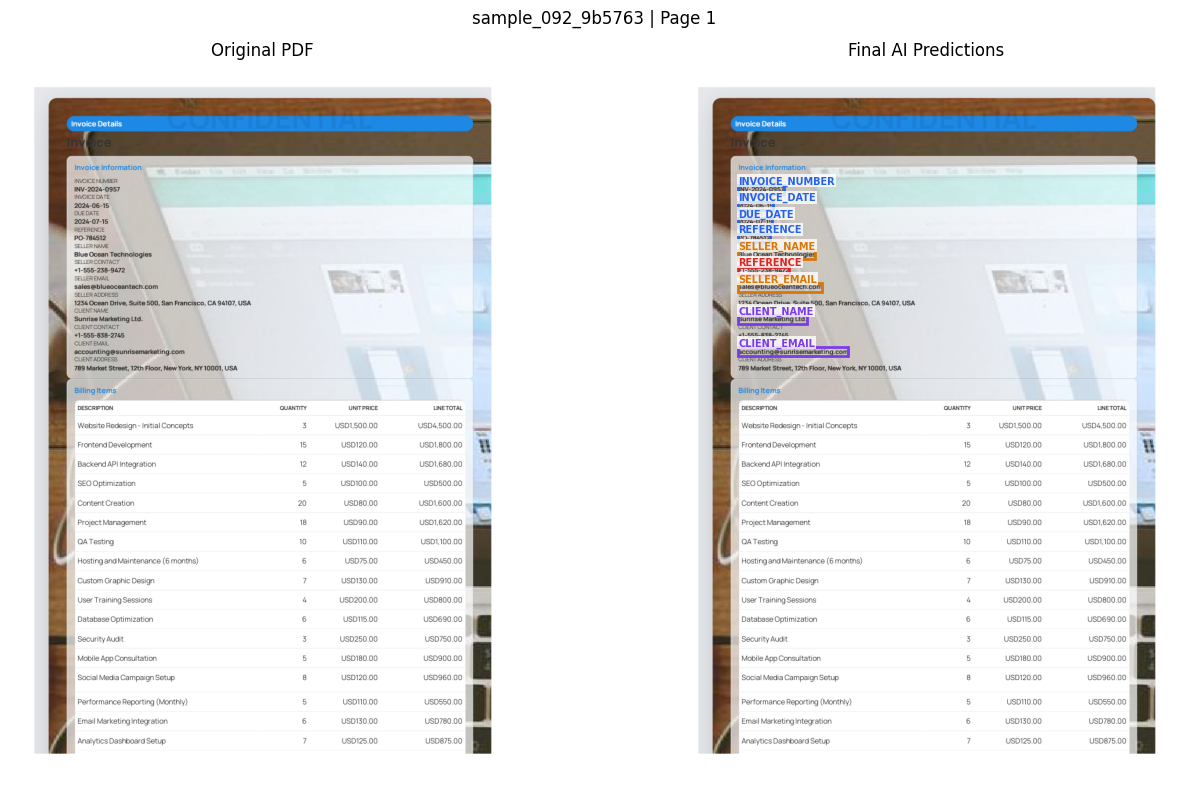


----------------------------------------------------------------------
Invoice: sample_116_fdd9fa
Status: HAS ERRORS


,Field,Ground Truth,Prediction,Status
0,INVOICE_NUMBER,CZ2024-0457,CZ2024-0457,PASS
1,INVOICE_DATE,2024-06-15,2024-06-15,PASS
2,DUE_DATE,2024-06-29,2024-06-29,PASS
3,REFERENCE,Objednávka 789654,Objednávka 789654,PASS
4,SELLER_NAME,Tech Solutions s.r.o.,Tech Solutions s.r.o.,PASS
5,SELLER_EMAIL,info@techsolutions.cz,info@techsolutions.cz,PASS
6,CLIENT_NAME,Jan Novák,(none),FAIL
7,CLIENT_EMAIL,jan.novak@email.cz,jan.novak@email.cz,PASS
8,SUBTOTAL,"CZK49,700.00","CZK49,700.00",PASS
9,TAX,"CZK10,437.00","CZK10,437.00",PASS


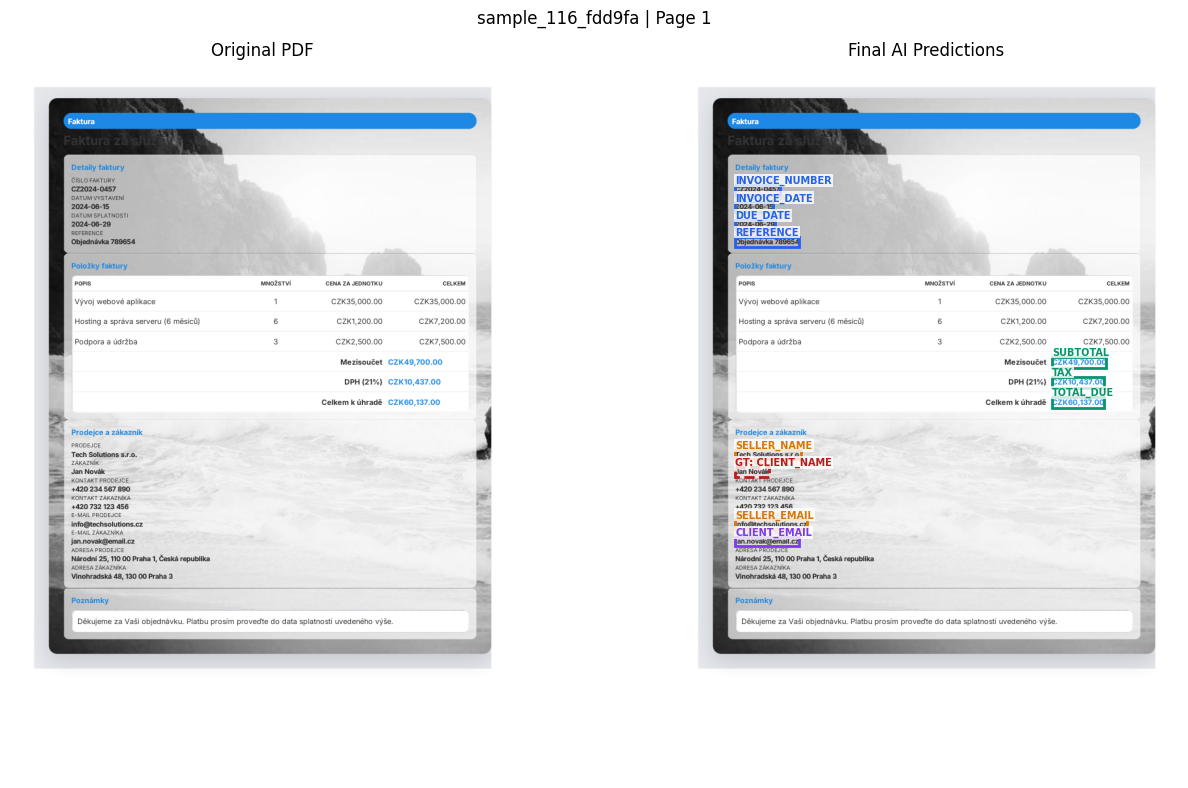


----------------------------------------------------------------------
Invoice: sample_139_6f7533
Status: HAS ERRORS


,Field,Ground Truth,Prediction,Status
0,INVOICE_NUMBER,F2024-0427,F2024-0427,PASS
1,INVOICE_DATE,2024-06-15,2024-06-15,PASS
2,DUE_DATE,2024-07-15,2024-07-15,PASS
3,REFERENCE,Objednávka 7741,Objednávka 7741,PASS
4,SELLER_NAME,Tech Solutions s.r.o.,ABC | Tech Solutions s.r.o.,FAIL
5,SELLER_EMAIL,info@techsolutions.cz,info@techsolutions.cz,PASS
6,CLIENT_NAME,ABC Marketing a.s.,(none),FAIL
7,CLIENT_EMAIL,kontakt@abcmarketing.cz,kontakt@abcmarketing.cz,PASS
8,SUBTOTAL,"CZK190,300.00","CZK190,300.00",PASS
9,TAX,"CZK39,963.00","CZK39,963.00",PASS


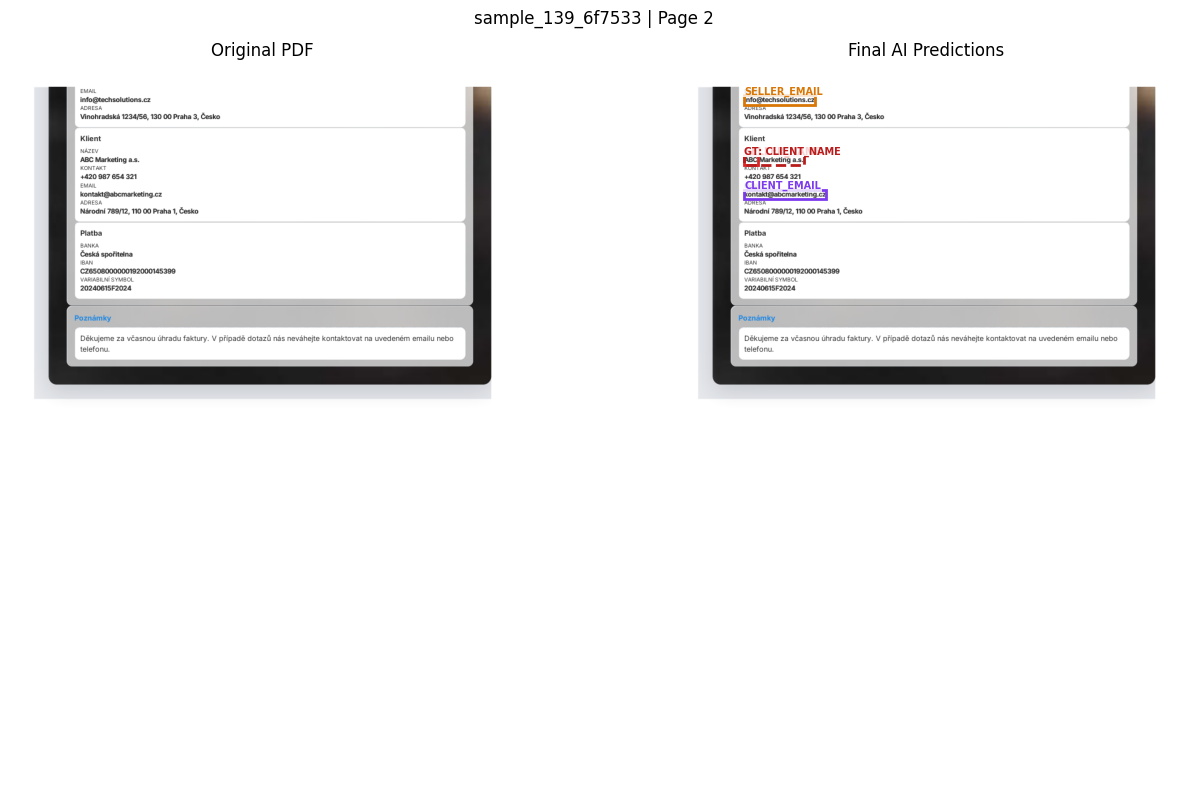


----------------------------------------------------------------------
Invoice: sample_664_aff001
Status: FULLY CORRECT


,Field,Ground Truth,Prediction,Status
0,INVOICE_NUMBER,F20240615-1234,F20240615-1234,PASS
1,INVOICE_DATE,2024-06-15,2024-06-15,PASS
2,DUE_DATE,2024-07-15,2024-07-15,PASS
3,REFERENCE,OBJ-789456,OBJ-789456,PASS
4,SELLER_NAME,Tech Solutions s.r.o.,Tech Solutions s.r.o.,PASS
5,SELLER_EMAIL,info@techsolutions.sk,info@techsolutions.sk,PASS
6,CLIENT_NAME,ABC Marketing,ABC Marketing,PASS
7,CLIENT_EMAIL,kontakt@abcmarketing.sk,kontakt@abcmarketing.sk,PASS
8,SUBTOTAL,"EUR1,345.00","EUR1,345.00",PASS
9,TAX,EUR269.00,EUR269.00,PASS


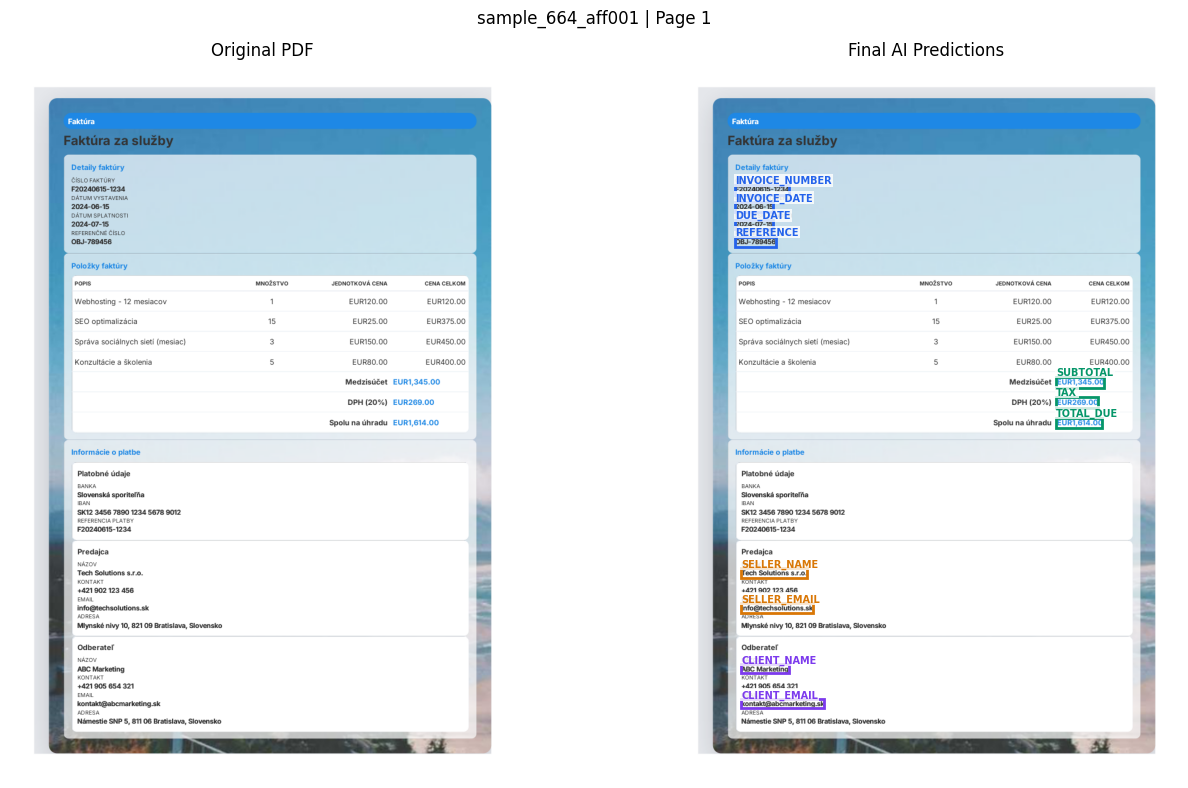


----------------------------------------------------------------------
Invoice: sample_204_6533ad
Status: FULLY CORRECT


,Field,Ground Truth,Prediction,Status
0,INVOICE_NUMBER,CZ-2024-000254,CZ-2024-000254,PASS
1,INVOICE_DATE,2024-06-01,2024-06-01,PASS
2,DUE_DATE,2024-06-30,2024-06-30,PASS
3,REFERENCE,OBJ-987654321,OBJ-987654321,PASS
4,SELLER_NAME,Tech Solutions s.r.o.,Tech Solutions s.r.o.,PASS
5,SELLER_EMAIL,info@techsolutions.cz,info@techsolutions.cz,PASS
6,CLIENT_NAME,Novák Petr,Novák Petr,PASS
7,CLIENT_EMAIL,petr.novak@email.cz,petr.novak@email.cz,PASS
8,SUBTOTAL,"CZK102,850.00","CZK102,850.00",PASS
9,TAX,"CZK21,598.50","CZK21,598.50",PASS


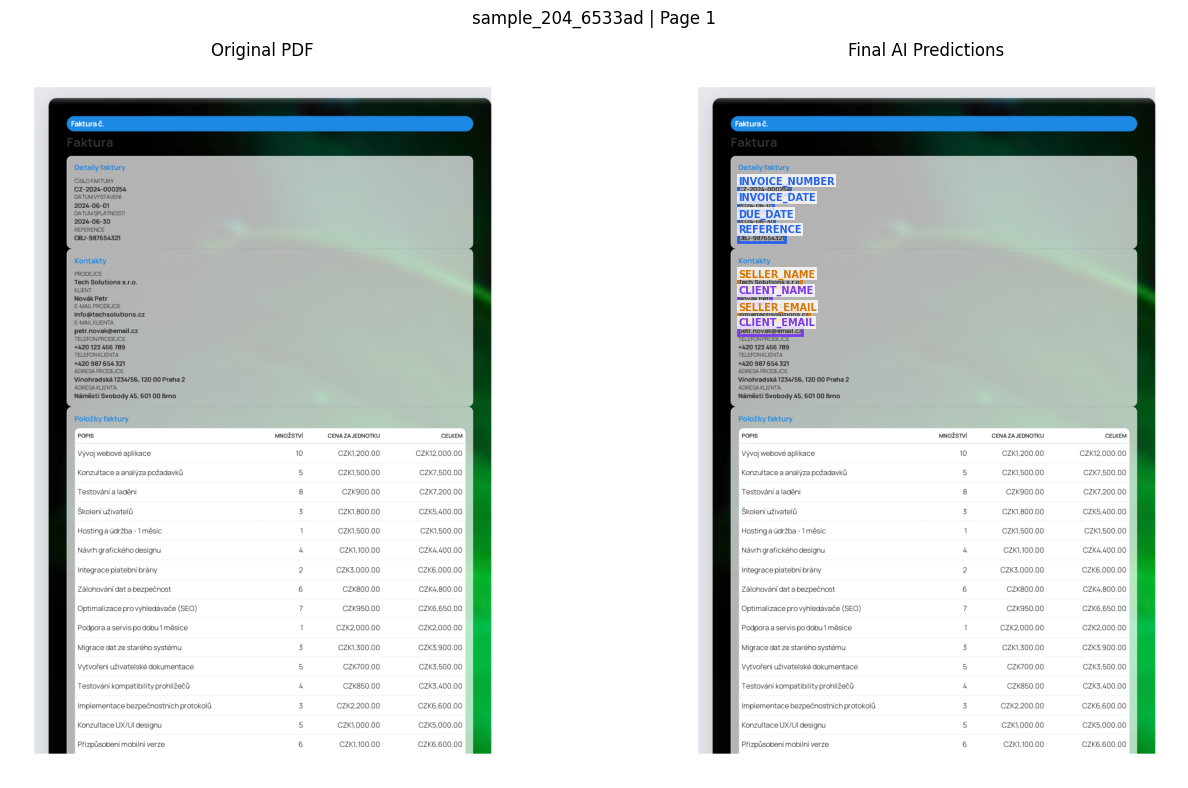

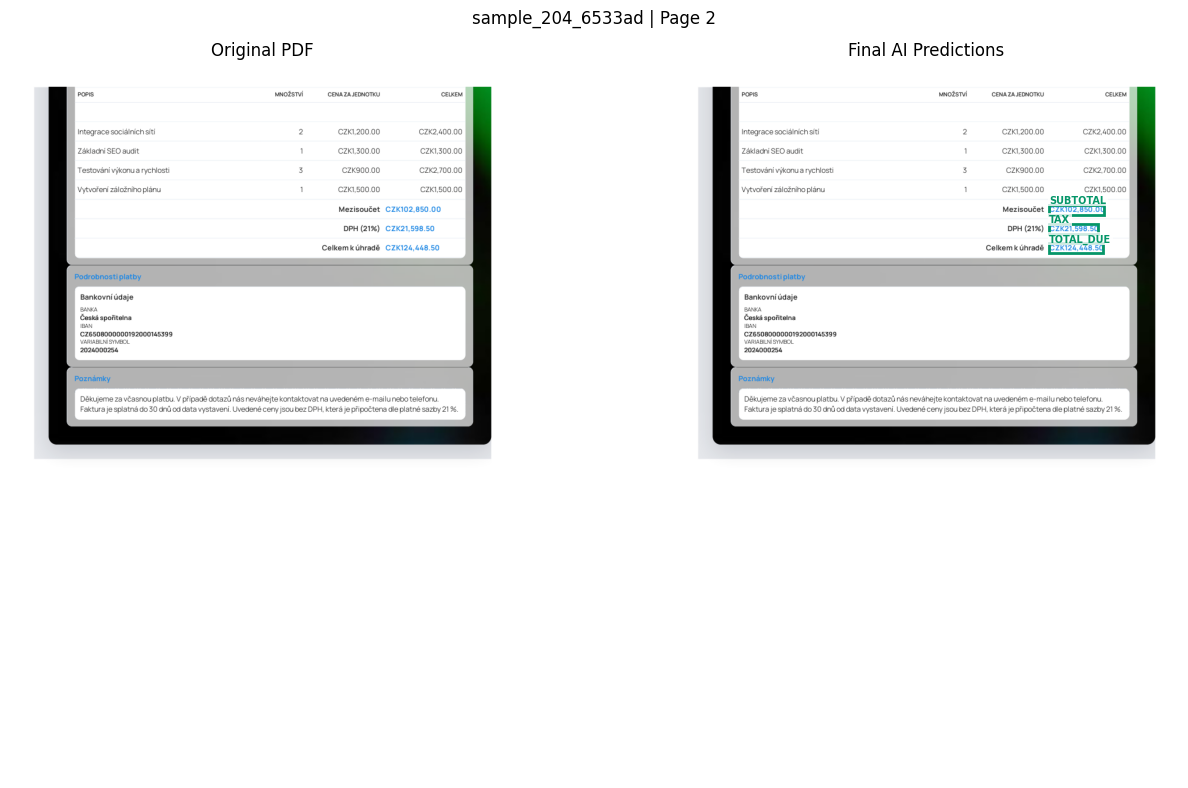


FINAL TEST SUMMARY
Test invoices: 19
Final Precision: 0.9904
Final Recall: 0.9904
Final Entity F1: 0.9904
Final Seller/Client F1: 0.9801
Final Email F1: 1.0
Fully correct invoices: 16/19
Invoice Exact Match: 0.8421

No training performed.
No threshold changed.
No output files created.
Evaluation completed successfully!


In [42]:

# ==============================================================
# PROJECT 9: FINAL TEST EVALUATION + VISUALIZATION
# FULL FIXED VERSION
#
# FIX: Never calls test_dataset.__getitem__()
# FIX: Uses independent PDF renderer
# FIX: Avoids overwritten render_pdf_page()
#
# Evaluates:
#   A. Original LayoutLMv3
#   B. Existing Two-Stage
#   C. Final Candidate Recovery + Two-Stage
#
# Outputs:
#   - Overall Precision / Recall / F1
#   - Per-field performance (11 fields)
#   - Invoice-level exact match
#   - Remaining errors
#   - Recovery coverage
#   - Five invoice visualizations
#
# No training. No files. No threshold tuning.
# ==============================================================

import gc
import random
from functools import lru_cache
from collections import defaultdict, Counter
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Rectangle
from tqdm.auto import tqdm
from IPython.display import display

try:
    import pymupdf as fitz
except ImportError:
    import fitz


# ==============================================================
# 1. CONFIGURATION AND OBJECT CHECK
# ==============================================================

NEEDED = [
    "model",
    "processor",
    "test_dataset",
    "page_samples",
    "build_pair_features",
    "role_head",
    "feature_scaler",
    "apply_role_correction",
    "selected_gate",
    "candidate_slot_inference",
]

missing = [
    x for x in NEEDED
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing notebook objects: {missing}. "
        "Run the original model and final pipeline cells."
    )

EVAL_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

EVAL_BATCH_SIZE = 2
EVAL_MAX_LENGTH = 512
EVAL_NUM_VISUALIZATIONS = 5

EVAL_FIELDS = [
    "INVOICE_NUMBER",
    "INVOICE_DATE",
    "DUE_DATE",
    "REFERENCE",
    "SELLER_NAME",
    "SELLER_EMAIL",
    "CLIENT_NAME",
    "CLIENT_EMAIL",
    "SUBTOTAL",
    "TAX",
    "TOTAL_DUE",
]

EVAL_ROLE_FIELDS = {
    "SELLER_NAME",
    "SELLER_EMAIL",
    "CLIENT_NAME",
    "CLIENT_EMAIL",
}

EVAL_EMAIL_FIELDS = {
    "SELLER_EMAIL",
    "CLIENT_EMAIL",
}

EVAL_ID2 = {
    int(k): str(v)
    for k, v in model.config.id2label.items()
}

EVAL_LABEL2ID = {
    v: k for k, v in EVAL_ID2.items()
}

assert len(EVAL_ID2) == 23
assert processor.tokenizer.is_fast

for field in EVAL_FIELDS:
    assert "B-" + field in EVAL_LABEL2ID

# IMPORTANT: Access .records directly.
# Do NOT call test_dataset[0].
EVAL_RECORDS = list(test_dataset.records)

if not EVAL_RECORDS:
    raise RuntimeError("No test records available.")

EVAL_KEYS = {
    (
        str(rec["invoice_id"]),
        int(rec["page_index"])
    )
    for rec in EVAL_RECORDS
}

EVAL_INVOICES = sorted({
    key[0]
    for key in EVAL_KEYS
})

EVAL_SOURCE = {
    (
        str(page["invoice_id"]),
        int(page["page_index"])
    ): page
    for page in page_samples
    if (
        str(page["invoice_id"]),
        int(page["page_index"])
    ) in EVAL_KEYS
}

if set(EVAL_SOURCE) != EVAL_KEYS:
    raise RuntimeError(
        "Some test OCR pages are missing from page_samples."
    )

# Verify invoice-level split isolation.
for split_name in ("train_dataset", "val_dataset"):

    if split_name in globals():

        other_ids = {
            str(rec["invoice_id"])
            for rec in globals()[split_name].records
        }

        if set(EVAL_INVOICES) & other_ids:
            raise RuntimeError(
                f"Invoice leakage against {split_name}."
            )

print("=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

print("Device:", EVAL_DEVICE)
print("Test invoices:", len(EVAL_INVOICES))
print("Test pages:", len(EVAL_KEYS))
print("Test windows:", len(EVAL_RECORDS))
print("Fields:", len(EVAL_FIELDS))

print("\nPDF renderer collision: BYPASSED")


# ==============================================================
# 2. INDEPENDENT PDF RENDERING FUNCTION
# ==============================================================

@lru_cache(maxsize=16)
def _test_render_pdf_page(pdf_path, page_index):
    """
    Local function with its own name.

    Does not depend on global render_pdf_page,
    which was overwritten in earlier experiments.
    """

    with fitz.open(str(pdf_path)) as document:

        if not (
            0 <= int(page_index) < len(document)
        ):
            raise IndexError(
                f"Invalid PDF page: {page_index}"
            )

        page = document.load_page(
            int(page_index)
        )

        pix = page.get_pixmap(
            matrix=fitz.Matrix(1.5, 1.5),
            alpha=False
        )

        image = Image.frombytes(
            "RGB",
            (pix.width, pix.height),
            pix.samples
        )

    return image


def _test_pdf_path(record):

    path = record.get("pdf")

    if path is None:

        key = (
            str(record["invoice_id"]),
            int(record["page_index"])
        )

        path = EVAL_SOURCE[key].get("pdf")

    if path is None:
        raise RuntimeError(
            "PDF path unavailable."
        )

    return str(path)


# ==============================================================
# 3. RECONSTRUCT SUPERVISED TEST WORDS
# ==============================================================

EVAL_GOLD_POSITIONS = defaultdict(dict)

for rec in EVAL_RECORDS:

    key = (
        str(rec["invoice_id"]),
        int(rec["page_index"])
    )

    start = int(rec["word_start"])

    words = list(rec["words"])
    boxes = rec["boxes"]
    labels = rec["label_ids"]

    if not (
        len(words) == len(boxes) == len(labels)
    ):
        raise RuntimeError(
            f"Incorrect window alignment: {key}"
        )

    original_words = list(
        EVAL_SOURCE[key]["words"]
    )

    if original_words[
        start:start + len(words)
    ] != words:

        raise RuntimeError(
            f"OCR reading order mismatch: {key}"
        )

    for local_idx, label_id in enumerate(labels):

        if int(label_id) == -100:
            continue

        global_idx = start + local_idx

        previous = EVAL_GOLD_POSITIONS[
            key
        ].get(global_idx)

        if (
            previous is not None
            and previous != int(label_id)
        ):
            raise RuntimeError(
                "Conflicting word labels."
            )

        EVAL_GOLD_POSITIONS[key][
            global_idx
        ] = int(label_id)


total_supervised_words = sum(
    len(v)
    for v in EVAL_GOLD_POSITIONS.values()
)

print("\nSupervised OCR words:", total_supervised_words)


# ==============================================================
# 4. ENCODE TEST WINDOWS WITHOUT DATASET.__GETITEM__
# ==============================================================

def _test_encode_window(rec):

    key = (
        str(rec["invoice_id"]),
        int(rec["page_index"])
    )

    words = list(rec["words"])

    boxes = [
        list(map(int, b))
        for b in rec["boxes"]
    ]

    # IMPORTANT:
    # No word_labels used for inference encoding.
    encoding = processor.tokenizer(
        words,
        boxes=boxes,
        truncation=False,
        padding="max_length",
        max_length=EVAL_MAX_LENGTH,
        return_tensors="pt"
    )

    if (
        encoding["input_ids"].shape[1]
        != EVAL_MAX_LENGTH
    ):
        raise RuntimeError(
            f"Window exceeds 512 tokens: {key}"
        )

    pdf_path = _test_pdf_path(rec)

    image = _test_render_pdf_page(
        pdf_path,
        int(rec["page_index"])
    )

    image_encoding = processor.image_processor(
        image,
        return_tensors="pt"
    )

    return {
        "key": key,
        "start": int(rec["word_start"]),
        "word_ids": encoding.word_ids(
            batch_index=0
        ),

        "input_ids": encoding[
            "input_ids"
        ][0],

        "attention_mask": encoding[
            "attention_mask"
        ][0],

        "bbox": encoding["bbox"][0],

        "pixel_values": image_encoding[
            "pixel_values"
        ][0],
    }


print("\nPreparing test windows...")

EVAL_WINDOWS = [
    _test_encode_window(rec)
    for rec in tqdm(
        EVAL_RECORDS,
        desc="Encoding Test Windows"
    )
]

print(
    "Encoded windows:",
    len(EVAL_WINDOWS)
)


# ==============================================================
# 5. PREPARE FULL-PAGE LOGIT STORAGE
# ==============================================================

test_page_logits = {}

for key in EVAL_KEYS:

    source = EVAL_SOURCE[key]

    words = list(
        source["words"]
    )

    test_page_logits[key] = {
        "words": words,

        "boxes": [
            list(map(int, b))
            for b in source["boxes"]
        ],

        "logits": np.full(
            (len(words), len(EVAL_ID2)),
            np.nan,
            dtype=np.float32
        )
    }


# ==============================================================
# 6. RUN ORIGINAL LAYOUTLMv3 INFERENCE
# ==============================================================

print("\n" + "=" * 70)
print("RUNNING LAYOUTLMv3 TEST INFERENCE")
print("=" * 70)

# Avoid old experimental models taking GPU memory.
if (
    "swap_model" in globals()
    and swap_model is not model
):
    swap_model.to("cpu")

original_device = next(
    model.parameters()
).device

model.to(EVAL_DEVICE)
model.eval()

try:

    with torch.inference_mode():

        for start_idx in tqdm(
            range(
                0,
                len(EVAL_WINDOWS),
                EVAL_BATCH_SIZE
            ),
            desc="Test Inference"
        ):

            batch = EVAL_WINDOWS[
                start_idx:
                start_idx + EVAL_BATCH_SIZE
            ]

            inputs = {
                name: torch.stack([
                    item[name]
                    for item in batch
                ]).to(EVAL_DEVICE)

                for name in (
                    "input_ids",
                    "attention_mask",
                    "bbox",
                    "pixel_values"
                )
            }

            if EVAL_DEVICE.type == "cuda":

                context = torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                )

            else:
                context = nullcontext()

            with context:

                logits = model(
                    **inputs
                ).logits

            logits = (
                logits.float()
                .cpu()
                .numpy()
            )

            for row, item in enumerate(batch):

                key = item["key"]

                destination = test_page_logits[
                    key
                ]["logits"]

                seen_words = set()

                for token_idx, local_word in enumerate(
                    item["word_ids"]
                ):

                    if local_word is None:
                        continue

                    if local_word in seen_words:
                        continue

                    seen_words.add(local_word)

                    original_word_index = (
                        item["start"]
                        + int(local_word)
                    )

                    if not (
                        0 <= original_word_index
                        < len(destination)
                    ):
                        raise RuntimeError(
                            "Invalid OCR word index."
                        )

                    # Deterministic first-covering
                    # window aggregation.
                    # No GT labels used here.
                    if not np.isfinite(
                        destination[
                            original_word_index, 0
                        ]
                    ):

                        destination[
                            original_word_index
                        ] = logits[
                            row, token_idx
                        ]

finally:

    model.to(original_device)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


for key, page in test_page_logits.items():

    if not np.isfinite(
        page["logits"]
    ).all():

        missing_words = np.flatnonzero(
            ~np.isfinite(
                page["logits"]
            ).all(axis=1)
        )

        raise RuntimeError(
            f"Missing predictions in {key}: "
            f"{missing_words.tolist()}"
        )

print("\nInference completed successfully!")

# Inference inputs no longer needed.
del EVAL_WINDOWS
gc.collect()


# ==============================================================
# 7. PIPELINE A: ORIGINAL LAYOUTLMv3
# ==============================================================

test_original_tags = {
    key: page["logits"]
    .argmax(axis=1)
    .astype(int)
    .copy()

    for key, page in test_page_logits.items()
}


# ==============================================================
# 8. PIPELINE B: EXISTING TWO-STAGE
# ==============================================================

test_block_pairs, test_pairing_reasons = (
    build_pair_features(
        test_page_logits,
        require_targets=False
    )
)

for pair in test_block_pairs:

    features = np.asarray(
        pair["difference"],
        dtype=float
    ).reshape(1, -1)

    score = float(
        role_head.decision_function(
            feature_scaler.transform(
                features
            )
        )[0]
    )

    pair["margin"] = score

    pair["seller_block"] = (
        0 if score >= 0 else 1
    )

test_two_stage_tags, _ = (
    apply_role_correction(
        test_page_logits,
        test_block_pairs,
        selected_gate
    )
)


# ==============================================================
# 9. PIPELINE C: FINAL CANDIDATE RECOVERY
# ==============================================================

test_final_tags, test_recovery_audit = (
    candidate_slot_inference(
        test_page_logits
    )
)

TEST_METHODS = {
    "Original LayoutLMv3": test_original_tags,

    "Existing Two-Stage": test_two_stage_tags,

    "Final Candidate Recovery": test_final_tags,
}

for name, predictions in TEST_METHODS.items():

    if set(predictions) != EVAL_KEYS:
        raise RuntimeError(
            f"Missing output pages: {name}"
        )

    for key in EVAL_KEYS:

        if len(predictions[key]) != len(
            EVAL_SOURCE[key]["words"]
        ):
            raise RuntimeError(
                f"Prediction length mismatch: {name}, {key}"
            )


# ==============================================================
# 10. STRICT BIO SPAN EXTRACTION
# ==============================================================

def _test_extract_spans(position_map):

    spans = set()

    active_field = None
    active_start = None
    previous = None

    for position in sorted(position_map):

        if (
            previous is not None
            and position != previous + 1
        ):

            if active_field is not None:

                spans.add((
                    active_field,
                    active_start,
                    previous + 1
                ))

            active_field = None
            active_start = None

        label = int(
            position_map[position]
        )

        tag = EVAL_ID2[label]

        if tag.startswith("B-"):

            if active_field is not None:

                spans.add((
                    active_field,
                    active_start,
                    position
                ))

            active_field = tag[2:]
            active_start = position

        elif (
            tag.startswith("I-")
            and active_field == tag[2:]
        ):

            pass

        else:

            if active_field is not None:

                spans.add((
                    active_field,
                    active_start,
                    position
                ))

            active_field = None
            active_start = None

        previous = position

    if active_field is not None:

        spans.add((
            active_field,
            active_start,
            previous + 1
        ))

    return spans


TEST_GOLD_SPANS = {
    key: _test_extract_spans(
        EVAL_GOLD_POSITIONS[key]
    )
    for key in EVAL_KEYS
}


def _test_scored_predictions(prediction_tags):

    return {
        key: _test_extract_spans({
            position: int(
                prediction_tags[key][position]
            )
            for position in EVAL_GOLD_POSITIONS[key]
        })
        for key in EVAL_KEYS
    }


# ==============================================================
# 11. ENTITY-LEVEL EVALUATION
# ==============================================================

def _test_evaluate(prediction_tags):

    pred_spans = _test_scored_predictions(
        prediction_tags
    )

    field_counts = {
        field: Counter()
        for field in EVAL_FIELDS
    }

    invoice_gold = defaultdict(set)
    invoice_pred = defaultdict(set)

    for key in sorted(EVAL_KEYS):

        gold = TEST_GOLD_SPANS[key]
        pred = pred_spans[key]

        for field in EVAL_FIELDS:

            g = {
                span for span in gold
                if span[0] == field
            }

            p = {
                span for span in pred
                if span[0] == field
            }

            field_counts[field]["TP"] += len(
                g & p
            )

            field_counts[field]["FP"] += len(
                p - g
            )

            field_counts[field]["FN"] += len(
                g - p
            )

        invoice_gold[key[0]].update(
            (key[1], *span)
            for span in gold
        )

        invoice_pred[key[0]].update(
            (key[1], *span)
            for span in pred
        )

    def scores(tp, fp, fn):

        precision = (
            tp / (tp + fp)
            if tp + fp else 0.0
        )

        recall = (
            tp / (tp + fn)
            if tp + fn else 0.0
        )

        f1 = (
            2 * tp / (2 * tp + fp + fn)
            if 2 * tp + fp + fn else 0.0
        )

        return precision, recall, f1

    tp = sum(
        c["TP"] for c in field_counts.values()
    )

    fp = sum(
        c["FP"] for c in field_counts.values()
    )

    fn = sum(
        c["FN"] for c in field_counts.values()
    )

    precision, recall, f1 = scores(
        tp, fp, fn
    )

    invoice_correct = {
        invoice: (
            invoice_gold[invoice]
            == invoice_pred[invoice]
        )
        for invoice in EVAL_INVOICES
    }

    field_rows = []

    for field in EVAL_FIELDS:

        count = field_counts[field]

        p, r, f = scores(
            count["TP"],
            count["FP"],
            count["FN"]
        )

        field_rows.append({
            "Field": field,
            "GT Count": count["TP"] + count["FN"],
            "TP": count["TP"],
            "FP": count["FP"],
            "FN": count["FN"],
            "Precision": p,
            "Recall": r,
            "F1": f
        })

    def subset_f1(selected):

        a = sum(
            field_counts[f]["TP"]
            for f in selected
        )

        b = sum(
            field_counts[f]["FP"]
            for f in selected
        )

        c = sum(
            field_counts[f]["FN"]
            for f in selected
        )

        return (
            2*a / (2*a+b+c)
            if 2*a+b+c else 0.0
        )

    return {
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Role F1": subset_f1(
            EVAL_ROLE_FIELDS
        ),
        "Email F1": subset_f1(
            EVAL_EMAIL_FIELDS
        ),
        "Invoice Exact Match": (
            sum(invoice_correct.values())
            / len(EVAL_INVOICES)
        ),
        "Correct Invoices": invoice_correct,
        "Per Field": pd.DataFrame(
            field_rows
        ),
        "Predicted Spans": pred_spans
    }


TEST_REPORTS = {
    name: _test_evaluate(tags)
    for name, tags in TEST_METHODS.items()
}


# ==============================================================
# 12. OVERALL TEST METRICS
# ==============================================================

test_summary_df = pd.DataFrame([
    {
        "Method": name,
        "Precision": report["Precision"],
        "Recall": report["Recall"],
        "Entity F1": report["F1"],
        "Role F1": report["Role F1"],
        "Email F1": report["Email F1"],
        "TP": report["TP"],
        "FP": report["FP"],
        "FN": report["FN"],
        "Correct Invoices": sum(
            report["Correct Invoices"].values()
        ),
        "Invoice Exact Match":
            report["Invoice Exact Match"]
    }
    for name, report in TEST_REPORTS.items()
])

print("\n" + "=" * 70)
print("HELD-OUT TEST RESULTS")
print("=" * 70)

display(
    test_summary_df.round(4)
)

historical_test_f1 = 0.942584

current_baseline_f1 = (
    TEST_REPORTS[
        "Original LayoutLMv3"
    ]["F1"]
)

print("\nHistorical original test F1:",
      historical_test_f1)

print("Current original test F1:",
      round(current_baseline_f1, 6))

if abs(
    current_baseline_f1 - historical_test_f1
) > 0.02:

    print(
        "\nWARNING: Historical baseline not reproduced."
        "\nPossible causes: PDF rasterization,"
        " model state or window aggregation."
        "\nDo not interpret the pipeline comparison"
        " as equivalent to the historical run."
    )


# ==============================================================
# 13. PER-FIELD TEST METRICS
# ==============================================================

test_field_df = (
    TEST_REPORTS[
        "Final Candidate Recovery"
    ]["Per Field"].copy()
)

for method, column in [
    ("Original LayoutLMv3", "Original F1"),
    ("Existing Two-Stage", "Two-Stage F1")
]:

    scores = TEST_REPORTS[
        method
    ]["Per Field"].set_index(
        "Field"
    )["F1"]

    test_field_df[column] = (
        test_field_df["Field"].map(scores)
    )

test_field_df = test_field_df.rename(
    columns={
        "F1": "Final F1"
    }
)

test_field_df["Improvement"] = (
    test_field_df["Final F1"]
    - test_field_df["Two-Stage F1"]
)

print("\n" + "=" * 70)
print("PER-FIELD TEST PERFORMANCE")
print("=" * 70)

display(
    test_field_df[
        [
            "Field",
            "GT Count",
            "TP",
            "FP",
            "FN",
            "Original F1",
            "Two-Stage F1",
            "Final F1",
            "Improvement"
        ]
    ].round(4)
)


# ==============================================================
# 14. INVOICE-LEVEL TEST COMPARISON
# ==============================================================

invoice_results = []

for invoice in EVAL_INVOICES:

    row = {
        "Invoice": invoice
    }

    for method, report in TEST_REPORTS.items():

        row[method] = (
            "PASS"
            if report[
                "Correct Invoices"
            ][invoice]
            else "FAIL"
        )

    invoice_results.append(row)


test_invoice_df = pd.DataFrame(
    invoice_results
)

print("\n" + "=" * 70)
print("INVOICE-LEVEL TEST RESULTS")
print("=" * 70)

display(test_invoice_df)


# ==============================================================
# 15. REMAINING ERRORS
# ==============================================================

test_final_spans = (
    TEST_REPORTS[
        "Final Candidate Recovery"
    ]["Predicted Spans"]
)


def _test_span_text(key, span):

    return " ".join(
        EVAL_SOURCE[key]["words"][
            span[1]:span[2]
        ]
    )


error_rows = []

for key in sorted(EVAL_KEYS):

    gold = TEST_GOLD_SPANS[key]
    pred = test_final_spans[key]

    missed = sorted(
        gold - pred
    )

    extra = set(
        pred - gold
    )

    used_extra = set()

    for gt_span in missed:

        field, start, end = gt_span

        overlaps = [
            span
            for span in extra - used_extra
            if min(end, span[2]) > max(start, span[1])
        ]

        if overlaps:

            match = max(
                overlaps,
                key=lambda s: (
                    min(end, s[2])
                    - max(start, s[1])
                )
            )

            used_extra.add(match)

        else:
            match = None

        if match is None:
            error_type = "MISSED_ENTITY"

        elif match[0] == field:
            error_type = "BOUNDARY_ERROR"

        else:
            error_type = "WRONG_CLASS"

        error_rows.append({
            "Invoice": key[0],
            "Page": key[1] + 1,
            "GT Field": field,
            "GT Text": _test_span_text(
                key, gt_span
            ),
            "Predicted Field": (
                match[0] if match else "NONE"
            ),
            "Predicted Text": (
                _test_span_text(key, match)
                if match else ""
            ),
            "Error Type": error_type
        })

    for span in sorted(extra - used_extra):

        error_rows.append({
            "Invoice": key[0],
            "Page": key[1] + 1,
            "GT Field": "NONE",
            "GT Text": "",
            "Predicted Field": span[0],
            "Predicted Text": _test_span_text(
                key, span
            ),
            "Error Type": "EXTRA_PREDICTION"
        })


test_error_df = pd.DataFrame(
    error_rows
)

print("\n" + "=" * 70)
print("FINAL PIPELINE: REMAINING TEST ERRORS")
print("=" * 70)

if test_error_df.empty:

    print("No unmatched entities found.")

else:

    display(test_error_df)

    print("\nError type distribution:")

    display(
        test_error_df[
            "Error Type"
        ].value_counts().to_frame("Count")
    )


# ==============================================================
# 16. BLOCK PAIRING AND CANDIDATE RECOVERY COVERAGE
# ==============================================================

print("\n" + "=" * 70)
print("BLOCK PAIRING / CANDIDATE RECOVERY")
print("=" * 70)

print(
    "Existing block pairs:",
    len(test_block_pairs),
    "/",
    len(EVAL_INVOICES)
)

print(
    "Block pairing reasons:",
    dict(test_pairing_reasons)
)

if (
    isinstance(test_recovery_audit, pd.DataFrame)
    and not test_recovery_audit.empty
):

    display(test_recovery_audit)

else:

    print(
        "No additional recovery attempt recorded."
    )


# ==============================================================
# 17. SELECT FIVE SAMPLE INVOICES
# ==============================================================

final_correct = (
    TEST_REPORTS[
        "Final Candidate Recovery"
    ]["Correct Invoices"]
)

two_stage_correct = (
    TEST_REPORTS[
        "Existing Two-Stage"
    ]["Correct Invoices"]
)

failed_invoices = [
    i for i in EVAL_INVOICES
    if not final_correct[i]
]

newly_fixed = [
    i for i in EVAL_INVOICES
    if final_correct[i] and not two_stage_correct[i]
]

stable_correct = [
    i for i in EVAL_INVOICES
    if final_correct[i] and two_stage_correct[i]
]

random.Random(42).shuffle(
    stable_correct
)

visualization_invoices = []

for group in [
    failed_invoices,
    newly_fixed,
    stable_correct
]:

    for invoice in group:

        if (
            invoice not in visualization_invoices
            and len(visualization_invoices)
            < EVAL_NUM_VISUALIZATIONS
        ):

            visualization_invoices.append(
                invoice
            )


# ==============================================================
# 18. VISUALIZATION HELPERS
# ==============================================================

EVAL_FIELD_COLORS = {
    "SELLER": "#D97706",
    "CLIENT": "#7C3AED",
    "AMOUNT": "#059669",
    "OTHER": "#2563EB"
}


def _test_field_color(field):

    if field.startswith("SELLER_"):
        return EVAL_FIELD_COLORS["SELLER"]

    if field.startswith("CLIENT_"):
        return EVAL_FIELD_COLORS["CLIENT"]

    if field in (
        "SUBTOTAL", "TAX", "TOTAL_DUE"
    ):
        return EVAL_FIELD_COLORS["AMOUNT"]

    return EVAL_FIELD_COLORS["OTHER"]


def _test_span_box(key, span):

    boxes = np.asarray(
        EVAL_SOURCE[key]["boxes"][
            span[1]:span[2]
        ],
        dtype=float
    )

    return [
        float(boxes[:, 0].min()),
        float(boxes[:, 1].min()),
        float(boxes[:, 2].max()),
        float(boxes[:, 3].max())
    ]


def _test_draw_span(
    ax, image, key, span,
    color, dashed=False,
    title=None
):

    box = _test_span_box(
        key, span
    )

    x = box[0] * image.width / 1000
    y = box[1] * image.height / 1000

    w = max(
        1,
        (box[2] - box[0])
        * image.width / 1000
    )

    h = max(
        1,
        (box[3] - box[1])
        * image.height / 1000
    )

    ax.add_patch(
        Rectangle(
            (x, y),
            w, h,
            fill=False,
            edgecolor=color,
            linewidth=2,
            linestyle=(
                "--" if dashed else "-"
            )
        )
    )

    if title:

        ax.text(
            x,
            max(0, y - 3),
            title,
            fontsize=7,
            color=color,
            weight="bold",
            bbox={
                "facecolor": "white",
                "alpha": 0.8,
                "edgecolor": "none",
                "pad": 1
            }
        )


def _test_visualize_page(key):

    page = EVAL_SOURCE[key]

    image = _test_render_pdf_page(
        str(page["pdf"]),
        key[1]
    )

    gold_spans = TEST_GOLD_SPANS[key]
    predicted_spans = test_final_spans[key]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 8)
    )

    axes[0].imshow(image)
    axes[1].imshow(image)

    axes[0].set_title(
        "Original PDF"
    )

    axes[1].set_title(
        "Final AI Predictions"
    )

    for span in sorted(predicted_spans):

        field = span[0]

        if span in gold_spans:

            color = _test_field_color(
                field
            )

        else:
            color = "#DC2626"

        _test_draw_span(
            axes[1],
            image,
            key,
            span,
            color,
            dashed=False,
            title=field
        )

    for span in sorted(
        gold_spans - predicted_spans
    ):

        _test_draw_span(
            axes[1],
            image,
            key,
            span,
            color="#B91C1C",
            dashed=True,
            title="GT: " + span[0]
        )

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"{key[0]} | Page {key[1] + 1}"
    )

    plt.tight_layout()
    plt.show()


# ==============================================================
# 19. DISPLAY SAMPLE INVOICE FIELD TABLES
# ==============================================================

print("\n" + "=" * 70)
print("TEST SAMPLE VISUALIZATIONS")
print("=" * 70)

print(
    "Selected invoices:",
    visualization_invoices
)

for invoice in visualization_invoices:

    status = (
        "FULLY CORRECT"
        if final_correct[invoice]
        else "HAS ERRORS"
    )

    print("\n" + "-" * 70)
    print("Invoice:", invoice)
    print("Status:", status)

    invoice_keys = sorted(
        key for key in EVAL_KEYS
        if key[0] == invoice
    )

    field_rows = []

    for field in EVAL_FIELDS:

        true_items = set()
        predicted_items = set()

        true_spans = set()
        predicted_field_spans = set()

        for key in invoice_keys:

            for span in TEST_GOLD_SPANS[key]:

                if span[0] == field:

                    true_items.add(
                        _test_span_text(
                            key, span
                        )
                    )

                    true_spans.add(
                        (key[1], *span)
                    )

            for span in test_final_spans[key]:

                if span[0] == field:

                    predicted_items.add(
                        _test_span_text(
                            key, span
                        )
                    )

                    predicted_field_spans.add(
                        (key[1], *span)
                    )

        field_rows.append({
            "Field": field,

            "Ground Truth": (
                " | ".join(sorted(true_items))
                or "(none)"
            ),

            "Prediction": (
                " | ".join(
                    sorted(predicted_items)
                )
                or "(none)"
            ),

            "Status": (
                "PASS"
                if true_spans == predicted_field_spans
                else "FAIL"
            )
        })

    display(
        pd.DataFrame(field_rows)
    )

    error_pages = [
        key
        for key in invoice_keys
        if (
            TEST_GOLD_SPANS[key]
            != test_final_spans[key]
        )
    ]

    pages_to_show = (
        error_pages
        if error_pages
        else invoice_keys
    )[:2]

    for key in pages_to_show:

        _test_visualize_page(
            key
        )


# ==============================================================
# 20. FINAL SUMMARY
# ==============================================================

final_report = TEST_REPORTS[
    "Final Candidate Recovery"
]

correct_invoice_count = sum(
    final_report[
        "Correct Invoices"
    ].values()
)

print("\n" + "=" * 70)
print("FINAL TEST SUMMARY")
print("=" * 70)

print(
    "Test invoices:",
    len(EVAL_INVOICES)
)

print(
    "Final Precision:",
    round(final_report["Precision"], 4)
)

print(
    "Final Recall:",
    round(final_report["Recall"], 4)
)

print(
    "Final Entity F1:",
    round(final_report["F1"], 4)
)

print(
    "Final Seller/Client F1:",
    round(final_report["Role F1"], 4)
)

print(
    "Final Email F1:",
    round(final_report["Email F1"], 4)
)

print(
    "Fully correct invoices:",
    f"{correct_invoice_count}/{len(EVAL_INVOICES)}"
)

print(
    "Invoice Exact Match:",
    round(
        final_report["Invoice Exact Match"],
        4
    )
)

print("\nNo training performed.")
print("No threshold changed.")
print("No output files created.")
print("Evaluation completed successfully!")
